# Cognitive Digital Twin for Self-Aware Channel Estimation

**IEEE WCL reviewer revision — independent CUDA notebook**

This notebook is separate from the original. Experiments will be added incrementally; no detection or adaptation results are assumed.

In [1]:
# Cell 1 — Reproducible CUDA environment check
from pathlib import Path
import os
import sys
import random
import platform
import importlib.util

import numpy as np
import torch

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable to PyTorch. Select the WSL/Conda GPU kernel "
        "and verify that your installed PyTorch build supports this GPU."
    )

device = torch.device("cuda:0")
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

ROOT = Path.cwd()
CHECKPOINT_DIR = ROOT / "checkpoints"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"
for folder in (CHECKPOINT_DIR, RESULTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PyTorch CUDA runtime:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
print("Device:", device)
print("Working directory:", ROOT)

x = torch.randn(1024, 1024, device=device)
y = x @ x.T
torch.cuda.synchronize()
print("CUDA matrix multiplication test:", "PASS" if torch.isfinite(y).all().item() else "FAIL")
del x, y


Python: 3.11.16
PyTorch: 2.11.0+cu128
PyTorch CUDA runtime: 12.8
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
GPU memory (GiB): 23.89
Device: cuda:0
Working directory: /home/afanali/wcnc_project/WCL_CDT_Revision
CUDA matrix multiplication test: PASS


In [2]:

# ============================================================
# CELL 2 — IEEE WCL CDT: Simulation Configuration
# GPU: NVIDIA RTX 5090 | CUDA 12.8
# ============================================================

import os
import random
import json
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import torch

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

assert torch.cuda.is_available(), "CUDA GPU not detected!"

DEVICE = torch.device("cuda:0")

# Float32 for neural networks and monitoring statistics
REAL_DTYPE = torch.float32
COMPLEX_DTYPE = torch.complex64

# ------------------------------------------------------------
# 2. Project directories
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/home/afanali/wcnc_project/WCL_CDT_Revision"
)

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

for directory in (
    CHECKPOINT_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. OFDM and channel configuration
# ------------------------------------------------------------
@dataclass
class WCLConfig:

    # Carrier and OFDM numerology
    carrier_frequency_hz: float = 2.1e9
    subcarrier_spacing_hz: float = 15e3

    n_subcarriers: int = 72
    n_ofdm_symbols: int = 14
    cp_length: int = 16

    # Modulation
    modulation: str = "QPSK"

    # Pilot configuration
    n_pilot_subcarriers: int = 3
    n_pilot_symbols: int = 8

    # Channel profiles and maximum Doppler frequencies
    train_channel: str = "EPA"
    channel_profiles: tuple = ("EPA", "EVA", "ETU")
    doppler_hz: tuple = (5.0, 70.0, 300.0)

    # SNR configuration
    train_snr_db: float = 12.0
    test_snr_db: tuple = (
        -5, 0, 5, 10, 15, 20, 25, 30
    )

    # Original dataset sizes
    n_train: int = 32000
    n_test_per_snr: int = 4000

    # VAE reference samples
    n_vae_reference: int = 2000

    # VAE architecture
    vae_latent_dim: int = 32

    # Monitoring configuration
    monitoring_window: int = 100
    ewma_alpha: float = 0.05
    threshold_sigma: float = 2.0

    # Reviewer-requested detection experiments
    n_detection_trials: int = 100
    deployment_snr_db: float = 12.0

    # SNR-aware calibration
    snr_aware_calibration: bool = True

    # Initial target false-alarm probability
    target_false_alarm: float = 0.01


CFG = WCLConfig()

# ------------------------------------------------------------
# 4. Derived dimensions
# ------------------------------------------------------------
N_F = CFG.n_subcarriers
N_S = CFG.n_ofdm_symbols

N_P = (
    CFG.n_pilot_subcarriers
    * CFG.n_pilot_symbols
)

CHANNEL_DIM = 2 * N_F * N_S
PILOT_DIM = 2 * N_P

SNR_GRID = np.asarray(
    CFG.test_snr_db,
    dtype=np.float32
)

DOPPLER = dict(
    zip(CFG.channel_profiles, CFG.doppler_hz)
)

# Useful OFDM quantities
OFDM_USEFUL_SYMBOL_DURATION = (
    1.0 / CFG.subcarrier_spacing_hz
)

# Nominal sample rate: N_F * subcarrier spacing
SAMPLE_RATE_HZ = (
    CFG.n_subcarriers
    * CFG.subcarrier_spacing_hz
)

SAMPLE_PERIOD_S = 1.0 / SAMPLE_RATE_HZ

CP_DURATION_S = (
    CFG.cp_length / SAMPLE_RATE_HZ
)

OFDM_SYMBOL_DURATION_S = (
    OFDM_USEFUL_SYMBOL_DURATION + CP_DURATION_S
)

SLOT_DURATION_S = (
    CFG.n_ofdm_symbols * OFDM_SYMBOL_DURATION_S
)

# ------------------------------------------------------------
# 5. Configuration checks
# ------------------------------------------------------------
assert N_F > 0
assert N_S > 0
assert N_P > 0
assert N_P <= N_F * N_S

assert len(CFG.channel_profiles) == len(CFG.doppler_hz)

assert CFG.train_channel in CFG.channel_profiles

assert 0.0 < CFG.ewma_alpha < 1.0

assert 0.0 < CFG.target_false_alarm < 1.0

assert CFG.monitoring_window > 0

# ------------------------------------------------------------
# 6. Save configuration for reproducibility
# ------------------------------------------------------------
CONFIG_FILE = RESULTS_DIR / "wcl_cdt_config.json"

config_to_save = asdict(CFG)

config_to_save.update({
    "seed": SEED,
    "device": str(DEVICE),
    "torch_version": torch.__version__,
    "cuda_runtime": torch.version.cuda,
    "gpu_name": torch.cuda.get_device_name(0),
    "sample_rate_hz": SAMPLE_RATE_HZ,
    "ofdm_symbol_duration_s": OFDM_SYMBOL_DURATION_S,
    "slot_duration_s": SLOT_DURATION_S,
})

with open(CONFIG_FILE, "w", encoding="utf-8") as f:
    json.dump(config_to_save, f, indent=4)

# ------------------------------------------------------------
# 7. Display configuration
# ------------------------------------------------------------
print("=" * 65)
print("IEEE WCL — COGNITIVE DIGITAL TWIN REVISION")
print("=" * 65)

print("\n[GPU CONFIGURATION]")
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU Memory (GiB):",
      round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

print("\n[PROJECT]")
print("Project directory:", PROJECT_DIR)
print("Checkpoints:", CHECKPOINT_DIR)
print("Results:", RESULTS_DIR)
print("Figures:", FIGURES_DIR)

print("\n[OFDM PARAMETERS]")
print("Carrier frequency (GHz):", CFG.carrier_frequency_hz / 1e9)
print("Subcarrier spacing (kHz):", CFG.subcarrier_spacing_hz / 1e3)
print("Subcarriers:", N_F)
print("OFDM symbols:", N_S)
print("CP length (samples):", CFG.cp_length)
print("Sample rate (MHz):", SAMPLE_RATE_HZ / 1e6)
print("OFDM symbol duration (us):",
      round(OFDM_SYMBOL_DURATION_S * 1e6, 3))

print("\n[PILOT CONFIGURATION]")
print("Pilot subcarriers per pilot symbol:", CFG.n_pilot_subcarriers)
print("Pilot OFDM symbols:", CFG.n_pilot_symbols)
print("Total pilot REs:", N_P)

print("\n[NEURAL NETWORK DIMENSIONS]")
print("Estimator input dimension:", PILOT_DIM)
print("Estimator output dimension:", CHANNEL_DIM)
print("VAE latent dimension:", CFG.vae_latent_dim)

print("\n[CHANNEL MODELS]")
for name, fd in DOPPLER.items():
    print(f"{name}: maximum Doppler = {fd} Hz")

print("\n[SNR SETTINGS]")
print("Training SNR:", CFG.train_snr_db, "dB")
print("Test SNR grid:", list(CFG.test_snr_db))
print("Deployment test SNR:", CFG.deployment_snr_db, "dB")

print("\n[DATASET]")
print("Training realizations:", CFG.n_train)
print("Test realizations per SNR:", CFG.n_test_per_snr)
print("VAE reference realizations:", CFG.n_vae_reference)

print("\n[DRIFT MONITORING]")
print("Monitoring window:", CFG.monitoring_window)
print("EWMA alpha:", CFG.ewma_alpha)
print("Threshold multiplier:", CFG.threshold_sigma)
print("Detection trials:", CFG.n_detection_trials)
print("SNR-aware calibration:", CFG.snr_aware_calibration)
print("Target FAR:", CFG.target_false_alarm)

print("\n[REPRODUCIBILITY]")
print("Random seed:", SEED)
print("Configuration saved:", CONFIG_FILE)

print("\n" + "=" * 65)
print("CELL 2 CONFIGURATION: PASS")
print("=" * 65)


IEEE WCL — COGNITIVE DIGITAL TWIN REVISION

[GPU CONFIGURATION]
Device: cuda:0
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
GPU Memory (GiB): 23.89

[PROJECT]
Project directory: /home/afanali/wcnc_project/WCL_CDT_Revision
Checkpoints: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints
Results: /home/afanali/wcnc_project/WCL_CDT_Revision/results
Figures: /home/afanali/wcnc_project/WCL_CDT_Revision/figures

[OFDM PARAMETERS]
Carrier frequency (GHz): 2.1
Subcarrier spacing (kHz): 15.0
Subcarriers: 72
OFDM symbols: 14
CP length (samples): 16
Sample rate (MHz): 1.08
OFDM symbol duration (us): 81.481

[PILOT CONFIGURATION]
Pilot subcarriers per pilot symbol: 3
Pilot OFDM symbols: 8
Total pilot REs: 24

[NEURAL NETWORK DIMENSIONS]
Estimator input dimension: 48
Estimator output dimension: 2016
VAE latent dimension: 32

[CHANNEL MODELS]
EPA: maximum Doppler = 5.0 Hz
EVA: maximum Doppler = 70.0 Hz
ETU: maximum Doppler = 300.0 Hz

[SNR SETTINGS]
Training SNR: 12.0 dB
Test SNR grid: [-5, 0, 5, 10,

In [3]:

# ============================================================
# CELL 3 — CUDA EPA / EVA / ETU CHANNEL GENERATION
# Fractional delays + Doppler-correlated fading
# ============================================================

import math
import torch
import numpy as np

# ------------------------------------------------------------
# 1. Standard tapped-delay profiles
# Delays: nanoseconds
# Powers: dB
# ------------------------------------------------------------
CHANNEL_TAPS = {
    "EPA": {
        "delays_ns": [0, 30, 70, 90, 110, 190, 410],
        "powers_db": [0, -1, -2, -3, -8, -17.2, -20.8],
    },
    "EVA": {
        "delays_ns": [0, 30, 150, 310, 370, 710, 1090, 1730, 2510],
        "powers_db": [0, -1.5, -1.4, -3.6, -0.6, -9.1, -7.0, -12.0, -16.9],
    },
    "ETU": {
        "delays_ns": [0, 50, 120, 200, 230, 500, 1600, 2300, 5000],
        "powers_db": [-1, -1, -1, 0, 0, 0, -3, -5, -7],
    },
}

# ------------------------------------------------------------
# 2. Validate and prepare channel profiles
# ------------------------------------------------------------
PROFILE_TENSORS = {}

for name, taps in CHANNEL_TAPS.items():

    delays_s = torch.tensor(
        taps["delays_ns"],
        device=DEVICE,
        dtype=torch.float32
    ) * 1e-9

    powers_db = torch.tensor(
        taps["powers_db"],
        device=DEVICE,
        dtype=torch.float32
    )

    powers_linear = torch.pow(
        10.0,
        powers_db / 10.0
    )

    powers_linear = (
        powers_linear / powers_linear.sum()
    )

    PROFILE_TENSORS[name] = {
        "delays_s": delays_s,
        "powers": powers_linear,
    }

# ------------------------------------------------------------
# 3. CUDA random complex Gaussian helper
# ------------------------------------------------------------
def complex_randn(shape, device=DEVICE):
    return (
        torch.randn(shape, device=device)
        + 1j * torch.randn(shape, device=device)
    ) / math.sqrt(2.0)

# ------------------------------------------------------------
# 4. Doppler-correlated fading generator
# ------------------------------------------------------------
def generate_doppler_fading(
    batch_size,
    n_paths,
    doppler_hz,
    n_symbols=N_S,
    n_sinusoids=32,
    device=DEVICE,
):
    """
    Sum-of-sinusoids approximation to Clarke/Jakes fading.

    Output:
        fading: complex tensor [B, P, S]

    Each path is approximately Rayleigh distributed,
    with temporal correlation governed by maximum Doppler.
    """

    # Uniform arrival angles
    angles = 2 * math.pi * torch.rand(
        batch_size,
        n_paths,
        n_sinusoids,
        device=device
    )

    # Independent initial phases
    phases = 2 * math.pi * torch.rand(
        batch_size,
        n_paths,
        n_sinusoids,
        device=device
    )

    # OFDM symbol times
    times = torch.arange(
        n_symbols,
        device=device,
        dtype=torch.float32
    ) * OFDM_SYMBOL_DURATION_S

    # Doppler frequencies for individual sinusoids
    fd_components = (
        doppler_hz * torch.cos(angles)
    )

    # [B, P, M, S]
    phase_evolution = (
        2 * math.pi
        * fd_components.unsqueeze(-1)
        * times
        + phases.unsqueeze(-1)
    )

    fading = torch.exp(
        1j * phase_evolution
    ).mean(dim=2) * math.sqrt(n_sinusoids)

    return fading.to(torch.complex64)

# ------------------------------------------------------------
# 5. Full OFDM channel generator
# ------------------------------------------------------------
@torch.no_grad()
def generate_channel(
    profile,
    batch_size,
    n_symbols=N_S,
    device=DEVICE,
):
    """
    Generate frequency-domain OFDM channel.

    Input:
        profile: EPA / EVA / ETU
        batch_size: number of independent realizations

    Output:
        H: complex64 tensor [B, N_F, N_S]
    """

    assert profile in PROFILE_TENSORS

    delays = PROFILE_TENSORS[profile]["delays_s"]
    powers = PROFILE_TENSORS[profile]["powers"]

    n_paths = len(delays)

    doppler_hz = DOPPLER[profile]

    # [B, P, S]
    fading = generate_doppler_fading(
        batch_size=batch_size,
        n_paths=n_paths,
        doppler_hz=doppler_hz,
        n_symbols=n_symbols,
        device=device,
    )

    # Apply normalized path powers
    path_gains = (
        fading * torch.sqrt(powers)[None, :, None]
    )

    # Baseband subcarrier frequencies centered at DC
    k = torch.arange(
        N_F,
        device=device,
        dtype=torch.float32
    ) - N_F // 2

    frequencies = (
        k * CFG.subcarrier_spacing_hz
    )

    # Fractional-delay frequency response [F, P]
    delay_response = torch.exp(
        -1j
        * 2 * math.pi
        * frequencies[:, None]
        * delays[None, :]
    )

    # H[b, f, s] = sum_p gain[b,p,s] * phase[f,p]
    H = torch.einsum(
        "bps,fp->bfs",
        path_gains,
        delay_response
    )

    return H.to(torch.complex64)

# ------------------------------------------------------------
# 6. GPU sanity checks
# ------------------------------------------------------------
print("=" * 60)
print("CELL 3 — CHANNEL GENERATION TEST")
print("=" * 60)

B_TEST = 256

for profile in CFG.channel_profiles:

    H = generate_channel(
        profile=profile,
        batch_size=B_TEST
    )

    avg_power = (
        H.abs().square().mean().item()
    )

    print(
        f"{profile}: "
        f"shape={tuple(H.shape)}, "
        f"device={H.device}, "
        f"average power={avg_power:.4f}, "
        f"Doppler={DOPPLER[profile]} Hz"
    )

    assert H.shape == (B_TEST, N_F, N_S)
    assert H.is_cuda
    assert torch.isfinite(H).all()

print("\nCELL 3 CHANNEL GENERATION: PASS")


CELL 3 — CHANNEL GENERATION TEST
EPA: shape=(256, 72, 14), device=cuda:0, average power=0.9823, Doppler=5.0 Hz
EVA: shape=(256, 72, 14), device=cuda:0, average power=1.0371, Doppler=70.0 Hz
ETU: shape=(256, 72, 14), device=cuda:0, average power=0.9577, Doppler=300.0 Hz

CELL 3 CHANNEL GENERATION: PASS


In [4]:

# ============================================================
# CELL 4 — PILOT PLACEMENT, QPSK AND LS ESTIMATION
# IEEE WCL CDT | CUDA IMPLEMENTATION
# ============================================================

import math
import torch

# ------------------------------------------------------------
# 1. Pilot positions
# ------------------------------------------------------------

# Eight pilot-bearing OFDM symbols
PILOT_SYMBOL_INDICES = torch.tensor(
    [0, 2, 4, 6, 7, 9, 11, 13],
    device=DEVICE,
    dtype=torch.long
)

# Three pilot subcarriers per pilot symbol
PILOT_SUBCARRIER_INDICES = torch.tensor(
    [12, 36, 60],
    device=DEVICE,
    dtype=torch.long
)

assert len(PILOT_SYMBOL_INDICES) == CFG.n_pilot_symbols
assert len(PILOT_SUBCARRIER_INDICES) == CFG.n_pilot_subcarriers

# Cartesian product: 3 x 8 = 24 pilot REs
PILOT_K = PILOT_SUBCARRIER_INDICES.repeat_interleave(
    len(PILOT_SYMBOL_INDICES)
)

PILOT_L = PILOT_SYMBOL_INDICES.repeat(
    len(PILOT_SUBCARRIER_INDICES)
)

assert PILOT_K.numel() == N_P
assert PILOT_L.numel() == N_P

# Binary pilot mask [72, 14]
PILOT_MASK = torch.zeros(
    (N_F, N_S),
    dtype=torch.bool,
    device=DEVICE
)

PILOT_MASK[PILOT_K, PILOT_L] = True

# ------------------------------------------------------------
# 2. Unit-modulus QPSK generator
# ------------------------------------------------------------
def generate_qpsk(shape, device=DEVICE):
    """
    Generate independent unit-power QPSK symbols.

    Alphabet:
        (+1+j)/sqrt(2)
        (+1-j)/sqrt(2)
        (-1+j)/sqrt(2)
        (-1-j)/sqrt(2)
    """

    bits = torch.randint(
        0, 2, (*shape, 2),
        device=device
    )

    real = 1.0 - 2.0 * bits[..., 0].float()
    imag = 1.0 - 2.0 * bits[..., 1].float()

    return torch.complex(real, imag) / math.sqrt(2.0)


# ------------------------------------------------------------
# 3. Fixed known pilot sequence
# ------------------------------------------------------------

# Use a dedicated generator for reproducible pilot symbols
pilot_generator = torch.Generator(device=DEVICE)
pilot_generator.manual_seed(SEED + 100)

pilot_bits = torch.randint(
    0, 2, (N_P, 2),
    device=DEVICE,
    generator=pilot_generator
)

pilot_real = 1.0 - 2.0 * pilot_bits[:, 0].float()
pilot_imag = 1.0 - 2.0 * pilot_bits[:, 1].float()

PILOT_VALUES = (
    torch.complex(pilot_real, pilot_imag) / math.sqrt(2.0)
)

assert torch.allclose(
    PILOT_VALUES.abs(),
    torch.ones_like(PILOT_VALUES.abs()),
    atol=1e-6
)

# ------------------------------------------------------------
# 4. OFDM transmission through channel
# ------------------------------------------------------------
@torch.no_grad()
def simulate_ofdm(
    H,
    snr_db,
    pilot_values=PILOT_VALUES,
):
    """
    Frequency-domain OFDM transmission:

        Y = H * X + W

    Inputs:
        H: complex channel [B, 72, 14]
        snr_db: scalar SNR in dB

    Outputs:
        X: transmitted QPSK symbols
        Y: received OFDM grid
        noise_variance: AWGN variance
    """

    B = H.shape[0]

    # Generate full-grid QPSK symbols
    X = generate_qpsk(
        (B, N_F, N_S),
        device=H.device
    )

    # Insert fixed known pilots
    X[:, PILOT_K, PILOT_L] = pilot_values

    # Unit-average-power channel normalization
    snr_linear = 10.0 ** (float(snr_db) / 10.0)

    # E[|H|^2] = 1, E[|X|^2] = 1
    noise_variance = 1.0 / snr_linear

    W = (
        complex_randn(
            H.shape,
            device=H.device
        )
        * math.sqrt(noise_variance)
    )

    Y = H * X + W

    return X, Y, noise_variance


# ------------------------------------------------------------
# 5. Pilot extraction and LS estimation
# ------------------------------------------------------------
@torch.no_grad()
def extract_pilot_observations(
    Y,
    pilot_values=PILOT_VALUES,
):
    """
    Extract received pilots and compute LS estimates.

    Returns:
        y_p: raw received pilots, real-valued [B, 48]
        h_p: LS pilot estimates, real-valued [B, 48]
        H_ls_p: complex LS estimates [B, 24]
    """

    # Received pilots
    Y_p = Y[:, PILOT_K, PILOT_L]

    # Known transmitted pilots
    X_p = pilot_values.unsqueeze(0)

    # Pilot LS estimate
    H_ls_p = Y_p / X_p

    # Real-valued vectorization
    y_p = torch.cat(
        [Y_p.real, Y_p.imag],
        dim=1
    ).float()

    h_p = torch.cat(
        [H_ls_p.real, H_ls_p.imag],
        dim=1
    ).float()

    return y_p, h_p, H_ls_p


# ------------------------------------------------------------
# 6. Full channel vectorization
# ------------------------------------------------------------
def channel_to_real_vector(H):
    """
    Convert complex channel [B, F, S]
    into real vector [B, 2*F*S].
    """

    B = H.shape[0]

    H_flat = H.reshape(B, -1)

    return torch.cat(
        [H_flat.real, H_flat.imag],
        dim=1
    ).float()


# ------------------------------------------------------------
# 7. CUDA sanity test
# ------------------------------------------------------------
print("=" * 60)
print("CELL 4 — PILOT AND LS ESTIMATION TEST")
print("=" * 60)

B_TEST = 256
TEST_SNR_DB = 12.0

H_test = generate_channel(
    profile="EPA",
    batch_size=B_TEST
)

X_test, Y_test, noise_var = simulate_ofdm(
    H_test,
    snr_db=TEST_SNR_DB
)

y_p_test, h_p_test, H_ls_p_test = (
    extract_pilot_observations(Y_test)
)

h_full_test = channel_to_real_vector(H_test)

# Ground-truth channel at pilot positions
H_true_p = H_test[:, PILOT_K, PILOT_L]

# LS pilot NMSE
ls_nmse = (
    (H_ls_p_test - H_true_p).abs().square().sum()
    /
    H_true_p.abs().square().sum()
)

ls_nmse_db = 10 * torch.log10(ls_nmse).item()

# ------------------------------------------------------------
# 8. Assertions
# ------------------------------------------------------------
assert X_test.shape == (B_TEST, N_F, N_S)
assert Y_test.shape == (B_TEST, N_F, N_S)

assert y_p_test.shape == (B_TEST, PILOT_DIM)
assert h_p_test.shape == (B_TEST, PILOT_DIM)

assert H_ls_p_test.shape == (B_TEST, N_P)
assert h_full_test.shape == (B_TEST, CHANNEL_DIM)

assert y_p_test.is_cuda
assert h_p_test.is_cuda
assert H_ls_p_test.is_cuda

assert torch.isfinite(y_p_test).all()
assert torch.isfinite(h_p_test).all()

# Check pilot count
assert PILOT_MASK.sum().item() == N_P

print(f"Pilot positions: {N_P}")
print(f"Pilot subcarriers: {PILOT_SUBCARRIER_INDICES.tolist()}")
print(f"Pilot symbols: {PILOT_SYMBOL_INDICES.tolist()}")

print(f"\nTransmitted grid: {tuple(X_test.shape)}")
print(f"Received grid: {tuple(Y_test.shape)}")

print(f"\nVAE input y_p: {tuple(y_p_test.shape)}")
print(f"Estimator input h_p: {tuple(h_p_test.shape)}")
print(f"Full channel target: {tuple(h_full_test.shape)}")

print(f"\nSNR: {TEST_SNR_DB} dB")
print(f"Noise variance: {noise_var:.6f}")
print(f"Pilot LS NMSE: {ls_nmse_db:.3f} dB")

print(f"\nDevice: {H_test.device}")

print("\nCELL 4 PILOT AND LS ESTIMATION: PASS")


CELL 4 — PILOT AND LS ESTIMATION TEST
Pilot positions: 24
Pilot subcarriers: [12, 36, 60]
Pilot symbols: [0, 2, 4, 6, 7, 9, 11, 13]

Transmitted grid: (256, 72, 14)
Received grid: (256, 72, 14)

VAE input y_p: (256, 48)
Estimator input h_p: (256, 48)
Full channel target: (256, 2016)

SNR: 12.0 dB
Noise variance: 0.063096
Pilot LS NMSE: -12.051 dB

Device: cuda:0

CELL 4 PILOT AND LS ESTIMATION: PASS


In [5]:

# ============================================================
# CELL 5 — EPA DATASET GENERATION AND SAVING
# IEEE WCL CDT | CUDA RTX 5090
# ============================================================

import gc
import time
import torch

# ------------------------------------------------------------
# 1. Dataset configuration
# ------------------------------------------------------------
DATASET_DIR = PROJECT_DIR / "datasets"
DATASET_DIR.mkdir(parents=True, exist_ok=True)

DATASET_SIZES = {
    "train": CFG.n_train,
    "validation": 4000,
    "vae_train": CFG.n_vae_reference,
    "calibration": 4000,
}

GENERATION_BATCH_SIZE = 512

# ------------------------------------------------------------
# 2. Batched dataset generator
# ------------------------------------------------------------
@torch.no_grad()
def generate_epa_dataset(
    n_samples,
    snr_db,
    batch_size=GENERATION_BATCH_SIZE,
):
    """
    Generate independent EPA realizations.

    Returns:
        h_p: LS pilot inputs [N, 48]
        y_p: raw received pilots [N, 48]
        h_full: true full channels [N, 2016]

    Stored tensors are moved to CPU to conserve GPU memory.
    """

    h_p_batches = []
    y_p_batches = []
    h_full_batches = []

    for start in range(0, n_samples, batch_size):

        current_batch = min(
            batch_size,
            n_samples - start
        )

        # Generate full channel on CUDA
        H = generate_channel(
            profile="EPA",
            batch_size=current_batch
        )

        # OFDM transmission
        X, Y, noise_var = simulate_ofdm(
            H,
            snr_db=snr_db
        )

        # Receiver pilot observations
        y_p, h_p, H_ls_p = (
            extract_pilot_observations(Y)
        )

        # Full channel target
        h_full = channel_to_real_vector(H)

        # Store on CPU
        h_p_batches.append(
            h_p.cpu()
        )

        y_p_batches.append(
            y_p.cpu()
        )

        h_full_batches.append(
            h_full.cpu()
        )

    return {
        "h_p": torch.cat(h_p_batches, dim=0),
        "y_p": torch.cat(y_p_batches, dim=0),
        "h_full": torch.cat(h_full_batches, dim=0),
        "snr_db": float(snr_db),
        "channel": "EPA",
    }

# ------------------------------------------------------------
# 3. Generate datasets
# ------------------------------------------------------------
print("=" * 65)
print("CELL 5 — EPA DATASET GENERATION")
print("=" * 65)

start_time = time.time()

DATASET_PATHS = {}

for dataset_name, n_samples in DATASET_SIZES.items():

    print(
        f"\nGenerating {dataset_name}: "
        f"{n_samples:,} samples..."
    )

    dataset = generate_epa_dataset(
        n_samples=n_samples,
        snr_db=CFG.train_snr_db
    )

    save_path = (
        DATASET_DIR / f"EPA_{dataset_name}_12dB.pt"
    )

    torch.save(dataset, save_path)

    DATASET_PATHS[dataset_name] = save_path

    print(
        f"Saved: {save_path.name}"
    )

    print(
        f"Input: {tuple(dataset['h_p'].shape)}"
    )

    print(
        f"Target: {tuple(dataset['h_full'].shape)}"
    )

    # Release dataset memory before next generation
    del dataset
    gc.collect()

# ------------------------------------------------------------
# 4. Reload and validate training dataset
# ------------------------------------------------------------
train_data = torch.load(
    DATASET_PATHS["train"],
    map_location="cpu",
    weights_only=True
)

assert train_data["h_p"].shape == (
    CFG.n_train,
    PILOT_DIM
)

assert train_data["h_full"].shape == (
    CFG.n_train,
    CHANNEL_DIM
)

assert torch.isfinite(
    train_data["h_p"]
).all()

assert torch.isfinite(
    train_data["h_full"]
).all()

# ------------------------------------------------------------
# 5. Dataset statistics
# ------------------------------------------------------------
pilot_power = (
    train_data["h_p"].square().mean().item()
)

channel_power = (
    train_data["h_full"].square().mean().item()
)

elapsed = time.time() - start_time

print("\n" + "=" * 65)
print("DATASET VALIDATION")
print("=" * 65)

print("Training samples:", CFG.n_train)
print("Pilot input dimension:", PILOT_DIM)
print("Channel target dimension:", CHANNEL_DIM)

print(f"Mean squared real pilot component: {pilot_power:.6f}")
print(f"Mean squared real channel component: {channel_power:.6f}")

print(f"Generation time: {elapsed:.2f} seconds")

print("\nSaved datasets:")
for name, path in DATASET_PATHS.items():
    print(f"  {name}: {path}")

print("\nCELL 5 DATASET GENERATION: PASS")

del train_data
gc.collect()


CELL 5 — EPA DATASET GENERATION

Generating train: 32,000 samples...
Saved: EPA_train_12dB.pt
Input: (32000, 48)
Target: (32000, 2016)

Generating validation: 4,000 samples...
Saved: EPA_validation_12dB.pt
Input: (4000, 48)
Target: (4000, 2016)

Generating vae_train: 2,000 samples...
Saved: EPA_vae_train_12dB.pt
Input: (2000, 48)
Target: (2000, 2016)

Generating calibration: 4,000 samples...
Saved: EPA_calibration_12dB.pt
Input: (4000, 48)
Target: (4000, 2016)

DATASET VALIDATION
Training samples: 32000
Pilot input dimension: 48
Channel target dimension: 2016
Mean squared real pilot component: 0.531326
Mean squared real channel component: 0.499641
Generation time: 1.22 seconds

Saved datasets:
  train: /home/afanali/wcnc_project/WCL_CDT_Revision/datasets/EPA_train_12dB.pt
  validation: /home/afanali/wcnc_project/WCL_CDT_Revision/datasets/EPA_validation_12dB.pt
  vae_train: /home/afanali/wcnc_project/WCL_CDT_Revision/datasets/EPA_vae_train_12dB.pt
  calibration: /home/afanali/wcnc_proje

8

In [6]:

# ============================================================
# CELL 6 — CUDA TRAINING OF CHANNEL ESTIMATOR
# IEEE WCL CDT | EPA @ 12 dB
# ============================================================

import time
import copy
import math

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# 1. Training configuration
# ------------------------------------------------------------
FCN_HIDDEN_DIM = 512
FCN_EPOCHS = 100
FCN_BATCH_SIZE = 256
FCN_LEARNING_RATE = 1e-3
FCN_WEIGHT_DECAY = 1e-5
FCN_PATIENCE = 15

# ------------------------------------------------------------
# 2. Four-layer FCN with activation extraction
# ------------------------------------------------------------
class ChannelEstimatorFCN(nn.Module):

    def __init__(
        self,
        input_dim=PILOT_DIM,
        output_dim=CHANNEL_DIM,
        hidden_dim=FCN_HIDDEN_DIM,
    ):
        super().__init__()

        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, hidden_dim)
        self.fc4 = nn.Linear(hidden_dim, output_dim)

        self.activation = nn.ReLU()

    def forward(self, x, return_activations=False):

        a1 = self.activation(self.fc1(x))
        a2 = self.activation(self.fc2(a1))
        a3 = self.activation(self.fc3(a2))

        output = self.fc4(a3)

        if return_activations:
            return output, [a1, a2, a3]

        return output

# ------------------------------------------------------------
# 3. Load saved datasets
# ------------------------------------------------------------
train_data = torch.load(
    DATASET_PATHS["train"],
    map_location="cpu",
    weights_only=True
)

val_data = torch.load(
    DATASET_PATHS["validation"],
    map_location="cpu",
    weights_only=True
)

train_dataset = TensorDataset(
    train_data["h_p"],
    train_data["h_full"]
)

val_dataset = TensorDataset(
    val_data["h_p"],
    val_data["h_full"]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=FCN_BATCH_SIZE,
    shuffle=True,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=FCN_BATCH_SIZE,
    shuffle=False,
    pin_memory=True
)

# ------------------------------------------------------------
# 4. Initialize model and optimizer
# ------------------------------------------------------------
model = ChannelEstimatorFCN().to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=FCN_LEARNING_RATE,
    weight_decay=FCN_WEIGHT_DECAY
)

criterion = nn.MSELoss()

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

# ------------------------------------------------------------
# 5. NMSE evaluation
# ------------------------------------------------------------
@torch.no_grad()
def evaluate_nmse(model, loader):

    model.eval()

    error_power = 0.0
    channel_power = 0.0
    total_loss = 0.0
    total_samples = 0

    for x_cpu, y_cpu in loader:

        x = x_cpu.to(DEVICE, non_blocking=True)
        y = y_cpu.to(DEVICE, non_blocking=True)

        prediction = model(x)

        error_power += (
            (prediction - y).square().sum().item()
        )

        channel_power += (
            y.square().sum().item()
        )

        total_loss += (
            criterion(prediction, y).item() * x.shape[0]
        )

        total_samples += x.shape[0]

    nmse = error_power / max(channel_power, 1e-12)
    nmse_db = 10.0 * math.log10(max(nmse, 1e-12))

    avg_loss = total_loss / total_samples

    return avg_loss, nmse_db

# ------------------------------------------------------------
# 6. Training loop
# ------------------------------------------------------------
print("=" * 65)
print("CELL 6 — FCN CHANNEL ESTIMATOR TRAINING")
print("=" * 65)

print("GPU:", torch.cuda.get_device_name(0))
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

start_time = time.time()

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

TRAIN_HISTORY = {
    "train_loss": [],
    "val_loss": [],
    "val_nmse_db": [],
}

checkpoint_path = (
    CHECKPOINT_DIR / "fcn_epa_12db_best.pt"
)

for epoch in range(1, FCN_EPOCHS + 1):

    model.train()

    running_loss = 0.0
    total_samples = 0

    for x_cpu, y_cpu in train_loader:

        x = x_cpu.to(DEVICE, non_blocking=True)
        y = y_cpu.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        prediction = model(x)

        loss = criterion(prediction, y)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * x.shape[0]
        total_samples += x.shape[0]

    train_loss = running_loss / total_samples

    val_loss, val_nmse_db = evaluate_nmse(
        model,
        val_loader
    )

    scheduler.step(val_loss)

    TRAIN_HISTORY["train_loss"].append(train_loss)
    TRAIN_HISTORY["val_loss"].append(val_loss)
    TRAIN_HISTORY["val_nmse_db"].append(val_nmse_db)

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "val_loss": val_loss,
                "val_nmse_db": val_nmse_db,
                "input_dim": PILOT_DIM,
                "output_dim": CHANNEL_DIM,
                "hidden_dim": FCN_HIDDEN_DIM,
            },
            checkpoint_path
        )

    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:03d}/{FCN_EPOCHS} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f} | "
            f"Val NMSE: {val_nmse_db:.2f} dB"
        )

    if epochs_without_improvement >= FCN_PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}"
        )
        break

# ------------------------------------------------------------
# 7. Restore best checkpoint
# ------------------------------------------------------------
best_checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()

# ------------------------------------------------------------
# 8. Final validation
# ------------------------------------------------------------
final_val_loss, final_nmse_db = evaluate_nmse(
    model,
    val_loader
)

elapsed = time.time() - start_time

n_parameters = sum(
    p.numel() for p in model.parameters()
)

print("\n" + "=" * 65)
print("TRAINING SUMMARY")
print("=" * 65)

print("Best epoch:", best_epoch)
print("Trainable parameters:", f"{n_parameters:,}")
print("Best validation MSE:", f"{final_val_loss:.6f}")
print("Best validation NMSE:", f"{final_nmse_db:.3f} dB")
print("Training time:", f"{elapsed:.2f} seconds")
print("Checkpoint:", checkpoint_path)

# ------------------------------------------------------------
# 9. Verify intermediate activations
# ------------------------------------------------------------
with torch.no_grad():

    x_sample = val_data["h_p"][:16].to(DEVICE)

    output, activations = model(
        x_sample,
        return_activations=True
    )

    assert output.shape == (16, CHANNEL_DIM)
    assert len(activations) == 3

    for idx, activation in enumerate(activations, start=1):
        print(
            f"Activation layer {idx}: "
            f"{tuple(activation.shape)}"
        )

print("\nCELL 6 FCN TRAINING: PASS")


CELL 6 — FCN CHANNEL ESTIMATOR TRAINING
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Training samples: 32000
Validation samples: 4000
Epoch 001/100 | Train MSE: 0.031581 | Val MSE: 0.005167 | Val NMSE: -19.80 dB
Epoch 005/100 | Train MSE: 0.002857 | Val MSE: 0.002696 | Val NMSE: -22.62 dB
Epoch 010/100 | Train MSE: 0.002747 | Val MSE: 0.002736 | Val NMSE: -22.56 dB
Epoch 015/100 | Train MSE: 0.002514 | Val MSE: 0.002566 | Val NMSE: -22.84 dB
Epoch 020/100 | Train MSE: 0.002523 | Val MSE: 0.002649 | Val NMSE: -22.70 dB
Epoch 025/100 | Train MSE: 0.002359 | Val MSE: 0.002494 | Val NMSE: -22.96 dB
Epoch 030/100 | Train MSE: 0.002353 | Val MSE: 0.002513 | Val NMSE: -22.93 dB
Epoch 035/100 | Train MSE: 0.002262 | Val MSE: 0.002527 | Val NMSE: -22.90 dB
Epoch 040/100 | Train MSE: 0.002207 | Val MSE: 0.002491 | Val NMSE: -22.96 dB

Early stopping at epoch 41

TRAINING SUMMARY
Best epoch: 26
Trainable parameters: 1,584,608
Best validation MSE: 0.002476
Best validation NMSE: -22.991 dB
Training time

In [7]:

# ============================================================
# CELL 7 — CUDA TRAINING OF PILOT-OBSERVATION VAE
# IEEE WCL CDT | EPA @ 12 dB
# ============================================================

import time
import math
import copy
import json

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# 1. VAE configuration
# ------------------------------------------------------------
VAE_INPUT_DIM = PILOT_DIM
VAE_HIDDEN_DIM = 128
VAE_LATENT_DIM = CFG.vae_latent_dim

VAE_EPOCHS = 100
VAE_BATCH_SIZE = 128
VAE_LEARNING_RATE = 1e-3
VAE_BETA = 0.001
VAE_PATIENCE = 15

VAE_CHECKPOINT = (
    CHECKPOINT_DIR / "pilot_vae_epa_12db_best.pt"
)

# ------------------------------------------------------------
# 2. Pilot-observation VAE architecture
# ------------------------------------------------------------
class PilotVAE(nn.Module):

    def __init__(
        self,
        input_dim=VAE_INPUT_DIM,
        hidden_dim=VAE_HIDDEN_DIM,
        latent_dim=VAE_LATENT_DIM,
    ):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )

        self.fc_mu = nn.Linear(
            hidden_dim, latent_dim
        )

        self.fc_logvar = nn.Linear(
            hidden_dim, latent_dim
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):

        mu, logvar = self.encode(x)

        if self.training:
            z = self.reparameterize(mu, logvar)
        else:
            z = mu

        reconstruction = self.decode(z)

        return reconstruction, mu, logvar

    @torch.no_grad()
    def reconstruction_error(self, x):
        """
        Deterministic deployment monitoring score.

        Uses posterior mean instead of random
        latent sampling.

        Returns:
            Per-sample squared L2 error [B]
        """
        mu, _ = self.encode(x)
        reconstruction = self.decode(mu)

        return (
            (x - reconstruction)
            .square()
            .sum(dim=1)
        )

# ------------------------------------------------------------
# 3. VAE loss
# ------------------------------------------------------------
def vae_loss_function(
    reconstruction,
    x,
    mu,
    logvar,
    beta=VAE_BETA,
):

    # Per-sample reconstruction loss
    reconstruction_loss = (
        (reconstruction - x)
        .square()
        .sum(dim=1)
        .mean()
    )

    # KL divergence to N(0, I)
    kl_loss = -0.5 * (
        1.0
        + logvar
        - mu.square()
        - logvar.exp()
    ).sum(dim=1).mean()

    total_loss = (
        reconstruction_loss + beta * kl_loss
    )

    return total_loss, reconstruction_loss, kl_loss

# ------------------------------------------------------------
# 4. Load VAE training data
# ------------------------------------------------------------
vae_data = torch.load(
    DATASET_PATHS["vae_train"],
    map_location="cpu",
    weights_only=True
)

# VAE uses RAW received pilot observations,
# not the LS estimator input.
vae_inputs = vae_data["y_p"].float()

# Independent split within VAE dataset
n_total = len(vae_inputs)
n_train_vae = int(0.8 * n_total)

split_generator = torch.Generator()
split_generator.manual_seed(SEED + 700)

indices = torch.randperm(
    n_total,
    generator=split_generator
)

train_indices = indices[:n_train_vae]
val_indices = indices[n_train_vae:]

vae_train_dataset = TensorDataset(
    vae_inputs[train_indices]
)

vae_val_dataset = TensorDataset(
    vae_inputs[val_indices]
)

vae_train_loader = DataLoader(
    vae_train_dataset,
    batch_size=VAE_BATCH_SIZE,
    shuffle=True,
    pin_memory=True,
)

vae_val_loader = DataLoader(
    vae_val_dataset,
    batch_size=VAE_BATCH_SIZE,
    shuffle=False,
    pin_memory=True,
)

# ------------------------------------------------------------
# 5. Initialize model
# ------------------------------------------------------------
vae_model = PilotVAE().to(DEVICE)

vae_optimizer = torch.optim.Adam(
    vae_model.parameters(),
    lr=VAE_LEARNING_RATE,
)

# ------------------------------------------------------------
# 6. Validation function
# ------------------------------------------------------------
@torch.no_grad()
def evaluate_vae(vae, loader):

    vae.eval()

    total = 0.0
    recon = 0.0
    kl = 0.0
    count = 0

    for (x_cpu,) in loader:

        x = x_cpu.to(
            DEVICE,
            non_blocking=True
        )

        output, mu, logvar = vae(x)

        loss, rec_loss, kl_loss = (
            vae_loss_function(
                output, x, mu, logvar
            )
        )

        n = x.shape[0]

        total += loss.item() * n
        recon += rec_loss.item() * n
        kl += kl_loss.item() * n
        count += n

    return (
        total / count,
        recon / count,
        kl / count,
    )

# ------------------------------------------------------------
# 7. Training loop
# ------------------------------------------------------------
print("=" * 65)
print("CELL 7 — PILOT VAE TRAINING")
print("=" * 65)

print("Device:", DEVICE)
print("VAE training samples:", len(vae_train_dataset))
print("VAE validation samples:", len(vae_val_dataset))
print("Input dimension:", VAE_INPUT_DIM)
print("Latent dimension:", VAE_LATENT_DIM)
print("Beta:", VAE_BETA)

start_time = time.time()

best_val_loss = float("inf")
best_epoch = 0
no_improvement = 0

VAE_HISTORY = {
    "train_loss": [],
    "val_loss": [],
    "val_reconstruction": [],
    "val_kl": [],
}

for epoch in range(1, VAE_EPOCHS + 1):

    vae_model.train()

    train_total = 0.0
    train_count = 0

    for (x_cpu,) in vae_train_loader:

        x = x_cpu.to(
            DEVICE,
            non_blocking=True
        )

        vae_optimizer.zero_grad(
            set_to_none=True
        )

        reconstruction, mu, logvar = (
            vae_model(x)
        )

        loss, _, _ = vae_loss_function(
            reconstruction, x, mu, logvar
        )

        loss.backward()
        vae_optimizer.step()

        n = x.shape[0]
        train_total += loss.item() * n
        train_count += n

    train_loss = train_total / train_count

    val_loss, val_recon, val_kl = (
        evaluate_vae(
            vae_model,
            vae_val_loader
        )
    )

    VAE_HISTORY["train_loss"].append(
        train_loss
    )

    VAE_HISTORY["val_loss"].append(
        val_loss
    )

    VAE_HISTORY["val_reconstruction"].append(
        val_recon
    )

    VAE_HISTORY["val_kl"].append(
        val_kl
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch
        no_improvement = 0

        torch.save(
            {
                "model_state_dict":
                    vae_model.state_dict(),
                "epoch": epoch,
                "val_loss": val_loss,
                "input_dim": VAE_INPUT_DIM,
                "hidden_dim": VAE_HIDDEN_DIM,
                "latent_dim": VAE_LATENT_DIM,
                "beta": VAE_BETA,
                "training_snr_db":
                    CFG.train_snr_db,
            },
            VAE_CHECKPOINT
        )

    else:
        no_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d}/{VAE_EPOCHS} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f} | "
            f"Recon: {val_recon:.4f} | "
            f"KL: {val_kl:.4f}"
        )

    if no_improvement >= VAE_PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}"
        )
        break

# ------------------------------------------------------------
# 8. Restore best model
# ------------------------------------------------------------
checkpoint = torch.load(
    VAE_CHECKPOINT,
    map_location=DEVICE,
    weights_only=True
)

vae_model.load_state_dict(
    checkpoint["model_state_dict"]
)

vae_model.eval()

elapsed = time.time() - start_time

# ------------------------------------------------------------
# 9. Deterministic score verification
# ------------------------------------------------------------
with torch.no_grad():

    x_test = vae_inputs[:64].to(DEVICE)

    score_1 = vae_model.reconstruction_error(
        x_test
    )

    score_2 = vae_model.reconstruction_error(
        x_test
    )

    assert torch.allclose(
        score_1,
        score_2,
        atol=1e-7
    )

    assert score_1.shape == (64,)
    assert torch.isfinite(score_1).all()

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------
final_loss, final_recon, final_kl = (
    evaluate_vae(
        vae_model,
        vae_val_loader
    )
)

n_parameters = sum(
    p.numel()
    for p in vae_model.parameters()
)

print("\n" + "=" * 65)
print("VAE TRAINING SUMMARY")
print("=" * 65)

print("Best epoch:", best_epoch)
print("Trainable parameters:", f"{n_parameters:,}")
print("Validation loss:", f"{final_loss:.6f}")
print("Reconstruction loss:", f"{final_recon:.6f}")
print("KL loss:", f"{final_kl:.6f}")
print("Mean monitoring score:", f"{score_1.mean().item():.6f}")
print("Training time:", f"{elapsed:.2f} seconds")
print("Checkpoint:", VAE_CHECKPOINT)
print("Deterministic monitoring: PASS")

print("\nCELL 7 VAE TRAINING: PASS")


CELL 7 — PILOT VAE TRAINING
Device: cuda:0
VAE training samples: 1600
VAE validation samples: 400
Input dimension: 48
Latent dimension: 32
Beta: 0.001
Epoch 001/100 | Train: 25.7845 | Val: 23.0386 | Recon: 23.0367 | KL: 1.8659
Epoch 010/100 | Train: 1.7995 | Val: 1.7137 | Recon: 1.6313 | KL: 82.3439
Epoch 020/100 | Train: 1.7503 | Val: 1.6987 | Recon: 1.6101 | KL: 88.6695
Epoch 030/100 | Train: 1.7355 | Val: 1.6895 | Recon: 1.6039 | KL: 85.6262
Epoch 040/100 | Train: 1.7221 | Val: 1.6913 | Recon: 1.6094 | KL: 81.8750
Epoch 050/100 | Train: 1.7115 | Val: 1.6813 | Recon: 1.6047 | KL: 76.6003
Epoch 060/100 | Train: 1.6941 | Val: 1.6703 | Recon: 1.5972 | KL: 73.0574
Epoch 070/100 | Train: 1.6005 | Val: 1.5866 | Recon: 1.5150 | KL: 71.6099
Epoch 080/100 | Train: 1.5001 | Val: 1.4947 | Recon: 1.4233 | KL: 71.4469
Epoch 090/100 | Train: 1.4677 | Val: 1.4766 | Recon: 1.4064 | KL: 70.1020
Epoch 100/100 | Train: 1.4341 | Val: 1.4461 | Recon: 1.3761 | KL: 70.0835

VAE TRAINING SUMMARY
Best epoch:

EPA | SNR  -5 dB | Mean score = 68.9635
EPA | SNR   0 dB | Mean score = 21.5193
EPA | SNR   5 dB | Mean score = 6.8529
EPA | SNR  10 dB | Mean score = 2.1690
EPA | SNR  15 dB | Mean score = 0.7152
EPA | SNR  20 dB | Mean score = 0.2551
EPA | SNR  25 dB | Mean score = 0.1091
EPA | SNR  30 dB | Mean score = 0.0635
EVA | SNR  -5 dB | Mean score = 71.2071
EVA | SNR   0 dB | Mean score = 23.6566
EVA | SNR   5 dB | Mean score = 8.7798
EVA | SNR  10 dB | Mean score = 4.1012
EVA | SNR  15 dB | Mean score = 2.6361
EVA | SNR  20 dB | Mean score = 2.2128
EVA | SNR  25 dB | Mean score = 1.9941
EVA | SNR  30 dB | Mean score = 2.0199
ETU | SNR  -5 dB | Mean score = 75.1448
ETU | SNR   0 dB | Mean score = 28.1989
ETU | SNR   5 dB | Mean score = 13.2403
ETU | SNR  10 dB | Mean score = 8.6216
ETU | SNR  15 dB | Mean score = 6.9789
ETU | SNR  20 dB | Mean score = 6.5688
ETU | SNR  25 dB | Mean score = 6.4396
ETU | SNR  30 dB | Mean score = 6.3963


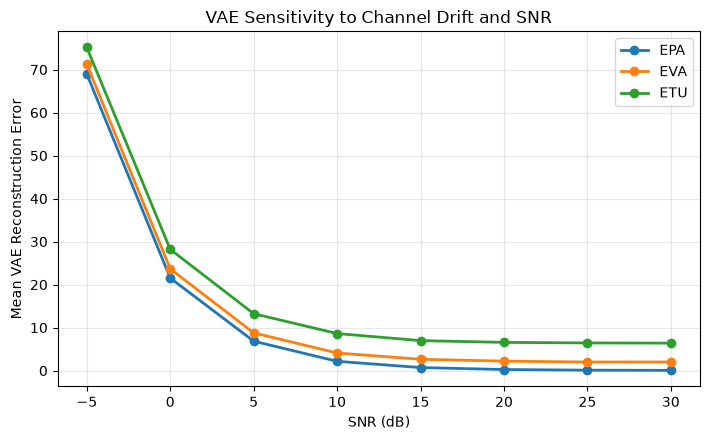


CELL 8 — VAE SNR SENSITIVITY SUMMARY
Channel  SNR_dB      Mean       Std    Median        P95        P99
    EPA      -5 68.963516 14.591061 68.075531  94.661041 107.605988
    EPA       0 21.519258  4.536278 21.227282  29.262899  33.147755
    EPA       5  6.852853  1.488247  6.743659   9.460743  10.910656
    EPA      10  2.168996  0.469109  2.132246   2.997943   3.391648
    EPA      15  0.715158  0.155727  0.702792   0.987208   1.145221
    EPA      20  0.255071  0.059906  0.248015   0.363859   0.433516
    EPA      25  0.109125  0.034567  0.103022   0.171807   0.220060
    EPA      30  0.063541  0.028623  0.056405   0.119019   0.174953
    EVA      -5 71.207092 15.398410 70.160339  98.682373 110.797134
    EVA       0 23.656588  5.100980 23.278559  32.464294  37.022942
    EVA       5  8.779788  2.410572  8.418383  13.391168  15.895309
    EVA      10  4.101205  1.673892  3.722266   7.247025  10.001729
    EVA      15  2.636070  1.653914  2.170645   5.779994   8.284339
    EVA   

In [8]:

# ============================================================
# CELL 8 — VAE SNR SENSITIVITY DIAGNOSTICS
# Reviewer 1 Comment 7 / Reviewer 2 Comment 3
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Experiment settings
# ------------------------------------------------------------
N_DIAGNOSTIC = 4000
DIAGNOSTIC_BATCH = 512

vae_model.eval()

# ------------------------------------------------------------
# 2. Compute reconstruction scores
# ------------------------------------------------------------
@torch.no_grad()
def compute_vae_scores(profile, snr_db, n_samples):

    scores = []

    for start in range(0, n_samples, DIAGNOSTIC_BATCH):

        batch_size = min(
            DIAGNOSTIC_BATCH,
            n_samples - start
        )

        H = generate_channel(
            profile=profile,
            batch_size=batch_size
        )

        _, Y, _ = simulate_ofdm(
            H,
            snr_db=snr_db
        )

        y_p, _, _ = extract_pilot_observations(Y)

        score = vae_model.reconstruction_error(y_p)

        scores.append(score.cpu())

    return torch.cat(scores).numpy()

# ------------------------------------------------------------
# 3. Evaluate all profiles and SNRs
# ------------------------------------------------------------
diagnostic_rows = []

for profile in CFG.channel_profiles:

    for snr_db in CFG.test_snr_db:

        scores = compute_vae_scores(
            profile,
            snr_db,
            N_DIAGNOSTIC
        )

        diagnostic_rows.append({
            "Channel": profile,
            "SNR_dB": snr_db,
            "Mean": float(scores.mean()),
            "Std": float(scores.std(ddof=1)),
            "Median": float(np.median(scores)),
            "P95": float(np.percentile(scores, 95)),
            "P99": float(np.percentile(scores, 99)),
        })

        print(
            f"{profile} | SNR {snr_db:>3} dB | "
            f"Mean score = {scores.mean():.4f}"
        )

diagnostic_df = pd.DataFrame(diagnostic_rows)

# ------------------------------------------------------------
# 4. Save results
# ------------------------------------------------------------
diagnostic_csv = (
    RESULTS_DIR / "vae_snr_sensitivity.csv"
)

diagnostic_df.to_csv(
    diagnostic_csv,
    index=False
)

# ------------------------------------------------------------
# 5. Plot mean VAE reconstruction score
# ------------------------------------------------------------
plt.figure(figsize=(7.2, 4.5))

for profile in CFG.channel_profiles:

    subset = diagnostic_df[
        diagnostic_df["Channel"] == profile
    ]

    plt.plot(
        subset["SNR_dB"],
        subset["Mean"],
        marker="o",
        linewidth=2,
        label=profile
    )

plt.xlabel("SNR (dB)")
plt.ylabel("Mean VAE Reconstruction Error")
plt.title("VAE Sensitivity to Channel Drift and SNR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

figure_path = (
    FIGURES_DIR / "vae_snr_sensitivity.pdf"
)

plt.savefig(
    figure_path,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("CELL 8 — VAE SNR SENSITIVITY SUMMARY")
print("=" * 65)

print(
    diagnostic_df.to_string(index=False)
)

print("\nCSV saved:", diagnostic_csv)
print("Figure saved:", figure_path)

print("\nCELL 8 DIAGNOSTICS: PASS")


EPA | SNR  -5 dB | Threshold  104.788 | Exceedance   1.47%
EVA | SNR  -5 dB | Threshold  104.788 | Exceedance   2.30%
ETU | SNR  -5 dB | Threshold  104.788 | Exceedance   4.08%
EPA | SNR   0 dB | Threshold   33.463 | Exceedance   1.25%
EVA | SNR   0 dB | Threshold   33.463 | Exceedance   4.52%
ETU | SNR   0 dB | Threshold   33.463 | Exceedance  18.80%
EPA | SNR   5 dB | Threshold   10.605 | Exceedance   1.23%
EVA | SNR   5 dB | Threshold   10.605 | Exceedance  19.38%
ETU | SNR   5 dB | Threshold   10.605 | Exceedance  68.17%
EPA | SNR  10 dB | Threshold    3.373 | Exceedance   1.23%
EVA | SNR  10 dB | Threshold    3.373 | Exceedance  60.20%
ETU | SNR  10 dB | Threshold    3.373 | Exceedance  97.78%
EPA | SNR  15 dB | Threshold    1.132 | Exceedance   0.88%
EVA | SNR  15 dB | Threshold    1.132 | Exceedance  90.90%
ETU | SNR  15 dB | Threshold    1.132 | Exceedance 100.00%
EPA | SNR  20 dB | Threshold    0.422 | Exceedance   1.07%
EVA | SNR  20 dB | Threshold    0.422 | Exceedance  98.9

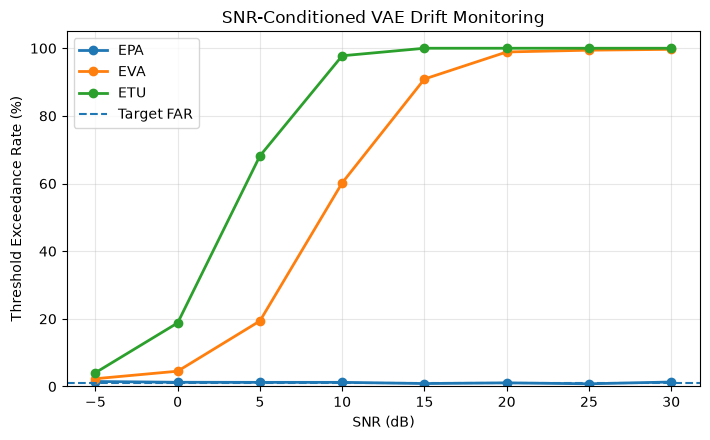


CELL 9 — CALIBRATION SUMMARY

SNR-conditioned thresholds:
 SNR_dB  Threshold      Mean       Std
     -5 104.787697 68.637840 14.478551
      0  33.463467 21.668556  4.548151
      5  10.604753  6.849271  1.452698
     10   3.373466  2.182846  0.464157
     15   1.131809  0.716759  0.156687
     20   0.421893  0.256656  0.058978
     25   0.243178  0.110215  0.035224
     30   0.173648  0.062771  0.027723

Evaluation results:
Channel   EPA     ETU    EVA
SNR_dB                      
-5       1.48    4.08   2.30
 0       1.25   18.80   4.52
 5       1.23   68.18  19.38
 10      1.23   97.78  60.20
 15      0.88  100.00  90.90
 20      1.08  100.00  98.90
 25      0.80  100.00  99.42
 30      1.32  100.00  99.68

Calibration saved: /home/afanali/wcnc_project/WCL_CDT_Revision/results/vae_snr_thresholds.csv
Evaluation saved: /home/afanali/wcnc_project/WCL_CDT_Revision/results/vae_snr_detection_rates.csv
Figure saved: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/vae_snr_calibrated_d

In [9]:

# ============================================================
# CELL 9 — SNR-CONDITIONED VAE CALIBRATION
# Reviewer 1 Comment 7 / Reviewer 2 Comment 3
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. Calibration settings
# ------------------------------------------------------------
N_CALIBRATION = 4000
N_EVALUATION = 4000

TARGET_FAR = CFG.target_false_alarm

SNR_VALUES = list(CFG.test_snr_db)

vae_model.eval()

# ------------------------------------------------------------
# 2. Independent matched-channel calibration
# ------------------------------------------------------------
calibration_results = []
thresholds = {}

for snr_db in SNR_VALUES:

    # Calibration uses EPA only
    calibration_scores = compute_vae_scores(
        profile="EPA",
        snr_db=snr_db,
        n_samples=N_CALIBRATION
    )

    threshold = np.quantile(
        calibration_scores,
        1.0 - TARGET_FAR
    )

    thresholds[snr_db] = float(threshold)

    calibration_results.append({
        "SNR_dB": snr_db,
        "Threshold": float(threshold),
        "Mean": float(calibration_scores.mean()),
        "Std": float(calibration_scores.std(ddof=1)),
    })

calibration_df = pd.DataFrame(calibration_results)

# ------------------------------------------------------------
# 3. Independent evaluation
# ------------------------------------------------------------
evaluation_results = []

for snr_db in SNR_VALUES:

    threshold = thresholds[snr_db]

    for profile in CFG.channel_profiles:

        scores = compute_vae_scores(
            profile=profile,
            snr_db=snr_db,
            n_samples=N_EVALUATION
        )

        detection_rate = (
            np.mean(scores > threshold) * 100.0
        )

        evaluation_results.append({
            "Channel": profile,
            "SNR_dB": snr_db,
            "Threshold": threshold,
            "Detection_Rate_Percent": detection_rate,
            "Mean_Score": float(scores.mean()),
        })

        print(
            f"{profile:3s} | "
            f"SNR {snr_db:>3} dB | "
            f"Threshold {threshold:8.3f} | "
            f"Exceedance {detection_rate:6.2f}%"
        )

evaluation_df = pd.DataFrame(evaluation_results)

# ------------------------------------------------------------
# 4. Save calibration data
# ------------------------------------------------------------
calibration_path = (
    RESULTS_DIR / "vae_snr_thresholds.csv"
)

evaluation_path = (
    RESULTS_DIR / "vae_snr_detection_rates.csv"
)

calibration_df.to_csv(
    calibration_path,
    index=False
)

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

# ------------------------------------------------------------
# 5. Plot threshold exceedance rates
# ------------------------------------------------------------
plt.figure(figsize=(7.2, 4.5))

for profile in CFG.channel_profiles:

    subset = evaluation_df[
        evaluation_df["Channel"] == profile
    ]

    plt.plot(
        subset["SNR_dB"],
        subset["Detection_Rate_Percent"],
        marker="o",
        linewidth=2,
        label=profile
    )

plt.axhline(
    TARGET_FAR * 100.0,
    linestyle="--",
    linewidth=1.5,
    label="Target FAR"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Threshold Exceedance Rate (%)")
plt.title("SNR-Conditioned VAE Drift Monitoring")
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

figure_path = (
    FIGURES_DIR / "vae_snr_calibrated_detection.pdf"
)

plt.savefig(
    figure_path,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------
assert len(calibration_df) == len(SNR_VALUES)

assert len(evaluation_df) == (
    len(SNR_VALUES) * len(CFG.channel_profiles)
)

assert np.isfinite(
    evaluation_df["Detection_Rate_Percent"]
).all()

print("\n" + "=" * 65)
print("CELL 9 — CALIBRATION SUMMARY")
print("=" * 65)

print("\nSNR-conditioned thresholds:")
print(calibration_df.to_string(index=False))

print("\nEvaluation results:")
print(
    evaluation_df.pivot(
        index="SNR_dB",
        columns="Channel",
        values="Detection_Rate_Percent"
    ).round(2).to_string()
)

print("\nCalibration saved:", calibration_path)
print("Evaluation saved:", evaluation_path)
print("Figure saved:", figure_path)

print("\nCELL 9 SNR CALIBRATION: PASS")


CELL 10 — GLOBAL VS CHANGE-POINT ACTIVATION DETECTION
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Windows: [50, 100]
Calibration trajectories: 200
Development trajectories: 100

EPA reference statistics ready.

Generating matched EPA calibration trajectories...
Calibration 25/200
Calibration 50/200
Calibration 75/200
Calibration 100/200
Calibration 125/200
Calibration 150/200
Calibration 175/200
Calibration 200/200
W=50, global       | Threshold=3.3221 | Event FAR=1.00%
W=50, change_point | Threshold=2.3944 | Event FAR=1.00%
W=100, global       | Threshold=2.8500 | Event FAR=1.00%
W=100, change_point | Threshold=2.6235 | Event FAR=1.00%

Evaluating independent development trajectories...
EPA: 25/100
EPA: 50/100
EPA: 75/100
EPA: 100/100
EVA: 25/100
EVA: 50/100
EVA: 75/100
EVA: 100/100
ETU: 25/100
ETU: 50/100
ETU: 75/100
ETU: 100/100

CELL 10 — DETECTION COMPARISON
Channel  Window       Method  False_Event_Rate  Detection_Rate  Mean_Delay
    EPA      50       global            

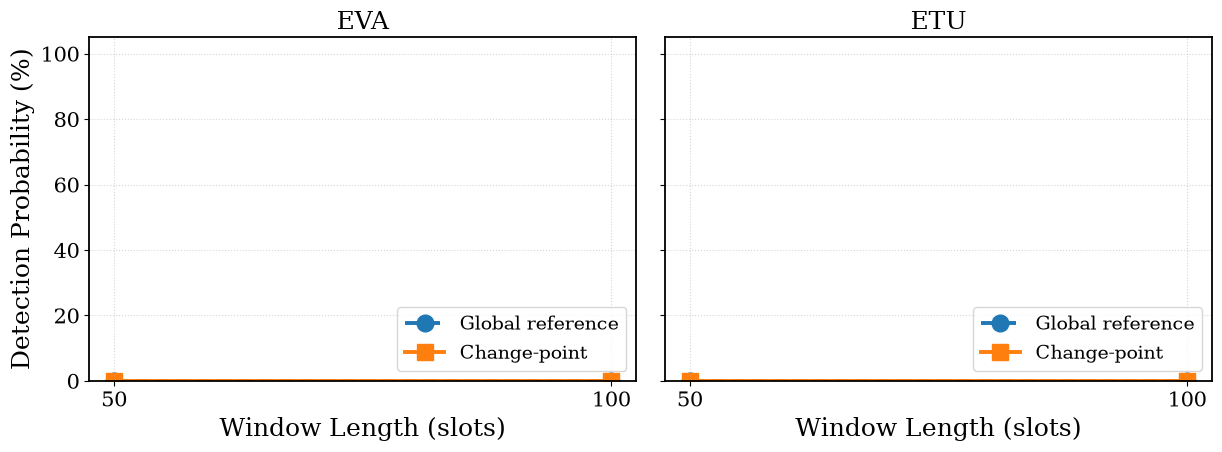


Runtime: 40.35 seconds
Calibration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/activation_global_vs_changepoint_calibration.csv
Results: /home/afanali/wcnc_project/WCL_CDT_Revision/results/activation_global_vs_changepoint_results.csv
Checkpoint: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/activation_global_vs_changepoint.pt
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/activation_global_vs_changepoint_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/activation_global_vs_changepoint_IEEE.png

CELL 10 GLOBAL VS CHANGE-POINT: PASS


In [10]:

# ============================================================
# CELL 10 — GLOBAL VS LOCAL ACTIVATION DRIFT DETECTION
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Global reference vs local change-point monitoring
# Continuous Doppler-correlated EPA / EVA / ETU
#
# Reviewer 1: Comments 6 and 7
# Reviewer 2: Comment 3
#
# Uses existing trained FCN from Cell 6.
# No retraining is performed.
# ============================================================

import time
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

CP_SNR_DB = 12.0

CP_WINDOWS = [50, 100]
CP_METHODS = ["global", "change_point"]

CP_ALPHA = float(CFG.ewma_alpha)
CP_EPS = 1e-6

CP_N_PRE = 300
CP_N_POST = 500
CP_N_TOTAL = CP_N_PRE + CP_N_POST
CP_DRIFT_ONSET = CP_N_PRE

CP_HOLD = 10

# Independent datasets
CP_N_REFERENCE = 10000
CP_N_CAL = 200
CP_N_DEV = 100

CP_TARGET_FAR = 0.01

model.eval()

print("=" * 72)
print("CELL 10 — GLOBAL VS CHANGE-POINT ACTIVATION DETECTION")
print("=" * 72)
print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", CP_SNR_DB, "dB")
print("Windows:", CP_WINDOWS)
print("Calibration trajectories:", CP_N_CAL)
print("Development trajectories:", CP_N_DEV)

start_time = time.time()

# ------------------------------------------------------------
# 2. Continuous fading channel generator
# ------------------------------------------------------------

@torch.no_grad()
def cp_generate_channel(profile, n_slots):

    H_long = generate_channel(
        profile=profile,
        batch_size=1,
        n_symbols=n_slots * N_S,
        device=DEVICE
    )

    H_long = H_long.squeeze(0)

    return (
        H_long.reshape(N_F, n_slots, N_S)
        .permute(1, 0, 2)
        .contiguous()
    )


# ------------------------------------------------------------
# 3. FCN activation extraction
# ------------------------------------------------------------

@torch.no_grad()
def cp_get_activations(H):

    _, Y, _ = simulate_ofdm(
        H,
        CP_SNR_DB
    )

    _, h_p, _ = extract_pilot_observations(Y)

    _, acts = model(
        h_p,
        return_activations=True
    )

    return [
        a.detach().cpu()
        for a in acts
    ]


# ------------------------------------------------------------
# 4. EPA reference activation statistics
# ------------------------------------------------------------

@torch.no_grad()
def cp_build_reference():

    batches = [[], [], []]

    batch_size = 512

    for start in range(0, CP_N_REFERENCE, batch_size):

        b = min(
            batch_size,
            CP_N_REFERENCE - start
        )

        H = generate_channel("EPA", b)

        acts = cp_get_activations(H)

        for i, a in enumerate(acts):
            batches[i].append(a)

    references = []

    for layer_batches in batches:

        a = torch.cat(layer_batches, dim=0)

        references.append({
            "mean": a.mean(dim=0),
            "std": a.std(dim=0, unbiased=False)
        })

    return references


CP_REFERENCE = cp_build_reference()

print("\nEPA reference statistics ready.")

# ------------------------------------------------------------
# 5. Rolling mean and standard deviation
# ------------------------------------------------------------

def cp_rolling_stats(a, window):

    # Use float64 accumulation for numerical stability
    x = a.to(torch.float64)

    cumulative = torch.cat(
        [
            torch.zeros(
                (1, x.shape[1]),
                dtype=torch.float64
            ),
            x.cumsum(dim=0)
        ],
        dim=0
    )

    cumulative_sq = torch.cat(
        [
            torch.zeros(
                (1, x.shape[1]),
                dtype=torch.float64
            ),
            x.square().cumsum(dim=0)
        ],
        dim=0
    )

    mean = (
        cumulative[window:]
        - cumulative[:-window]
    ) / window

    variance = (
        cumulative_sq[window:]
        - cumulative_sq[:-window]
    ) / window - mean.square()

    std = torch.sqrt(
        variance.clamp_min(0.0)
    )

    return mean, std


# ------------------------------------------------------------
# 6. Global-reference detector
# ------------------------------------------------------------

def cp_global_scores(acts, references, window):

    T = acts[0].shape[0]

    scores = np.full(
        T,
        np.nan,
        dtype=np.float64
    )

    layer_scores = []

    for a, ref in zip(acts, references):

        mu, sigma = cp_rolling_stats(a, window)

        ref_mu = ref["mean"].to(torch.float64)
        ref_std = ref["std"].to(torch.float64)

        denominator = (
            torch.linalg.vector_norm(ref_std)
            + CP_EPS
        )

        d_mean = (
            torch.linalg.vector_norm(
                mu - ref_mu,
                dim=1
            ) / denominator
        )

        d_std = (
            torch.linalg.vector_norm(
                sigma - ref_std,
                dim=1
            ) / denominator
        )

        layer_scores.append(
            d_mean + d_std
        )

    combined = torch.stack(
        layer_scores,
        dim=1
    ).mean(dim=1)

    scores[window - 1:] = combined.numpy()

    return scores


# ------------------------------------------------------------
# 7. Local change-point detector
# ------------------------------------------------------------

def cp_local_scores(acts, references, window):

    T = acts[0].shape[0]

    scores = np.full(
        T,
        np.nan,
        dtype=np.float64
    )

    layer_scores = []

    for a, ref in zip(acts, references):

        mu, _ = cp_rolling_stats(a, window)

        # mu[t] corresponds to window ending at t+W-1.
        # Compare adjacent non-overlapping windows.
        recent_mu = mu[window:]
        past_mu = mu[:-window]

        ref_std = ref["std"].to(torch.float64)

        denominator = (
            torch.linalg.vector_norm(ref_std)
            + CP_EPS
        )

        drift = (
            torch.linalg.vector_norm(
                recent_mu - past_mu,
                dim=1
            ) / denominator
        )

        layer_scores.append(drift)

    combined = torch.stack(
        layer_scores,
        dim=1
    ).mean(dim=1)

    # First valid point: t = 2W-1
    scores[2 * window - 1:] = combined.numpy()

    return scores


# ------------------------------------------------------------
# 8. EWMA smoothing
# ------------------------------------------------------------

def cp_ewma(values):

    out = np.full_like(
        values,
        np.nan,
        dtype=np.float64
    )

    previous = None

    for i, value in enumerate(values):

        if not np.isfinite(value):
            continue

        if previous is None:
            previous = float(value)
        else:
            previous = (
                CP_ALPHA * value
                + (1 - CP_ALPHA) * previous
            )

        out[i] = previous

    return out


# ------------------------------------------------------------
# 9. First valid detection event
# ------------------------------------------------------------

def cp_first_event(scores, threshold):

    count = 0

    for t, value in enumerate(scores):

        if not np.isfinite(value):
            continue

        if value >= threshold:
            count += 1

            if count >= CP_HOLD:
                return t
        else:
            count = 0

    return None


# ------------------------------------------------------------
# 10. Generate independent calibration trajectories
# ------------------------------------------------------------

CAL_SCORES = {
    (w, m): []
    for w in CP_WINDOWS
    for m in CP_METHODS
}

print("\nGenerating matched EPA calibration trajectories...")

for trial in range(CP_N_CAL):

    H = cp_generate_channel(
        "EPA",
        CP_N_TOTAL
    )

    acts = cp_get_activations(H)

    for w in CP_WINDOWS:

        global_score = cp_ewma(
            cp_global_scores(
                acts,
                CP_REFERENCE,
                w
            )
        )

        local_score = cp_ewma(
            cp_local_scores(
                acts,
                CP_REFERENCE,
                w
            )
        )

        CAL_SCORES[(w, "global")].append(
            global_score
        )

        CAL_SCORES[(w, "change_point")].append(
            local_score
        )

    if (trial + 1) % 25 == 0:
        print(
            f"Calibration {trial + 1}/{CP_N_CAL}"
        )


# ------------------------------------------------------------
# 11. Event-level threshold calibration
# ------------------------------------------------------------

CP_THRESHOLDS = {}

calibration_rows = []

for key, trajectories in CAL_SCORES.items():

    # Calibrate using the maximum EWMA score
    # over each complete EPA trajectory.
    maxima = np.asarray([
        np.nanmax(scores)
        for scores in trajectories
    ])

    threshold = float(
        np.quantile(
            maxima,
            1.0 - CP_TARGET_FAR
        )
    )

    CP_THRESHOLDS[key] = threshold

    event_far = np.mean([
        cp_first_event(
            scores,
            threshold
        ) is not None
        for scores in trajectories
    ])

    calibration_rows.append({
        "Window": key[0],
        "Method": key[1],
        "Threshold": threshold,
        "Calibration_Event_FAR": event_far
    })

    print(
        f"W={key[0]}, {key[1]:12s} | "
        f"Threshold={threshold:.4f} | "
        f"Event FAR={100*event_far:.2f}%"
    )


# ------------------------------------------------------------
# 12. Independent development evaluation
# ------------------------------------------------------------

evaluation_rows = []

print("\nEvaluating independent development trajectories...")

for profile in ["EPA", "EVA", "ETU"]:

    results = {
        key: []
        for key in CP_THRESHOLDS
    }

    for trial in range(CP_N_DEV):

        if profile == "EPA":

            H = cp_generate_channel(
                "EPA",
                CP_N_TOTAL
            )

        else:

            H_pre = cp_generate_channel(
                "EPA",
                CP_N_PRE
            )

            H_post = cp_generate_channel(
                profile,
                CP_N_POST
            )

            H = torch.cat(
                [H_pre, H_post],
                dim=0
            )

        acts = cp_get_activations(H)

        for w in CP_WINDOWS:

            scores = {
                "global": cp_ewma(
                    cp_global_scores(
                        acts,
                        CP_REFERENCE,
                        w
                    )
                ),
                "change_point": cp_ewma(
                    cp_local_scores(
                        acts,
                        CP_REFERENCE,
                        w
                    )
                )
            }

            for method in CP_METHODS:

                key = (w, method)

                event = cp_first_event(
                    scores[method],
                    CP_THRESHOLDS[key]
                )

                results[key].append(event)

        if (trial + 1) % 25 == 0:
            print(
                f"{profile}: {trial + 1}/{CP_N_DEV}"
            )

    for key, events in results.items():

        false_events = sum(
            t is not None
            and (profile == "EPA" or t < CP_DRIFT_ONSET)
            for t in events
        )

        if profile == "EPA":
            detection_rate = np.nan
            delay = np.nan
        else:
            valid = [
                t for t in events
                if t is not None
                and t >= CP_DRIFT_ONSET
            ]

            detection_rate = len(valid) / CP_N_DEV

            delay = (
                np.mean([
                    t - CP_DRIFT_ONSET
                    for t in valid
                ])
                if valid else np.nan
            )

        evaluation_rows.append({
            "Channel": profile,
            "Window": key[0],
            "Method": key[1],
            "False_Event_Rate": false_events / CP_N_DEV,
            "Detection_Rate": detection_rate,
            "Mean_Delay": delay
        })


# ------------------------------------------------------------
# 13. Results
# ------------------------------------------------------------

calibration_df = pd.DataFrame(
    calibration_rows
)

evaluation_df = pd.DataFrame(
    evaluation_rows
)

print("\n" + "=" * 72)
print("CELL 10 — DETECTION COMPARISON")
print("=" * 72)

print(
    evaluation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)


# ------------------------------------------------------------
# 14. IEEE-style comparison figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 14,
    "lines.linewidth": 2.8,
    "lines.markersize": 12,
    "axes.linewidth": 1.3,
    "savefig.dpi": 600
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 4.8),
    sharey=True
)

for ax, profile in zip(
    axes,
    ["EVA", "ETU"]
):

    subset = evaluation_df[
        evaluation_df["Channel"] == profile
    ]

    for method, marker, linestyle in [
        ("global", "o", "--"),
        ("change_point", "s", "-")
    ]:

        data = subset[
            subset["Method"] == method
        ].sort_values("Window")

        ax.plot(
            data["Window"],
            100 * data["Detection_Rate"],
            marker=marker,
            linestyle=linestyle,
            label=(
                "Global reference"
                if method == "global"
                else "Change-point"
            )
        )

    ax.set_title(profile)
    ax.set_xlabel("Window Length (slots)")
    ax.set_xticks(CP_WINDOWS)
    ax.set_ylim(0, 105)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(loc="lower right")

axes[0].set_ylabel(
    "Detection Probability (%)"
)

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "activation_global_vs_changepoint_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "activation_global_vs_changepoint_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 15. Save results
# ------------------------------------------------------------

calibration_path = (
    RESULTS_DIR /
    "activation_global_vs_changepoint_calibration.csv"
)

evaluation_path = (
    RESULTS_DIR /
    "activation_global_vs_changepoint_results.csv"
)

calibration_df.to_csv(
    calibration_path,
    index=False
)

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

checkpoint_path = (
    CHECKPOINT_DIR /
    "activation_global_vs_changepoint.pt"
)

torch.save(
    {
        "reference": CP_REFERENCE,
        "thresholds": CP_THRESHOLDS,
        "windows": CP_WINDOWS,
        "alpha": CP_ALPHA,
        "hold": CP_HOLD,
    },
    checkpoint_path
)

elapsed = time.time() - start_time

print("\nRuntime:", f"{elapsed:.2f} seconds")
print("Calibration:", calibration_path)
print("Results:", evaluation_path)
print("Checkpoint:", checkpoint_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 10 GLOBAL VS CHANGE-POINT: PASS")


CELL 10A — LAYER-WISE ACTIVATION DIAGNOSTICS
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Window: 100
Trials per scenario: 100
Drift onset: 300

Running EPA_to_EPA...
  Completed 25/100
  Completed 50/100
  Completed 75/100
  Completed 100/100

Running EPA_to_EVA...
  Completed 25/100
  Completed 50/100
  Completed 75/100
  Completed 100/100

Running EPA_to_ETU...
  Completed 25/100
  Completed 50/100
  Completed 75/100
  Completed 100/100

LAYER-WISE PRE/POST STATISTICS
  Scenario  Layer  Pre_Mean  Post_Mean  Pre_Std  Post_Std  Standardized_Separation
EPA_to_EPA      1    1.2895     1.2342   0.3579    0.3093                  -0.1655
EPA_to_EPA      2    1.3439     1.2903   0.3606    0.3081                  -0.1598
EPA_to_EPA      3    1.3413     1.2857   0.3631    0.3112                  -0.1646
EPA_to_EVA      1    1.2465     0.5981   0.2807    0.0822                  -3.1351
EPA_to_EVA      2    1.3053     0.6725   0.2791    0.0940                  -3.0382
EPA_to_EVA      3 

/tmp/ipykernel_1114/564654212.py:396: RuntimeWarning: Mean of empty slice
  mean_scores = np.nanmean(


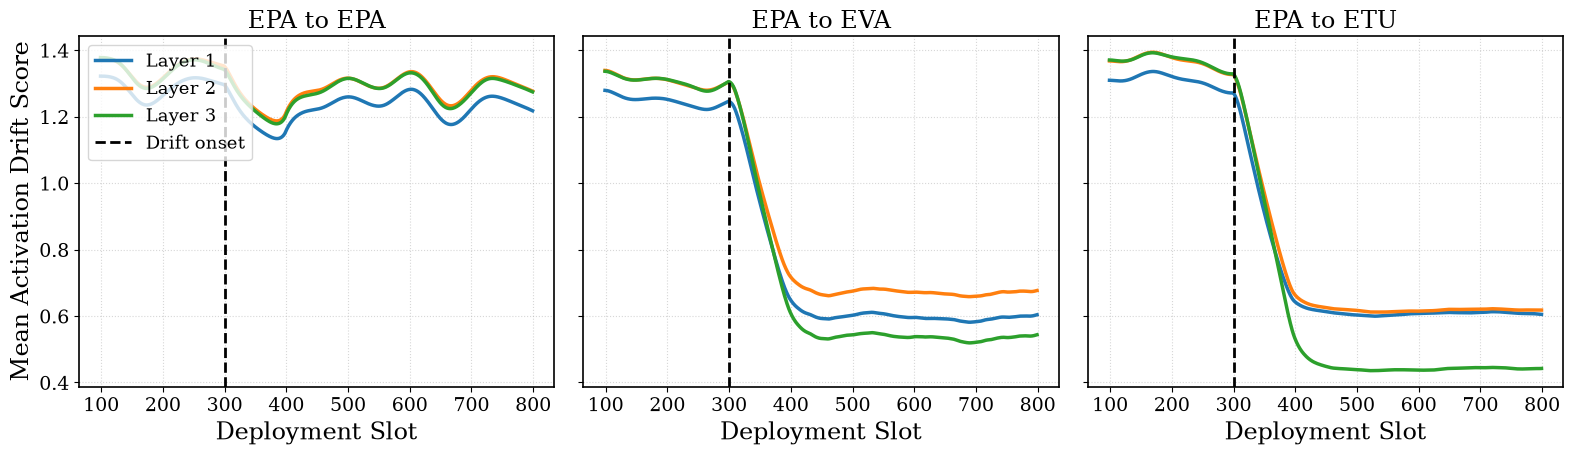


CELL 10A — FINAL SUMMARY
Runtime: 8.52 seconds

Saved files:
Statistics: /home/afanali/wcnc_project/WCL_CDT_Revision/results/activation_layerwise_diagnostics.csv
Trajectories: /home/afanali/wcnc_project/WCL_CDT_Revision/results/activation_layerwise_trajectories.npz
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/activation_layerwise_diagnostics_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/activation_layerwise_diagnostics_IEEE.png

CELL 10A LAYER-WISE DIAGNOSTICS: PASS


In [11]:

# ============================================================
# CELL 10A — LAYER-WISE ACTIVATION DRIFT DIAGNOSTICS
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Purpose:
#   Examine individual FCN hidden-layer responses under
#   continuous Doppler-correlated fading.
#
# Scenarios:
#   EPA -> EPA (unchanged-channel control)
#   EPA -> EVA
#   EPA -> ETU
#
# No thresholds or detector tuning are performed.
# No neural-network retraining is required.
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DIAG_SNR_DB = 12.0
DIAG_WINDOW = 100
DIAG_ALPHA = 0.05

DIAG_N_PRE = 300
DIAG_N_POST = 500
DIAG_N_TOTAL = DIAG_N_PRE + DIAG_N_POST
DIAG_DRIFT_ONSET = DIAG_N_PRE

DIAG_N_TRIALS = 100
DIAG_EPS = 1e-6

DIAG_SCENARIOS = {
    "EPA_to_EPA": ("EPA", "EPA"),
    "EPA_to_EVA": ("EPA", "EVA"),
    "EPA_to_ETU": ("EPA", "ETU"),
}

model.eval()

print("=" * 72)
print("CELL 10A — LAYER-WISE ACTIVATION DIAGNOSTICS")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", DIAG_SNR_DB, "dB")
print("Window:", DIAG_WINDOW)
print("Trials per scenario:", DIAG_N_TRIALS)
print("Drift onset:", DIAG_DRIFT_ONSET)

start_time = time.time()

# ------------------------------------------------------------
# 2. Reuse the EPA reference from Cell 10
# ------------------------------------------------------------

# Cell 10 defines CP_REFERENCE:
#   list of 3 dictionaries containing mean and std.
#
# We retain the same reference to ensure comparability.

assert "CP_REFERENCE" in globals(), (
    "CP_REFERENCE not found. Run Cell 10 first."
)

DIAG_REFERENCE = CP_REFERENCE

assert len(DIAG_REFERENCE) == 3

# ------------------------------------------------------------
# 3. Continuous fading channel generation
# ------------------------------------------------------------

@torch.no_grad()
def diag_generate_sequence(
    before_profile,
    after_profile,
):
    """
    Generate a channel sequence with an abrupt
    change at slot DIAG_DRIFT_ONSET.

    Each segment is temporally continuous.
    """

    H_pre = cp_generate_channel(
        before_profile,
        DIAG_N_PRE
    )

    H_post = cp_generate_channel(
        after_profile,
        DIAG_N_POST
    )

    H = torch.cat(
        [H_pre, H_post],
        dim=0
    )

    assert H.shape == (
        DIAG_N_TOTAL, N_F, N_S
    )

    return H


# ------------------------------------------------------------
# 4. Layer-wise activation drift scores
# ------------------------------------------------------------

def diag_layer_scores(
    activations,
    references,
    window=DIAG_WINDOW,
):
    """
    Compute global-reference drift for each hidden layer.

    Returns:
        scores: [T, 3]

    Each column corresponds to one FCN hidden layer.
    """

    T = activations[0].shape[0]

    scores = np.full(
        (T, len(activations)),
        np.nan,
        dtype=np.float64
    )

    for layer_idx, (a, ref) in enumerate(
        zip(activations, references)
    ):

        mu, sigma = cp_rolling_stats(
            a,
            window
        )

        ref_mu = ref["mean"].to(torch.float64)
        ref_sigma = ref["std"].to(torch.float64)

        denominator = (
            torch.linalg.vector_norm(ref_sigma)
            + DIAG_EPS
        )

        mean_drift = (
            torch.linalg.vector_norm(
                mu - ref_mu,
                dim=1
            ) / denominator
        )

        std_drift = (
            torch.linalg.vector_norm(
                sigma - ref_sigma,
                dim=1
            ) / denominator
        )

        layer_drift = (
            mean_drift + std_drift
        )

        scores[window - 1:, layer_idx] = (
            layer_drift.numpy()
        )

    return scores


# ------------------------------------------------------------
# 5. EWMA smoothing for each layer
# ------------------------------------------------------------

def diag_smooth_layers(scores, alpha):

    smoothed = np.full_like(
        scores,
        np.nan,
        dtype=np.float64
    )

    for layer_idx in range(scores.shape[1]):

        smoothed[:, layer_idx] = cp_ewma(
            scores[:, layer_idx]
        )

    return smoothed


# ------------------------------------------------------------
# 6. Run repeated deployment experiments
# ------------------------------------------------------------

DIAG_RESULTS = {}
summary_rows = []

for scenario_name, (before, after) in (
    DIAG_SCENARIOS.items()
):

    print(f"\nRunning {scenario_name}...")

    trial_scores = []

    for trial in range(DIAG_N_TRIALS):

        H = diag_generate_sequence(
            before,
            after
        )

        activations = cp_get_activations(H)

        raw_scores = diag_layer_scores(
            activations,
            DIAG_REFERENCE
        )

        smooth_scores = diag_smooth_layers(
            raw_scores,
            DIAG_ALPHA
        )

        trial_scores.append(smooth_scores)

        if (trial + 1) % 25 == 0:
            print(
                f"  Completed {trial + 1}/"
                f"{DIAG_N_TRIALS}"
            )

    trial_scores = np.stack(
        trial_scores,
        axis=0
    )

    # Shape: [trials, slots, layers]
    DIAG_RESULTS[scenario_name] = trial_scores

    # --------------------------------------------------------
    # Pre/post statistics for each layer
    # --------------------------------------------------------

    # Exclude initial incomplete monitoring windows.
    # Use equal-length pre/post analysis regions.
    pre_start = DIAG_WINDOW - 1
    pre_end = DIAG_DRIFT_ONSET

    # Exclude the transition-contaminated windows
    # immediately after the drift onset.
    post_start = (
        DIAG_DRIFT_ONSET + DIAG_WINDOW
    )

    post_end = DIAG_N_TOTAL

    for layer_idx in range(3):

        pre_values = trial_scores[
            :,
            pre_start:pre_end,
            layer_idx
        ].reshape(-1)

        post_values = trial_scores[
            :,
            post_start:post_end,
            layer_idx
        ].reshape(-1)

        pre_values = pre_values[
            np.isfinite(pre_values)
        ]

        post_values = post_values[
            np.isfinite(post_values)
        ]

        pre_mean = float(
            np.mean(pre_values)
        )

        post_mean = float(
            np.mean(post_values)
        )

        pre_std = float(
            np.std(pre_values, ddof=1)
        )

        post_std = float(
            np.std(post_values, ddof=1)
        )

        # Standardized mean difference
        pooled_std = np.sqrt(
            0.5 * (
                pre_std**2 + post_std**2
            )
        )

        separation = (
            (post_mean - pre_mean)
            / max(pooled_std, DIAG_EPS)
        )

        summary_rows.append({
            "Scenario": scenario_name,
            "Layer": layer_idx + 1,
            "Pre_Mean": pre_mean,
            "Post_Mean": post_mean,
            "Pre_Std": pre_std,
            "Post_Std": post_std,
            "Standardized_Separation": separation,
        })


# ------------------------------------------------------------
# 7. Save summary statistics
# ------------------------------------------------------------

diag_summary_df = pd.DataFrame(
    summary_rows
)

summary_path = (
    RESULTS_DIR /
    "activation_layerwise_diagnostics.csv"
)

diag_summary_df.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 72)
print("LAYER-WISE PRE/POST STATISTICS")
print("=" * 72)

print(
    diag_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# 8. IEEE-style figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "lines.linewidth": 2.5,
    "lines.markersize": 8,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.8),
    sharey=True
)

slots = np.arange(DIAG_N_TOTAL)

for ax, scenario_name in zip(
    axes,
    DIAG_SCENARIOS.keys()
):

    scores = DIAG_RESULTS[scenario_name]

    # Mean across independent trials
    mean_scores = np.nanmean(
        scores,
        axis=0
    )

    # Plot three layers
    for layer_idx in range(3):

        ax.plot(
            slots,
            mean_scores[:, layer_idx],
            linewidth=2.5,
            label=f"Layer {layer_idx + 1}"
        )

    ax.axvline(
        DIAG_DRIFT_ONSET,
        color="black",
        linestyle="--",
        linewidth=2,
        label="Drift onset"
    )

    ax.set_title(
        scenario_name.replace("_", " ")
    )

    ax.set_xlabel(
        "Deployment Slot"
    )

    ax.grid(
        True,
        linestyle=":",
        alpha=0.5
    )

axes[0].set_ylabel(
    "Mean Activation Drift Score"
)

axes[0].legend(
    loc="upper left",
    frameon=True
)

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "activation_layerwise_diagnostics_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "activation_layerwise_diagnostics_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 9. Save trajectory data
# ------------------------------------------------------------

trajectory_path = (
    RESULTS_DIR /
    "activation_layerwise_trajectories.npz"
)

np.savez_compressed(
    trajectory_path,
    **DIAG_RESULTS
)


# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 10A — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")

print("\nSaved files:")
print("Statistics:", summary_path)
print("Trajectories:", trajectory_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 10A LAYER-WISE DIAGNOSTICS: PASS")


CELL 10B — EVENT-MATCHED TWO-SIDED MONITORING
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Window: 100
EWMA alpha: 0.05
Hold-off: 10
Calibration trajectories: 300
Development trials: 150
Target event FAR: 0.01

Generating matched EPA calibration trajectories...
Calibration 50/300
Calibration 100/300
Calibration 150/300
Calibration 200/300
Calibration 250/300
Calibration 300/300
average: center = 1.236469
layer3: center = 1.261257
average: threshold=1.382432, event FAR=1.00%
layer3: threshold=1.403283, event FAR=1.00%

Evaluating independent development trajectories...
EPA_to_EPA: 50/150
EPA_to_EPA: 100/150
EPA_to_EPA: 150/150
EPA_to_EVA: 50/150
EPA_to_EVA: 100/150
EPA_to_EVA: 150/150
EPA_to_ETU: 50/150
EPA_to_ETU: 100/150
EPA_to_ETU: 150/150

CELL 10B — EVENT-MATCHED DETECTION RESULTS
  Scenario  Method  False_Event_Rate  Detection_Rate  Mean_Delay
EPA_to_EPA average            0.0533             NaN         NaN
EPA_to_EPA  layer3            0.0467             NaN         NaN
E

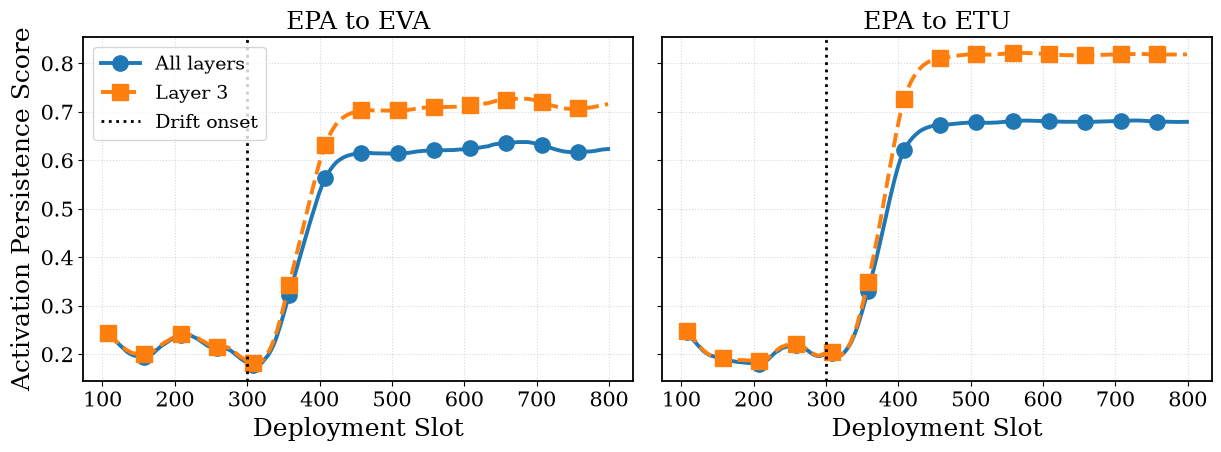


CELL 10B — FINAL SUMMARY
Runtime: 20.65 seconds
Calibration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/activation_persistence_calibration.csv
Evaluation: /home/afanali/wcnc_project/WCL_CDT_Revision/results/activation_persistence_results.csv
Checkpoint: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/activation_persistence_detector.pt
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/activation_persistence_comparison_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/activation_persistence_comparison_IEEE.png

CELL 10B EVENT-MATCHED MONITORING: PASS


In [12]:

# ============================================================
# CELL 10B — TWO-SIDED ACTIVATION DETECTION
# EVENT-MATCHED PERSISTENCE CALIBRATION
#
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Compare:
#   1. Average of three hidden-layer drift scores
#   2. Layer 3 drift score
#
# Calibration:
#   10-slot persistence statistic on correlated EPA
#
# Evaluation:
#   EPA -> EPA, EPA -> EVA, EPA -> ETU
#
# No neural-network retraining required.
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
TS_SNR_DB = 12.0

TS_WINDOW = 100
TS_ALPHA = 0.05
TS_HOLD = 10

TS_N_PRE = 300
TS_N_POST = 500
TS_N_TOTAL = TS_N_PRE + TS_N_POST
TS_DRIFT_ONSET = TS_N_PRE

TS_N_CAL = 300
TS_N_DEV = 150

TS_TARGET_FAR = 0.01
TS_EPS = 1e-8

TS_METHODS = ["average", "layer3"]

TS_SCENARIOS = {
    "EPA_to_EPA": ("EPA", "EPA"),
    "EPA_to_EVA": ("EPA", "EVA"),
    "EPA_to_ETU": ("EPA", "ETU"),
}

TS_SEED = SEED + 1100

torch.manual_seed(TS_SEED)
torch.cuda.manual_seed_all(TS_SEED)
np.random.seed(TS_SEED)

model.eval()

print("=" * 72)
print("CELL 10B — EVENT-MATCHED TWO-SIDED MONITORING")
print("=" * 72)
print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", TS_SNR_DB, "dB")
print("Window:", TS_WINDOW)
print("EWMA alpha:", TS_ALPHA)
print("Hold-off:", TS_HOLD)
print("Calibration trajectories:", TS_N_CAL)
print("Development trials:", TS_N_DEV)
print("Target event FAR:", TS_TARGET_FAR)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify earlier definitions
# ------------------------------------------------------------
required_names = [
    "CP_REFERENCE",
    "cp_generate_channel",
    "cp_get_activations",
    "cp_rolling_stats",
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing earlier definitions: {missing}. "
        "Run Cells 1-10A first."
    )

TS_REFERENCE = CP_REFERENCE

# ------------------------------------------------------------
# 3. Generate deployment sequence
# ------------------------------------------------------------
@torch.no_grad()
def ts_generate_sequence(before, after):

    H_pre = cp_generate_channel(
        before, TS_N_PRE
    )

    H_post = cp_generate_channel(
        after, TS_N_POST
    )

    return torch.cat(
        [H_pre, H_post],
        dim=0
    )

# ------------------------------------------------------------
# 4. Layer-wise global-reference drift scores
# ------------------------------------------------------------
def ts_layer_scores(activations):

    T = activations[0].shape[0]

    scores = np.full(
        (T, 3),
        np.nan,
        dtype=np.float64
    )

    for layer_idx, (a, ref) in enumerate(
        zip(activations, TS_REFERENCE)
    ):

        mu, sigma = cp_rolling_stats(
            a, TS_WINDOW
        )

        ref_mu = ref["mean"].to(torch.float64)
        ref_std = ref["std"].to(torch.float64)

        denominator = (
            torch.linalg.vector_norm(ref_std)
            + TS_EPS
        )

        mean_drift = (
            torch.linalg.vector_norm(
                mu - ref_mu,
                dim=1
            ) / denominator
        )

        std_drift = (
            torch.linalg.vector_norm(
                sigma - ref_std,
                dim=1
            ) / denominator
        )

        scores[TS_WINDOW - 1:, layer_idx] = (
            mean_drift + std_drift
        ).numpy()

    return scores

# ------------------------------------------------------------
# 5. Aggregate layer scores
# ------------------------------------------------------------
def ts_aggregate_scores(layer_scores, method):

    if method == "average":
        return np.mean(layer_scores, axis=1)

    if method == "layer3":
        return layer_scores[:, 2].copy()

    raise ValueError(f"Unknown method: {method}")

# ------------------------------------------------------------
# 6. EWMA smoothing
# ------------------------------------------------------------
def ts_ewma(values):

    output = np.full(
        len(values), np.nan, dtype=np.float64
    )

    previous = None

    for t, value in enumerate(values):

        if not np.isfinite(value):
            continue

        if previous is None:
            previous = float(value)
        else:
            previous = (
                TS_ALPHA * value
                + (1.0 - TS_ALPHA) * previous
            )

        output[t] = previous

    return output

# ------------------------------------------------------------
# 7. Two-sided anomaly score
# ------------------------------------------------------------
def ts_anomaly_score(smooth_scores, center):

    anomaly = np.full_like(
        smooth_scores,
        np.nan,
        dtype=np.float64
    )

    valid = np.isfinite(smooth_scores)

    anomaly[valid] = np.abs(
        smooth_scores[valid] - center
    )

    return anomaly

# ------------------------------------------------------------
# 8. Persistence statistic
# ------------------------------------------------------------
def ts_persistence_score(anomaly, hold=TS_HOLD):
    """
    S_hold(t) = minimum anomaly in the last
    'hold' consecutive slots.

    A valid value exists only if all observations
    in the hold window are finite.
    """

    anomaly = np.asarray(
        anomaly, dtype=np.float64
    )

    persistence = np.full_like(
        anomaly, np.nan
    )

    for t in range(hold - 1, len(anomaly)):

        segment = anomaly[
            t - hold + 1:t + 1
        ]

        if np.isfinite(segment).all():
            persistence[t] = np.min(segment)

    return persistence

# ------------------------------------------------------------
# 9. First valid detection event
# ------------------------------------------------------------
def ts_first_event(persistence, threshold):

    indices = np.flatnonzero(
        np.isfinite(persistence)
        & (persistence >= threshold)
    )

    return (
        int(indices[0])
        if len(indices) > 0
        else None
    )

# ------------------------------------------------------------
# 10. Matched EPA calibration trajectories
# ------------------------------------------------------------
print("\nGenerating matched EPA calibration trajectories...")

TS_CAL_SCORES = {
    method: []
    for method in TS_METHODS
}

for trial in range(TS_N_CAL):

    H = cp_generate_channel(
        "EPA", TS_N_TOTAL
    )

    activations = cp_get_activations(H)

    layer_scores = ts_layer_scores(activations)

    for method in TS_METHODS:

        raw = ts_aggregate_scores(
            layer_scores, method
        )

        smooth = ts_ewma(raw)

        TS_CAL_SCORES[method].append(smooth)

    if (trial + 1) % 50 == 0:
        print(
            f"Calibration {trial + 1}/{TS_N_CAL}"
        )

# ------------------------------------------------------------
# 11. Estimate matched EPA centers
# ------------------------------------------------------------
TS_CENTERS = {}

for method in TS_METHODS:

    pooled = np.concatenate([
        s[np.isfinite(s)]
        for s in TS_CAL_SCORES[method]
    ])

    TS_CENTERS[method] = float(
        np.median(pooled)
    )

    print(
        f"{method}: center = "
        f"{TS_CENTERS[method]:.6f}"
    )

# ------------------------------------------------------------
# 12. Event-matched threshold calibration
# ------------------------------------------------------------
TS_THRESHOLDS = {}
TS_CALIBRATION_ROWS = []

for method in TS_METHODS:

    center = TS_CENTERS[method]

    persistence_trajectories = []

    for smooth in TS_CAL_SCORES[method]:

        anomaly = ts_anomaly_score(
            smooth, center
        )

        persistence = ts_persistence_score(
            anomaly, TS_HOLD
        )

        persistence_trajectories.append(
            persistence
        )

    # Maximum persistence statistic per EPA trajectory
    trajectory_maxima = np.array([
        np.nanmax(p)
        for p in persistence_trajectories
    ])

    # Event-level threshold
    threshold = float(
        np.quantile(
            trajectory_maxima,
            1.0 - TS_TARGET_FAR
        )
    )

    TS_THRESHOLDS[method] = threshold

    calibration_events = sum(
        ts_first_event(p, threshold) is not None
        for p in persistence_trajectories
    )

    calibration_far = (
        calibration_events / TS_N_CAL
    )

    TS_CALIBRATION_ROWS.append({
        "Method": method,
        "Center": center,
        "Threshold": threshold,
        "Calibration_Event_FAR": calibration_far,
        "Mean_Trajectory_Maximum": float(
            trajectory_maxima.mean()
        ),
    })

    print(
        f"{method}: "
        f"threshold={threshold:.6f}, "
        f"event FAR={100*calibration_far:.2f}%"
    )

# ------------------------------------------------------------
# 13. Independent development evaluation
# ------------------------------------------------------------
print("\nEvaluating independent development trajectories...")

TS_RESULTS = {}
evaluation_rows = []

for scenario, (before, after) in TS_SCENARIOS.items():

    TS_RESULTS[scenario] = {
        method: []
        for method in TS_METHODS
    }

    for trial in range(TS_N_DEV):

        H = ts_generate_sequence(
            before, after
        )

        activations = cp_get_activations(H)

        layer_scores = ts_layer_scores(activations)

        for method in TS_METHODS:

            raw = ts_aggregate_scores(
                layer_scores, method
            )

            smooth = ts_ewma(raw)

            anomaly = ts_anomaly_score(
                smooth,
                TS_CENTERS[method]
            )

            persistence = ts_persistence_score(
                anomaly, TS_HOLD
            )

            event = ts_first_event(
                persistence,
                TS_THRESHOLDS[method]
            )

            TS_RESULTS[scenario][method].append({
                "event": event,
                "anomaly": anomaly,
                "persistence": persistence,
            })

        if (trial + 1) % 50 == 0:
            print(
                f"{scenario}: {trial + 1}/{TS_N_DEV}"
            )

    for method in TS_METHODS:

        events = [
            item["event"]
            for item in TS_RESULTS[scenario][method]
        ]

        false_events = sum(
            t is not None and (
                scenario == "EPA_to_EPA"
                or t < TS_DRIFT_ONSET
            )
            for t in events
        )

        if scenario == "EPA_to_EPA":

            detection_rate = np.nan
            mean_delay = np.nan

        else:

            valid_events = [
                t for t in events
                if t is not None
                and t >= TS_DRIFT_ONSET
            ]

            detection_rate = (
                len(valid_events) / TS_N_DEV
            )

            mean_delay = (
                float(np.mean([
                    t - TS_DRIFT_ONSET
                    for t in valid_events
                ]))
                if valid_events
                else np.nan
            )

        evaluation_rows.append({
            "Scenario": scenario,
            "Method": method,
            "False_Event_Rate": false_events / TS_N_DEV,
            "Detection_Rate": detection_rate,
            "Mean_Delay": mean_delay,
        })

# ------------------------------------------------------------
# 14. Results table
# ------------------------------------------------------------
calibration_df = pd.DataFrame(
    TS_CALIBRATION_ROWS
)

evaluation_df = pd.DataFrame(
    evaluation_rows
)

print("\n" + "=" * 72)
print("CELL 10B — EVENT-MATCHED DETECTION RESULTS")
print("=" * 72)

print(
    evaluation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 15. IEEE-style figure
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 14,
    "lines.linewidth": 2.8,
    "lines.markersize": 11,
    "axes.linewidth": 1.3,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 4.8),
    sharey=True
)

for ax, scenario in zip(
    axes,
    ["EPA_to_EVA", "EPA_to_ETU"]
):

    for method, marker, linestyle in [
        ("average", "o", "-"),
        ("layer3", "s", "--")
    ]:

        trials = TS_RESULTS[scenario][method]

        persistence_matrix = np.stack([
            item["persistence"]
            for item in trials
        ])

        # Avoid initial NaN-only windows
        valid_start = TS_WINDOW + TS_HOLD - 2

        mean_persistence = np.nanmean(
            persistence_matrix[:, valid_start:],
            axis=0
        )

        slots = np.arange(
            valid_start,
            TS_N_TOTAL
        )

        ax.plot(
            slots,
            mean_persistence,
            marker=marker,
            markevery=50,
            linestyle=linestyle,
            label=(
                "All layers"
                if method == "average"
                else "Layer 3"
            )
        )

    ax.axvline(
        TS_DRIFT_ONSET,
        color="black",
        linestyle=":",
        linewidth=2,
        label="Drift onset"
    )

    ax.set_title(
        scenario.replace("_", " ")
    )

    ax.set_xlabel(
        "Deployment Slot"
    )

    ax.grid(
        True,
        linestyle=":",
        alpha=0.5
    )

axes[0].set_ylabel(
    "Activation Persistence Score"
)

axes[0].legend(
    loc="upper left",
    frameon=True
)

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "activation_persistence_comparison_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "activation_persistence_comparison_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 16. Save calibration and evaluation results
# ------------------------------------------------------------
calibration_path = (
    RESULTS_DIR /
    "activation_persistence_calibration.csv"
)

evaluation_path = (
    RESULTS_DIR /
    "activation_persistence_results.csv"
)

calibration_df.to_csv(
    calibration_path,
    index=False
)

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

checkpoint_path = (
    CHECKPOINT_DIR /
    "activation_persistence_detector.pt"
)

torch.save(
    {
        "reference": TS_REFERENCE,
        "centers": TS_CENTERS,
        "thresholds": TS_THRESHOLDS,
        "window": TS_WINDOW,
        "alpha": TS_ALPHA,
        "hold": TS_HOLD,
        "target_event_far": TS_TARGET_FAR,
    },
    checkpoint_path
)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 10B — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Calibration:", calibration_path)
print("Evaluation:", evaluation_path)
print("Checkpoint:", checkpoint_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 10B EVENT-MATCHED MONITORING: PASS")


In [13]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [14]:

# ============================================================
# CELL 10C — MATCHED-CONTROL ACTIVATION ROC ANALYSIS
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Objective:
# Determine whether activation monitoring distinguishes
# genuine channel-profile changes from a new realization
# of the same EPA channel.
#
# Null hypothesis:
#   EPA -> EPA
#
# Alternatives:
#   EPA -> EVA
#   EPA -> ETU
#
# Detectors:
#   1. All-layer average
#   2. Layer 3
#
# Analysis:
#   - Trajectory-level score distributions
#   - ROC curves and AUC
#   - Detection probability at 1% empirical FAR
#   - Local baseline-adjusted diagnostic
#
# No neural-network retraining.
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

ROC_SNR_DB = 12.0

ROC_WINDOW = 100
ROC_ALPHA = 0.05
ROC_HOLD = 10

ROC_N_PRE = 300
ROC_N_POST = 500
ROC_N_TOTAL = ROC_N_PRE + ROC_N_POST
ROC_ONSET = ROC_N_PRE

ROC_N_TRIALS = 300

ROC_METHODS = ["average", "layer3"]

ROC_SCENARIOS = {
    "EPA_to_EPA": ("EPA", "EPA"),
    "EPA_to_EVA": ("EPA", "EVA"),
    "EPA_to_ETU": ("EPA", "ETU"),
}

ROC_TARGET_FAR = 0.01
ROC_EPS = 1e-8

ROC_SEED = SEED + 1200

torch.manual_seed(ROC_SEED)
torch.cuda.manual_seed_all(ROC_SEED)
np.random.seed(ROC_SEED)

model.eval()

print("=" * 72)
print("CELL 10C — MATCHED-CONTROL ACTIVATION ROC")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", ROC_SNR_DB, "dB")
print("Window:", ROC_WINDOW)
print("Trials per scenario:", ROC_N_TRIALS)
print("Total trials:", ROC_N_TRIALS * 3)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify dependencies from previous cells
# ------------------------------------------------------------

required = [
    "CP_REFERENCE",
    "cp_generate_channel",
    "cp_get_activations",
    "cp_rolling_stats",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing definitions: {missing}. "
        "Run Cells 1-10B first."
    )

ROC_REFERENCE = CP_REFERENCE

# ------------------------------------------------------------
# 3. Continuous channel sequence
# ------------------------------------------------------------

@torch.no_grad()
def roc_generate_sequence(before, after):

    H_pre = cp_generate_channel(
        before,
        ROC_N_PRE
    )

    H_post = cp_generate_channel(
        after,
        ROC_N_POST
    )

    return torch.cat(
        [H_pre, H_post],
        dim=0
    )

# ------------------------------------------------------------
# 4. Layer-wise activation scores
# ------------------------------------------------------------

def roc_layer_scores(activations):

    T = activations[0].shape[0]

    scores = np.full(
        (T, 3),
        np.nan,
        dtype=np.float64
    )

    for layer_idx, (a, ref) in enumerate(
        zip(activations, ROC_REFERENCE)
    ):

        mu, sigma = cp_rolling_stats(
            a,
            ROC_WINDOW
        )

        ref_mu = ref["mean"].to(torch.float64)
        ref_std = ref["std"].to(torch.float64)

        denominator = (
            torch.linalg.vector_norm(ref_std)
            + ROC_EPS
        )

        mean_drift = (
            torch.linalg.vector_norm(
                mu - ref_mu,
                dim=1
            ) / denominator
        )

        std_drift = (
            torch.linalg.vector_norm(
                sigma - ref_std,
                dim=1
            ) / denominator
        )

        scores[ROC_WINDOW - 1:, layer_idx] = (
            mean_drift + std_drift
        ).numpy()

    return scores

# ------------------------------------------------------------
# 5. EWMA
# ------------------------------------------------------------

def roc_ewma(values):

    output = np.full(
        len(values),
        np.nan,
        dtype=np.float64
    )

    previous = None

    for t, value in enumerate(values):

        if not np.isfinite(value):
            continue

        if previous is None:
            previous = float(value)
        else:
            previous = (
                ROC_ALPHA * value
                + (1.0 - ROC_ALPHA) * previous
            )

        output[t] = previous

    return output

# ------------------------------------------------------------
# 6. Aggregate detector scores
# ------------------------------------------------------------

def roc_aggregate(layer_scores, method):

    if method == "average":
        return np.mean(
            layer_scores,
            axis=1
        )

    if method == "layer3":
        return layer_scores[:, 2].copy()

    raise ValueError(method)

# ------------------------------------------------------------
# 7. Persistence score
# ------------------------------------------------------------

def roc_persistence(values, hold=ROC_HOLD):

    persistence = np.full_like(
        values,
        np.nan,
        dtype=np.float64
    )

    for t in range(hold - 1, len(values)):

        segment = values[
            t - hold + 1:t + 1
        ]

        if np.isfinite(segment).all():
            persistence[t] = np.min(segment)

    return persistence

# ------------------------------------------------------------
# 8. Extract trajectory-level statistics
# ------------------------------------------------------------

def roc_trajectory_features(scores):

    """
    Diagnostic features:

    1. Global two-sided deviation:
       |score - matched EPA center|

    2. Local baseline-adjusted deviation:
       |score - pre-transition baseline|

    Both use post-transition persistence maxima.

    The second feature uses known transition timing,
    so it is diagnostic, not deployable as written.
    """

    valid_pre = scores[
        ROC_WINDOW - 1:ROC_ONSET
    ]

    baseline = float(
        np.nanmedian(valid_pre)
    )

    return baseline

# ------------------------------------------------------------
# 9. Collect matched-control trajectories
# ------------------------------------------------------------

ROC_RESULTS = []

# Store trajectories for later analysis
ROC_TRAJECTORIES = {
    scenario: {
        method: []
        for method in ROC_METHODS
    }
    for scenario in ROC_SCENARIOS
}

for scenario, (before, after) in ROC_SCENARIOS.items():

    print(f"\nGenerating {scenario}...")

    for trial in range(ROC_N_TRIALS):

        H = roc_generate_sequence(
            before,
            after
        )

        activations = cp_get_activations(H)

        layer_scores = roc_layer_scores(
            activations
        )

        for method in ROC_METHODS:

            raw = roc_aggregate(
                layer_scores,
                method
            )

            smooth = roc_ewma(raw)

            ROC_TRAJECTORIES[scenario][method].append(
                smooth
            )

            baseline = roc_trajectory_features(
                smooth
            )

            ROC_RESULTS.append({
                "Scenario": scenario,
                "Trial": trial,
                "Method": method,
                "Baseline": baseline
            })

        if (trial + 1) % 50 == 0:
            print(
                f"  Completed {trial + 1}/"
                f"{ROC_N_TRIALS}"
            )

# ------------------------------------------------------------
# 10. Estimate matched EPA score centers
# ------------------------------------------------------------

ROC_CENTERS = {}

for method in ROC_METHODS:

    null_scores = ROC_TRAJECTORIES[
        "EPA_to_EPA"
    ][method]

    # Use only pre-transition EPA observations
    pooled = np.concatenate([
        s[ROC_WINDOW - 1:ROC_ONSET]
        for s in null_scores
    ])

    ROC_CENTERS[method] = float(
        np.nanmedian(pooled)
    )

    print(
        f"{method}: EPA center = "
        f"{ROC_CENTERS[method]:.6f}"
    )

# ------------------------------------------------------------
# 11. Compute trajectory-level anomaly statistics
# ------------------------------------------------------------

feature_rows = []

for scenario in ROC_SCENARIOS:

    for method in ROC_METHODS:

        center = ROC_CENTERS[method]

        for trial, smooth in enumerate(
            ROC_TRAJECTORIES[scenario][method]
        ):

            baseline = roc_trajectory_features(
                smooth
            )

            # Global two-sided anomaly
            global_anomaly = np.abs(
                smooth - center
            )

            # Local baseline-adjusted anomaly
            local_anomaly = np.abs(
                smooth - baseline
            )

            global_persistence = roc_persistence(
                global_anomaly
            )

            local_persistence = roc_persistence(
                local_anomaly
            )

            # Post-transition diagnostic interval
            post_slice = slice(
                ROC_ONSET,
                ROC_N_TOTAL
            )

            global_stat = float(
                np.nanmax(
                    global_persistence[post_slice]
                )
            )

            local_stat = float(
                np.nanmax(
                    local_persistence[post_slice]
                )
            )

            feature_rows.append({
                "Scenario": scenario,
                "Trial": trial,
                "Method": method,
                "Global_Statistic": global_stat,
                "Local_Statistic": local_stat,
            })

feature_df = pd.DataFrame(
    feature_rows
)

# ------------------------------------------------------------
# 12. ROC and AUC analysis
# ------------------------------------------------------------

roc_rows = []
roc_curve_data = {}

for method in ROC_METHODS:

    for statistic in [
        "Global_Statistic",
        "Local_Statistic"
    ]:

        for alternative in [
            "EPA_to_EVA",
            "EPA_to_ETU"
        ]:

            null_values = feature_df[
                (feature_df["Scenario"] == "EPA_to_EPA")
                & (feature_df["Method"] == method)
            ][statistic].to_numpy()

            alternative_values = feature_df[
                (feature_df["Scenario"] == alternative)
                & (feature_df["Method"] == method)
            ][statistic].to_numpy()

            labels = np.concatenate([
                np.zeros(len(null_values)),
                np.ones(len(alternative_values))
            ])

            values = np.concatenate([
                null_values,
                alternative_values
            ])

            auc = roc_auc_score(
                labels,
                values
            )

            fpr, tpr, thresholds = roc_curve(
                labels,
                values
            )

            # Empirical 1% false-alarm threshold
            threshold = float(
                np.quantile(
                    null_values,
                    1.0 - ROC_TARGET_FAR
                )
            )

            detection_probability = float(
                np.mean(
                    alternative_values > threshold
                )
            )

            empirical_far = float(
                np.mean(
                    null_values > threshold
                )
            )

            key = (
                method,
                statistic,
                alternative
            )

            roc_curve_data[key] = {
                "fpr": fpr,
                "tpr": tpr,
                "auc": auc
            }

            roc_rows.append({
                "Method": method,
                "Statistic": statistic,
                "Alternative": alternative,
                "AUC": auc,
                "FAR_at_1pct": empirical_far,
                "Detection_at_1pct_FAR":
                    detection_probability
            })

roc_df = pd.DataFrame(
    roc_rows
)

print("\n" + "=" * 72)
print("CELL 10C — ROC SUMMARY")
print("=" * 72)

print(
    roc_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 13. IEEE-style figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.5,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.8, 5.0)
)

# Panel (a): score distributions
ax = axes[0]

for scenario, label in [
    ("EPA_to_EPA", "EPA-EPA"),
    ("EPA_to_EVA", "EPA-EVA"),
    ("EPA_to_ETU", "EPA-ETU")
]:

    values = feature_df[
        (feature_df["Scenario"] == scenario)
        & (feature_df["Method"] == "layer3")
    ]["Local_Statistic"].to_numpy()

    ax.hist(
        values,
        bins=25,
        density=True,
        alpha=0.45,
        label=label
    )

ax.set_xlabel(
    "Trajectory-Level Local Anomaly"
)

ax.set_ylabel(
    "Probability Density"
)

ax.set_title(
    "(a) Matched-Control Score Distributions"
)

ax.grid(True, alpha=0.3)
ax.legend()

# Panel (b): ROC curves
ax = axes[1]

for alternative, label in [
    ("EPA_to_EVA", "EPA-EVA"),
    ("EPA_to_ETU", "EPA-ETU")
]:

    key = (
        "layer3",
        "Local_Statistic",
        alternative
    )

    result = roc_curve_data[key]

    ax.plot(
        result["fpr"],
        result["tpr"],
        label=(
            f"{label} "
            f"(AUC={result['auc']:.3f})"
        )
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.5
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

ax.set_title(
    "(b) Layer-3 Local-Change ROC"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.grid(True, alpha=0.3)
ax.legend(loc="lower right")

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "activation_matched_control_ROC_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "activation_matched_control_ROC_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 14. Save results
# ------------------------------------------------------------

feature_path = (
    RESULTS_DIR /
    "activation_matched_control_features.csv"
)

roc_path = (
    RESULTS_DIR /
    "activation_matched_control_roc.csv"
)

feature_df.to_csv(
    feature_path,
    index=False
)

roc_df.to_csv(
    roc_path,
    index=False
)

# Save ROC curve arrays
curve_path = (
    RESULTS_DIR /
    "activation_matched_control_curves.npz"
)

curve_arrays = {}

for key, result in roc_curve_data.items():

    name = "_".join(key)

    curve_arrays[name + "_fpr"] = result["fpr"]
    curve_arrays[name + "_tpr"] = result["tpr"]

np.savez_compressed(
    curve_path,
    **curve_arrays
)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 10C — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Features:", feature_path)
print("ROC metrics:", roc_path)
print("ROC curves:", curve_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 10C MATCHED-CONTROL ROC: PASS")


CELL 10C — MATCHED-CONTROL ACTIVATION ROC
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Window: 100
Trials per scenario: 300
Total trials: 900

Generating EPA_to_EPA...
  Completed 50/300


KeyboardInterrupt: 

CELL 10D — DIRECTIONAL LAYER-3 MONITORING
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Window: 100
EWMA alpha: 0.05
Hold-off: 10
Calibration trials: 500
Development trials: 200
Target event FAR: 0.01

Generating matched EPA->EPA calibration trajectories...
Calibration 100/500
Calibration 200/500
Calibration 300/500
Calibration 400/500
Calibration 500/500

Matched EPA center: 1.2723728402125996
upper      | Threshold=1.445998 | Calibration FAR=1.00%
lower      | Threshold=0.668883 | Calibration FAR=1.00%
two_sided  | Threshold=1.445998 | Calibration FAR=1.00%

Evaluating independent deployment trajectories...
EPA_to_EPA: 50/200
EPA_to_EPA: 100/200
EPA_to_EPA: 150/200
EPA_to_EPA: 200/200
EPA_to_EVA: 50/200
EPA_to_EVA: 100/200
EPA_to_EVA: 150/200
EPA_to_EVA: 200/200
EPA_to_ETU: 50/200
EPA_to_ETU: 100/200
EPA_to_ETU: 150/200
EPA_to_ETU: 200/200

CELL 10D — DIRECTIONAL DETECTION RESULTS
  Scenario    Method  False_Event_Rate  Detection_Rate  Mean_Delay
EPA_to_EPA     upper          

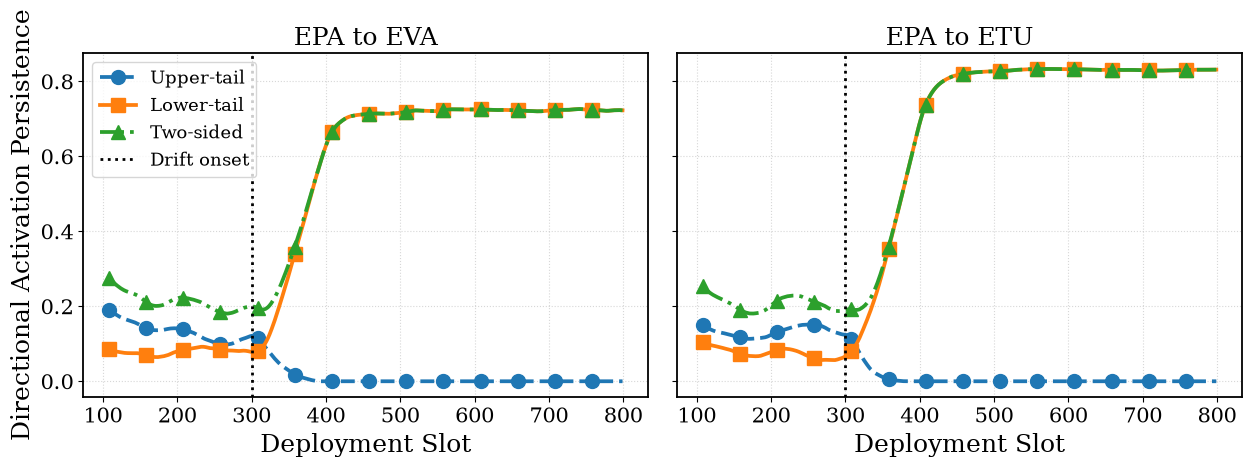


CELL 10D — FINAL SUMMARY
Runtime: 16.38 seconds
Calibration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/activation_directional_calibration.csv
Evaluation: /home/afanali/wcnc_project/WCL_CDT_Revision/results/activation_directional_results.csv
Checkpoint: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/activation_directional_detector.pt
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/activation_directional_comparison_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/activation_directional_comparison_IEEE.png

CELL 10D DIRECTIONAL MONITORING: PASS


In [ ]:

# ============================================================
# CELL 10D — DIRECTIONAL LAYER-3 ACTIVATION DETECTION
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Compare:
#   1. Upper-tail activation monitoring
#   2. Lower-tail activation monitoring
#   3. Two-sided activation monitoring
#
# Uses:
#   - Trained FCN from Cell 6
#   - Layer-3 reference statistics from Cell 10
#   - Correlated EPA/EVA/ETU channels
#   - Causal sliding windows and EWMA
#
# Event-level calibration uses matched EPA->EPA controls.
# No FCN or VAE retraining.
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. Experiment configuration
# ------------------------------------------------------------

DIR_SNR_DB = 12.0

DIR_WINDOW = 100
DIR_ALPHA = 0.05
DIR_HOLD = 10

DIR_N_PRE = 300
DIR_N_POST = 500
DIR_N_TOTAL = DIR_N_PRE + DIR_N_POST
DIR_ONSET = DIR_N_PRE

# Independent trajectory counts
DIR_N_CAL = 500
DIR_N_DEV = 200

DIR_TARGET_FAR = 0.01
DIR_EPS = 1e-8

DIR_METHODS = [
    "upper",
    "lower",
    "two_sided"
]

DIR_SCENARIOS = {
    "EPA_to_EPA": ("EPA", "EPA"),
    "EPA_to_EVA": ("EPA", "EVA"),
    "EPA_to_ETU": ("EPA", "ETU"),
}

DIR_SEED = SEED + 1300

torch.manual_seed(DIR_SEED)
torch.cuda.manual_seed_all(DIR_SEED)
np.random.seed(DIR_SEED)

model.eval()

print("=" * 72)
print("CELL 10D — DIRECTIONAL LAYER-3 MONITORING")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", DIR_SNR_DB, "dB")
print("Window:", DIR_WINDOW)
print("EWMA alpha:", DIR_ALPHA)
print("Hold-off:", DIR_HOLD)
print("Calibration trials:", DIR_N_CAL)
print("Development trials:", DIR_N_DEV)
print("Target event FAR:", DIR_TARGET_FAR)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify dependencies
# ------------------------------------------------------------

required_names = [
    "CP_REFERENCE",
    "cp_generate_channel",
    "cp_get_activations",
    "cp_rolling_stats",
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing earlier definitions: {missing}. "
        "Run Cells 1-10C first."
    )

# Third hidden layer reference
DIR_REFERENCE = CP_REFERENCE[2]

# ------------------------------------------------------------
# 3. Generate correlated channel sequences
# ------------------------------------------------------------

@torch.no_grad()
def dir_generate_sequence(before, after):

    H_pre = cp_generate_channel(
        before,
        DIR_N_PRE
    )

    H_post = cp_generate_channel(
        after,
        DIR_N_POST
    )

    H = torch.cat(
        [H_pre, H_post],
        dim=0
    )

    return H


# ------------------------------------------------------------
# 4. Compute Layer-3 global-reference drift
# ------------------------------------------------------------

def dir_layer3_score(activations):

    a = activations[2]

    T = a.shape[0]

    scores = np.full(
        T,
        np.nan,
        dtype=np.float64
    )

    mu, sigma = cp_rolling_stats(
        a,
        DIR_WINDOW
    )

    ref_mu = DIR_REFERENCE["mean"].to(
        torch.float64
    )

    ref_std = DIR_REFERENCE["std"].to(
        torch.float64
    )

    denominator = (
        torch.linalg.vector_norm(ref_std)
        + DIR_EPS
    )

    mean_drift = (
        torch.linalg.vector_norm(
            mu - ref_mu,
            dim=1
        ) / denominator
    )

    std_drift = (
        torch.linalg.vector_norm(
            sigma - ref_std,
            dim=1
        ) / denominator
    )

    scores[DIR_WINDOW - 1:] = (
        mean_drift + std_drift
    ).numpy()

    return scores


# ------------------------------------------------------------
# 5. EWMA smoothing
# ------------------------------------------------------------

def dir_ewma(values):

    output = np.full(
        len(values),
        np.nan,
        dtype=np.float64
    )

    previous = None

    for t, value in enumerate(values):

        if not np.isfinite(value):
            continue

        if previous is None:
            previous = float(value)
        else:
            previous = (
                DIR_ALPHA * float(value)
                + (1.0 - DIR_ALPHA) * previous
            )

        output[t] = previous

    return output


# ------------------------------------------------------------
# 6. Generate calibration trajectories
# ------------------------------------------------------------

print("\nGenerating matched EPA->EPA calibration trajectories...")

DIR_CAL_SCORES = []

for trial in range(DIR_N_CAL):

    H = dir_generate_sequence(
        "EPA",
        "EPA"
    )

    activations = cp_get_activations(H)

    raw_score = dir_layer3_score(
        activations
    )

    smooth_score = dir_ewma(
        raw_score
    )

    DIR_CAL_SCORES.append(
        smooth_score
    )

    if (trial + 1) % 100 == 0:
        print(
            f"Calibration {trial + 1}/{DIR_N_CAL}"
        )


# ------------------------------------------------------------
# 7. Estimate matched EPA reference center
# ------------------------------------------------------------

# Use pre-transition matched EPA observations only
pooled_pre = np.concatenate([
    scores[DIR_WINDOW - 1:DIR_ONSET]
    for scores in DIR_CAL_SCORES
])

DIR_CENTER = float(
    np.nanmedian(pooled_pre)
)

print("\nMatched EPA center:", DIR_CENTER)


# ------------------------------------------------------------
# 8. Directional anomaly scores
# ------------------------------------------------------------

def dir_anomaly(scores, center, method):
    """
    Nonnegative directional anomaly:

    upper:
        max(score - center, 0)

    lower:
        max(center - score, 0)

    two_sided:
        abs(score - center)
    """

    anomaly = np.full_like(
        scores,
        np.nan,
        dtype=np.float64
    )

    valid = np.isfinite(scores)

    if method == "upper":

        anomaly[valid] = np.maximum(
            scores[valid] - center,
            0.0
        )

    elif method == "lower":

        anomaly[valid] = np.maximum(
            center - scores[valid],
            0.0
        )

    elif method == "two_sided":

        anomaly[valid] = np.abs(
            scores[valid] - center
        )

    else:
        raise ValueError(method)

    return anomaly


# ------------------------------------------------------------
# 9. Persistence statistic
# ------------------------------------------------------------

def dir_persistence(anomaly, hold=DIR_HOLD):

    persistence = np.full_like(
        anomaly,
        np.nan,
        dtype=np.float64
    )

    for t in range(hold - 1, len(anomaly)):

        segment = anomaly[
            t - hold + 1:t + 1
        ]

        if np.isfinite(segment).all():
            persistence[t] = np.min(segment)

    return persistence


# ------------------------------------------------------------
# 10. First event
# ------------------------------------------------------------

def dir_first_event(persistence, threshold):

    indices = np.flatnonzero(
        np.isfinite(persistence)
        & (persistence > threshold)
    )

    return (
        int(indices[0])
        if len(indices) > 0
        else None
    )


# ------------------------------------------------------------
# 11. Event-level threshold calibration
# ------------------------------------------------------------

DIR_THRESHOLDS = {}
calibration_rows = []

for method in DIR_METHODS:

    trajectory_maxima = []

    for scores in DIR_CAL_SCORES:

        anomaly = dir_anomaly(
            scores,
            DIR_CENTER,
            method
        )

        persistence = dir_persistence(
            anomaly,
            DIR_HOLD
        )

        trajectory_maxima.append(
            np.nanmax(persistence)
        )

    trajectory_maxima = np.asarray(
        trajectory_maxima,
        dtype=np.float64
    )

    # Conservative empirical threshold:
    # upper quantile of complete null trajectories
    threshold = float(
        np.quantile(
            trajectory_maxima,
            1.0 - DIR_TARGET_FAR
        )
    )

    DIR_THRESHOLDS[method] = threshold

    calibration_far = float(
        np.mean(
            trajectory_maxima > threshold
        )
    )

    calibration_rows.append({
        "Method": method,
        "Center": DIR_CENTER,
        "Threshold": threshold,
        "Calibration_FAR": calibration_far,
        "Null_Mean_Max": float(
            trajectory_maxima.mean()
        ),
        "Null_P99_Max": float(
            np.quantile(
                trajectory_maxima,
                0.99
            )
        ),
    })

    print(
        f"{method:10s} | "
        f"Threshold={threshold:.6f} | "
        f"Calibration FAR={100*calibration_far:.2f}%"
    )


# ------------------------------------------------------------
# 12. Independent development evaluation
# ------------------------------------------------------------

print("\nEvaluating independent deployment trajectories...")

DIR_RESULTS = {
    scenario: {
        method: []
        for method in DIR_METHODS
    }
    for scenario in DIR_SCENARIOS
}

evaluation_rows = []

for scenario, (before, after) in DIR_SCENARIOS.items():

    for trial in range(DIR_N_DEV):

        H = dir_generate_sequence(
            before,
            after
        )

        activations = cp_get_activations(H)

        raw_score = dir_layer3_score(
            activations
        )

        smooth_score = dir_ewma(
            raw_score
        )

        for method in DIR_METHODS:

            anomaly = dir_anomaly(
                smooth_score,
                DIR_CENTER,
                method
            )

            persistence = dir_persistence(
                anomaly,
                DIR_HOLD
            )

            event = dir_first_event(
                persistence,
                DIR_THRESHOLDS[method]
            )

            DIR_RESULTS[scenario][method].append({
                "event": event,
                "persistence": persistence,
            })

        if (trial + 1) % 50 == 0:
            print(
                f"{scenario}: {trial + 1}/{DIR_N_DEV}"
            )

    # Summarize scenario results
    for method in DIR_METHODS:

        events = [
            item["event"]
            for item in DIR_RESULTS[scenario][method]
        ]

        false_events = sum(
            t is not None and (
                scenario == "EPA_to_EPA"
                or t < DIR_ONSET
            )
            for t in events
        )

        if scenario == "EPA_to_EPA":

            detection_rate = np.nan
            mean_delay = np.nan

        else:

            valid_events = [
                t for t in events
                if t is not None
                and t >= DIR_ONSET
            ]

            detection_rate = (
                len(valid_events) / DIR_N_DEV
            )

            mean_delay = (
                float(np.mean([
                    t - DIR_ONSET
                    for t in valid_events
                ]))
                if valid_events
                else np.nan
            )

        evaluation_rows.append({
            "Scenario": scenario,
            "Method": method,
            "False_Event_Rate": (
                false_events / DIR_N_DEV
            ),
            "Detection_Rate": detection_rate,
            "Mean_Delay": mean_delay,
        })


# ------------------------------------------------------------
# 13. Results
# ------------------------------------------------------------

calibration_df = pd.DataFrame(
    calibration_rows
)

evaluation_df = pd.DataFrame(
    evaluation_rows
)

print("\n" + "=" * 72)
print("CELL 10D — DIRECTIONAL DETECTION RESULTS")
print("=" * 72)

print(
    evaluation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# 14. IEEE-style figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 13,
    "lines.linewidth": 2.7,
    "lines.markersize": 10,
    "axes.linewidth": 1.3,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.8, 4.8),
    sharey=True
)

styles = {
    "upper": ("o", "--", "Upper-tail"),
    "lower": ("s", "-", "Lower-tail"),
    "two_sided": ("^", "-.", "Two-sided"),
}

for ax, scenario in zip(
    axes,
    ["EPA_to_EVA", "EPA_to_ETU"]
):

    for method in DIR_METHODS:

        trials = DIR_RESULTS[scenario][method]

        persistence_matrix = np.stack([
            item["persistence"]
            for item in trials
        ])

        valid_start = DIR_WINDOW + DIR_HOLD - 2

        mean_persistence = np.nanmean(
            persistence_matrix[:, valid_start:],
            axis=0
        )

        slots = np.arange(
            valid_start,
            DIR_N_TOTAL
        )

        marker, linestyle, label = styles[method]

        ax.plot(
            slots,
            mean_persistence,
            marker=marker,
            markevery=50,
            linestyle=linestyle,
            label=label
        )

    ax.axvline(
        DIR_ONSET,
        color="black",
        linestyle=":",
        linewidth=2,
        label="Drift onset"
    )

    ax.set_title(
        scenario.replace("_", " ")
    )

    ax.set_xlabel(
        "Deployment Slot"
    )

    ax.grid(
        True,
        linestyle=":",
        alpha=0.5
    )

axes[0].set_ylabel(
    "Directional Activation Persistence"
)

axes[0].legend(
    loc="upper left",
    frameon=True
)

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "activation_directional_comparison_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "activation_directional_comparison_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 15. Save results and checkpoint
# ------------------------------------------------------------

calibration_path = (
    RESULTS_DIR /
    "activation_directional_calibration.csv"
)

evaluation_path = (
    RESULTS_DIR /
    "activation_directional_results.csv"
)

calibration_df.to_csv(
    calibration_path,
    index=False
)

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

checkpoint_path = (
    CHECKPOINT_DIR /
    "activation_directional_detector.pt"
)

torch.save(
    {
        "reference": DIR_REFERENCE,
        "center": DIR_CENTER,
        "thresholds": DIR_THRESHOLDS,
        "window": DIR_WINDOW,
        "alpha": DIR_ALPHA,
        "hold": DIR_HOLD,
        "target_far": DIR_TARGET_FAR,
    },
    checkpoint_path
)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 10D — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Calibration:", calibration_path)
print("Evaluation:", evaluation_path)
print("Checkpoint:", checkpoint_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 10D DIRECTIONAL MONITORING: PASS")


CELL 11 — COMBINED CDT LIFECYCLE MONITORING
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Activation window: 100
EWMA alpha: 0.05
Hold-off: 10
Calibration trajectories: 500
Evaluation trajectories: 200
Target event FAR: 0.01

Generating joint EPA->EPA calibration trajectories...
Calibration 100/500
Calibration 200/500
Calibration 300/500
Calibration 400/500
Calibration 500/500
VAE_only         | Threshold=7.4052 | Calibration FAR=1.00%
Activation_only  | Threshold=5.2423 | Calibration FAR=1.00%
Combined_CDT     | Threshold=7.4052 | Calibration FAR=1.00%

Evaluating independent deployment trajectories...
EPA_to_EPA: 50/200
EPA_to_EPA: 100/200
EPA_to_EPA: 150/200
EPA_to_EPA: 200/200
EPA_to_EVA: 50/200
EPA_to_EVA: 100/200
EPA_to_EVA: 150/200
EPA_to_EVA: 200/200
EPA_to_ETU: 50/200
EPA_to_ETU: 100/200
EPA_to_ETU: 150/200
EPA_to_ETU: 200/200

CELL 11 — CDT DETECTION AND LIFECYCLE RESULTS
  Scenario            Mode  False_Event_Rate  Detection_Rate  Mean_Delay  Retire_Rate
EPA_to_EPA  

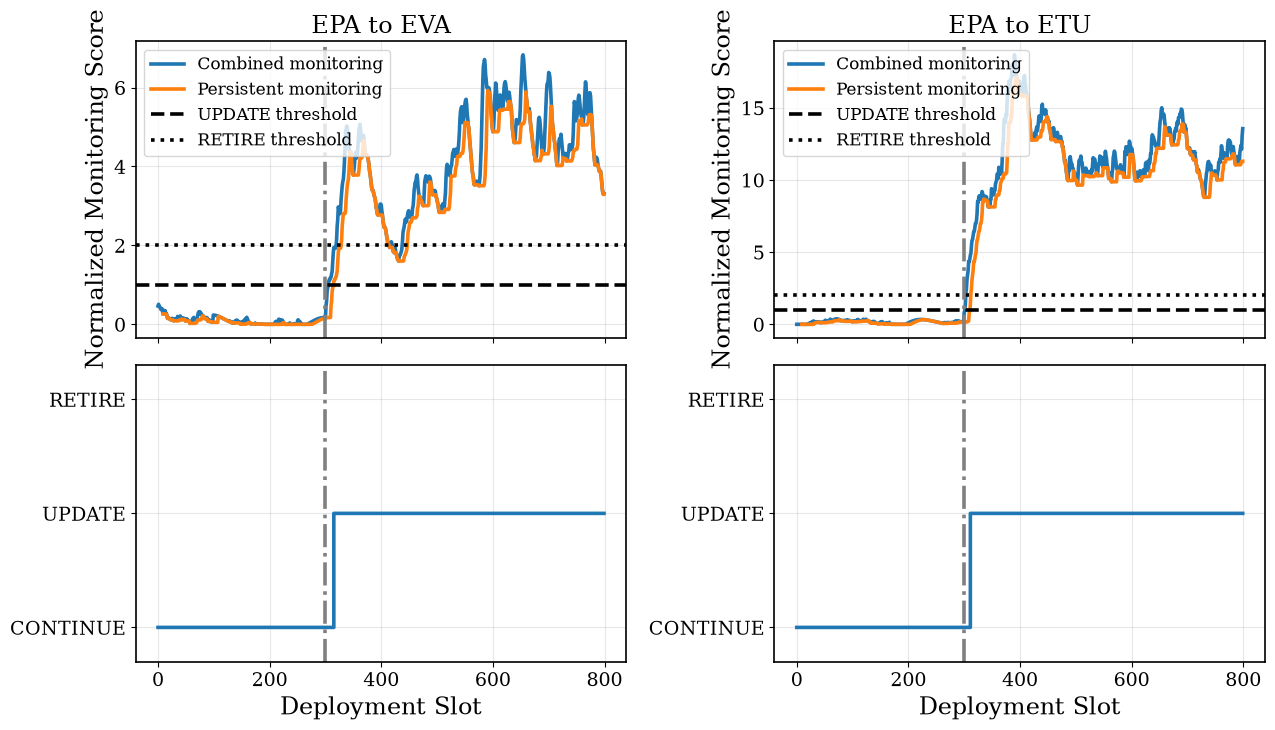


CELL 11 — FINAL SUMMARY
Runtime: 19.63 seconds
Calibration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_combined_calibration.csv
Evaluation: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_combined_evaluation.csv
Checkpoint: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/cdt_combined_detector.pt
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_combined_lifecycle_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_combined_lifecycle_IEEE.png

CELL 11 COMBINED CDT MONITORING: PASS


In [ ]:

# ============================================================
# CELL 11 — COMBINED CDT LIFECYCLE MONITORING
# IEEE WCL Reviewer Revision | NVIDIA RTX 5090 CUDA
#
# Monitoring:
#   1. VAE-only
#   2. Lower-tail Layer-3 activation-only
#   3. Combined VAE + activation CDT
#
# Calibration:
#   Joint event-level calibration on EPA -> EPA controls
#
# Evaluation:
#   EPA -> EPA, EPA -> EVA, EPA -> ETU
#
# Outputs:
#   - False-event rates
#   - Detection probabilities
#   - Mean detection delays
#   - UPDATE / RETIRE decisions
#   - IEEE-style monitoring figure
#
# No model retraining or actual lifecycle adaptation.
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
CDT_SNR_DB = 12.0

CDT_WINDOW = 100
CDT_ALPHA = 0.05
CDT_HOLD = 10

CDT_N_PRE = 300
CDT_N_POST = 500
CDT_N_TOTAL = CDT_N_PRE + CDT_N_POST
CDT_ONSET = CDT_N_PRE

CDT_N_CAL = 500
CDT_N_EVAL = 200

CDT_TARGET_FAR = 0.01
CDT_SEVERE_FACTOR = 2.0

CDT_MODES = [
    "VAE_only",
    "Activation_only",
    "Combined_CDT"
]

CDT_SCENARIOS = {
    "EPA_to_EPA": ("EPA", "EPA"),
    "EPA_to_EVA": ("EPA", "EVA"),
    "EPA_to_ETU": ("EPA", "ETU"),
}

CDT_SEED = SEED + 1400

torch.manual_seed(CDT_SEED)
torch.cuda.manual_seed_all(CDT_SEED)
np.random.seed(CDT_SEED)

model.eval()
vae_model.eval()

print("=" * 72)
print("CELL 11 — COMBINED CDT LIFECYCLE MONITORING")
print("=" * 72)
print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", CDT_SNR_DB, "dB")
print("Activation window:", CDT_WINDOW)
print("EWMA alpha:", CDT_ALPHA)
print("Hold-off:", CDT_HOLD)
print("Calibration trajectories:", CDT_N_CAL)
print("Evaluation trajectories:", CDT_N_EVAL)
print("Target event FAR:", CDT_TARGET_FAR)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify dependencies
# ------------------------------------------------------------
required_names = [
    "cp_generate_channel",
    "cp_get_activations",
    "cp_rolling_stats",
    "DIR_REFERENCE",
    "DIR_CENTER",
    "vae_model",
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing definitions: {missing}. "
        "Run Cells 1-10D first."
    )

# ------------------------------------------------------------
# 3. Generate correlated deployment trajectories
# ------------------------------------------------------------
@torch.no_grad()
def cdt_generate_sequence(before, after):

    H_pre = cp_generate_channel(
        before,
        CDT_N_PRE
    )

    H_post = cp_generate_channel(
        after,
        CDT_N_POST
    )

    return torch.cat(
        [H_pre, H_post],
        dim=0
    )

# ------------------------------------------------------------
# 4. Extract VAE and activation scores
# ------------------------------------------------------------
@torch.no_grad()
def cdt_extract_scores(H):

    _, Y, _ = simulate_ofdm(
        H,
        CDT_SNR_DB
    )

    y_p, h_p, _ = extract_pilot_observations(Y)

    # VAE reconstruction score
    vae_raw = (
        vae_model.reconstruction_error(y_p)
        .detach().cpu().numpy()
    )

    # Layer-3 activation score
    _, activations = model(
        h_p,
        return_activations=True
    )

    layer3 = activations[2].detach().cpu()

    mu, sigma = cp_rolling_stats(
        layer3,
        CDT_WINDOW
    )

    ref_mu = DIR_REFERENCE["mean"].to(
        torch.float64
    )

    ref_std = DIR_REFERENCE["std"].to(
        torch.float64
    )

    denominator = (
        torch.linalg.vector_norm(ref_std)
        + 1e-8
    )

    mean_drift = (
        torch.linalg.vector_norm(
            mu - ref_mu,
            dim=1
        ) / denominator
    )

    std_drift = (
        torch.linalg.vector_norm(
            sigma - ref_std,
            dim=1
        ) / denominator
    )

    activation_raw = np.full(
        len(H),
        np.nan,
        dtype=np.float64
    )

    activation_raw[CDT_WINDOW - 1:] = (
        mean_drift + std_drift
    ).numpy()

    return vae_raw, activation_raw

# ------------------------------------------------------------
# 5. EWMA
# ------------------------------------------------------------
def cdt_ewma(values):

    output = np.full(
        len(values),
        np.nan,
        dtype=np.float64
    )

    previous = None

    for t, value in enumerate(values):

        if not np.isfinite(value):
            continue

        if previous is None:
            previous = float(value)
        else:
            previous = (
                CDT_ALPHA * float(value)
                + (1.0 - CDT_ALPHA) * previous
            )

        output[t] = previous

    return output

# ------------------------------------------------------------
# 6. Lower-tail activation anomaly
# ------------------------------------------------------------
def cdt_activation_anomaly(activation_smooth):

    anomaly = np.full_like(
        activation_smooth,
        np.nan,
        dtype=np.float64
    )

    valid = np.isfinite(activation_smooth)

    anomaly[valid] = np.maximum(
        DIR_CENTER - activation_smooth[valid],
        0.0
    )

    return anomaly

# ------------------------------------------------------------
# 7. Generate calibration trajectories
# ------------------------------------------------------------
print("\nGenerating joint EPA->EPA calibration trajectories...")

CAL_VAE = []
CAL_ACT = []

for trial in range(CDT_N_CAL):

    H = cdt_generate_sequence(
        "EPA",
        "EPA"
    )

    vae_raw, act_raw = cdt_extract_scores(H)

    vae_smooth = cdt_ewma(vae_raw)
    act_smooth = cdt_ewma(act_raw)

    act_anomaly = cdt_activation_anomaly(
        act_smooth
    )

    CAL_VAE.append(vae_smooth)
    CAL_ACT.append(act_anomaly)

    if (trial + 1) % 100 == 0:
        print(
            f"Calibration {trial + 1}/{CDT_N_CAL}"
        )

# ------------------------------------------------------------
# 8. Normalize monitoring scores
# ------------------------------------------------------------
# Use independent EPA calibration distributions.

vae_center = float(
    np.median(
        np.concatenate(CAL_VAE)
    )
)

vae_scale = float(
    np.std(
        np.concatenate(CAL_VAE)
    )
)

act_valid = np.concatenate([
    a[np.isfinite(a)]
    for a in CAL_ACT
])

act_scale = float(
    np.std(act_valid)
)

vae_scale = max(vae_scale, 1e-8)
act_scale = max(act_scale, 1e-8)

def cdt_normalize(vae_smooth, act_anomaly):

    v = np.maximum(
        (vae_smooth - vae_center) / vae_scale,
        0.0
    )

    a = act_anomaly / act_scale

    return v, a

# ------------------------------------------------------------
# 9. Persistence statistic
# ------------------------------------------------------------
def cdt_persistence(values, hold=CDT_HOLD):

    persistence = np.full_like(
        values,
        np.nan,
        dtype=np.float64
    )

    for t in range(hold - 1, len(values)):

        segment = values[
            t - hold + 1:t + 1
        ]

        if np.isfinite(segment).all():
            persistence[t] = np.min(segment)

    return persistence

# ------------------------------------------------------------
# 10. Combined monitoring score
# ------------------------------------------------------------
def cdt_combined_score(v, a, mode):

    if mode == "VAE_only":
        return v

    if mode == "Activation_only":
        return a

    if mode == "Combined_CDT":
        # OR-type combination after normalization
        return np.fmax(v, a)

    raise ValueError(mode)

# ------------------------------------------------------------
# 11. Event-level calibration
# ------------------------------------------------------------
CDT_THRESHOLDS = {}

calibration_rows = []

for mode in CDT_MODES:

    maxima = []

    for v_raw, a_raw in zip(CAL_VAE, CAL_ACT):

        v, a = cdt_normalize(
            v_raw,
            a_raw
        )

        combined = cdt_combined_score(
            v, a, mode
        )

        persistence = cdt_persistence(
            combined
        )

        maxima.append(
            np.nanmax(persistence)
        )

    maxima = np.asarray(
        maxima,
        dtype=np.float64
    )

    threshold = float(
        np.quantile(
            maxima,
            1.0 - CDT_TARGET_FAR
        )
    )

    CDT_THRESHOLDS[mode] = threshold

    calibration_far = float(
        np.mean(maxima > threshold)
    )

    calibration_rows.append({
        "Mode": mode,
        "Threshold": threshold,
        "Calibration_FAR": calibration_far
    })

    print(
        f"{mode:16s} | "
        f"Threshold={threshold:.4f} | "
        f"Calibration FAR={100*calibration_far:.2f}%"
    )

# ------------------------------------------------------------
# 12. Lifecycle decision logic
# ------------------------------------------------------------
def cdt_first_action(
    persistence,
    threshold,
    severe_factor=CDT_SEVERE_FACTOR
):
    """
    CONTINUE until first action.

    UPDATE:
        persistence >= threshold

    RETIRE:
        persistence >= severe_factor * threshold

    No repeated lifecycle events.
    """

    for t, value in enumerate(persistence):

        if not np.isfinite(value):
            continue

        if value >= severe_factor * threshold:
            return t, "RETIRE"

        if value >= threshold:
            return t, "UPDATE"

    return None, "NONE"

# ------------------------------------------------------------
# 13. Independent evaluation
# ------------------------------------------------------------
print("\nEvaluating independent deployment trajectories...")

CDT_RESULTS = {
    scenario: {
        mode: []
        for mode in CDT_MODES
    }
    for scenario in CDT_SCENARIOS
}

evaluation_rows = []

for scenario, (before, after) in CDT_SCENARIOS.items():

    for trial in range(CDT_N_EVAL):

        H = cdt_generate_sequence(
            before,
            after
        )

        vae_raw, act_raw = cdt_extract_scores(H)

        vae_smooth = cdt_ewma(vae_raw)
        act_smooth = cdt_ewma(act_raw)

        act_anomaly = cdt_activation_anomaly(
            act_smooth
        )

        v, a = cdt_normalize(
            vae_smooth,
            act_anomaly
        )

        for mode in CDT_MODES:

            combined = cdt_combined_score(
                v, a, mode
            )

            persistence = cdt_persistence(
                combined
            )

            event_slot, action = cdt_first_action(
                persistence,
                CDT_THRESHOLDS[mode]
            )

            CDT_RESULTS[scenario][mode].append({
                "event_slot": event_slot,
                "action": action,
                "score": combined,
                "persistence": persistence,
            })

        if (trial + 1) % 50 == 0:
            print(
                f"{scenario}: {trial + 1}/{CDT_N_EVAL}"
            )

    for mode in CDT_MODES:

        trials = CDT_RESULTS[scenario][mode]

        false_events = sum(
            item["event_slot"] is not None
            and (
                scenario == "EPA_to_EPA"
                or item["event_slot"] < CDT_ONSET
            )
            for item in trials
        )

        if scenario == "EPA_to_EPA":

            detection_rate = np.nan
            mean_delay = np.nan
            retire_rate = np.nan

        else:

            valid = [
                item
                for item in trials
                if item["event_slot"] is not None
                and item["event_slot"] >= CDT_ONSET
            ]

            detection_rate = (
                len(valid) / CDT_N_EVAL
            )

            mean_delay = (
                float(np.mean([
                    item["event_slot"] - CDT_ONSET
                    for item in valid
                ]))
                if valid
                else np.nan
            )

            retire_rate = (
                sum(
                    item["action"] == "RETIRE"
                    for item in valid
                ) / CDT_N_EVAL
            )

        evaluation_rows.append({
            "Scenario": scenario,
            "Mode": mode,
            "False_Event_Rate": false_events / CDT_N_EVAL,
            "Detection_Rate": detection_rate,
            "Mean_Delay": mean_delay,
            "Retire_Rate": retire_rate,
        })

# ------------------------------------------------------------
# 14. Results table
# ------------------------------------------------------------
calibration_df = pd.DataFrame(
    calibration_rows
)

evaluation_df = pd.DataFrame(
    evaluation_rows
)

print("\n" + "=" * 72)
print("CELL 11 — CDT DETECTION AND LIFECYCLE RESULTS")
print("=" * 72)

print(
    evaluation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 15. IEEE-style comparison figure
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.6,
    "lines.markersize": 9,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 7.5),
    sharex=True
)

for col, scenario in enumerate(
    ["EPA_to_EVA", "EPA_to_ETU"]
):

    # Choose first independent evaluation trial for
    # visualization. This is illustrative, not averaged.
    trial = CDT_RESULTS[scenario]["Combined_CDT"][0]

    slots = np.arange(CDT_N_TOTAL)

    score = trial["score"]
    persistence = trial["persistence"]

    threshold = CDT_THRESHOLDS["Combined_CDT"]

    ax = axes[0, col]

    ax.plot(
        slots,
        score / threshold,
        label="Combined monitoring"
    )

    ax.plot(
        slots,
        persistence / threshold,
        label="Persistent monitoring"
    )

    ax.axhline(
        1.0,
        color="black",
        linestyle="--",
        label="UPDATE threshold"
    )

    ax.axhline(
        CDT_SEVERE_FACTOR,
        color="black",
        linestyle=":",
        label="RETIRE threshold"
    )

    ax.axvline(
        CDT_ONSET,
        color="gray",
        linestyle="-."
    )

    ax.set_title(
        scenario.replace("_", " ")
    )

    ax.set_ylabel(
        "Normalized Monitoring Score"
    )

    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left")

    ax2 = axes[1, col]

    action_states = np.zeros(
        CDT_N_TOTAL,
        dtype=int
    )

    if trial["event_slot"] is not None:

        state_value = (
            1 if trial["action"] == "UPDATE"
            else 2
        )

        action_states[
            trial["event_slot"]:
        ] = state_value

    ax2.step(
        slots,
        action_states,
        where="post"
    )

    ax2.axvline(
        CDT_ONSET,
        color="gray",
        linestyle="-."
    )

    ax2.set_yticks([0, 1, 2])
    ax2.set_yticklabels([
        "CONTINUE",
        "UPDATE",
        "RETIRE"
    ])

    ax2.set_ylim(-0.3, 2.3)
    ax2.set_xlabel("Deployment Slot")
    ax2.grid(True, alpha=0.3)

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "cdt_combined_lifecycle_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "cdt_combined_lifecycle_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 16. Save calibration and evaluation results
# ------------------------------------------------------------
calibration_path = (
    RESULTS_DIR /
    "cdt_combined_calibration.csv"
)

evaluation_path = (
    RESULTS_DIR /
    "cdt_combined_evaluation.csv"
)

calibration_df.to_csv(
    calibration_path,
    index=False
)

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

checkpoint_path = (
    CHECKPOINT_DIR /
    "cdt_combined_detector.pt"
)

torch.save(
    {
        "vae_center": vae_center,
        "vae_scale": vae_scale,
        "activation_center": DIR_CENTER,
        "activation_scale": act_scale,
        "thresholds": CDT_THRESHOLDS,
        "window": CDT_WINDOW,
        "alpha": CDT_ALPHA,
        "hold": CDT_HOLD,
        "severe_factor": CDT_SEVERE_FACTOR,
        "target_far": CDT_TARGET_FAR,
    },
    checkpoint_path
)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 11 — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Calibration:", calibration_path)
print("Evaluation:", evaluation_path)
print("Checkpoint:", checkpoint_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 11 COMBINED CDT MONITORING: PASS")


CELL 11A — HIERARCHICAL CDT CONTROLLER
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Activation window: 100
EWMA alpha: 0.05
Hold-off: 10
Confirmation timeout: 250
Calibration trajectories: 500
Evaluation trajectories: 200
Target event FAR: 0.01

Generating calibration trajectories...
Calibration 100/500
Calibration 200/500
Calibration 300/500
Calibration 400/500
Calibration 500/500
VAE_only        | VAE=7.4288 | ACT=4.7808 | FAR=1.00%
OR_fusion       | VAE=8.1717 | ACT=5.2588 | FAR=1.00%
Hierarchical    | VAE=5.9430 | ACT=3.8246 | FAR=0.20%

Evaluating independent trajectories...
EPA_to_EPA: 50/200
EPA_to_EPA: 100/200
EPA_to_EPA: 150/200
EPA_to_EPA: 200/200
EPA_to_EVA: 50/200
EPA_to_EVA: 100/200
EPA_to_EVA: 150/200
EPA_to_EVA: 200/200
EPA_to_ETU: 50/200
EPA_to_ETU: 100/200
EPA_to_ETU: 150/200
EPA_to_ETU: 200/200

CELL 11A — HIERARCHICAL CDT RESULTS
  Scenario       Policy  False_Event_Rate  Warning_Rate  Detection_Rate  Mean_Warning_Delay  Mean_Action_Delay  Retire_Rate
EPA_to_

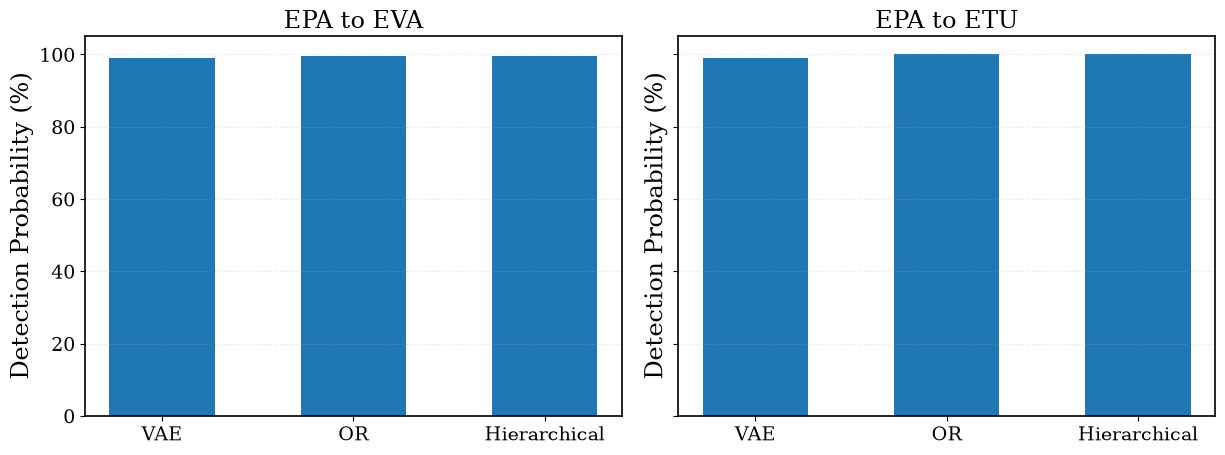


CELL 11A — FINAL SUMMARY
Runtime: 25.11 seconds
Calibration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_hierarchical_calibration.csv
Evaluation: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_hierarchical_evaluation.csv
Checkpoint: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/cdt_hierarchical_controller.pt
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_hierarchical_comparison_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_hierarchical_comparison_IEEE.png

CELL 11A HIERARCHICAL CDT: PASS


In [ ]:

# ============================================================
# CELL 11A — HIERARCHICAL CDT LIFECYCLE CONTROLLER
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Policies:
#   1. VAE-only
#   2. OR fusion
#   3. Hierarchical VAE -> Activation confirmation
#
# Evaluation:
#   - EPA -> EPA
#   - EPA -> EVA
#   - EPA -> ETU
#
# Metrics:
#   - False lifecycle-event rate
#   - Warning probability and delay
#   - Confirmed detection probability and delay
#   - UPDATE and RETIRE event frequencies
#
# No model adaptation is performed.
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

H_SNR_DB = 12.0
H_WINDOW = 100
H_ALPHA = 0.05
H_HOLD = 10

H_N_PRE = 300
H_N_POST = 500
H_N_TOTAL = H_N_PRE + H_N_POST
H_ONSET = H_N_PRE

H_N_CAL = 500
H_N_EVAL = 200

H_TARGET_FAR = 0.01
H_SEVERE_FACTOR = 2.0

# Maximum time allowed for activation confirmation
# after a VAE warning. This is a development parameter.
H_CONFIRM_TIMEOUT = 250

H_POLICIES = [
    "VAE_only",
    "OR_fusion",
    "Hierarchical"
]

H_SCENARIOS = {
    "EPA_to_EPA": ("EPA", "EPA"),
    "EPA_to_EVA": ("EPA", "EVA"),
    "EPA_to_ETU": ("EPA", "ETU"),
}

H_SEED = SEED + 1500

torch.manual_seed(H_SEED)
torch.cuda.manual_seed_all(H_SEED)
np.random.seed(H_SEED)

model.eval()
vae_model.eval()

print("=" * 72)
print("CELL 11A — HIERARCHICAL CDT CONTROLLER")
print("=" * 72)
print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", H_SNR_DB, "dB")
print("Activation window:", H_WINDOW)
print("EWMA alpha:", H_ALPHA)
print("Hold-off:", H_HOLD)
print("Confirmation timeout:", H_CONFIRM_TIMEOUT)
print("Calibration trajectories:", H_N_CAL)
print("Evaluation trajectories:", H_N_EVAL)
print("Target event FAR:", H_TARGET_FAR)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify previous cells
# ------------------------------------------------------------

required = [
    "cdt_generate_sequence",
    "cdt_extract_scores",
    "cdt_ewma",
    "cdt_activation_anomaly",
    "cdt_normalize",
    "cdt_persistence",
    "DIR_CENTER",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing definitions: {missing}. "
        "Run Cell 11 first."
    )

# ------------------------------------------------------------
# 3. Monitoring score preparation
# ------------------------------------------------------------

def h_prepare_scores(H):

    vae_raw, act_raw = cdt_extract_scores(H)

    vae_smooth = cdt_ewma(vae_raw)
    act_smooth = cdt_ewma(act_raw)

    act_anomaly = cdt_activation_anomaly(
        act_smooth
    )

    v, a = cdt_normalize(
        vae_smooth,
        act_anomaly
    )

    return v, a


# ------------------------------------------------------------
# 4. Persistence statistics
# ------------------------------------------------------------

def h_persistence_scores(v, a):

    return (
        cdt_persistence(v, H_HOLD),
        cdt_persistence(a, H_HOLD)
    )


# ------------------------------------------------------------
# 5. Causal hierarchical controller
# ------------------------------------------------------------

def h_run_controller(
    v_persistence,
    a_persistence,
    vae_threshold,
    activation_threshold,
    policy,
    severe_factor=H_SEVERE_FACTOR,
    confirm_timeout=H_CONFIRM_TIMEOUT
):
    """
    Returns:
        warning_slot
        action_slot
        action_type

    Hierarchical:
        VAE warning -> wait for activation confirmation.
        Severe VAE crossing can escalate to RETIRE.

    This is a decision-only state machine.
    """

    warning_slot = None
    action_slot = None
    action_type = "NONE"

    waiting_for_confirmation = False

    for t in range(len(v_persistence)):

        v = v_persistence[t]
        a = a_persistence[t]

        v_cross = (
            np.isfinite(v)
            and v >= vae_threshold
        )

        a_cross = (
            np.isfinite(a)
            and a >= activation_threshold
        )

        v_severe = (
            np.isfinite(v)
            and v >= severe_factor * vae_threshold
        )

        if policy == "VAE_only":

            if v_cross:
                warning_slot = t
                action_slot = t
                action_type = (
                    "RETIRE" if v_severe else "UPDATE"
                )
                break

        elif policy == "OR_fusion":

            if v_cross or a_cross:
                warning_slot = t
                action_slot = t
                action_type = (
                    "RETIRE" if v_severe else "UPDATE"
                )
                break

        elif policy == "Hierarchical":

            if not waiting_for_confirmation:

                if v_cross:
                    warning_slot = t
                    waiting_for_confirmation = True

            if waiting_for_confirmation:

                # Severe VAE evidence
                if v_severe:
                    action_slot = t
                    action_type = "RETIRE"
                    break

                # Activation confirmation
                if a_cross:
                    action_slot = t
                    action_type = "UPDATE"
                    break

                # Timeout: cancel pending warning
                if (
                    t - warning_slot >= confirm_timeout
                ):
                    waiting_for_confirmation = False
                    warning_slot = None

        else:
            raise ValueError(policy)

    return {
        "warning_slot": warning_slot,
        "action_slot": action_slot,
        "action_type": action_type
    }


# ------------------------------------------------------------
# 6. Generate matched EPA calibration trajectories
# ------------------------------------------------------------

print("\nGenerating calibration trajectories...")

H_CAL_SCORES = []

for trial in range(H_N_CAL):

    H = cdt_generate_sequence(
        "EPA", "EPA"
    )

    v, a = h_prepare_scores(H)

    v_p, a_p = h_persistence_scores(v, a)

    H_CAL_SCORES.append((v_p, a_p))

    if (trial + 1) % 100 == 0:
        print(
            f"Calibration {trial + 1}/{H_N_CAL}"
        )


# ------------------------------------------------------------
# 7. Calibrate policy thresholds
# ------------------------------------------------------------

# Base thresholds from trajectory-level persistence maxima.
# Joint calibration for each policy follows.

vae_maxima = np.asarray([
    np.nanmax(v)
    for v, a in H_CAL_SCORES
])

act_maxima = np.asarray([
    np.nanmax(a)
    for v, a in H_CAL_SCORES
])

base_vae_threshold = float(
    np.quantile(
        vae_maxima,
        1.0 - H_TARGET_FAR
    )
)

base_act_threshold = float(
    np.quantile(
        act_maxima,
        1.0 - H_TARGET_FAR
    )
)

# Candidate threshold multipliers
H_SCALES = np.linspace(0.8, 2.0, 49)

H_THRESHOLDS = {}
calibration_rows = []

for policy in H_POLICIES:

    selected = None

    for scale in H_SCALES:

        tau_v = base_vae_threshold * scale
        tau_a = base_act_threshold * scale

        false_events = 0

        for v_p, a_p in H_CAL_SCORES:

            result = h_run_controller(
                v_p,
                a_p,
                tau_v,
                tau_a,
                policy
            )

            if result["action_slot"] is not None:
                false_events += 1

        far = false_events / H_N_CAL

        if far <= H_TARGET_FAR:
            selected = (tau_v, tau_a, far)
            break

    if selected is None:
        raise RuntimeError(
            f"No calibrated threshold found for {policy}. "
            "Expand H_SCALES or review the null distribution."
        )

    H_THRESHOLDS[policy] = {
        "vae": selected[0],
        "activation": selected[1]
    }

    calibration_rows.append({
        "Policy": policy,
        "VAE_Threshold": selected[0],
        "Activation_Threshold": selected[1],
        "Calibration_FAR": selected[2]
    })

    print(
        f"{policy:15s} | "
        f"VAE={selected[0]:.4f} | "
        f"ACT={selected[1]:.4f} | "
        f"FAR={100*selected[2]:.2f}%"
    )


# ------------------------------------------------------------
# 8. Independent evaluation
# ------------------------------------------------------------

print("\nEvaluating independent trajectories...")

H_RESULTS = {
    scenario: {
        policy: []
        for policy in H_POLICIES
    }
    for scenario in H_SCENARIOS
}

evaluation_rows = []

for scenario, (before, after) in H_SCENARIOS.items():

    for trial in range(H_N_EVAL):

        H = cdt_generate_sequence(
            before, after
        )

        v, a = h_prepare_scores(H)

        v_p, a_p = h_persistence_scores(v, a)

        for policy in H_POLICIES:

            thresholds = H_THRESHOLDS[policy]

            result = h_run_controller(
                v_p,
                a_p,
                thresholds["vae"],
                thresholds["activation"],
                policy
            )

            H_RESULTS[scenario][policy].append(
                result
            )

        if (trial + 1) % 50 == 0:
            print(
                f"{scenario}: {trial + 1}/{H_N_EVAL}"
            )

    for policy in H_POLICIES:

        trials = H_RESULTS[scenario][policy]

        false_actions = sum(
            item["action_slot"] is not None
            and (
                scenario == "EPA_to_EPA"
                or item["action_slot"] < H_ONSET
            )
            for item in trials
        )

        if scenario == "EPA_to_EPA":

            warning_rate = np.nan
            detection_rate = np.nan
            mean_warning_delay = np.nan
            mean_action_delay = np.nan
            retire_rate = np.nan

        else:

            valid_warnings = [
                item["warning_slot"]
                for item in trials
                if item["warning_slot"] is not None
                and item["warning_slot"] >= H_ONSET
            ]

            valid_actions = [
                item
                for item in trials
                if item["action_slot"] is not None
                and item["action_slot"] >= H_ONSET
            ]

            warning_rate = (
                len(valid_warnings) / H_N_EVAL
            )

            detection_rate = (
                len(valid_actions) / H_N_EVAL
            )

            mean_warning_delay = (
                float(np.mean([
                    t - H_ONSET
                    for t in valid_warnings
                ]))
                if valid_warnings
                else np.nan
            )

            mean_action_delay = (
                float(np.mean([
                    item["action_slot"] - H_ONSET
                    for item in valid_actions
                ]))
                if valid_actions
                else np.nan
            )

            retire_rate = (
                sum(
                    item["action_type"] == "RETIRE"
                    for item in valid_actions
                ) / H_N_EVAL
            )

        evaluation_rows.append({
            "Scenario": scenario,
            "Policy": policy,
            "False_Event_Rate": (
                false_actions / H_N_EVAL
            ),
            "Warning_Rate": warning_rate,
            "Detection_Rate": detection_rate,
            "Mean_Warning_Delay": mean_warning_delay,
            "Mean_Action_Delay": mean_action_delay,
            "Retire_Rate": retire_rate,
        })


# ------------------------------------------------------------
# 9. Results
# ------------------------------------------------------------

calibration_df = pd.DataFrame(
    calibration_rows
)

evaluation_df = pd.DataFrame(
    evaluation_rows
)

print("\n" + "=" * 72)
print("CELL 11A — HIERARCHICAL CDT RESULTS")
print("=" * 72)

print(
    evaluation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# 10. IEEE-style comparison figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.5,
    "lines.markersize": 10,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 4.8),
    sharey=True
)

for ax, scenario in zip(
    axes,
    ["EPA_to_EVA", "EPA_to_ETU"]
):

    subset = evaluation_df[
        evaluation_df["Scenario"] == scenario
    ]

    labels = [
        "VAE",
        "OR",
        "Hierarchical"
    ]

    rates = [
        100 * subset[
            subset["Policy"] == policy
        ]["Detection_Rate"].iloc[0]
        for policy in H_POLICIES
    ]

    ax.bar(
        labels,
        rates,
        width=0.55
    )

    ax.set_title(
        scenario.replace("_", " ")
    )

    ax.set_ylim(0, 105)
    ax.set_ylabel(
        "Detection Probability (%)"
    )

    ax.grid(
        True,
        axis="y",
        linestyle=":",
        alpha=0.4
    )

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "cdt_hierarchical_comparison_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "cdt_hierarchical_comparison_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 11. Save results
# ------------------------------------------------------------

calibration_path = (
    RESULTS_DIR /
    "cdt_hierarchical_calibration.csv"
)

evaluation_path = (
    RESULTS_DIR /
    "cdt_hierarchical_evaluation.csv"
)

calibration_df.to_csv(
    calibration_path,
    index=False
)

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

checkpoint_path = (
    CHECKPOINT_DIR /
    "cdt_hierarchical_controller.pt"
)

torch.save(
    {
        "thresholds": H_THRESHOLDS,
        "window": H_WINDOW,
        "alpha": H_ALPHA,
        "hold": H_HOLD,
        "confirmation_timeout": H_CONFIRM_TIMEOUT,
        "severe_factor": H_SEVERE_FACTOR,
        "target_far": H_TARGET_FAR,
    },
    checkpoint_path
)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 11A — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Calibration:", calibration_path)
print("Evaluation:", evaluation_path)
print("Checkpoint:", checkpoint_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 11A HIERARCHICAL CDT: PASS")


In [ ]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 92.7 kB/s  0:02:10m0:00:04:00:09
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


CELL 11B — CDT CONFIRMATION AND SEVERITY ANALYSIS
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Evaluation trials per scenario: 300
Confirmation timeout: 250
Severe factor: 2.0

[FIXED CALIBRATION]
VAE threshold: 5.943041891940837
Activation threshold: 3.824609004952361

Generating independent evaluation trajectories...

Scenario: EPA_to_EPA
  Completed 50/300
  Completed 100/300
  Completed 150/300
  Completed 200/300
  Completed 250/300
  Completed 300/300

Scenario: EPA_to_EVA
  Completed 50/300
  Completed 100/300
  Completed 150/300
  Completed 200/300
  Completed 250/300
  Completed 300/300

Scenario: EPA_to_ETU
  Completed 50/300
  Completed 100/300
  Completed 150/300
  Completed 200/300
  Completed 250/300
  Completed 300/300

CELL 11B — CONFIRMATION AND SEVERITY RESULTS
  Scenario                Policy  False_Event_Rate  FAR_CI_Low  FAR_CI_High  Warning_Rate  Detection_Rate  Confirmation_Rate  Unconfirmed_Severe_Rate  Update_Rate  Retire_Rate  Mean_Warning_Delay  Mean_

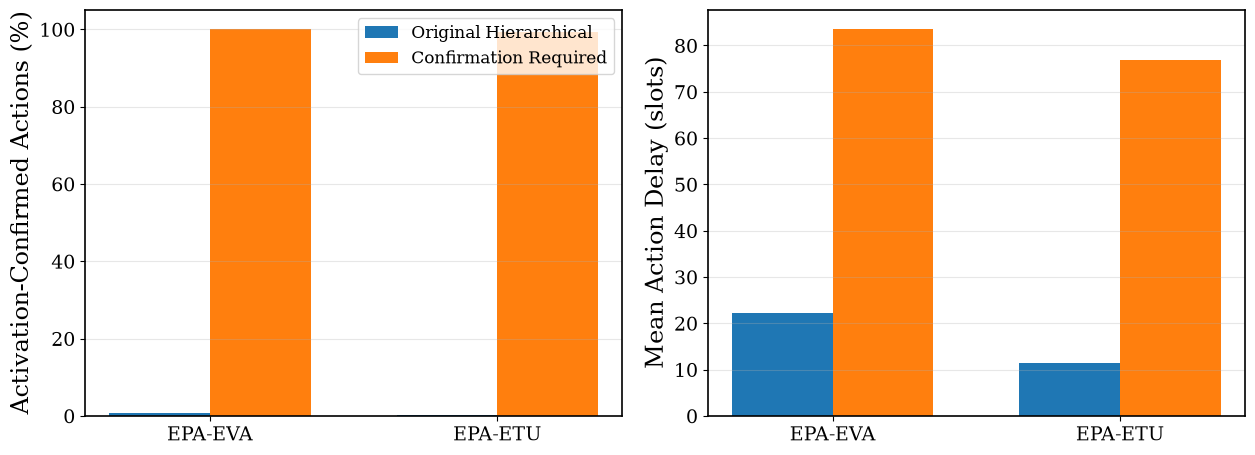


CELL 11B — FINAL SUMMARY
Runtime: 14.15 seconds
Summary CSV: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_confirmation_severity_summary.csv
Event log: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_confirmation_event_log.csv
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_confirmation_severity_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_confirmation_severity_IEEE.png

CELL 11B CONFIRMATION ANALYSIS: PASS


In [ ]:

# ============================================================
# CELL 11B — HIERARCHICAL CDT CONFIRMATION & SEVERITY ANALYSIS
# IEEE WCL Reviewer Revision | NVIDIA RTX 5090 CUDA
#
# Compares:
#   A. Original hierarchical controller (Cell 11A)
#   B. Confirmation-required controller
#
# Measures:
#   - VAE warning rate and delay
#   - Activation confirmation rate and delay
#   - Severe VAE escalation before confirmation
#   - UPDATE / RETIRE frequencies
#   - False lifecycle-event probability
#   - Detection probability and action delay
#
# IMPORTANT:
# No estimator fine-tuning or replacement is performed.
# RETIRE remains a provisional severity decision.
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from statsmodels.stats.proportion import proportion_confint

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

B_SNR_DB = 12.0

B_N_PRE = 300
B_N_POST = 500
B_N_TOTAL = B_N_PRE + B_N_POST
B_ONSET = B_N_PRE

B_N_EVAL = 300

B_CONFIRM_TIMEOUT = H_CONFIRM_TIMEOUT
B_SEVERE_FACTOR = H_SEVERE_FACTOR

B_POLICIES = [
    "Original_Hierarchical",
    "Confirmation_Required"
]

B_SCENARIOS = {
    "EPA_to_EPA": ("EPA", "EPA"),
    "EPA_to_EVA": ("EPA", "EVA"),
    "EPA_to_ETU": ("EPA", "ETU"),
}

B_SEED = SEED + 1600

torch.manual_seed(B_SEED)
torch.cuda.manual_seed_all(B_SEED)
np.random.seed(B_SEED)

model.eval()
vae_model.eval()

print("=" * 72)
print("CELL 11B — CDT CONFIRMATION AND SEVERITY ANALYSIS")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", B_SNR_DB, "dB")
print("Evaluation trials per scenario:", B_N_EVAL)
print("Confirmation timeout:", B_CONFIRM_TIMEOUT)
print("Severe factor:", B_SEVERE_FACTOR)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify Cell 11A dependencies
# ------------------------------------------------------------

required_names = [
    "H_THRESHOLDS",
    "h_prepare_scores",
    "h_persistence_scores",
    "cdt_generate_sequence",
    "h_run_controller",
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing definitions: {missing}. "
        "Run Cell 11A first."
    )

# Use the original hierarchical thresholds for both
# policies to isolate the impact of decision logic.
B_THRESHOLDS = H_THRESHOLDS["Hierarchical"]

B_TAU_V = float(B_THRESHOLDS["vae"])
B_TAU_A = float(B_THRESHOLDS["activation"])

print("\n[FIXED CALIBRATION]")
print("VAE threshold:", B_TAU_V)
print("Activation threshold:", B_TAU_A)

# ------------------------------------------------------------
# 3. Detailed controller with trigger attribution
# ------------------------------------------------------------

def b_run_controller(
    v_p,
    a_p,
    policy,
    tau_v=B_TAU_V,
    tau_a=B_TAU_A,
    severe_factor=B_SEVERE_FACTOR,
    timeout=B_CONFIRM_TIMEOUT
):
    """
    Detailed causal state machine.

    Warning:
        VAE persistence crosses threshold.

    Confirmation:
        Activation persistence crosses threshold
        after warning.

    Original hierarchical:
        Severe VAE can trigger RETIRE immediately.

    Confirmation-required:
        Activation confirmation is required before
        UPDATE or RETIRE.

    Returns detailed event timing and reason.
    """

    warning_slot = None
    confirmation_slot = None
    action_slot = None

    action_type = "NONE"
    action_reason = "NONE"

    waiting = False

    for t in range(len(v_p)):

        v = v_p[t]
        a = a_p[t]

        v_cross = (
            np.isfinite(v)
            and v >= tau_v
        )

        a_cross = (
            np.isfinite(a)
            and a >= tau_a
        )

        v_severe = (
            np.isfinite(v)
            and v >= severe_factor * tau_v
        )

        # ----------------------------------------------------
        # VAE warning
        # ----------------------------------------------------
        if not waiting and v_cross:

            warning_slot = t
            waiting = True

        if not waiting:
            continue

        # ----------------------------------------------------
        # Record activation confirmation
        # ----------------------------------------------------
        if a_cross and confirmation_slot is None:
            confirmation_slot = t

        # ----------------------------------------------------
        # Policy A: original hierarchical
        # ----------------------------------------------------
        if policy == "Original_Hierarchical":

            if v_severe:

                action_slot = t
                action_type = "RETIRE"
                action_reason = "VAE_Severe"
                break

            if a_cross:

                action_slot = t
                action_type = "UPDATE"
                action_reason = "Activation_Confirmed"
                break

        # ----------------------------------------------------
        # Policy B: confirmation required
        # ----------------------------------------------------
        elif policy == "Confirmation_Required":

            if a_cross:

                action_slot = t

                if v_severe:
                    action_type = "RETIRE"
                    action_reason = "Confirmed_Severe"
                else:
                    action_type = "UPDATE"
                    action_reason = "Activation_Confirmed"

                break

        else:
            raise ValueError(policy)

        # ----------------------------------------------------
        # Timeout and reset
        # ----------------------------------------------------
        if t - warning_slot >= timeout:

            waiting = False
            warning_slot = None
            confirmation_slot = None

    return {
        "warning_slot": warning_slot,
        "confirmation_slot": confirmation_slot,
        "action_slot": action_slot,
        "action_type": action_type,
        "action_reason": action_reason
    }


# ------------------------------------------------------------
# 4. Independent evaluation trajectories
# ------------------------------------------------------------

print("\nGenerating independent evaluation trajectories...")

B_RESULTS = {
    scenario: {
        policy: []
        for policy in B_POLICIES
    }
    for scenario in B_SCENARIOS
}

for scenario, (before, after) in B_SCENARIOS.items():

    print(f"\nScenario: {scenario}")

    for trial in range(B_N_EVAL):

        H = cdt_generate_sequence(
            before,
            after
        )

        v, a = h_prepare_scores(H)

        v_p, a_p = h_persistence_scores(v, a)

        for policy in B_POLICIES:

            result = b_run_controller(
                v_p,
                a_p,
                policy
            )

            result["trial"] = trial

            B_RESULTS[scenario][policy].append(
                result
            )

        if (trial + 1) % 50 == 0:
            print(
                f"  Completed {trial + 1}/{B_N_EVAL}"
            )


# ------------------------------------------------------------
# 5. Statistical summary
# ------------------------------------------------------------

def b_wilson_interval(successes, total):

    low, high = proportion_confint(
        successes,
        total,
        alpha=0.05,
        method="wilson"
    )

    return float(low), float(high)


summary_rows = []

for scenario in B_SCENARIOS:

    for policy in B_POLICIES:

        trials = B_RESULTS[scenario][policy]

        n = len(trials)

        # Any action under matched EPA is false.
        # Under shifted scenarios, pre-onset actions
        # are false events.
        false_events = sum(
            item["action_slot"] is not None
            and (
                scenario == "EPA_to_EPA"
                or item["action_slot"] < B_ONSET
            )
            for item in trials
        )

        # Post-onset confirmed lifecycle actions
        valid_actions = [
            item for item in trials
            if item["action_slot"] is not None
            and item["action_slot"] >= B_ONSET
            and scenario != "EPA_to_EPA"
        ]

        # Warnings that occur after drift onset
        valid_warnings = [
            item for item in trials
            if item["warning_slot"] is not None
            and item["warning_slot"] >= B_ONSET
            and scenario != "EPA_to_EPA"
        ]

        # Activation confirmation supporting an action
        confirmed_actions = [
            item for item in valid_actions
            if item["confirmation_slot"] is not None
            and item["confirmation_slot"] <= item["action_slot"]
        ]

        # Severe VAE escalation without confirmation
        severe_unconfirmed = [
            item for item in valid_actions
            if item["action_reason"] == "VAE_Severe"
            and (
                item["confirmation_slot"] is None
                or item["confirmation_slot"] > item["action_slot"]
            )
        ]

        update_actions = sum(
            item["action_type"] == "UPDATE"
            for item in valid_actions
        )

        retire_actions = sum(
            item["action_type"] == "RETIRE"
            for item in valid_actions
        )

        false_rate = false_events / n

        detection_rate = (
            len(valid_actions) / n
            if scenario != "EPA_to_EPA"
            else np.nan
        )

        warning_rate = (
            len(valid_warnings) / n
            if scenario != "EPA_to_EPA"
            else np.nan
        )

        confirmation_rate = (
            len(confirmed_actions) / n
            if scenario != "EPA_to_EPA"
            else np.nan
        )

        mean_warning_delay = (
            np.mean([
                item["warning_slot"] - B_ONSET
                for item in valid_warnings
            ])
            if valid_warnings else np.nan
        )

        mean_action_delay = (
            np.mean([
                item["action_slot"] - B_ONSET
                for item in valid_actions
            ])
            if valid_actions else np.nan
        )

        far_low, far_high = b_wilson_interval(
            false_events,
            n
        )

        summary_rows.append({
            "Scenario": scenario,
            "Policy": policy,
            "False_Event_Rate": false_rate,
            "FAR_CI_Low": far_low,
            "FAR_CI_High": far_high,
            "Warning_Rate": warning_rate,
            "Detection_Rate": detection_rate,
            "Confirmation_Rate": confirmation_rate,
            "Unconfirmed_Severe_Rate": (
                len(severe_unconfirmed) / n
            ),
            "Update_Rate": update_actions / n,
            "Retire_Rate": retire_actions / n,
            "Mean_Warning_Delay": mean_warning_delay,
            "Mean_Action_Delay": mean_action_delay,
        })


B_SUMMARY_DF = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 72)
print("CELL 11B — CONFIRMATION AND SEVERITY RESULTS")
print("=" * 72)

print(
    B_SUMMARY_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# 6. IEEE-style comparison figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.5,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.8, 4.8)
)

plot_scenarios = [
    "EPA_to_EVA",
    "EPA_to_ETU"
]

# Panel (a): confirmation vs severe escalation
ax = axes[0]

x = np.arange(
    len(plot_scenarios)
)

width = 0.35

for idx, policy in enumerate(B_POLICIES):

    subset = B_SUMMARY_DF[
        (B_SUMMARY_DF["Policy"] == policy)
        & B_SUMMARY_DF["Scenario"].isin(
            plot_scenarios
        )
    ].set_index("Scenario").loc[
        plot_scenarios
    ]

    offset = (
        idx - 0.5
    ) * width

    ax.bar(
        x + offset,
        100 * subset["Confirmation_Rate"],
        width,
        label=policy.replace("_", " ")
    )

ax.set_xticks(x)
ax.set_xticklabels(
    ["EPA-EVA", "EPA-ETU"]
)

ax.set_ylabel(
    "Activation-Confirmed Actions (%)"
)

ax.set_ylim(0, 105)
ax.grid(True, axis="y", alpha=0.3)
ax.legend()

# Panel (b): mean action delay
ax = axes[1]

for idx, policy in enumerate(B_POLICIES):

    subset = B_SUMMARY_DF[
        (B_SUMMARY_DF["Policy"] == policy)
        & B_SUMMARY_DF["Scenario"].isin(
            plot_scenarios
        )
    ].set_index("Scenario").loc[
        plot_scenarios
    ]

    offset = (
        idx - 0.5
    ) * width

    ax.bar(
        x + offset,
        subset["Mean_Action_Delay"],
        width,
        label=policy.replace("_", " ")
    )

ax.set_xticks(x)
ax.set_xticklabels(
    ["EPA-EVA", "EPA-ETU"]
)

ax.set_ylabel(
    "Mean Action Delay (slots)"
)

ax.grid(True, axis="y", alpha=0.3)

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "cdt_confirmation_severity_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "cdt_confirmation_severity_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Save results
# ------------------------------------------------------------

summary_path = (
    RESULTS_DIR /
    "cdt_confirmation_severity_summary.csv"
)

B_SUMMARY_DF.to_csv(
    summary_path,
    index=False
)

# Save detailed event log
event_rows = []

for scenario in B_SCENARIOS:

    for policy in B_POLICIES:

        for item in B_RESULTS[scenario][policy]:

            event_rows.append({
                "Scenario": scenario,
                "Policy": policy,
                **item
            })

event_df = pd.DataFrame(
    event_rows
)

event_path = (
    RESULTS_DIR /
    "cdt_confirmation_event_log.csv"
)

event_df.to_csv(
    event_path,
    index=False
)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 11B — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Summary CSV:", summary_path)
print("Event log:", event_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 11B CONFIRMATION ANALYSIS: PASS")


CELL 12 — DATA-AIDED GROUND-TRUTH-FREE UPDATE
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
UPDATE observations: 100
Training observations: 80
Validation observations: 20
Epochs: 30
Learning rate: 0.0001
Updated layer: fc4
Ideal correct-decoding assumption: YES

[RESOURCE ELEMENTS]
Total REs: 1008
Pilot REs: 24
Data REs: 984

Evaluating data-aided UPDATE on EVA...
Trial 01 | Accepted=True | NMSE -9.88 -> -11.02 dB | Gain=+1.14 dB
Trial 02 | Accepted=True | NMSE -10.01 -> -11.24 dB | Gain=+1.23 dB
Trial 03 | Accepted=True | NMSE -9.97 -> -11.06 dB | Gain=+1.09 dB
Trial 04 | Accepted=True | NMSE -9.92 -> -10.88 dB | Gain=+0.97 dB
Trial 05 | Accepted=True | NMSE -9.96 -> -11.09 dB | Gain=+1.13 dB
Trial 06 | Accepted=True | NMSE -9.82 -> -10.96 dB | Gain=+1.14 dB
Trial 07 | Accepted=True | NMSE -9.69 -> -10.83 dB | Gain=+1.14 dB
Trial 08 | Accepted=True | NMSE -9.80 -> -10.86 dB | Gain=+1.05 dB
Trial 09 | Accepted=True | NMSE -9.83 -> -10.70 dB | Gain=+0.87 dB
Trial 10 | Accepted=Tr

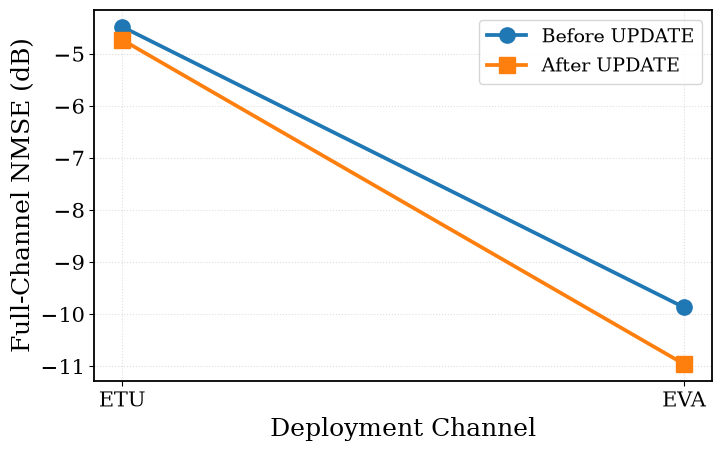


CELL 12 — FINAL SUMMARY
Runtime: 8.08 seconds
Trial results: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_data_aided_update_trials.csv
Summary: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_data_aided_update_summary.csv
Configuration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_data_aided_update_config.json
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_data_aided_update_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_data_aided_update_IEEE.png

CELL 12 DATA-AIDED UPDATE: PASS


In [ ]:

# ============================================================
# CELL 12 — DATA-AIDED GROUND-TRUTH-FREE UPDATE
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Reviewer 1 Comment 5 / Reviewer 2 Comment 2
#
# Receiver-observable adaptation:
#   - All 24 LS pilots remain in the FCN input.
#   - QPSK data symbols provide pseudo-targets.
#   - Ideal correct decoding is assumed.
#   - Loss uses NON-PILOT REs only.
#   - Only the FCN output layer is fine-tuned.
#   - Validation uses independent pseudo-targets.
#
# True full-channel CSI is used ONLY for offline NMSE.
# ============================================================

import copy
import time
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DA_SNR_DB = 12.0

DA_N_UPDATE = 100
DA_N_TRAIN = 80
DA_N_VAL = 20

DA_EPOCHS = 30
DA_LR = 1e-4
DA_BATCH_SIZE = 16

DA_PROX_LAMBDA = 1e-4
DA_WEIGHT_DECAY = 0.0

DA_N_EVAL = 2000
DA_N_TRIALS = 10

DA_CHANNELS = ["EVA", "ETU"]

DA_SEED = SEED + 1800

DA_DEVICE = DEVICE

random.seed(DA_SEED)
np.random.seed(DA_SEED)
torch.manual_seed(DA_SEED)
torch.cuda.manual_seed_all(DA_SEED)

print("=" * 72)
print("CELL 12 — DATA-AIDED GROUND-TRUTH-FREE UPDATE")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", DA_SNR_DB, "dB")
print("UPDATE observations:", DA_N_UPDATE)
print("Training observations:", DA_N_TRAIN)
print("Validation observations:", DA_N_VAL)
print("Epochs:", DA_EPOCHS)
print("Learning rate:", DA_LR)
print("Updated layer: fc4")
print("Ideal correct-decoding assumption: YES")

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify required notebook definitions
# ------------------------------------------------------------

required = [
    "generate_channel",
    "extract_pilot_observations",
    "ChannelEstimatorFCN",
    "CHECKPOINT_DIR",
    "RESULTS_DIR",
    "FIGURES_DIR",
    "N_F",
    "N_S",
    "PILOT_K",
    "PILOT_L",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing definitions: {missing}. "
        "Run Cells 1-6 first."
    )

# ------------------------------------------------------------
# 3. Load original EPA-trained FCN
# ------------------------------------------------------------

checkpoint_path = (
    CHECKPOINT_DIR / "fcn_epa_12db_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DA_DEVICE,
    weights_only=True
)

DA_BASELINE = ChannelEstimatorFCN().to(
    DA_DEVICE
)

state_dict = (
    checkpoint["model_state_dict"]
    if "model_state_dict" in checkpoint
    else checkpoint
)

DA_BASELINE.load_state_dict(
    state_dict
)

DA_BASELINE.eval()

for parameter in DA_BASELINE.parameters():
    parameter.requires_grad_(False)

assert hasattr(DA_BASELINE, "fc4"), (
    "Expected FCN output layer named fc4."
)

# ------------------------------------------------------------
# 4. Build pilot and non-pilot masks
# ------------------------------------------------------------

DA_N_RE = N_F * N_S

DA_PILOT_MASK = torch.zeros(
    N_F,
    N_S,
    dtype=torch.bool,
    device=DA_DEVICE
)

pilot_k = torch.as_tensor(
    PILOT_K,
    dtype=torch.long,
    device=DA_DEVICE
)

pilot_l = torch.as_tensor(
    PILOT_L,
    dtype=torch.long,
    device=DA_DEVICE
)

# PILOT_K and PILOT_L must describe paired RE indices.
assert pilot_k.numel() == pilot_l.numel()

DA_PILOT_MASK[pilot_k, pilot_l] = True

DA_DATA_MASK = ~DA_PILOT_MASK

DA_N_PILOTS = int(
    DA_PILOT_MASK.sum().item()
)

DA_N_DATA = int(
    DA_DATA_MASK.sum().item()
)

assert DA_N_PILOTS == 24, (
    f"Expected 24 pilot REs, got {DA_N_PILOTS}"
)

assert DA_N_DATA == DA_N_RE - DA_N_PILOTS

print("\n[RESOURCE ELEMENTS]")
print("Total REs:", DA_N_RE)
print("Pilot REs:", DA_N_PILOTS)
print("Data REs:", DA_N_DATA)

# ------------------------------------------------------------
# 5. Complex channel to real FCN target
# ------------------------------------------------------------

def da_channel_to_vector(H):
    """
    Convert complex channel grid [B, N_F, N_S]
    to real vector [B, 2*N_F*N_S].

    IMPORTANT:
    This ordering must match Cell 5 training targets.
    """

    B = H.shape[0]

    return torch.cat(
        [
            H.real.reshape(B, -1),
            H.imag.reshape(B, -1)
        ],
        dim=1
    )


def da_vector_to_complex(x):
    """
    Convert FCN output [B, 2*N_F*N_S]
    to complex grid [B, N_F, N_S].
    """

    B = x.shape[0]

    real = x[:, :DA_N_RE].reshape(
        B, N_F, N_S
    )

    imag = x[:, DA_N_RE:].reshape(
        B, N_F, N_S
    )

    return torch.complex(real, imag)

# ------------------------------------------------------------
# 6. Generate QPSK symbols
# ------------------------------------------------------------

def da_generate_qpsk(batch_size):
    """
    Unit-modulus QPSK symbols.
    """

    real_bits = torch.randint(
        0, 2,
        (batch_size, N_F, N_S),
        device=DA_DEVICE
    )

    imag_bits = torch.randint(
        0, 2,
        (batch_size, N_F, N_S),
        device=DA_DEVICE
    )

    real = (
        2.0 * real_bits.float() - 1.0
    )

    imag = (
        2.0 * imag_bits.float() - 1.0
    )

    X = torch.complex(
        real, imag
    ) / np.sqrt(2.0)

    # Known constant-modulus pilot symbols.
    # Use 1+0j on pilot REs.
    X[:, DA_PILOT_MASK] = (
        1.0 + 0.0j
    )

    return X

# ------------------------------------------------------------
# 7. Generate receiver-observable pseudo-targets
# ------------------------------------------------------------

@torch.no_grad()
def da_generate_dataset(
    profile,
    n_samples,
    snr_db=DA_SNR_DB,
    batch_size=512
):
    """
    Generate:
        H: true channel (evaluation only)
        X: transmitted QPSK grid
        Y: received grid
        h_p: full LS pilot input
        H_pseudo: data-aided pseudo-channel

    Ideal correct decoding:
        X_hat = X

    The pseudo-target is computed ONLY from
    receiver-side Y and reconstructed X_hat.

    H is never used to construct the pseudo-target
    or train the estimator.
    """

    input_batches = []
    pseudo_batches = []
    true_batches = []

    noise_variance = (
        10.0 ** (-snr_db / 10.0)
    )

    for start in range(
        0, n_samples, batch_size
    ):

        B = min(
            batch_size,
            n_samples - start
        )

        H = generate_channel(
            profile=profile,
            batch_size=B
        )

        H = H.to(DA_DEVICE)

        X = da_generate_qpsk(B)

        noise_real = torch.randn(
            B, N_F, N_S,
            device=DA_DEVICE
        )

        noise_imag = torch.randn(
            B, N_F, N_S,
            device=DA_DEVICE
        )

        noise = torch.complex(
            noise_real,
            noise_imag
        ) * np.sqrt(
            noise_variance / 2.0
        )

        # Received OFDM frequency-domain grid
        Y = H * X + noise

        # Receiver LS pilot estimates.
        # Use the exact paired pilot RE coordinates.
        pilot_received = Y[
            :,
            pilot_k,
            pilot_l
        ]

        pilot_symbols = X[
            :,
            pilot_k,
            pilot_l
        ]

        H_p_ls = (
            pilot_received / pilot_symbols
        )

        h_p = torch.cat(
            [
                H_p_ls.real,
                H_p_ls.imag
            ],
            dim=1
        ).float()

        # Ideal correctly reconstructed data symbols
        X_hat = X

        # Receiver-side data-aided pseudo-target
        H_pseudo = Y / X_hat

        # Ground truth reserved for offline evaluation
        H_true = H

        input_batches.append(
            h_p.detach()
        )

        pseudo_batches.append(
            H_pseudo.detach()
        )

        true_batches.append(
            H_true.detach()
        )

    h_p = torch.cat(
        input_batches,
        dim=0
    )

    H_pseudo = torch.cat(
        pseudo_batches,
        dim=0
    )

    H_true = torch.cat(
        true_batches,
        dim=0
    )

    return h_p, H_pseudo, H_true

# ------------------------------------------------------------
# 8. Data-aided pseudo-target loss
# ------------------------------------------------------------

def da_pseudo_loss(
    estimator,
    h_p,
    H_pseudo
):
    """
    Loss only on non-pilot REs.

    The pseudo-target noise on data REs is
    independent of input-pilot noise under the
    ideal correct-decoding AWGN model.
    """

    prediction = estimator(h_p)

    H_pred = da_vector_to_complex(
        prediction
    )

    error = (
        H_pred - H_pseudo
    ).abs().square()

    loss = error[
        :,
        DA_DATA_MASK
    ].mean()

    return loss

# ------------------------------------------------------------
# 9. Fine-tune output layer
# ------------------------------------------------------------

def da_finetune(
    baseline,
    train_inputs,
    train_targets,
    val_inputs,
    val_targets
):
    """
    Ground-truth-free fine-tuning.

    All hidden layers are frozen.
    Only fc4 is trainable.

    Candidate acceptance uses independent
    pseudo-target validation loss.
    """

    candidate = copy.deepcopy(
        baseline
    ).to(DA_DEVICE)

    for p in candidate.parameters():
        p.requires_grad_(False)

    for p in candidate.fc4.parameters():
        p.requires_grad_(True)

    original_params = [
        p.detach().clone()
        for p in candidate.fc4.parameters()
    ]

    optimizer = torch.optim.Adam(
        candidate.fc4.parameters(),
        lr=DA_LR,
        weight_decay=DA_WEIGHT_DECAY
    )

    baseline.eval()

    with torch.no_grad():
        baseline_val = da_pseudo_loss(
            baseline,
            val_inputs,
            val_targets
        ).item()

    best_val = baseline_val
    best_state = None

    history = []

    for epoch in range(DA_EPOCHS):

        candidate.train()

        permutation = torch.randperm(
            len(train_inputs),
            device=DA_DEVICE
        )

        epoch_losses = []

        for start in range(
            0,
            len(train_inputs),
            DA_BATCH_SIZE
        ):

            idx = permutation[
                start:start + DA_BATCH_SIZE
            ]

            x_batch = train_inputs[idx]
            y_batch = train_targets[idx]

            optimizer.zero_grad(
                set_to_none=True
            )

            pseudo_loss = da_pseudo_loss(
                candidate,
                x_batch,
                y_batch
            )

            proximal = sum(
                (p - p0).square().sum()
                for p, p0 in zip(
                    candidate.fc4.parameters(),
                    original_params
                )
            )

            total_loss = (
                pseudo_loss
                + DA_PROX_LAMBDA * proximal
            )

            total_loss.backward()
            optimizer.step()

            epoch_losses.append(
                pseudo_loss.item()
            )

        candidate.eval()

        with torch.no_grad():
            val_loss = da_pseudo_loss(
                candidate,
                val_inputs,
                val_targets
            ).item()

        history.append({
            "Epoch": epoch + 1,
            "Train_Loss": float(
                np.mean(epoch_losses)
            ),
            "Val_Loss": val_loss
        })

        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(
                candidate.state_dict()
            )

    accepted = best_state is not None

    if accepted:
        candidate.load_state_dict(
            best_state
        )
    else:
        candidate.load_state_dict(
            baseline.state_dict()
        )

    candidate.eval()

    return (
        candidate,
        accepted,
        baseline_val,
        best_val,
        history
    )

# ------------------------------------------------------------
# 10. Full-channel NMSE (offline evaluation only)
# ------------------------------------------------------------

@torch.no_grad()
def da_nmse_db(
    estimator,
    h_p,
    H_true
):
    """
    Full-channel NMSE for offline reporting.

    Ground-truth CSI is never passed to
    the optimizer or acceptance criterion.
    """

    estimator.eval()

    prediction = estimator(h_p)

    H_pred = da_vector_to_complex(
        prediction
    )

    error_power = (
        H_pred - H_true
    ).abs().square().sum()

    channel_power = (
        H_true.abs().square().sum()
    )

    nmse = (
        error_power
        / channel_power.clamp_min(1e-12)
    )

    return float(
        10.0 * torch.log10(nmse).item()
    )

# ------------------------------------------------------------
# 11. Run UPDATE experiments
# ------------------------------------------------------------

DA_RESULTS = []
DA_HISTORIES = {}

for profile in DA_CHANNELS:

    print(f"\nEvaluating data-aided UPDATE on {profile}...")

    for trial in range(DA_N_TRIALS):

        # --------------------------------------------
        # Deployment adaptation data
        # --------------------------------------------
        h_adapt, pseudo_adapt, _ = (
            da_generate_dataset(
                profile,
                DA_N_UPDATE
            )
        )

        train_inputs = h_adapt[:DA_N_TRAIN]
        train_targets = pseudo_adapt[:DA_N_TRAIN]

        val_inputs = h_adapt[DA_N_TRAIN:]
        val_targets = pseudo_adapt[DA_N_TRAIN:]

        # --------------------------------------------
        # Independent offline evaluation
        # --------------------------------------------
        h_eval, _, H_eval = da_generate_dataset(
            profile,
            DA_N_EVAL
        )

        baseline_nmse = da_nmse_db(
            DA_BASELINE,
            h_eval,
            H_eval
        )

        # --------------------------------------------
        # Ground-truth-free UPDATE
        # --------------------------------------------
        (
            updated_model,
            accepted,
            baseline_val,
            updated_val,
            history
        ) = da_finetune(
            DA_BASELINE,
            train_inputs,
            train_targets,
            val_inputs,
            val_targets
        )

        updated_nmse = da_nmse_db(
            updated_model,
            h_eval,
            H_eval
        )

        improvement = (
            baseline_nmse - updated_nmse
        )

        DA_RESULTS.append({
            "Channel": profile,
            "Trial": trial,
            "Accepted": accepted,
            "Baseline_Val_Loss": baseline_val,
            "Updated_Val_Loss": updated_val,
            "Baseline_NMSE_dB": baseline_nmse,
            "Updated_NMSE_dB": updated_nmse,
            "NMSE_Improvement_dB": improvement
        })

        DA_HISTORIES[
            (profile, trial)
        ] = history

        print(
            f"Trial {trial+1:02d} | "
            f"Accepted={accepted} | "
            f"NMSE {baseline_nmse:.2f} -> "
            f"{updated_nmse:.2f} dB | "
            f"Gain={improvement:+.2f} dB"
        )

# ------------------------------------------------------------
# 12. Summary
# ------------------------------------------------------------

DA_RESULTS_DF = pd.DataFrame(
    DA_RESULTS
)

DA_SUMMARY_DF = DA_RESULTS_DF.groupby(
    "Channel"
).agg(
    Acceptance_Rate=("Accepted", "mean"),
    Baseline_NMSE_dB=("Baseline_NMSE_dB", "mean"),
    Updated_NMSE_dB=("Updated_NMSE_dB", "mean"),
    Mean_Improvement_dB=("NMSE_Improvement_dB", "mean"),
    Std_Improvement_dB=("NMSE_Improvement_dB", "std"),
).reset_index()

print("\n" + "=" * 72)
print("CELL 12 — DATA-AIDED UPDATE RESULTS")
print("=" * 72)

print(
    DA_SUMMARY_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 13. IEEE-style NMSE figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 14,
    "lines.linewidth": 2.7,
    "lines.markersize": 11,
    "axes.linewidth": 1.3,
    "savefig.dpi": 600,
})

fig, ax = plt.subplots(
    figsize=(7.5, 4.8)
)

channels = DA_SUMMARY_DF["Channel"].tolist()

x = np.arange(
    len(channels)
)

ax.plot(
    x,
    DA_SUMMARY_DF["Baseline_NMSE_dB"],
    marker="o",
    label="Before UPDATE"
)

ax.plot(
    x,
    DA_SUMMARY_DF["Updated_NMSE_dB"],
    marker="s",
    label="After UPDATE"
)

ax.set_xticks(x)
ax.set_xticklabels(channels)

ax.set_ylabel(
    "Full-Channel NMSE (dB)"
)

ax.set_xlabel(
    "Deployment Channel"
)

ax.grid(
    True,
    linestyle=":",
    alpha=0.4
)

ax.legend()

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "cdt_data_aided_update_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "cdt_data_aided_update_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 14. Save results
# ------------------------------------------------------------

results_path = (
    RESULTS_DIR /
    "cdt_data_aided_update_trials.csv"
)

summary_path = (
    RESULTS_DIR /
    "cdt_data_aided_update_summary.csv"
)

DA_RESULTS_DF.to_csv(
    results_path,
    index=False
)

DA_SUMMARY_DF.to_csv(
    summary_path,
    index=False
)

config_path = (
    RESULTS_DIR /
    "cdt_data_aided_update_config.json"
)

with open(config_path, "w") as f:
    json.dump(
        {
            "snr_db": DA_SNR_DB,
            "update_samples": DA_N_UPDATE,
            "train_samples": DA_N_TRAIN,
            "validation_samples": DA_N_VAL,
            "epochs": DA_EPOCHS,
            "learning_rate": DA_LR,
            "updated_layer": "fc4",
            "proximal_lambda": DA_PROX_LAMBDA,
            "data_modulation": "QPSK",
            "correct_decoding_assumed": True,
            "crc_decoder_implemented": False,
            "ground_truth_used_for_update": False,
            "trials": DA_N_TRIALS
        },
        f,
        indent=4
    )

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 12 — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Trial results:", results_path)
print("Summary:", summary_path)
print("Configuration:", config_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 12 DATA-AIDED UPDATE: PASS")


CELL 13 — VQ-VAE GENERATIVE RETIRE
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Observed pseudo-targets: 2000
Synthetic channels: 8000
VQ-VAE epochs: 80
Replacement FCN epochs: 80

RETIRE SCENARIO: EVA

Training VQ-VAE...
  VQ-VAE epoch 020/80 | Loss=6.162933
  VQ-VAE epoch 040/80 | Loss=2.276806
  VQ-VAE epoch 060/80 | Loss=1.105080
  VQ-VAE epoch 080/80 | Loss=0.953683
Synthetic channel shape: (8000, 72, 14)

Training replacement FCN...
  FCN epoch 020/80 | MSE=0.000633
  FCN epoch 040/80 | MSE=0.000317
  FCN epoch 060/80 | MSE=0.000230
  FCN epoch 080/80 | MSE=0.000178

[VALIDATION]
Baseline loss: 0.16504579782485962
Candidate loss: 0.28527817130088806
LS fallback loss: 0.19876600801944733
Candidate accepted: False

[OFFLINE NMSE]
Baseline: -10.015639066696167 dB
Replacement: -6.6877686977386475 dB
Improvement: -3.3278703689575195 dB

RETIRE SCENARIO: ETU

Training VQ-VAE...
  VQ-VAE epoch 020/80 | Loss=2.918640
  VQ-VAE epoch 040/80 | Loss=1.220510
  VQ-VAE epoch 060/80 | L

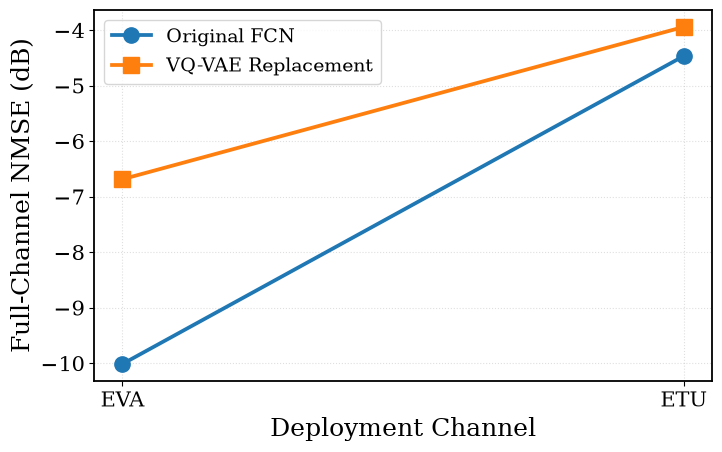


CELL 13 — FINAL SUMMARY
Runtime: 20.96 seconds
Results: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_vqvae_retire_results.csv
Configuration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_vqvae_retire_config.json
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_vqvae_retire_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_vqvae_retire_IEEE.png

CELL 13 VQ-VAE RETIRE PIPELINE: PASS


In [ ]:

# ============================================================
# CELL 13 — VQ-VAE GENERATIVE RETIRE / MODEL REPLACEMENT
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Reviewer 1 Comment 5
# Reviewer 2 Comment 2
#
# RETIRE pipeline:
#   1. Collect receiver-side pseudo-targets
#   2. Train VQ-VAE on noisy channel observations
#   3. Generate synthetic channel samples
#   4. Train replacement FCN on synthetic pairs
#   5. Validate using held-out receiver observations
#   6. Evaluate true-channel NMSE offline only
#
# Assumption:
#   Ideal correct decoding of QPSK data symbols.
#
# Ground-truth deployment CSI is NEVER used for:
#   - VQ-VAE training
#   - Synthetic-channel generation
#   - Replacement training
#   - Candidate acceptance
# ============================================================

import copy
import time
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RET_SNR_DB = 12.0

RET_CHANNELS = ["EVA", "ETU"]

RET_N_OBS = 2000
RET_N_VAL = 500
RET_N_TEST = 2000

RET_N_SYN = 8000

RET_VQ_EPOCHS = 80
RET_FCN_EPOCHS = 80

RET_BATCH_SIZE = 128
RET_LR_VQ = 1e-3
RET_LR_FCN = 1e-3

RET_LATENT_DIM = 128
RET_CODEBOOK_SIZE = 256
RET_COMMITMENT = 0.25

RET_SEED = SEED + 1900

random.seed(RET_SEED)
np.random.seed(RET_SEED)
torch.manual_seed(RET_SEED)
torch.cuda.manual_seed_all(RET_SEED)

RET_DEVICE = DEVICE

print("=" * 72)
print("CELL 13 — VQ-VAE GENERATIVE RETIRE")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", RET_SNR_DB, "dB")
print("Observed pseudo-targets:", RET_N_OBS)
print("Synthetic channels:", RET_N_SYN)
print("VQ-VAE epochs:", RET_VQ_EPOCHS)
print("Replacement FCN epochs:", RET_FCN_EPOCHS)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify Cell 12 dependencies
# ------------------------------------------------------------

required = [
    "da_generate_dataset",
    "da_channel_to_vector",
    "da_vector_to_complex",
    "da_nmse_db",
    "da_pseudo_loss",
    "DA_BASELINE",
    "DA_DATA_MASK",
    "DA_PILOT_MASK",
    "ChannelEstimatorFCN",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing Cell 12 definitions: {missing}. "
        "Run Cell 12 first."
    )

# ------------------------------------------------------------
# 3. Compact VQ-VAE architecture
# ------------------------------------------------------------

class RETVectorQuantizer(nn.Module):

    def __init__(
        self,
        n_codes,
        latent_dim,
        beta=0.25
    ):
        super().__init__()

        self.codebook = nn.Embedding(
            n_codes,
            latent_dim
        )

        self.beta = beta

        nn.init.uniform_(
            self.codebook.weight,
            -1.0 / n_codes,
            1.0 / n_codes
        )

    def forward(self, z):

        # z: [B, latent_dim]

        distances = (
            z.square().sum(dim=1, keepdim=True)
            - 2.0 * z @ self.codebook.weight.T
            + self.codebook.weight.square().sum(dim=1)
        )

        indices = distances.argmin(dim=1)

        z_q = self.codebook(indices)

        codebook_loss = F.mse_loss(
            z_q,
            z.detach()
        )

        commitment_loss = F.mse_loss(
            z,
            z_q.detach()
        )

        vq_loss = (
            codebook_loss
            + self.beta * commitment_loss
        )

        z_st = z + (z_q - z).detach()

        return z_st, vq_loss, indices


class RETVQVAE(nn.Module):

    def __init__(
        self,
        input_dim,
        latent_dim=128,
        n_codes=256
    ):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, latent_dim)
        )

        self.quantizer = RETVectorQuantizer(
            n_codes,
            latent_dim,
            RET_COMMITMENT
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, input_dim)
        )

    def forward(self, x):

        z = self.encoder(x)

        z_q, vq_loss, indices = (
            self.quantizer(z)
        )

        reconstruction = self.decoder(z_q)

        return reconstruction, vq_loss, indices

    @torch.no_grad()
    def decode_codes(self, indices):

        z_q = self.quantizer.codebook(indices)

        return self.decoder(z_q)


# ------------------------------------------------------------
# 4. VQ-VAE training
# ------------------------------------------------------------

def ret_train_vqvae(pseudo_channels):

    """
    Train VQ-VAE using receiver-side pseudo-targets.

    No true-channel tensor is used.
    """

    train_vectors = da_channel_to_vector(
        pseudo_channels
    ).float()

    input_dim = train_vectors.shape[1]

    vqvae = RETVQVAE(
        input_dim,
        RET_LATENT_DIM,
        RET_CODEBOOK_SIZE
    ).to(RET_DEVICE)

    optimizer = torch.optim.Adam(
        vqvae.parameters(),
        lr=RET_LR_VQ
    )

    history = []

    for epoch in range(RET_VQ_EPOCHS):

        vqvae.train()

        permutation = torch.randperm(
            len(train_vectors),
            device=RET_DEVICE
        )

        losses = []

        for start in range(
            0,
            len(train_vectors),
            RET_BATCH_SIZE
        ):

            idx = permutation[
                start:start + RET_BATCH_SIZE
            ]

            batch = train_vectors[idx]

            optimizer.zero_grad(
                set_to_none=True
            )

            recon, vq_loss, _ = vqvae(batch)

            recon_loss = F.mse_loss(
                recon,
                batch
            )

            loss = recon_loss + vq_loss

            loss.backward()
            optimizer.step()

            losses.append(loss.item())

        history.append(
            float(np.mean(losses))
        )

        if (epoch + 1) % 20 == 0:
            print(
                f"  VQ-VAE epoch {epoch+1:03d}/"
                f"{RET_VQ_EPOCHS} | "
                f"Loss={history[-1]:.6f}"
            )

    vqvae.eval()

    return vqvae, history


# ------------------------------------------------------------
# 5. Learn empirical code distribution
# ------------------------------------------------------------

@torch.no_grad()
def ret_code_probabilities(
    vqvae,
    pseudo_channels
):

    vectors = da_channel_to_vector(
        pseudo_channels
    ).float()

    z = vqvae.encoder(vectors)

    _, _, indices = vqvae.quantizer(z)

    counts = torch.bincount(
        indices,
        minlength=RET_CODEBOOK_SIZE
    ).float()

    probabilities = (
        counts + 1e-6
    )

    probabilities /= probabilities.sum()

    return probabilities


# ------------------------------------------------------------
# 6. Generate synthetic channel realizations
# ------------------------------------------------------------

@torch.no_grad()
def ret_generate_synthetic(
    vqvae,
    code_probabilities,
    n_samples=RET_N_SYN
):

    """
    Sample learned VQ code distribution and decode.

    This is a simple unconditional generator.
    """

    indices = torch.multinomial(
        code_probabilities,
        num_samples=n_samples,
        replacement=True
    )

    synthetic_vectors = vqvae.decode_codes(
        indices
    )

    H_syn = da_vector_to_complex(
        synthetic_vectors
    )

    return H_syn


# ------------------------------------------------------------
# 7. Generate synthetic FCN training pairs
# ------------------------------------------------------------

@torch.no_grad()
def ret_make_training_pairs(
    H_syn,
    snr_db=RET_SNR_DB
):

    """
    Generate known pilot observations from synthetic
    channel grids.

    Synthetic channels are treated as supervised
    targets for replacement FCN training.
    """

    B = H_syn.shape[0]

    X = da_generate_qpsk(B)

    noise_variance = (
        10.0 ** (-snr_db / 10.0)
    )

    noise = torch.complex(
        torch.randn_like(H_syn.real),
        torch.randn_like(H_syn.real)
    ) * np.sqrt(
        noise_variance / 2.0
    )

    Y = H_syn * X + noise

    pilot_received = Y[
        :,
        pilot_k,
        pilot_l
    ]

    pilot_symbols = X[
        :,
        pilot_k,
        pilot_l
    ]

    H_p_ls = (
        pilot_received / pilot_symbols
    )

    h_p = torch.cat(
        [
            H_p_ls.real,
            H_p_ls.imag
        ],
        dim=1
    ).float()

    target = da_channel_to_vector(
        H_syn
    ).float()

    return h_p, target


# ------------------------------------------------------------
# 8. Train replacement FCN
# ------------------------------------------------------------

def ret_train_replacement(
    train_inputs,
    train_targets
):

    replacement = ChannelEstimatorFCN().to(
        RET_DEVICE
    )

    optimizer = torch.optim.Adam(
        replacement.parameters(),
        lr=RET_LR_FCN
    )

    history = []

    for epoch in range(RET_FCN_EPOCHS):

        replacement.train()

        permutation = torch.randperm(
            len(train_inputs),
            device=RET_DEVICE
        )

        losses = []

        for start in range(
            0,
            len(train_inputs),
            RET_BATCH_SIZE
        ):

            idx = permutation[
                start:start + RET_BATCH_SIZE
            ]

            x_batch = train_inputs[idx]
            y_batch = train_targets[idx]

            optimizer.zero_grad(
                set_to_none=True
            )

            prediction = replacement(
                x_batch
            )

            loss = F.mse_loss(
                prediction,
                y_batch
            )

            loss.backward()
            optimizer.step()

            losses.append(loss.item())

        history.append(
            float(np.mean(losses))
        )

        if (epoch + 1) % 20 == 0:
            print(
                f"  FCN epoch {epoch+1:03d}/"
                f"{RET_FCN_EPOCHS} | "
                f"MSE={history[-1]:.6f}"
            )

    replacement.eval()

    return replacement, history


# ------------------------------------------------------------
# 9. LS fallback interpolation
# ------------------------------------------------------------

@torch.no_grad()
def ret_ls_fallback(h_p):

    """
    Simple nearest-pilot LS fallback.

    Used as an additional deployment baseline.
    """

    B = h_p.shape[0]

    pilot_complex = torch.complex(
        h_p[:, :DA_N_PILOTS],
        h_p[:, DA_N_PILOTS:]
    )

    # Nearest pilot in 2D RE coordinate space
    freq_grid = torch.arange(
        N_F,
        device=RET_DEVICE
    )

    time_grid = torch.arange(
        N_S,
        device=RET_DEVICE
    )

    grid_k, grid_l = torch.meshgrid(
        freq_grid,
        time_grid,
        indexing="ij"
    )

    distance = (
        (grid_k[..., None] - pilot_k)**2
        + (grid_l[..., None] - pilot_l)**2
    )

    nearest_idx = distance.argmin(
        dim=-1
    )

    H_ls = pilot_complex[
        :,
        nearest_idx
    ]

    return H_ls


# ------------------------------------------------------------
# 10. Verify-before-deploy validation
# ------------------------------------------------------------

@torch.no_grad()
def ret_validate_candidate(
    candidate,
    baseline,
    val_inputs,
    val_pseudo
):

    """
    Candidate selection using receiver-side
    pseudo-target loss only.

    True channel is not used.
    """

    candidate.eval()
    baseline.eval()

    candidate_loss = da_pseudo_loss(
        candidate,
        val_inputs,
        val_pseudo
    ).item()

    baseline_loss = da_pseudo_loss(
        baseline,
        val_inputs,
        val_pseudo
    ).item()

    H_ls = ret_ls_fallback(
        val_inputs
    )

    ls_loss = (
        H_ls[:, DA_DATA_MASK]
        - val_pseudo[:, DA_DATA_MASK]
    ).abs().square().mean().item()

    accepted = (
        candidate_loss < baseline_loss
        and candidate_loss < ls_loss
    )

    return (
        accepted,
        candidate_loss,
        baseline_loss,
        ls_loss
    )


# ------------------------------------------------------------
# 11. Run RETIRE experiments
# ------------------------------------------------------------

RET_RESULTS = []
RET_HISTORIES = {}

for profile in RET_CHANNELS:

    print("\n" + "=" * 72)
    print(f"RETIRE SCENARIO: {profile}")
    print("=" * 72)

    # --------------------------------------------
    # Receiver-side pseudo-target observations
    # --------------------------------------------
    h_obs, H_pseudo_obs, _ = (
        da_generate_dataset(
            profile,
            RET_N_OBS
        )
    )

    # Independent pseudo-target validation
    h_val, H_pseudo_val, _ = (
        da_generate_dataset(
            profile,
            RET_N_VAL
        )
    )

    # Independent offline evaluation
    h_test, _, H_true_test = (
        da_generate_dataset(
            profile,
            RET_N_TEST
        )
    )

    # --------------------------------------------
    # Train generative model
    # --------------------------------------------
    print("\nTraining VQ-VAE...")

    vqvae, vq_history = ret_train_vqvae(
        H_pseudo_obs
    )

    # --------------------------------------------
    # Learn code distribution
    # --------------------------------------------
    code_probabilities = (
        ret_code_probabilities(
            vqvae,
            H_pseudo_obs
        )
    )

    # --------------------------------------------
    # Generate synthetic channels
    # --------------------------------------------
    H_syn = ret_generate_synthetic(
        vqvae,
        code_probabilities,
        RET_N_SYN
    )

    print(
        "Synthetic channel shape:",
        tuple(H_syn.shape)
    )

    # --------------------------------------------
    # Generate supervised synthetic pairs
    # --------------------------------------------
    syn_inputs, syn_targets = (
        ret_make_training_pairs(
            H_syn
        )
    )

    # --------------------------------------------
    # Train replacement estimator
    # --------------------------------------------
    print("\nTraining replacement FCN...")

    replacement, fcn_history = (
        ret_train_replacement(
            syn_inputs,
            syn_targets
        )
    )

    # --------------------------------------------
    # Receiver-side validation
    # --------------------------------------------
    (
        accepted,
        candidate_loss,
        baseline_loss,
        ls_loss
    ) = ret_validate_candidate(
        replacement,
        DA_BASELINE,
        h_val,
        H_pseudo_val
    )

    # --------------------------------------------
    # Offline NMSE evaluation
    # --------------------------------------------
    baseline_nmse = da_nmse_db(
        DA_BASELINE,
        h_test,
        H_true_test
    )

    replacement_nmse = da_nmse_db(
        replacement,
        h_test,
        H_true_test
    )

    improvement = (
        baseline_nmse - replacement_nmse
    )

    RET_RESULTS.append({
        "Channel": profile,
        "Accepted": accepted,
        "Baseline_Val_Loss": baseline_loss,
        "Candidate_Val_Loss": candidate_loss,
        "LS_Val_Loss": ls_loss,
        "Baseline_NMSE_dB": baseline_nmse,
        "Replacement_NMSE_dB": replacement_nmse,
        "NMSE_Improvement_dB": improvement
    })

    RET_HISTORIES[profile] = {
        "VQVAE": vq_history,
        "FCN": fcn_history
    }

    print("\n[VALIDATION]")
    print("Baseline loss:", baseline_loss)
    print("Candidate loss:", candidate_loss)
    print("LS fallback loss:", ls_loss)
    print("Candidate accepted:", accepted)

    print("\n[OFFLINE NMSE]")
    print("Baseline:", baseline_nmse, "dB")
    print("Replacement:", replacement_nmse, "dB")
    print("Improvement:", improvement, "dB")

    # Save model checkpoints
    torch.save(
        vqvae.state_dict(),
        CHECKPOINT_DIR /
        f"vqvae_retire_{profile.lower()}.pt"
    )

    torch.save(
        replacement.state_dict(),
        CHECKPOINT_DIR /
        f"replacement_fcn_{profile.lower()}.pt"
    )


# ------------------------------------------------------------
# 12. Results summary
# ------------------------------------------------------------

RET_RESULTS_DF = pd.DataFrame(
    RET_RESULTS
)

print("\n" + "=" * 72)
print("CELL 13 — RETIRE REPLACEMENT RESULTS")
print("=" * 72)

print(
    RET_RESULTS_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# 13. IEEE-style comparison figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 14,
    "lines.linewidth": 2.7,
    "lines.markersize": 11,
    "axes.linewidth": 1.3,
    "savefig.dpi": 600,
})

fig, ax = plt.subplots(
    figsize=(7.5, 4.8)
)

x = np.arange(
    len(RET_RESULTS_DF)
)

ax.plot(
    x,
    RET_RESULTS_DF["Baseline_NMSE_dB"],
    marker="o",
    label="Original FCN"
)

ax.plot(
    x,
    RET_RESULTS_DF["Replacement_NMSE_dB"],
    marker="s",
    label="VQ-VAE Replacement"
)

ax.set_xticks(x)

ax.set_xticklabels(
    RET_RESULTS_DF["Channel"]
)

ax.set_xlabel(
    "Deployment Channel"
)

ax.set_ylabel(
    "Full-Channel NMSE (dB)"
)

ax.grid(
    True,
    linestyle=":",
    alpha=0.4
)

ax.legend()

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "cdt_vqvae_retire_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "cdt_vqvae_retire_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 14. Save results and configuration
# ------------------------------------------------------------

results_path = (
    RESULTS_DIR /
    "cdt_vqvae_retire_results.csv"
)

RET_RESULTS_DF.to_csv(
    results_path,
    index=False
)

config_path = (
    RESULTS_DIR /
    "cdt_vqvae_retire_config.json"
)

with open(config_path, "w") as f:

    json.dump({
        "snr_db": RET_SNR_DB,
        "observed_pseudo_targets": RET_N_OBS,
        "validation_samples": RET_N_VAL,
        "test_samples": RET_N_TEST,
        "synthetic_samples": RET_N_SYN,
        "vqvae_epochs": RET_VQ_EPOCHS,
        "replacement_epochs": RET_FCN_EPOCHS,
        "latent_dimension": RET_LATENT_DIM,
        "codebook_size": RET_CODEBOOK_SIZE,
        "correct_decoding_assumed": True,
        "ground_truth_used_for_training": False,
        "ground_truth_used_for_acceptance": False
    }, f, indent=4)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 13 — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Results:", results_path)
print("Configuration:", config_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 13 VQ-VAE RETIRE PIPELINE: PASS")


CELL 13A — SPATIAL VQ-VAE FIDELITY DIAGNOSTICS
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Observed pseudo-targets: 2000
Validation pseudo-targets: 500
Synthetic channels: 4000
VQ-VAE epochs: 80
Latent dimension: 64
Codebook size: 256

SPATIAL VQ-VAE SCENARIO: EVA

Training spatial VQ-VAE...
Epoch 020/80 | Train=19.504923 | Val=15.446798
Epoch 040/80 | Train=15.742372 | Val=18.273103
Epoch 060/80 | Train=4.977611 | Val=4.343772
Epoch 080/80 | Train=5.803996 | Val=9.247068
Synthetic shape: (4000, 72, 14)

[GENERATOR DIAGNOSTICS]
Used codes: 10
Codebook utilization: 3.91%
Perplexity: 7.55
Observed power: 1.049618124961853
Synthetic power: 8.115341915981844e-05
Observed diversity: 1.0080190896987915
Synthetic diversity: 0.32574379444122314
Frequency correlation error: 0.06644992804368528
Time correlation error: 0.1993127697212888

SPATIAL VQ-VAE SCENARIO: ETU

Training spatial VQ-VAE...
Epoch 020/80 | Train=26.415326 | Val=28.450351
Epoch 040/80 | Train=12.824674 | Val=17.003649


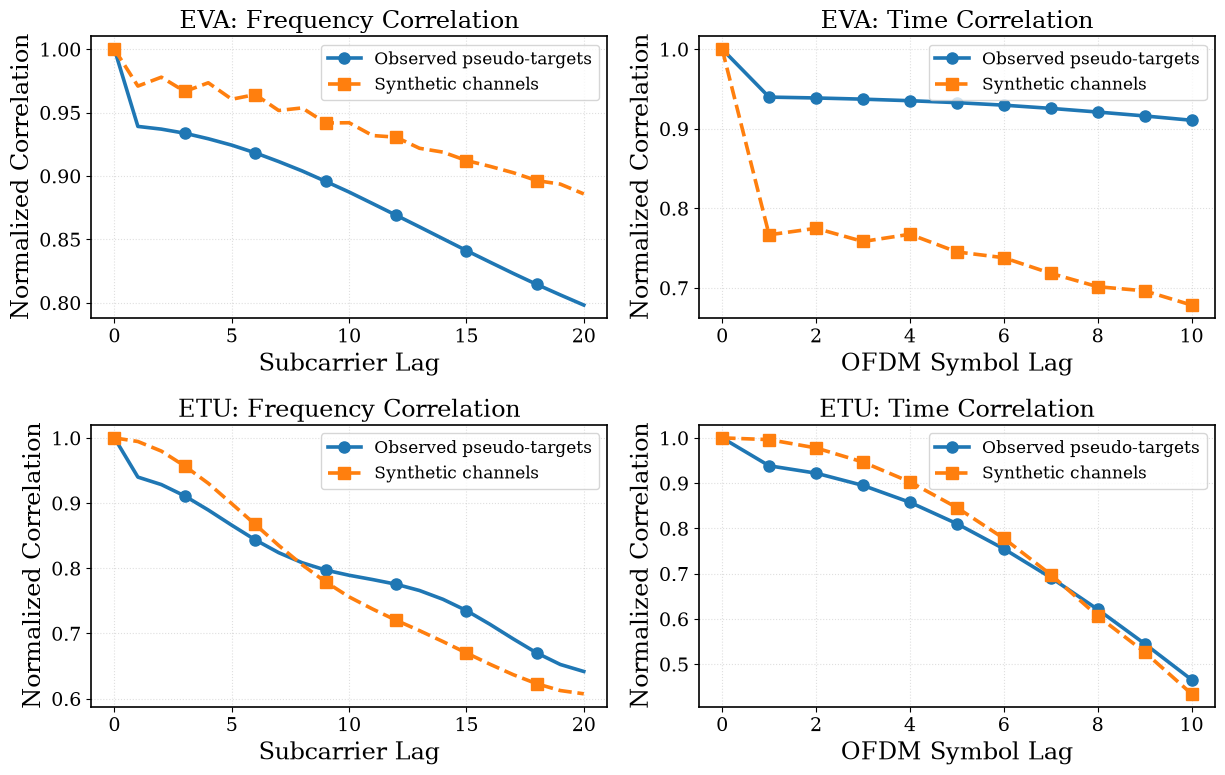


CELL 13A — FINAL SUMMARY
Runtime: 37.01 seconds
Summary: /home/afanali/wcnc_project/WCL_CDT_Revision/results/spatial_vqvae_fidelity_summary.csv
Configuration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/spatial_vqvae_config.json
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/spatial_vqvae_fidelity_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/spatial_vqvae_fidelity_IEEE.png

CELL 13A SPATIAL VQ-VAE: PASS


In [ ]:

# ============================================================
# CELL 13A — SPATIAL VQ-VAE AND CHANNEL FIDELITY DIAGNOSTICS
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Purpose:
#   Improve the generative model used by RETIRE.
#
# Features:
#   1. Convolutional spatial VQ-VAE
#   2. Multiple quantized latent tokens per channel
#   3. Complete latent-map resampling
#   4. Codebook utilization and perplexity
#   5. Reconstruction and generation fidelity
#   6. Frequency/time correlation comparison
#   7. Synthetic diversity diagnostics
#
# No replacement FCN training in this cell.
#
# Ground-truth CSI is NOT used for generator training,
# generation, or validation.
#
# Ideal correct decoding is assumed.
# ============================================================

import time
import json
import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SP_SNR_DB = 12.0

SP_CHANNELS = ["EVA", "ETU"]

SP_N_OBS = 2000
SP_N_VAL = 500
SP_N_SYN = 4000

SP_EPOCHS = 80
SP_BATCH_SIZE = 64

SP_LR = 2e-4
SP_WEIGHT_DECAY = 1e-5

SP_LATENT_DIM = 64
SP_CODEBOOK_SIZE = 256
SP_COMMITMENT = 0.25

SP_SEED = SEED + 2000

SP_DEVICE = DEVICE

random.seed(SP_SEED)
np.random.seed(SP_SEED)
torch.manual_seed(SP_SEED)
torch.cuda.manual_seed_all(SP_SEED)

print("=" * 72)
print("CELL 13A — SPATIAL VQ-VAE FIDELITY DIAGNOSTICS")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", SP_SNR_DB, "dB")
print("Observed pseudo-targets:", SP_N_OBS)
print("Validation pseudo-targets:", SP_N_VAL)
print("Synthetic channels:", SP_N_SYN)
print("VQ-VAE epochs:", SP_EPOCHS)
print("Latent dimension:", SP_LATENT_DIM)
print("Codebook size:", SP_CODEBOOK_SIZE)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify Cell 12 dependencies
# ------------------------------------------------------------

required = [
    "da_generate_dataset",
    "CHECKPOINT_DIR",
    "RESULTS_DIR",
    "FIGURES_DIR",
    "N_F",
    "N_S",
    "DA_DATA_MASK",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing dependencies: {missing}. "
        "Run Cell 12 first."
    )

assert N_F == 72
assert N_S == 14

# ------------------------------------------------------------
# 3. Complex channel grid conversion
# ------------------------------------------------------------

def sp_complex_to_channels(H):
    """
    Complex [B, 72, 14]
        -> Real [B, 2, 72, 14]
    """

    return torch.stack(
        [H.real, H.imag],
        dim=1
    ).float()


def sp_channels_to_complex(x):
    """
    Real [B, 2, 72, 14]
        -> Complex [B, 72, 14]
    """

    return torch.complex(
        x[:, 0],
        x[:, 1]
    )


# ------------------------------------------------------------
# 4. Spatial vector quantizer
# ------------------------------------------------------------

class SPVectorQuantizer(nn.Module):

    def __init__(
        self,
        n_codes,
        embedding_dim,
        beta=0.25
    ):
        super().__init__()

        self.n_codes = n_codes
        self.embedding_dim = embedding_dim
        self.beta = beta

        self.embedding = nn.Embedding(
            n_codes,
            embedding_dim
        )

        nn.init.uniform_(
            self.embedding.weight,
            -1.0 / n_codes,
            1.0 / n_codes
        )

    def forward(self, z):
        """
        z: [B, C, H, W]
        """

        B, C, H, W = z.shape

        # [B, H, W, C]
        z_perm = z.permute(
            0, 2, 3, 1
        ).contiguous()

        flat = z_perm.reshape(
            -1, C
        )

        codebook = self.embedding.weight

        distances = (
            flat.square().sum(
                dim=1,
                keepdim=True
            )
            - 2.0 * flat @ codebook.T
            + codebook.square().sum(
                dim=1
            )
        )

        indices = distances.argmin(
            dim=1
        )

        quantized = self.embedding(
            indices
        ).reshape(
            B, H, W, C
        )

        codebook_loss = F.mse_loss(
            quantized,
            z_perm.detach()
        )

        commitment_loss = F.mse_loss(
            z_perm,
            quantized.detach()
        )

        vq_loss = (
            codebook_loss
            + self.beta * commitment_loss
        )

        # Straight-through estimator
        quantized_st = (
            z_perm
            + (quantized - z_perm).detach()
        )

        quantized_st = quantized_st.permute(
            0, 3, 1, 2
        ).contiguous()

        index_map = indices.reshape(
            B, H, W
        )

        return (
            quantized_st,
            vq_loss,
            index_map
        )


# ------------------------------------------------------------
# 5. Convolutional spatial VQ-VAE
# ------------------------------------------------------------

class SPVQVAE(nn.Module):

    def __init__(
        self,
        latent_dim=64,
        n_codes=256
    ):
        super().__init__()

        # Input [B, 2, 72, 14]
        self.encoder = nn.Sequential(
            nn.Conv2d(
                2, 64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                128, 128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                128, latent_dim,
                kernel_size=3,
                padding=1
            )
        )

        # Encoder output: [B, latent_dim, 18, 3]
        # Time dimension 14 -> 7 -> 3 under stride-2.
        self.quantizer = SPVectorQuantizer(
            n_codes,
            latent_dim,
            SP_COMMITMENT
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                latent_dim, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                64, 2,
                kernel_size=3,
                padding=1
            )
        )

    def encode(self, x):

        z = self.encoder(x)

        _, _, indices = self.quantizer(z)

        return indices

    def decode_indices(self, indices):

        # indices: [B, H_lat, W_lat]

        embeddings = self.quantizer.embedding(
            indices
        )

        embeddings = embeddings.permute(
            0, 3, 1, 2
        ).contiguous()

        decoded = self.decoder(
            embeddings
        )

        # Explicitly enforce target grid size.
        decoded = F.interpolate(
            decoded,
            size=(N_F, N_S),
            mode="bilinear",
            align_corners=False
        )

        return decoded

    def forward(self, x):

        z = self.encoder(x)

        z_q, vq_loss, indices = (
            self.quantizer(z)
        )

        reconstruction = self.decoder(
            z_q
        )

        reconstruction = F.interpolate(
            reconstruction,
            size=(N_F, N_S),
            mode="bilinear",
            align_corners=False
        )

        return (
            reconstruction,
            vq_loss,
            indices
        )


# ------------------------------------------------------------
# 6. Channel correlation functions
# ------------------------------------------------------------

@torch.no_grad()
def sp_frequency_correlation(
    H,
    max_lag=20
):
    """
    Normalized frequency correlation magnitude.

    H: complex [B, 72, 14]
    """

    correlations = []

    power = H.abs().square().mean()

    for lag in range(max_lag + 1):

        if lag == 0:
            corr = power
        else:
            corr = (
                H[:, lag:, :]
                * H[:, :-lag, :].conj()
            ).mean()

        correlations.append(
            (corr.abs() / power.clamp_min(1e-12))
            .item()
        )

    return np.asarray(correlations)


@torch.no_grad()
def sp_time_correlation(
    H,
    max_lag=10
):
    """
    Normalized within-grid time correlation magnitude.
    """

    correlations = []

    power = H.abs().square().mean()

    for lag in range(max_lag + 1):

        if lag == 0:
            corr = power
        else:
            corr = (
                H[:, :, lag:]
                * H[:, :, :-lag].conj()
            ).mean()

        correlations.append(
            (corr.abs() / power.clamp_min(1e-12))
            .item()
        )

    return np.asarray(correlations)


# ------------------------------------------------------------
# 7. Train spatial VQ-VAE
# ------------------------------------------------------------

def sp_train_vqvae(
    train_pseudo,
    val_pseudo
):

    x_train = sp_complex_to_channels(
        train_pseudo
    )

    x_val = sp_complex_to_channels(
        val_pseudo
    )

    model_vq = SPVQVAE(
        SP_LATENT_DIM,
        SP_CODEBOOK_SIZE
    ).to(SP_DEVICE)

    optimizer = torch.optim.Adam(
        model_vq.parameters(),
        lr=SP_LR,
        weight_decay=SP_WEIGHT_DECAY
    )

    history = []

    best_val = float("inf")
    best_state = None

    for epoch in range(SP_EPOCHS):

        model_vq.train()

        permutation = torch.randperm(
            len(x_train),
            device=SP_DEVICE
        )

        train_losses = []

        for start in range(
            0,
            len(x_train),
            SP_BATCH_SIZE
        ):

            idx = permutation[
                start:start + SP_BATCH_SIZE
            ]

            batch = x_train[idx]

            optimizer.zero_grad(
                set_to_none=True
            )

            recon, vq_loss, _ = model_vq(
                batch
            )

            recon_loss = F.mse_loss(
                recon,
                batch
            )

            loss = recon_loss + vq_loss

            loss.backward()
            optimizer.step()

            train_losses.append(
                loss.item()
            )

        model_vq.eval()

        val_losses = []

        with torch.no_grad():

            for start in range(
                0,
                len(x_val),
                SP_BATCH_SIZE
            ):

                batch = x_val[
                    start:start + SP_BATCH_SIZE
                ]

                recon, vq_loss, _ = model_vq(
                    batch
                )

                val_loss = (
                    F.mse_loss(recon, batch)
                    + vq_loss
                )

                val_losses.append(
                    val_loss.item()
                )

        mean_train = float(
            np.mean(train_losses)
        )

        mean_val = float(
            np.mean(val_losses)
        )

        history.append({
            "Epoch": epoch + 1,
            "Train_Loss": mean_train,
            "Val_Loss": mean_val
        })

        if mean_val < best_val:

            best_val = mean_val

            best_state = copy.deepcopy(
                model_vq.state_dict()
            )

        if (epoch + 1) % 20 == 0:

            print(
                f"Epoch {epoch+1:03d}/{SP_EPOCHS} | "
                f"Train={mean_train:.6f} | "
                f"Val={mean_val:.6f}"
            )

    model_vq.load_state_dict(
        best_state
    )

    model_vq.eval()

    return (
        model_vq,
        pd.DataFrame(history),
        best_val
    )


# ------------------------------------------------------------
# 8. Codebook utilization
# ------------------------------------------------------------

@torch.no_grad()
def sp_codebook_statistics(
    model_vq,
    pseudo_channels
):

    x = sp_complex_to_channels(
        pseudo_channels
    )

    indices = model_vq.encode(x)

    counts = torch.bincount(
        indices.reshape(-1),
        minlength=SP_CODEBOOK_SIZE
    ).float()

    probabilities = (
        counts / counts.sum().clamp_min(1)
    )

    used_codes = int(
        (counts > 0).sum().item()
    )

    entropy = -(
        probabilities
        * torch.log(
            probabilities.clamp_min(1e-12)
        )
    ).sum()

    perplexity = float(
        torch.exp(entropy).item()
    )

    return {
        "Used_Codes": used_codes,
        "Utilization": (
            used_codes / SP_CODEBOOK_SIZE
        ),
        "Perplexity": perplexity,
        "Indices": indices.detach()
    }


# ------------------------------------------------------------
# 9. Synthetic generation from latent maps
# ------------------------------------------------------------

@torch.no_grad()
def sp_generate_synthetic(
    model_vq,
    observed_pseudo,
    n_samples=SP_N_SYN,
    batch_size=128
):
    """
    Resample complete latent-token maps.

    This preserves within-map code dependencies.

    IMPORTANT:
    This is empirical latent-map resampling,
    not an independently trained latent prior.
    """

    x_obs = sp_complex_to_channels(
        observed_pseudo
    )

    # Encode observed pseudo-targets
    all_indices = []

    for start in range(
        0,
        len(x_obs),
        batch_size
    ):

        batch = x_obs[
            start:start + batch_size
        ]

        indices = model_vq.encode(
            batch
        )

        all_indices.append(indices)

    all_indices = torch.cat(
        all_indices,
        dim=0
    )

    synthetic_batches = []

    for start in range(
        0,
        n_samples,
        batch_size
    ):

        B = min(
            batch_size,
            n_samples - start
        )

        selected = torch.randint(
            0,
            len(all_indices),
            (B,),
            device=SP_DEVICE
        )

        latent_maps = all_indices[
            selected
        ]

        decoded = model_vq.decode_indices(
            latent_maps
        )

        H_syn = sp_channels_to_complex(
            decoded
        )

        synthetic_batches.append(
            H_syn.detach()
        )

    return torch.cat(
        synthetic_batches,
        dim=0
    )


# ------------------------------------------------------------
# 10. Synthetic diversity
# ------------------------------------------------------------

@torch.no_grad()
def sp_diversity_metric(
    H,
    n_pairs=1000
):
    """
    Mean normalized pairwise channel distance.

    Higher values indicate more sample diversity,
    but not necessarily better physical fidelity.
    """

    N = len(H)

    idx1 = torch.randint(
        0, N,
        (n_pairs,),
        device=SP_DEVICE
    )

    idx2 = torch.randint(
        0, N,
        (n_pairs,),
        device=SP_DEVICE
    )

    A = H[idx1].reshape(
        n_pairs, -1
    )

    B = H[idx2].reshape(
        n_pairs, -1
    )

    numerator = (
        A - B
    ).abs().square().sum(dim=1)

    denominator = (
        A.abs().square().sum(dim=1)
        + B.abs().square().sum(dim=1)
    ).clamp_min(1e-12)

    distance = (
        numerator / denominator
    )

    return float(
        distance.mean().item()
    )


# ------------------------------------------------------------
# 11. Run EVA and ETU experiments
# ------------------------------------------------------------

SP_RESULTS = []
SP_CURVES = {}
SP_HISTORIES = {}

for profile in SP_CHANNELS:

    print("\n" + "=" * 72)
    print(f"SPATIAL VQ-VAE SCENARIO: {profile}")
    print("=" * 72)

    # Receiver-observable pseudo-target datasets
    _, pseudo_train, _ = da_generate_dataset(
        profile,
        SP_N_OBS
    )

    _, pseudo_val, _ = da_generate_dataset(
        profile,
        SP_N_VAL
    )

    # Train spatial VQ-VAE
    print("\nTraining spatial VQ-VAE...")

    (
        spatial_vqvae,
        history_df,
        best_val
    ) = sp_train_vqvae(
        pseudo_train,
        pseudo_val
    )

    SP_HISTORIES[profile] = history_df

    # Codebook statistics
    code_stats = sp_codebook_statistics(
        spatial_vqvae,
        pseudo_val
    )

    # Generate synthetic channels
    H_syn = sp_generate_synthetic(
        spatial_vqvae,
        pseudo_train,
        SP_N_SYN
    )

    print(
        "Synthetic shape:",
        tuple(H_syn.shape)
    )

    # Frequency correlation
    freq_obs = sp_frequency_correlation(
        pseudo_val
    )

    freq_syn = sp_frequency_correlation(
        H_syn
    )

    # Time correlation
    time_obs = sp_time_correlation(
        pseudo_val
    )

    time_syn = sp_time_correlation(
        H_syn
    )

    # Diversity
    diversity_obs = sp_diversity_metric(
        pseudo_val
    )

    diversity_syn = sp_diversity_metric(
        H_syn
    )

    # Power
    power_obs = float(
        pseudo_val.abs().square().mean().item()
    )

    power_syn = float(
        H_syn.abs().square().mean().item()
    )

    # Relative correlation errors
    freq_error = float(
        np.linalg.norm(
            freq_syn - freq_obs
        )
        / max(
            np.linalg.norm(freq_obs),
            1e-12
        )
    )

    time_error = float(
        np.linalg.norm(
            time_syn - time_obs
        )
        / max(
            np.linalg.norm(time_obs),
            1e-12
        )
    )

    SP_RESULTS.append({
        "Channel": profile,
        "Best_Val_Loss": best_val,
        "Used_Codes": code_stats["Used_Codes"],
        "Codebook_Utilization":
            code_stats["Utilization"],
        "Perplexity":
            code_stats["Perplexity"],
        "Observed_Power": power_obs,
        "Synthetic_Power": power_syn,
        "Observed_Diversity": diversity_obs,
        "Synthetic_Diversity": diversity_syn,
        "Frequency_Corr_Error": freq_error,
        "Time_Corr_Error": time_error
    })

    SP_CURVES[profile] = {
        "freq_obs": freq_obs,
        "freq_syn": freq_syn,
        "time_obs": time_obs,
        "time_syn": time_syn
    }

    # Save generator checkpoint
    torch.save(
        {
            "model_state_dict":
                spatial_vqvae.state_dict(),
            "latent_dim": SP_LATENT_DIM,
            "codebook_size": SP_CODEBOOK_SIZE,
            "snr_db": SP_SNR_DB,
            "channel": profile
        },
        CHECKPOINT_DIR /
        f"spatial_vqvae_{profile.lower()}.pt"
    )

    # Save generated channels for later RETIRE training
    torch.save(
        H_syn.detach().cpu(),
        RESULTS_DIR /
        f"spatial_synthetic_{profile.lower()}.pt"
    )

    history_df.to_csv(
        RESULTS_DIR /
        f"spatial_vqvae_history_{profile.lower()}.csv",
        index=False
    )

    print("\n[GENERATOR DIAGNOSTICS]")
    print("Used codes:", code_stats["Used_Codes"])
    print("Codebook utilization:",
          f"{100*code_stats['Utilization']:.2f}%")
    print("Perplexity:",
          f"{code_stats['Perplexity']:.2f}")
    print("Observed power:", power_obs)
    print("Synthetic power:", power_syn)
    print("Observed diversity:", diversity_obs)
    print("Synthetic diversity:", diversity_syn)
    print("Frequency correlation error:", freq_error)
    print("Time correlation error:", time_error)


# ------------------------------------------------------------
# 12. Results table
# ------------------------------------------------------------

SP_RESULTS_DF = pd.DataFrame(
    SP_RESULTS
)

print("\n" + "=" * 72)
print("CELL 13A — SPATIAL VQ-VAE FIDELITY SUMMARY")
print("=" * 72)

print(
    SP_RESULTS_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# 13. IEEE-style correlation comparison
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.6,
    "lines.markersize": 8,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(12.5, 8.0)
)

for row, profile in enumerate(
    SP_CHANNELS
):

    curves = SP_CURVES[profile]

    # Frequency correlation
    ax = axes[row, 0]

    ax.plot(
        np.arange(
            len(curves["freq_obs"])
        ),
        curves["freq_obs"],
        marker="o",
        markevery=3,
        label="Observed pseudo-targets"
    )

    ax.plot(
        np.arange(
            len(curves["freq_syn"])
        ),
        curves["freq_syn"],
        marker="s",
        markevery=3,
        linestyle="--",
        label="Synthetic channels"
    )

    ax.set_title(
        f"{profile}: Frequency Correlation"
    )

    ax.set_xlabel(
        "Subcarrier Lag"
    )

    ax.set_ylabel(
        "Normalized Correlation"
    )

    ax.grid(
        True,
        linestyle=":",
        alpha=0.4
    )

    ax.legend()

    # Time correlation
    ax = axes[row, 1]

    ax.plot(
        np.arange(
            len(curves["time_obs"])
        ),
        curves["time_obs"],
        marker="o",
        label="Observed pseudo-targets"
    )

    ax.plot(
        np.arange(
            len(curves["time_syn"])
        ),
        curves["time_syn"],
        marker="s",
        linestyle="--",
        label="Synthetic channels"
    )

    ax.set_title(
        f"{profile}: Time Correlation"
    )

    ax.set_xlabel(
        "OFDM Symbol Lag"
    )

    ax.set_ylabel(
        "Normalized Correlation"
    )

    ax.grid(
        True,
        linestyle=":",
        alpha=0.4
    )

    ax.legend()

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "spatial_vqvae_fidelity_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "spatial_vqvae_fidelity_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 14. Save numerical results
# ------------------------------------------------------------

summary_path = (
    RESULTS_DIR /
    "spatial_vqvae_fidelity_summary.csv"
)

SP_RESULTS_DF.to_csv(
    summary_path,
    index=False
)

config_path = (
    RESULTS_DIR /
    "spatial_vqvae_config.json"
)

with open(config_path, "w") as f:

    json.dump({
        "snr_db": SP_SNR_DB,
        "observed_samples": SP_N_OBS,
        "validation_samples": SP_N_VAL,
        "synthetic_samples": SP_N_SYN,
        "epochs": SP_EPOCHS,
        "latent_dimension": SP_LATENT_DIM,
        "codebook_size": SP_CODEBOOK_SIZE,
        "generation_method":
            "empirical_complete_latent_map_resampling",
        "correct_decoding_assumed": True,
        "ground_truth_used_for_training": False
    }, f, indent=4)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 13A — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Summary:", summary_path)
print("Configuration:", config_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 13A SPATIAL VQ-VAE: PASS")


CELL 13B — SPATIAL VQ-VAE DIAGNOSTICS
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Validation samples: 500
Synthetic samples: 4000
Channels: ['EVA', 'ETU']

DIAGNOSTICS: EVA
Checkpoint: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/spatial_vqvae_eva.pt
Forward max error: 7.87666067481041e-07
Forward mean error: 4.7888494947301297e-08
Reconstruction NMSE: -0.03233255818486214 dB
Observed power: 1.0893582
Reconstructed power: 8.283375e-05
Synthetic power: 8.115342e-05
Used codes: 11
Codebook utilization: 4.30%
Perplexity: 7.465381622314453
Largest code fraction: 0.20237037539482117
Synthetic duplicate rate: 0.60275

DIAGNOSTICS: ETU
Checkpoint: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/spatial_vqvae_etu.pt
Forward max error: 0.0001366734504699707
Forward mean error: 1.524762183180428e-07
Reconstruction NMSE: -6.872937083244324 dB
Observed power: 1.100271
Reconstructed power: 0.90657383
Synthetic power: 0.8898527
Used codes: 9
Codebook utilization: 3.52%
Perplexity: 5.9

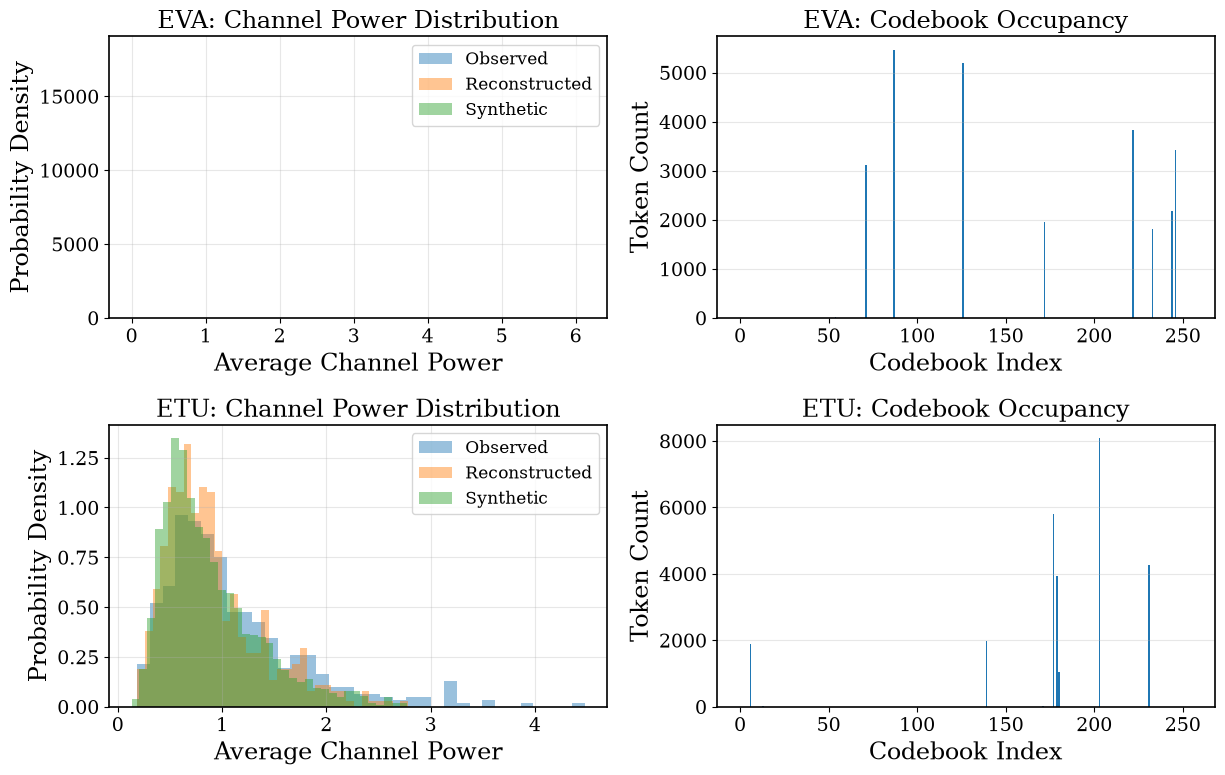


CELL 13B — FINAL SUMMARY
Runtime: 3.03 seconds
Summary: /home/afanali/wcnc_project/WCL_CDT_Revision/results/spatial_vqvae_diagnostics_summary.csv
Configuration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/spatial_vqvae_diagnostics_config.json
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/spatial_vqvae_diagnostics_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/spatial_vqvae_diagnostics_IEEE.png

CELL 13B VQ-VAE DIAGNOSTICS: PASS


In [ ]:

# ============================================================
# CELL 13B — SPATIAL VQ-VAE RECONSTRUCTION DIAGNOSTICS
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Diagnostics:
# 1. Saved checkpoint loading
# 2. Forward vs decoded-index consistency
# 3. Reconstruction NMSE
# 4. Input/reconstruction/synthetic power
# 5. Codebook occupancy and perplexity
# 6. Synthetic diversity and duplicate rate
# 7. IEEE-style diagnostic visualization
#
# No model retraining.
# No full-channel ground truth for generator validation.
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DB_CHANNELS = ["EVA", "ETU"]

DB_SNR_DB = 12.0
DB_N_VAL = 500
DB_N_SYN = 4000

DB_BATCH_SIZE = 128
DB_N_DIVERSITY_PAIRS = 2000

DB_EPS = 1e-12
DB_SEED = SEED + 2100

torch.manual_seed(DB_SEED)
torch.cuda.manual_seed_all(DB_SEED)
np.random.seed(DB_SEED)

DB_DEVICE = DEVICE

print("=" * 72)
print("CELL 13B — SPATIAL VQ-VAE DIAGNOSTICS")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("Validation samples:", DB_N_VAL)
print("Synthetic samples:", DB_N_SYN)
print("Channels:", DB_CHANNELS)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify dependencies from Cell 13A
# ------------------------------------------------------------

required = [
    "SPVQVAE",
    "sp_complex_to_channels",
    "sp_channels_to_complex",
    "da_generate_dataset",
    "CHECKPOINT_DIR",
    "RESULTS_DIR",
    "FIGURES_DIR",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing dependencies: {missing}. "
        "Run Cell 13A definitions first."
    )

# ------------------------------------------------------------
# 3. Helper: load saved VQ-VAE checkpoint
# ------------------------------------------------------------

def db_load_model(profile):

    checkpoint_path = (
        CHECKPOINT_DIR /
        f"spatial_vqvae_{profile.lower()}.pt"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing checkpoint: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DB_DEVICE,
        weights_only=True
    )

    model_vq = SPVQVAE(
        latent_dim=int(checkpoint["latent_dim"]),
        n_codes=int(checkpoint["codebook_size"])
    ).to(DB_DEVICE)

    model_vq.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model_vq.eval()

    return model_vq, checkpoint_path


# ------------------------------------------------------------
# 4. Forward vs decoded-index consistency
# ------------------------------------------------------------

@torch.no_grad()
def db_check_consistency(
    model_vq,
    pseudo_channels
):
    """
    Verify:
        model.forward(x).reconstruction
        ==
        model.decode_indices(model.encode(x))

    Both should use identical quantized embeddings.
    """

    x = sp_complex_to_channels(
        pseudo_channels
    )

    reconstruction, _, indices = model_vq(x)

    decoded = model_vq.decode_indices(
        indices
    )

    max_abs_error = float(
        (reconstruction - decoded)
        .abs().max().item()
    )

    mean_abs_error = float(
        (reconstruction - decoded)
        .abs().mean().item()
    )

    return (
        reconstruction,
        indices,
        max_abs_error,
        mean_abs_error
    )


# ------------------------------------------------------------
# 5. Reconstruction NMSE
# ------------------------------------------------------------

@torch.no_grad()
def db_reconstruction_nmse(
    observed,
    reconstructed
):

    H_recon = sp_channels_to_complex(
        reconstructed
    )

    numerator = (
        H_recon - observed
    ).abs().square().sum()

    denominator = (
        observed.abs().square().sum()
    ).clamp_min(DB_EPS)

    nmse = numerator / denominator

    return float(
        10.0 * torch.log10(
            nmse.clamp_min(DB_EPS)
        ).item()
    )


# ------------------------------------------------------------
# 6. Per-sample channel power
# ------------------------------------------------------------

@torch.no_grad()
def db_sample_power(H):

    return (
        H.abs().square()
        .mean(dim=(1, 2))
        .detach().cpu().numpy()
    )


# ------------------------------------------------------------
# 7. Codebook occupancy
# ------------------------------------------------------------

@torch.no_grad()
def db_codebook_stats(
    indices,
    codebook_size
):

    counts = torch.bincount(
        indices.reshape(-1),
        minlength=codebook_size
    ).float()

    probabilities = (
        counts / counts.sum().clamp_min(1)
    )

    used = int(
        (counts > 0).sum().item()
    )

    entropy = -(
        probabilities
        * torch.log(
            probabilities.clamp_min(DB_EPS)
        )
    ).sum()

    perplexity = float(
        torch.exp(entropy).item()
    )

    return {
        "counts": counts.detach().cpu().numpy(),
        "used_codes": used,
        "utilization": used / codebook_size,
        "perplexity": perplexity,
        "max_code_fraction": float(
            probabilities.max().item()
        )
    }


# ------------------------------------------------------------
# 8. Synthetic-channel diversity
# ------------------------------------------------------------

@torch.no_grad()
def db_diversity(H):

    N = len(H)

    idx1 = torch.randint(
        0, N,
        (DB_N_DIVERSITY_PAIRS,),
        device=DB_DEVICE
    )

    idx2 = torch.randint(
        0, N,
        (DB_N_DIVERSITY_PAIRS,),
        device=DB_DEVICE
    )

    A = H[idx1]
    B = H[idx2]

    numerator = (
        A - B
    ).abs().square().mean(dim=(1, 2))

    denominator = (
        A.abs().square().mean(dim=(1, 2))
        + B.abs().square().mean(dim=(1, 2))
    ).clamp_min(DB_EPS)

    distances = numerator / denominator

    return float(
        distances.mean().item()
    )


# ------------------------------------------------------------
# 9. Duplicate / near-duplicate diagnostic
# ------------------------------------------------------------

@torch.no_grad()
def db_duplicate_rate(
    H,
    decimals=4
):
    """
    Approximate duplicate rate using rounded
    channel vectors.

    This is a diagnostic, not a formal
    generative-diversity metric.
    """

    vectors = torch.cat(
        [
            H.real.reshape(len(H), -1),
            H.imag.reshape(len(H), -1)
        ],
        dim=1
    )

    vectors = (
        vectors.detach().cpu().numpy()
    )

    rounded = np.round(
        vectors,
        decimals=decimals
    )

    unique = np.unique(
        rounded,
        axis=0
    ).shape[0]

    duplicate_rate = (
        1.0 - unique / len(H)
    )

    return float(duplicate_rate)


# ------------------------------------------------------------
# 10. Run diagnostics for EVA and ETU
# ------------------------------------------------------------

DB_RESULTS = []
DB_PLOT_DATA = {}

for profile in DB_CHANNELS:

    print("\n" + "=" * 72)
    print(f"DIAGNOSTICS: {profile}")
    print("=" * 72)

    # Load saved best checkpoint
    model_vq, checkpoint_path = (
        db_load_model(profile)
    )

    # Generate independent receiver-observable
    # pseudo-target validation samples.
    _, pseudo_val, _ = da_generate_dataset(
        profile,
        DB_N_VAL,
        DB_SNR_DB
    )

    # Forward/index consistency
    (
        reconstruction,
        indices,
        max_error,
        mean_error
    ) = db_check_consistency(
        model_vq,
        pseudo_val
    )

    H_recon = sp_channels_to_complex(
        reconstruction
    )

    # Reconstruction NMSE relative to pseudo-targets
    reconstruction_nmse = (
        db_reconstruction_nmse(
            pseudo_val,
            reconstruction
        )
    )

    # Load synthetic channels saved by Cell 13A.
    synthetic_path = (
        RESULTS_DIR /
        f"spatial_synthetic_{profile.lower()}.pt"
    )

    if not synthetic_path.exists():
        raise FileNotFoundError(
            f"Missing synthetic data: {synthetic_path}"
        )

    H_syn = torch.load(
        synthetic_path,
        map_location=DB_DEVICE,
        weights_only=True
    )

    H_syn = H_syn[:DB_N_SYN]

    # Power distributions
    observed_power = db_sample_power(
        pseudo_val
    )

    reconstructed_power = db_sample_power(
        H_recon
    )

    synthetic_power = db_sample_power(
        H_syn
    )

    # Codebook diagnostics
    code_stats = db_codebook_stats(
        indices,
        model_vq.quantizer.n_codes
    )

    # Diversity
    observed_diversity = db_diversity(
        pseudo_val
    )

    reconstructed_diversity = db_diversity(
        H_recon
    )

    synthetic_diversity = db_diversity(
        H_syn
    )

    # Duplicate rate
    duplicate_rate = db_duplicate_rate(
        H_syn
    )

    DB_RESULTS.append({
        "Channel": profile,
        "Forward_Max_Error": max_error,
        "Forward_Mean_Error": mean_error,
        "Reconstruction_NMSE_dB":
            reconstruction_nmse,
        "Observed_Power":
            float(observed_power.mean()),
        "Reconstructed_Power":
            float(reconstructed_power.mean()),
        "Synthetic_Power":
            float(synthetic_power.mean()),
        "Used_Codes":
            code_stats["used_codes"],
        "Codebook_Utilization":
            code_stats["utilization"],
        "Perplexity":
            code_stats["perplexity"],
        "Largest_Code_Fraction":
            code_stats["max_code_fraction"],
        "Observed_Diversity":
            observed_diversity,
        "Reconstructed_Diversity":
            reconstructed_diversity,
        "Synthetic_Diversity":
            synthetic_diversity,
        "Synthetic_Duplicate_Rate":
            duplicate_rate
    })

    DB_PLOT_DATA[profile] = {
        "observed_power": observed_power,
        "reconstructed_power": reconstructed_power,
        "synthetic_power": synthetic_power,
        "code_counts": code_stats["counts"]
    }

    print("Checkpoint:", checkpoint_path)
    print("Forward max error:", max_error)
    print("Forward mean error:", mean_error)
    print("Reconstruction NMSE:",
          reconstruction_nmse, "dB")
    print("Observed power:",
          observed_power.mean())
    print("Reconstructed power:",
          reconstructed_power.mean())
    print("Synthetic power:",
          synthetic_power.mean())
    print("Used codes:",
          code_stats["used_codes"])
    print("Codebook utilization:",
          f"{100*code_stats['utilization']:.2f}%")
    print("Perplexity:",
          code_stats["perplexity"])
    print("Largest code fraction:",
          code_stats["max_code_fraction"])
    print("Synthetic duplicate rate:",
          duplicate_rate)


# ------------------------------------------------------------
# 11. Results summary
# ------------------------------------------------------------

DB_RESULTS_DF = pd.DataFrame(
    DB_RESULTS
)

print("\n" + "=" * 72)
print("CELL 13B — RECONSTRUCTION DIAGNOSTIC SUMMARY")
print("=" * 72)

print(
    DB_RESULTS_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ------------------------------------------------------------
# 12. IEEE-style diagnostic figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.4,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(12.5, 8.0)
)

for row, profile in enumerate(
    DB_CHANNELS
):

    data = DB_PLOT_DATA[profile]

    # --------------------------------------------------------
    # Power distribution
    # --------------------------------------------------------
    ax = axes[row, 0]

    ax.hist(
        data["observed_power"],
        bins=35,
        density=True,
        alpha=0.45,
        label="Observed"
    )

    ax.hist(
        data["reconstructed_power"],
        bins=35,
        density=True,
        alpha=0.45,
        label="Reconstructed"
    )

    ax.hist(
        data["synthetic_power"],
        bins=35,
        density=True,
        alpha=0.45,
        label="Synthetic"
    )

    ax.set_title(
        f"{profile}: Channel Power Distribution"
    )

    ax.set_xlabel(
        "Average Channel Power"
    )

    ax.set_ylabel(
        "Probability Density"
    )

    ax.grid(True, alpha=0.3)
    ax.legend()

    # --------------------------------------------------------
    # Codebook occupancy
    # --------------------------------------------------------
    ax = axes[row, 1]

    counts = data["code_counts"]

    ax.bar(
        np.arange(len(counts)),
        counts
    )

    ax.set_title(
        f"{profile}: Codebook Occupancy"
    )

    ax.set_xlabel(
        "Codebook Index"
    )

    ax.set_ylabel(
        "Token Count"
    )

    ax.grid(
        True,
        axis="y",
        alpha=0.3
    )

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "spatial_vqvae_diagnostics_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "spatial_vqvae_diagnostics_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 13. Save results
# ------------------------------------------------------------

summary_path = (
    RESULTS_DIR /
    "spatial_vqvae_diagnostics_summary.csv"
)

DB_RESULTS_DF.to_csv(
    summary_path,
    index=False
)

config_path = (
    RESULTS_DIR /
    "spatial_vqvae_diagnostics_config.json"
)

with open(config_path, "w") as f:

    json.dump({
        "snr_db": DB_SNR_DB,
        "validation_samples": DB_N_VAL,
        "synthetic_samples": DB_N_SYN,
        "channels": DB_CHANNELS,
        "checkpoint_source": "Cell 13A",
        "ground_truth_used_for_diagnostics": False
    }, f, indent=4)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 13B — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Summary:", summary_path)
print("Configuration:", config_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 13B VQ-VAE DIAGNOSTICS: PASS")


CELL 13C — FREQUENCY-PRESERVING EMA VQ-VAE
Device: cuda:0
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Training observations: 2000
Validation observations: 500
Synthetic channels: 4000
Latent grid: 18 x 14
Latent tokens per sample: 252
Codebook entries: 256
EMA decay: 0.99

EMA VQ-VAE SCENARIO: EVA

Training frequency-preserving EMA VQ-VAE...
Epoch 010/100 | Train=0.10056 | Val=0.11131 | Reinit=213
Epoch 020/100 | Train=0.03795 | Val=0.03807 | Reinit=0
Epoch 030/100 | Train=0.03384 | Val=0.03418 | Reinit=0
Epoch 040/100 | Train=0.03280 | Val=0.03302 | Reinit=0
Epoch 050/100 | Train=0.03205 | Val=0.03225 | Reinit=0
Epoch 060/100 | Train=0.03160 | Val=0.03174 | Reinit=0
Epoch 070/100 | Train=0.03117 | Val=0.03131 | Reinit=0
Epoch 080/100 | Train=0.03093 | Val=0.03104 | Reinit=0
Epoch 090/100 | Train=0.03074 | Val=0.03087 | Reinit=0
Epoch 100/100 | Train=0.03062 | Val=0.03076 | Reinit=0

[GENERATOR DIAGNOSTICS]
Best validation loss: 0.03076096111908555
Reconstruction NMSE: -12.781498432159424 

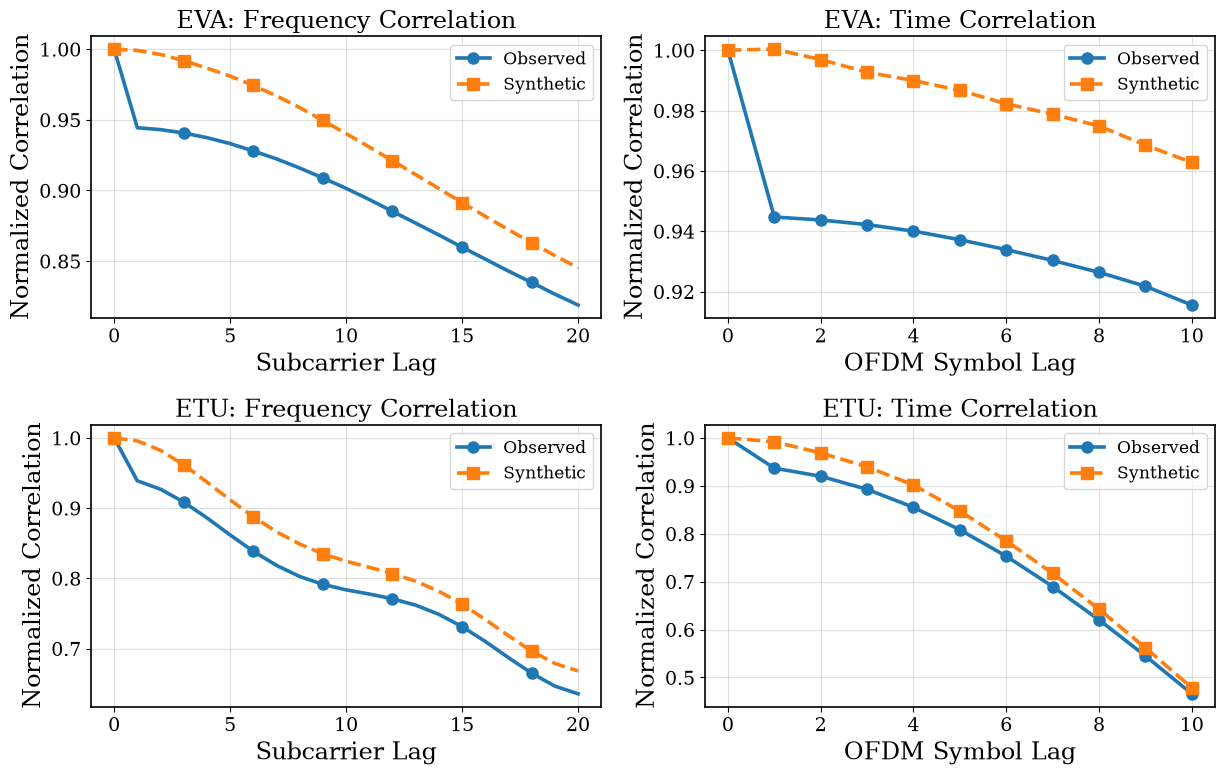


CELL 13C — FINAL SUMMARY
Runtime: 91.97 seconds
Summary: /home/afanali/wcnc_project/WCL_CDT_Revision/results/ema_vqvae_fidelity_summary.csv
Configuration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/ema_vqvae_config.json
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/ema_vqvae_fidelity_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/ema_vqvae_fidelity_IEEE.png

CELL 13C EMA VQ-VAE: PASS


In [ ]:

# ============================================================
# CELL 13C — FREQUENCY-PRESERVING EMA SPATIAL VQ-VAE
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Improvements:
#   1. Preserve all 14 OFDM symbols in latent grid
#   2. EMA-updated vector quantization
#   3. Data-driven codebook initialization
#   4. Dead-code reinitialization
#   5. Power and correlation regularization
#   6. Gradient clipping and LR scheduling
#   7. Best-checkpoint restoration
#   8. Channel fidelity and diversity diagnostics
#
# Ground-truth CSI is never used for:
#   - Generator training
#   - Codebook initialization
#   - Synthetic generation
#   - Checkpoint selection
#
# Ideal correct decoding is assumed.
# ============================================================

import copy
import json
import random
import time

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

C_SNR_DB = 12.0
C_CHANNELS = ["EVA", "ETU"]

C_N_TRAIN = 2000
C_N_VAL = 500
C_N_SYN = 4000

C_EPOCHS = 100
C_BATCH_SIZE = 64
C_LR = 2e-4
C_WEIGHT_DECAY = 1e-5

C_LATENT_DIM = 64
C_CODEBOOK_SIZE = 256
C_COMMITMENT = 0.25
C_EMA_DECAY = 0.99
C_EMA_EPS = 1e-5

C_DEAD_THRESHOLD = 0.5
C_REINIT_EVERY = 10

C_POWER_WEIGHT = 0.05
C_CORR_WEIGHT = 0.02

C_GRAD_CLIP = 1.0
C_PATIENCE = 25

C_SEED = SEED + 2200
C_DEVICE = DEVICE

random.seed(C_SEED)
np.random.seed(C_SEED)
torch.manual_seed(C_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(C_SEED)

# Disable autocast for stable codebook updates
C_USE_AMP = False

print("=" * 72)
print("CELL 13C — FREQUENCY-PRESERVING EMA VQ-VAE")
print("=" * 72)

print("Device:", C_DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Training observations:", C_N_TRAIN)
print("Validation observations:", C_N_VAL)
print("Synthetic channels:", C_N_SYN)
print("Latent grid: 18 x 14")
print("Latent tokens per sample:", 18 * 14)
print("Codebook entries:", C_CODEBOOK_SIZE)
print("EMA decay:", C_EMA_DECAY)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify dependencies
# ------------------------------------------------------------

required = [
    "da_generate_dataset",
    "sp_complex_to_channels",
    "sp_channels_to_complex",
    "sp_frequency_correlation",
    "sp_time_correlation",
    "sp_diversity_metric",
    "CHECKPOINT_DIR",
    "RESULTS_DIR",
    "FIGURES_DIR",
    "N_F",
    "N_S",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing definitions: {missing}. "
        "Run Cells 12 and 13A first."
    )

assert (N_F, N_S) == (72, 14)

# ------------------------------------------------------------
# 3. Frequency-preserving encoder / decoder
# ------------------------------------------------------------

class CFrequencyEncoder(nn.Module):

    def __init__(self, latent_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(
                2, 64, 3, padding=1
            ),
            nn.GELU(),

            nn.Conv2d(
                64, 96,
                kernel_size=(4, 3),
                stride=(2, 1),
                padding=(1, 1)
            ),
            nn.GELU(),

            nn.Conv2d(
                96, 128,
                kernel_size=(4, 3),
                stride=(2, 1),
                padding=(1, 1)
            ),
            nn.GELU(),

            nn.Conv2d(
                128, latent_dim,
                kernel_size=3,
                padding=1
            )
        )

    def forward(self, x):
        return self.network(x)


class CFrequencyDecoder(nn.Module):

    def __init__(self, latent_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(
                latent_dim, 128,
                kernel_size=3,
                padding=1
            ),
            nn.GELU(),

            nn.ConvTranspose2d(
                128, 96,
                kernel_size=(4, 3),
                stride=(2, 1),
                padding=(1, 1)
            ),
            nn.GELU(),

            nn.ConvTranspose2d(
                96, 64,
                kernel_size=(4, 3),
                stride=(2, 1),
                padding=(1, 1)
            ),
            nn.GELU(),

            nn.Conv2d(
                64, 2,
                kernel_size=3,
                padding=1
            )
        )

    def forward(self, z):
        x = self.network(z)
        assert x.shape[-2:] == (N_F, N_S)
        return x


# ------------------------------------------------------------
# 4. EMA vector quantizer
# ------------------------------------------------------------

class CEMAVectorQuantizer(nn.Module):

    def __init__(
        self,
        n_codes,
        dim,
        decay=0.99,
        eps=1e-5,
        commitment=0.25
    ):
        super().__init__()

        self.n_codes = n_codes
        self.dim = dim
        self.decay = decay
        self.eps = eps
        self.commitment = commitment

        self.register_buffer(
            "embedding",
            torch.randn(n_codes, dim) * 0.02
        )

        self.register_buffer(
            "ema_count",
            torch.ones(n_codes)
        )

        self.register_buffer(
            "ema_sum",
            self.embedding.clone()
        )

        self.initialized = False

    @torch.no_grad()
    def initialize_from_data(self, z):

        flat = z.permute(
            0, 2, 3, 1
        ).reshape(-1, self.dim)

        indices = torch.randperm(
            flat.shape[0],
            device=flat.device
        )[:self.n_codes]

        samples = flat[indices].clone()

        if len(samples) < self.n_codes:
            raise RuntimeError(
                "Insufficient latent vectors "
                "for codebook initialization."
            )

        self.embedding.copy_(samples)
        self.ema_sum.copy_(samples)
        self.ema_count.fill_(1.0)

        self.initialized = True

    def forward(self, z):

        B, C, H, W = z.shape

        flat = z.permute(
            0, 2, 3, 1
        ).reshape(-1, C)

        distances = (
            flat.square().sum(1, keepdim=True)
            - 2.0 * flat @ self.embedding.T
            + self.embedding.square().sum(1)
        )

        indices = distances.argmin(dim=1)

        quantized = F.embedding(
            indices,
            self.embedding
        )

        if self.training:

            with torch.no_grad():

                counts = torch.bincount(
                    indices,
                    minlength=self.n_codes
                ).float()

                sums = torch.zeros_like(
                    self.ema_sum
                )

                sums.index_add_(
                    0,
                    indices,
                    flat.detach()
                )

                self.ema_count.mul_(
                    self.decay
                ).add_(
                    counts,
                    alpha=1.0 - self.decay
                )

                self.ema_sum.mul_(
                    self.decay
                ).add_(
                    sums,
                    alpha=1.0 - self.decay
                )

                # Laplace smoothing
                total = self.ema_count.sum()

                smoothed = (
                    (self.ema_count + self.eps)
                    / (
                        total
                        + self.n_codes * self.eps
                    )
                    * total
                )

                self.embedding.copy_(
                    self.ema_sum
                    / smoothed.unsqueeze(1)
                )

        quantized_map = quantized.reshape(
            B, H, W, C
        ).permute(0, 3, 1, 2).contiguous()

        commitment_loss = F.mse_loss(
            z,
            quantized_map.detach()
        ) * self.commitment

        z_st = (
            z + (
                quantized_map - z
            ).detach()
        )

        return (
            z_st,
            commitment_loss,
            indices.reshape(B, H, W)
        )

    @torch.no_grad()
    def reinitialize_dead_codes(
        self,
        latent_vectors,
        threshold=0.5
    ):

        dead = (
            self.ema_count < threshold
        ).nonzero(
            as_tuple=False
        ).flatten()

        if len(dead) == 0:
            return 0

        flat = latent_vectors.permute(
            0, 2, 3, 1
        ).reshape(-1, self.dim)

        selected = torch.randint(
            0,
            flat.shape[0],
            (len(dead),),
            device=flat.device
        )

        new_vectors = flat[selected]

        self.embedding[dead] = new_vectors
        self.ema_sum[dead] = new_vectors
        self.ema_count[dead] = 1.0

        return int(len(dead))


# ------------------------------------------------------------
# 5. Frequency-preserving VQ-VAE
# ------------------------------------------------------------

class CSpatialEMAVQVAE(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = CFrequencyEncoder(
            C_LATENT_DIM
        )

        self.quantizer = CEMAVectorQuantizer(
            C_CODEBOOK_SIZE,
            C_LATENT_DIM,
            decay=C_EMA_DECAY,
            eps=C_EMA_EPS,
            commitment=C_COMMITMENT
        )

        self.decoder = CFrequencyDecoder(
            C_LATENT_DIM
        )

    def forward(self, x):

        z = self.encoder(x)

        z_q, commitment, indices = (
            self.quantizer(z)
        )

        reconstruction = self.decoder(z_q)

        return (
            reconstruction,
            commitment,
            indices
        )

    @torch.no_grad()
    def encode_indices(self, x):

        z = self.encoder(x)

        B, C, H, W = z.shape

        flat = z.permute(
            0, 2, 3, 1
        ).reshape(-1, C)

        distances = (
            flat.square().sum(1, keepdim=True)
            - 2.0 * flat @
              self.quantizer.embedding.T
            + self.quantizer.embedding.square().sum(1)
        )

        return distances.argmin(1).reshape(
            B, H, W
        )

    @torch.no_grad()
    def decode_indices(self, indices):

        z = F.embedding(
            indices,
            self.quantizer.embedding
        )

        z = z.permute(
            0, 3, 1, 2
        ).contiguous()

        return self.decoder(z)


# ------------------------------------------------------------
# 6. Power and correlation regularization
# ------------------------------------------------------------

def c_power_loss(recon, target):

    p_recon = recon.square().sum(
        dim=1
    ).mean()

    p_target = target.square().sum(
        dim=1
    ).mean()

    return (
        (p_recon - p_target)
        / p_target.clamp_min(1e-8)
    ).square()


def c_corr_loss(recon, target):

    H_r = torch.complex(
        recon[:, 0],
        recon[:, 1]
    )

    H_t = torch.complex(
        target[:, 0],
        target[:, 1]
    )

    loss = 0.0

    for lag in [1, 3, 5]:

        rf = (
            H_r[:, lag:, :]
            * H_r[:, :-lag, :].conj()
        ).mean()

        tf = (
            H_t[:, lag:, :]
            * H_t[:, :-lag, :].conj()
        ).mean()

        rt = (
            H_r[:, :, lag:]
            * H_r[:, :, :-lag].conj()
        ).mean()

        tt = (
            H_t[:, :, lag:]
            * H_t[:, :, :-lag].conj()
        ).mean()

        loss = (
            loss
            + (rf - tf).abs().square()
            + (rt - tt).abs().square()
        )

    return loss / 6.0


def c_total_loss(recon, target, commitment):

    reconstruction = F.mse_loss(
        recon, target
    )

    power = c_power_loss(
        recon, target
    )

    correlation = c_corr_loss(
        recon, target
    )

    total = (
        reconstruction
        + C_POWER_WEIGHT * power
        + C_CORR_WEIGHT * correlation
        + commitment
    )

    return total, reconstruction, power, correlation


# ------------------------------------------------------------
# 7. Train EMA VQ-VAE
# ------------------------------------------------------------

def c_train_model(train_pseudo, val_pseudo):

    x_train = sp_complex_to_channels(
        train_pseudo
    )

    x_val = sp_complex_to_channels(
        val_pseudo
    )

    generator = CSpatialEMAVQVAE().to(
        C_DEVICE
    )

    # Data-driven initialization
    generator.eval()

    with torch.no_grad():
        z_init = generator.encoder(
            x_train[:C_BATCH_SIZE]
        )

        generator.quantizer.initialize_from_data(
            z_init
        )

    optimizer = torch.optim.AdamW(
        list(generator.encoder.parameters())
        + list(generator.decoder.parameters()),
        lr=C_LR,
        weight_decay=C_WEIGHT_DECAY
    )

    scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=C_EPOCHS,
            eta_min=1e-5
        )
    )

    best_val = float("inf")
    best_state = None
    no_improvement = 0

    history = []

    for epoch in range(C_EPOCHS):

        generator.train()

        permutation = torch.randperm(
            len(x_train),
            device=C_DEVICE
        )

        train_losses = []

        for start in range(
            0,
            len(x_train),
            C_BATCH_SIZE
        ):

            idx = permutation[
                start:start + C_BATCH_SIZE
            ]

            batch = x_train[idx]

            optimizer.zero_grad(
                set_to_none=True
            )

            recon, commitment, _ = (
                generator(batch)
            )

            total, rec, power, corr = (
                c_total_loss(
                    recon,
                    batch,
                    commitment
                )
            )

            total.backward()

            torch.nn.utils.clip_grad_norm_(
                generator.parameters(),
                C_GRAD_CLIP
            )

            optimizer.step()

            train_losses.append(
                total.item()
            )

        # Dead-code recovery
        dead_reinitialized = 0

        if (epoch + 1) % C_REINIT_EVERY == 0:

            generator.eval()

            with torch.no_grad():
                z = generator.encoder(
                    x_train[:C_BATCH_SIZE]
                )

                dead_reinitialized = (
                    generator.quantizer
                    .reinitialize_dead_codes(
                        z,
                        C_DEAD_THRESHOLD
                    )
                )

        # Validation
        generator.eval()

        val_losses = []

        with torch.no_grad():

            for start in range(
                0,
                len(x_val),
                C_BATCH_SIZE
            ):

                batch = x_val[
                    start:start + C_BATCH_SIZE
                ]

                recon, commitment, _ = (
                    generator(batch)
                )

                total, _, _, _ = (
                    c_total_loss(
                        recon,
                        batch,
                        commitment
                    )
                )

                val_losses.append(
                    total.item()
                )

        train_loss = float(
            np.mean(train_losses)
        )

        val_loss = float(
            np.mean(val_losses)
        )

        history.append({
            "Epoch": epoch + 1,
            "Train_Loss": train_loss,
            "Val_Loss": val_loss,
            "Dead_Reinitialized":
                dead_reinitialized,
            "LR": optimizer.param_groups[0]["lr"]
        })

        if val_loss < best_val - 1e-6:

            best_val = val_loss
            best_state = copy.deepcopy(
                generator.state_dict()
            )

            no_improvement = 0

        else:
            no_improvement += 1

        scheduler.step()

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch {epoch+1:03d}/{C_EPOCHS} | "
                f"Train={train_loss:.5f} | "
                f"Val={val_loss:.5f} | "
                f"Reinit={dead_reinitialized}"
            )

        if no_improvement >= C_PATIENCE:

            print(
                f"Early stopping at epoch {epoch+1}"
            )
            break

    generator.load_state_dict(
        best_state
    )

    generator.eval()

    return (
        generator,
        pd.DataFrame(history),
        best_val
    )


# ------------------------------------------------------------
# 8. Codebook statistics
# ------------------------------------------------------------

@torch.no_grad()
def c_codebook_statistics(generator, H):

    x = sp_complex_to_channels(H)

    all_indices = []

    for start in range(
        0, len(x), C_BATCH_SIZE
    ):

        indices = generator.encode_indices(
            x[start:start+C_BATCH_SIZE]
        )

        all_indices.append(indices)

    indices = torch.cat(
        all_indices,
        dim=0
    )

    counts = torch.bincount(
        indices.reshape(-1),
        minlength=C_CODEBOOK_SIZE
    ).float()

    probabilities = (
        counts / counts.sum().clamp_min(1)
    )

    used = int(
        (counts > 0).sum().item()
    )

    entropy = -(
        probabilities
        * torch.log(
            probabilities.clamp_min(1e-12)
        )
    ).sum()

    perplexity = float(
        torch.exp(entropy).item()
    )

    return {
        "used": used,
        "utilization": used / C_CODEBOOK_SIZE,
        "perplexity": perplexity,
        "indices": indices
    }


# ------------------------------------------------------------
# 9. Generate synthetic channels
# ------------------------------------------------------------

@torch.no_grad()
def c_generate_synthetic(
    generator,
    pseudo_train,
    n_samples=C_N_SYN
):

    x = sp_complex_to_channels(
        pseudo_train
    )

    latent_maps = []

    for start in range(
        0, len(x), C_BATCH_SIZE
    ):

        indices = generator.encode_indices(
            x[start:start+C_BATCH_SIZE]
        )

        latent_maps.append(indices)

    latent_maps = torch.cat(
        latent_maps,
        dim=0
    )

    outputs = []

    for start in range(
        0, n_samples,
        C_BATCH_SIZE
    ):

        B = min(
            C_BATCH_SIZE,
            n_samples-start
        )

        selected = torch.randint(
            0,
            len(latent_maps),
            (B,),
            device=C_DEVICE
        )

        indices = latent_maps[selected]

        decoded = generator.decode_indices(
            indices
        )

        outputs.append(
            sp_channels_to_complex(decoded)
        )

    return torch.cat(
        outputs,
        dim=0
    )


# ------------------------------------------------------------
# 10. Reconstruction and fidelity metrics
# ------------------------------------------------------------

@torch.no_grad()
def c_reconstruction_nmse(generator, H):

    x = sp_complex_to_channels(H)

    recon, _, _ = generator(x)

    H_recon = sp_channels_to_complex(
        recon
    )

    numerator = (
        H_recon-H
    ).abs().square().sum()

    denominator = (
        H.abs().square().sum()
    ).clamp_min(1e-12)

    return float(
        10 * torch.log10(
            numerator / denominator
        ).item()
    )


def c_relative_error(a, b):

    return float(
        np.linalg.norm(a-b)
        / max(np.linalg.norm(a), 1e-12)
    )


# ------------------------------------------------------------
# 11. Run experiments
# ------------------------------------------------------------

C_RESULTS = []
C_CURVES = {}
C_HISTORIES = {}

for profile in C_CHANNELS:

    print("\n" + "=" * 72)
    print(f"EMA VQ-VAE SCENARIO: {profile}")
    print("=" * 72)

    # Receiver-side pseudo-targets
    _, pseudo_train, _ = da_generate_dataset(
        profile,
        C_N_TRAIN,
        C_SNR_DB
    )

    _, pseudo_val, _ = da_generate_dataset(
        profile,
        C_N_VAL,
        C_SNR_DB
    )

    print("\nTraining frequency-preserving EMA VQ-VAE...")

    generator, history, best_val = (
        c_train_model(
            pseudo_train,
            pseudo_val
        )
    )

    C_HISTORIES[profile] = history

    # Reconstruction
    reconstruction_nmse = (
        c_reconstruction_nmse(
            generator,
            pseudo_val
        )
    )

    # Codebook
    stats = c_codebook_statistics(
        generator,
        pseudo_val
    )

    # Synthetic channels
    H_syn = c_generate_synthetic(
        generator,
        pseudo_train
    )

    # Channel power
    observed_power = float(
        pseudo_val.abs().square().mean().item()
    )

    synthetic_power = float(
        H_syn.abs().square().mean().item()
    )

    # Diversity
    observed_diversity = sp_diversity_metric(
        pseudo_val
    )

    synthetic_diversity = sp_diversity_metric(
        H_syn
    )

    # Correlation
    freq_obs = sp_frequency_correlation(
        pseudo_val
    )

    freq_syn = sp_frequency_correlation(
        H_syn
    )

    time_obs = sp_time_correlation(
        pseudo_val
    )

    time_syn = sp_time_correlation(
        H_syn
    )

    freq_error = c_relative_error(
        freq_obs,
        freq_syn
    )

    time_error = c_relative_error(
        time_obs,
        time_syn
    )

    C_RESULTS.append({
        "Channel": profile,
        "Best_Val_Loss": best_val,
        "Reconstruction_NMSE_dB":
            reconstruction_nmse,
        "Used_Codes": stats["used"],
        "Codebook_Utilization":
            stats["utilization"],
        "Perplexity":
            stats["perplexity"],
        "Observed_Power":
            observed_power,
        "Synthetic_Power":
            synthetic_power,
        "Observed_Diversity":
            observed_diversity,
        "Synthetic_Diversity":
            synthetic_diversity,
        "Frequency_Corr_Error":
            freq_error,
        "Time_Corr_Error":
            time_error
    })

    C_CURVES[profile] = {
        "freq_obs": freq_obs,
        "freq_syn": freq_syn,
        "time_obs": time_obs,
        "time_syn": time_syn
    }

    # Save checkpoint
    torch.save(
        {
            "model_state_dict":
                generator.state_dict(),
            "latent_dim": C_LATENT_DIM,
            "codebook_size": C_CODEBOOK_SIZE,
            "snr_db": C_SNR_DB,
            "channel": profile,
            "architecture":
                "frequency_preserving_ema_vqvae"
        },
        CHECKPOINT_DIR /
        f"ema_spatial_vqvae_{profile.lower()}.pt"
    )

    # Save synthetic channels
    torch.save(
        H_syn.detach().cpu(),
        RESULTS_DIR /
        f"ema_synthetic_{profile.lower()}.pt"
    )

    history.to_csv(
        RESULTS_DIR /
        f"ema_vqvae_history_{profile.lower()}.csv",
        index=False
    )

    print("\n[GENERATOR DIAGNOSTICS]")
    print("Best validation loss:", best_val)
    print("Reconstruction NMSE:",
          reconstruction_nmse, "dB")
    print("Used codes:", stats["used"])
    print("Codebook utilization:",
          f"{100*stats['utilization']:.2f}%")
    print("Perplexity:", stats["perplexity"])
    print("Observed power:", observed_power)
    print("Synthetic power:", synthetic_power)
    print("Observed diversity:", observed_diversity)
    print("Synthetic diversity:", synthetic_diversity)
    print("Frequency correlation error:", freq_error)
    print("Time correlation error:", time_error)


# ------------------------------------------------------------
# 12. Results summary
# ------------------------------------------------------------

C_RESULTS_DF = pd.DataFrame(
    C_RESULTS
)

print("\n" + "=" * 72)
print("CELL 13C — EMA VQ-VAE FIDELITY SUMMARY")
print("=" * 72)

print(
    C_RESULTS_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}"
    )
)


# ------------------------------------------------------------
# 13. IEEE-style comparison figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.6,
    "lines.markersize": 8,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(12.5, 8.0)
)

for row, profile in enumerate(
    C_CHANNELS
):

    curves = C_CURVES[profile]

    ax = axes[row, 0]

    ax.plot(
        curves["freq_obs"],
        marker="o",
        markevery=3,
        label="Observed"
    )

    ax.plot(
        curves["freq_syn"],
        marker="s",
        markevery=3,
        linestyle="--",
        label="Synthetic"
    )

    ax.set_title(
        f"{profile}: Frequency Correlation"
    )

    ax.set_xlabel(
        "Subcarrier Lag"
    )

    ax.set_ylabel(
        "Normalized Correlation"
    )

    ax.grid(True, alpha=0.4)
    ax.legend()

    ax = axes[row, 1]

    ax.plot(
        curves["time_obs"],
        marker="o",
        label="Observed"
    )

    ax.plot(
        curves["time_syn"],
        marker="s",
        linestyle="--",
        label="Synthetic"
    )

    ax.set_title(
        f"{profile}: Time Correlation"
    )

    ax.set_xlabel(
        "OFDM Symbol Lag"
    )

    ax.set_ylabel(
        "Normalized Correlation"
    )

    ax.grid(True, alpha=0.4)
    ax.legend()

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "ema_vqvae_fidelity_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "ema_vqvae_fidelity_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 14. Save results and configuration
# ------------------------------------------------------------

summary_path = (
    RESULTS_DIR /
    "ema_vqvae_fidelity_summary.csv"
)

C_RESULTS_DF.to_csv(
    summary_path,
    index=False
)

config_path = (
    RESULTS_DIR /
    "ema_vqvae_config.json"
)

with open(config_path, "w") as f:

    json.dump({
        "snr_db": C_SNR_DB,
        "train_samples": C_N_TRAIN,
        "validation_samples": C_N_VAL,
        "synthetic_samples": C_N_SYN,
        "epochs": C_EPOCHS,
        "latent_grid": [18, 14],
        "latent_dimension": C_LATENT_DIM,
        "codebook_size": C_CODEBOOK_SIZE,
        "ema_decay": C_EMA_DECAY,
        "commitment": C_COMMITMENT,
        "power_weight": C_POWER_WEIGHT,
        "correlation_weight": C_CORR_WEIGHT,
        "generation_method":
            "complete_latent_map_resampling",
        "correct_decoding_assumed": True,
        "ground_truth_used_for_training": False
    }, f, indent=4)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 13C — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Summary:", summary_path)
print("Configuration:", config_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 13C EMA VQ-VAE: PASS")


CELL 14 — GENERATIVE RETIRE REPLACEMENT
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Synthetic channels: 4000
Replacement epochs: 80
Validation observations: 500
Offline evaluation observations: 2000

RETIRE SCENARIO: EVA

[UPDATE]
Accepted: True
Baseline validation: 0.16862662136554718
Updated validation: 0.14350077509880066

Training scratch replacement...
  scratch Epoch 010/80 | Train=0.019555 | Val=0.019852
  scratch Epoch 020/80 | Train=0.017315 | Val=0.018252
  scratch Epoch 030/80 | Train=0.015432 | Val=0.017465
  scratch Epoch 040/80 | Train=0.015055 | Val=0.016804
  scratch Epoch 050/80 | Train=0.014827 | Val=0.016798
  scratch Epoch 060/80 | Train=0.014545 | Val=0.016648
  scratch Epoch 070/80 | Train=0.014518 | Val=0.016603
  scratch Epoch 080/80 | Train=0.014417 | Val=0.016597

Training warm-start replacement...
  warm    Epoch 010/80 | Train=0.020030 | Val=0.020141
  warm    Epoch 020/80 | Train=0.018551 | Val=0.018970
  warm    Epoch 030/80 | Train=0.015859 | Val

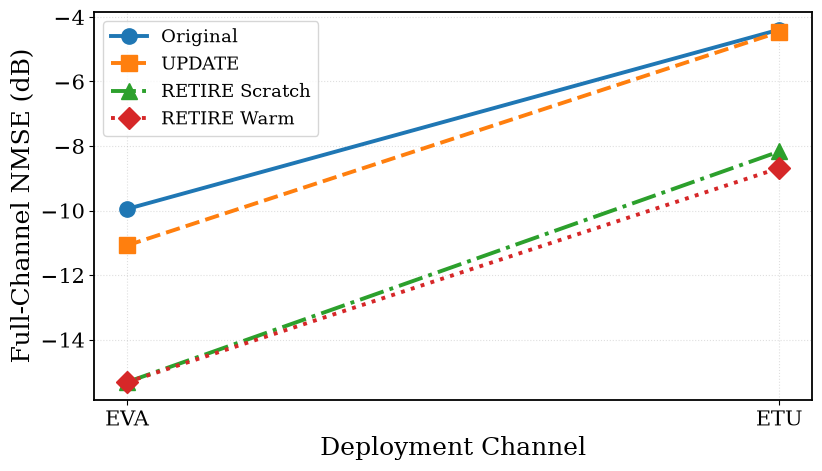


CELL 14 — FINAL SUMMARY
Runtime: 18.19 seconds
Results: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_update_vs_retire_results.csv
Configuration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_update_vs_retire_config.json
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_update_vs_retire_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_update_vs_retire_IEEE.png

CELL 14 RETIRE REPLACEMENT: PASS


In [ ]:

# ============================================================
# CELL 14 — GENERATIVE RETIRE REPLACEMENT AND VALIDATION
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Compares:
#   1. Original EPA-trained FCN
#   2. Ground-truth-free UPDATE (Cell 12)
#   3. Scratch-trained RETIRE FCN
#   4. Warm-started RETIRE FCN
#
# Replacement training:
#   Synthetic channels from Cell 13C EMA VQ-VAE.
#
# Deployment validation:
#   Receiver-side data-aided pseudo-targets only.
#
# Ground-truth CSI:
#   Used ONLY for offline NMSE evaluation.
#
# Does not automatically deploy a failed candidate.
# ============================================================

import copy
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from pathlib import Path

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

R14_SNR_DB = 12.0
R14_CHANNELS = ["EVA", "ETU"]

R14_N_UPDATE = 100
R14_N_UPDATE_TRAIN = 80
R14_N_UPDATE_VAL = 20

R14_N_SYN = 4000
R14_N_VAL = 500
R14_N_TEST = 2000

R14_EPOCHS = 80
R14_BATCH_SIZE = 128

R14_LR_SCRATCH = 5e-4
R14_LR_WARM = 1e-4

R14_WEIGHT_DECAY = 1e-5
R14_PATIENCE = 15

R14_SEED = SEED + 2300
R14_DEVICE = DEVICE

random.seed(R14_SEED)
np.random.seed(R14_SEED)
torch.manual_seed(R14_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(R14_SEED)

print("=" * 72)
print("CELL 14 — GENERATIVE RETIRE REPLACEMENT")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", R14_SNR_DB, "dB")
print("Synthetic channels:", R14_N_SYN)
print("Replacement epochs:", R14_EPOCHS)
print("Validation observations:", R14_N_VAL)
print("Offline evaluation observations:", R14_N_TEST)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify required functions
# ------------------------------------------------------------

required = [
    "DA_BASELINE",
    "da_generate_dataset",
    "da_finetune",
    "da_nmse_db",
    "da_pseudo_loss",
    "da_vector_to_complex",
    "ret_make_training_pairs",
    "ret_ls_fallback",
    "ChannelEstimatorFCN",
    "CHECKPOINT_DIR",
    "RESULTS_DIR",
    "FIGURES_DIR",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing dependencies: {missing}. "
        "Run Cells 12 and 13 first."
    )

# ------------------------------------------------------------
# 3. Load synthetic channels from Cell 13C
# ------------------------------------------------------------

def r14_load_synthetic(profile):

    path = (
        RESULTS_DIR /
        f"ema_synthetic_{profile.lower()}.pt"
    )

    if not path.exists():
        raise FileNotFoundError(
            f"Missing synthetic channels: {path}"
        )

    H_syn = torch.load(
        path,
        map_location=R14_DEVICE,
        weights_only=True
    )

    if len(H_syn) < R14_N_SYN:
        raise RuntimeError(
            "Insufficient synthetic channels."
        )

    H_syn = H_syn[:R14_N_SYN]

    assert H_syn.shape[1:] == (
        N_F, N_S
    )

    return H_syn


# ------------------------------------------------------------
# 4. Train replacement FCN
# ------------------------------------------------------------

def r14_train_replacement(
    train_inputs,
    train_targets,
    initialization="scratch"
):

    if initialization == "scratch":

        estimator = ChannelEstimatorFCN().to(
            R14_DEVICE
        )

        learning_rate = R14_LR_SCRATCH

    elif initialization == "warm":

        estimator = copy.deepcopy(
            DA_BASELINE
        ).to(R14_DEVICE)

        learning_rate = R14_LR_WARM

    else:
        raise ValueError(initialization)

    for p in estimator.parameters():
        p.requires_grad_(True)

    optimizer = torch.optim.Adam(
        estimator.parameters(),
        lr=learning_rate,
        weight_decay=R14_WEIGHT_DECAY
    )

    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=5
        )
    )

    # Synthetic validation split
    N = len(train_inputs)

    permutation = torch.randperm(
        N,
        device=R14_DEVICE
    )

    N_train = int(0.9 * N)

    train_idx = permutation[:N_train]
    val_idx = permutation[N_train:]

    x_train = train_inputs[train_idx]
    y_train = train_targets[train_idx]

    x_val = train_inputs[val_idx]
    y_val = train_targets[val_idx]

    best_val = float("inf")
    best_state = None

    patience_counter = 0
    history = []

    for epoch in range(R14_EPOCHS):

        estimator.train()

        indices = torch.randperm(
            len(x_train),
            device=R14_DEVICE
        )

        losses = []

        for start in range(
            0,
            len(x_train),
            R14_BATCH_SIZE
        ):

            idx = indices[
                start:start + R14_BATCH_SIZE
            ]

            x_batch = x_train[idx]
            y_batch = y_train[idx]

            optimizer.zero_grad(
                set_to_none=True
            )

            prediction = estimator(
                x_batch
            )

            loss = F.mse_loss(
                prediction,
                y_batch
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                estimator.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            losses.append(
                loss.item()
            )

        estimator.eval()

        with torch.no_grad():

            val_prediction = estimator(
                x_val
            )

            val_loss = F.mse_loss(
                val_prediction,
                y_val
            ).item()

        scheduler.step(val_loss)

        train_loss = float(
            np.mean(losses)
        )

        history.append({
            "Epoch": epoch + 1,
            "Train_MSE": train_loss,
            "Val_MSE": val_loss
        })

        if val_loss < best_val - 1e-7:

            best_val = val_loss

            best_state = copy.deepcopy(
                estimator.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if (epoch + 1) % 10 == 0:

            print(
                f"  {initialization:7s} "
                f"Epoch {epoch+1:03d}/{R14_EPOCHS} | "
                f"Train={train_loss:.6f} | "
                f"Val={val_loss:.6f}"
            )

        if patience_counter >= R14_PATIENCE:

            print(
                f"  {initialization}: early stopping "
                f"at epoch {epoch+1}"
            )
            break

    estimator.load_state_dict(
        best_state
    )

    estimator.eval()

    return (
        estimator,
        pd.DataFrame(history),
        best_val
    )


# ------------------------------------------------------------
# 5. Receiver-side validation
# ------------------------------------------------------------

@torch.no_grad()
def r14_validation_loss(
    estimator,
    h_p,
    pseudo
):

    estimator.eval()

    return float(
        da_pseudo_loss(
            estimator,
            h_p,
            pseudo
        ).item()
    )


# ------------------------------------------------------------
# 6. Run experiments
# ------------------------------------------------------------

R14_RESULTS = []
R14_HISTORIES = {}

for profile in R14_CHANNELS:

    print("\n" + "=" * 72)
    print(f"RETIRE SCENARIO: {profile}")
    print("=" * 72)

    # --------------------------------------------
    # A. Load synthetic channel samples
    # --------------------------------------------
    H_syn = r14_load_synthetic(
        profile
    )

    syn_inputs, syn_targets = (
        ret_make_training_pairs(
            H_syn,
            R14_SNR_DB
        )
    )

    # --------------------------------------------
    # B. UPDATE baseline
    # --------------------------------------------
    h_update, pseudo_update, _ = (
        da_generate_dataset(
            profile,
            R14_N_UPDATE
        )
    )

    (
        updated_model,
        update_accepted,
        update_baseline_val,
        update_best_val,
        update_history
    ) = da_finetune(
        DA_BASELINE,
        h_update[:R14_N_UPDATE_TRAIN],
        pseudo_update[:R14_N_UPDATE_TRAIN],
        h_update[R14_N_UPDATE_TRAIN:],
        pseudo_update[R14_N_UPDATE_TRAIN:]
    )

    print("\n[UPDATE]")
    print("Accepted:", update_accepted)
    print("Baseline validation:", update_baseline_val)
    print("Updated validation:", update_best_val)

    # --------------------------------------------
    # C. Independent deployment validation
    # --------------------------------------------
    h_val, pseudo_val, _ = (
        da_generate_dataset(
            profile,
            R14_N_VAL
        )
    )

    # --------------------------------------------
    # D. Independent offline evaluation
    # --------------------------------------------
    h_test, _, H_test = (
        da_generate_dataset(
            profile,
            R14_N_TEST
        )
    )

    # --------------------------------------------
    # E. Train scratch replacement
    # --------------------------------------------
    print("\nTraining scratch replacement...")

    scratch_model, scratch_history, _ = (
        r14_train_replacement(
            syn_inputs,
            syn_targets,
            initialization="scratch"
        )
    )

    # --------------------------------------------
    # F. Train warm-start replacement
    # --------------------------------------------
    print("\nTraining warm-start replacement...")

    warm_model, warm_history, _ = (
        r14_train_replacement(
            syn_inputs,
            syn_targets,
            initialization="warm"
        )
    )

    R14_HISTORIES[profile] = {
        "scratch": scratch_history,
        "warm": warm_history,
        "update": update_history
    }

    # --------------------------------------------
    # G. Compare all estimators
    # --------------------------------------------
    estimators = {
        "Original": DA_BASELINE,
        "UPDATE": updated_model,
        "RETIRE_Scratch": scratch_model,
        "RETIRE_Warm": warm_model,
    }

    validation_losses = {}

    nmse_results = {}

    for name, estimator in estimators.items():

        validation_losses[name] = (
            r14_validation_loss(
                estimator,
                h_val,
                pseudo_val
            )
        )

        nmse_results[name] = (
            da_nmse_db(
                estimator,
                h_test,
                H_test
            )
        )

    # LS fallback validation
    with torch.no_grad():

        H_ls = ret_ls_fallback(
            h_val
        )

        ls_validation_loss = (
            H_ls[:, DA_DATA_MASK]
            - pseudo_val[:, DA_DATA_MASK]
        ).abs().square().mean().item()

    # --------------------------------------------
    # H. Verify-before-deploy selection
    # --------------------------------------------
    serving_model_name = (
        "UPDATE"
        if update_accepted
        else "Original"
    )

    serving_loss = validation_losses[
        serving_model_name
    ]

    candidates = [
        "RETIRE_Scratch",
        "RETIRE_Warm"
    ]

    best_candidate = min(
        candidates,
        key=lambda name: validation_losses[name]
    )

    best_candidate_loss = validation_losses[
        best_candidate
    ]

    replacement_accepted = (
        best_candidate_loss < serving_loss
        and best_candidate_loss < ls_validation_loss
    )

    if replacement_accepted:
        selected_model = best_candidate
    else:
        selected_model = serving_model_name

    print("\n[VALIDATION]")
    for name, value in validation_losses.items():
        print(f"{name:16s}: {value:.6f}")

    print("LS fallback:", ls_validation_loss)
    print("Serving model:", serving_model_name)
    print("Best replacement:", best_candidate)
    print("Replacement accepted:", replacement_accepted)
    print("Selected model:", selected_model)

    print("\n[OFFLINE NMSE]")
    for name, value in nmse_results.items():
        print(f"{name:16s}: {value:.3f} dB")

    # --------------------------------------------
    # I. Save results
    # --------------------------------------------
    for name in estimators:

        R14_RESULTS.append({
            "Channel": profile,
            "Estimator": name,
            "Validation_Loss":
                validation_losses[name],
            "NMSE_dB":
                nmse_results[name],
            "Serving_Model":
                serving_model_name,
            "Best_Replacement":
                best_candidate,
            "Replacement_Accepted":
                replacement_accepted,
            "Selected_Model":
                selected_model,
            "LS_Validation_Loss":
                ls_validation_loss
        })

    # Save replacement checkpoints
    torch.save(
        scratch_model.state_dict(),
        CHECKPOINT_DIR /
        f"retire_scratch_{profile.lower()}.pt"
    )

    torch.save(
        warm_model.state_dict(),
        CHECKPOINT_DIR /
        f"retire_warm_{profile.lower()}.pt"
    )

    # Save histories
    scratch_history.to_csv(
        RESULTS_DIR /
        f"retire_scratch_history_{profile.lower()}.csv",
        index=False
    )

    warm_history.to_csv(
        RESULTS_DIR /
        f"retire_warm_history_{profile.lower()}.csv",
        index=False
    )


# ------------------------------------------------------------
# 7. Results table
# ------------------------------------------------------------

R14_RESULTS_DF = pd.DataFrame(
    R14_RESULTS
)

print("\n" + "=" * 72)
print("CELL 14 — RETIRE REPLACEMENT RESULTS")
print("=" * 72)

print(
    R14_RESULTS_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}"
    )
)


# ------------------------------------------------------------
# 8. IEEE-style NMSE comparison
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 13,
    "lines.linewidth": 2.8,
    "lines.markersize": 11,
    "axes.linewidth": 1.3,
    "savefig.dpi": 600,
})

fig, ax = plt.subplots(
    figsize=(8.5, 5.0)
)

styles = {
    "Original": ("o", "-"),
    "UPDATE": ("s", "--"),
    "RETIRE_Scratch": ("^", "-."),
    "RETIRE_Warm": ("D", ":")
}

for name, (marker, linestyle) in styles.items():

    subset = R14_RESULTS_DF[
        R14_RESULTS_DF["Estimator"] == name
    ].set_index("Channel").loc[
        R14_CHANNELS
    ]

    ax.plot(
        np.arange(len(R14_CHANNELS)),
        subset["NMSE_dB"],
        marker=marker,
        linestyle=linestyle,
        label=name.replace("_", " ")
    )

ax.set_xticks(
    np.arange(len(R14_CHANNELS))
)

ax.set_xticklabels(
    R14_CHANNELS
)

ax.set_xlabel(
    "Deployment Channel"
)

ax.set_ylabel(
    "Full-Channel NMSE (dB)"
)

ax.grid(
    True,
    linestyle=":",
    alpha=0.4
)

ax.legend()

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "cdt_update_vs_retire_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "cdt_update_vs_retire_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

results_path = (
    RESULTS_DIR /
    "cdt_update_vs_retire_results.csv"
)

R14_RESULTS_DF.to_csv(
    results_path,
    index=False
)

config_path = (
    RESULTS_DIR /
    "cdt_update_vs_retire_config.json"
)

with open(config_path, "w") as f:

    json.dump({
        "snr_db": R14_SNR_DB,
        "synthetic_channels": R14_N_SYN,
        "replacement_epochs": R14_EPOCHS,
        "validation_samples": R14_N_VAL,
        "test_samples": R14_N_TEST,
        "replacement_strategies": [
            "scratch",
            "warm_start"
        ],
        "ground_truth_used_for_training": False,
        "ground_truth_used_for_acceptance": False,
        "correct_decoding_assumed": True
    }, f, indent=4)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 14 — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Results:", results_path)
print("Configuration:", config_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 14 RETIRE REPLACEMENT: PASS")


CELL 15 — END-TO-END CDT LIFECYCLE
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Trials per scenario: 30
Drift onset: 300
Deployment slots: 800
UPDATE observations: 100
RETIRE validation margin: 0.1

SCENARIO: EPA_to_EVA
Trial 10/30 | Action=RETIRE | Warning=313 | Confirmation=333 | Gain=+5.41 dB
Trial 20/30 | Action=RETIRE | Warning=313 | Confirmation=418 | Gain=+5.66 dB
Trial 30/30 | Action=RETIRE | Warning=314 | Confirmation=339 | Gain=+5.10 dB

SCENARIO: EPA_to_ETU
Trial 10/30 | Action=RETIRE | Warning=310 | Confirmation=391 | Gain=+4.57 dB
Trial 20/30 | Action=RETIRE | Warning=309 | Confirmation=377 | Gain=+4.63 dB
Trial 30/30 | Action=RETIRE | Warning=309 | Confirmation=397 | Gain=+4.45 dB

CELL 15 — END-TO-END LIFECYCLE RESULTS
  Scenario  Detection_Rate  Mean_Delay  Update_Rate  Retire_Rate  Continue_Rate  Baseline_NMSE_dB  Selected_NMSE_dB  Mean_NMSE_Gain_dB
EPA_to_EVA          1.0000     73.7667       0.0000       1.0000         0.0000           -9.8185          -15.16

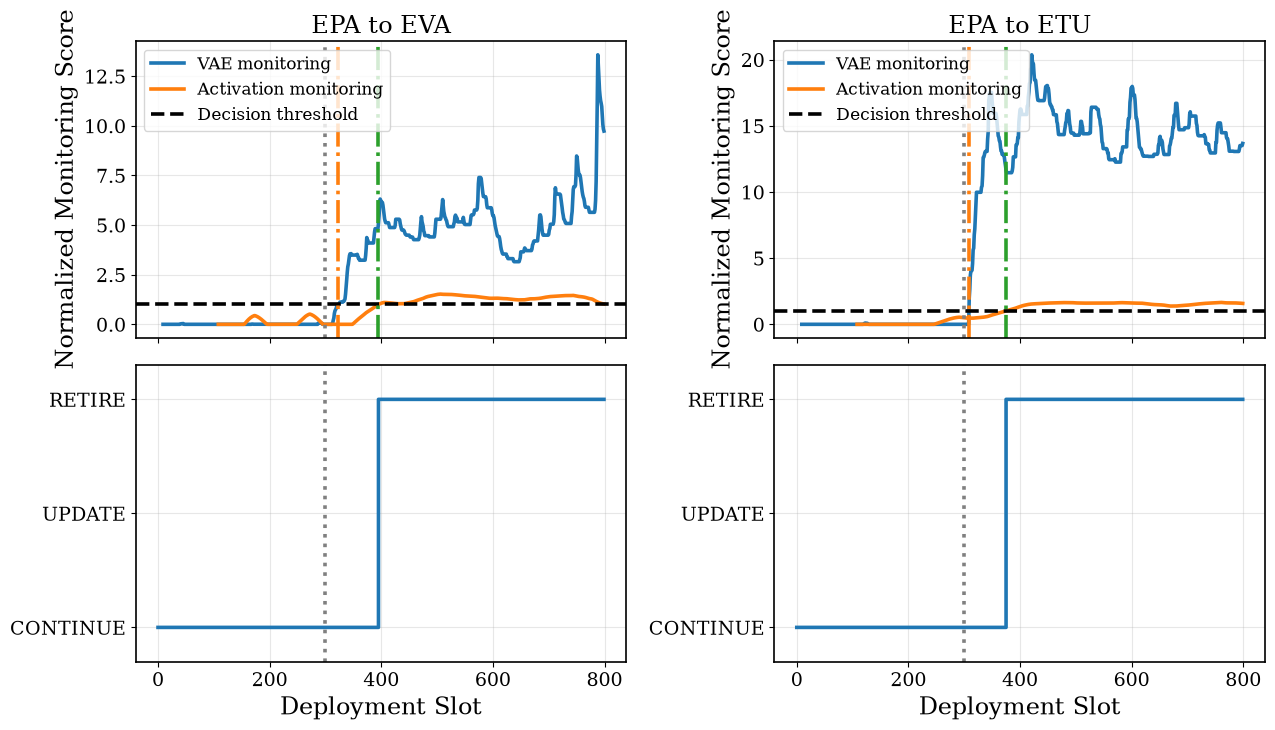


CELL 15 — FINAL SUMMARY
Runtime: 25.41 seconds
Trial results: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_end_to_end_trials.csv
Summary: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_end_to_end_summary.csv
Configuration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_end_to_end_config.json
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_end_to_end_lifecycle_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_end_to_end_lifecycle_IEEE.png

CELL 15 END-TO-END CDT: PASS


In [ ]:

# ============================================================
# CELL 15 — END-TO-END CDT LIFECYCLE EVALUATION
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Integrates:
#   1. VAE early warning
#   2. Layer-3 activation confirmation
#   3. Data-aided UPDATE
#   4. Validation-based RETIRE escalation
#   5. Verify-before-deploy model selection
#
# Ground-truth CSI:
#   Offline NMSE evaluation only.
#
# Important:
#   Saved RETIRE models are loaded from Cell 14.
#   No VQ-VAE retraining is performed here.
# ============================================================

import copy
import json
import random
import time

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

E15_SNR_DB = 12.0

E15_N_PRE = 300
E15_N_POST = 500
E15_N_TOTAL = E15_N_PRE + E15_N_POST
E15_ONSET = E15_N_PRE

E15_N_TRIALS = 30

E15_N_UPDATE = 100
E15_N_UPDATE_TRAIN = 80
E15_N_UPDATE_VAL = 20

E15_N_VALIDATION = 200

E15_RETIRE_MARGIN = 0.10
E15_CONFIRM_TIMEOUT = H_CONFIRM_TIMEOUT

E15_CHANNELS = ["EVA", "ETU"]

E15_SEED = SEED + 2400
E15_DEVICE = DEVICE

random.seed(E15_SEED)
np.random.seed(E15_SEED)
torch.manual_seed(E15_SEED)
torch.cuda.manual_seed_all(E15_SEED)

print("=" * 72)
print("CELL 15 — END-TO-END CDT LIFECYCLE")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", E15_SNR_DB, "dB")
print("Trials per scenario:", E15_N_TRIALS)
print("Drift onset:", E15_ONSET)
print("Deployment slots:", E15_N_TOTAL)
print("UPDATE observations:", E15_N_UPDATE)
print("RETIRE validation margin:", E15_RETIRE_MARGIN)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify dependencies
# ------------------------------------------------------------

required = [
    "DA_BASELINE",
    "da_generate_dataset",
    "da_finetune",
    "da_pseudo_loss",
    "da_nmse_db",
    "h_prepare_scores",
    "h_persistence_scores",
    "H_THRESHOLDS",
    "cdt_generate_sequence",
    "ChannelEstimatorFCN",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing dependencies: {missing}. "
        "Run Cells 11A, 12, and 14 first."
    )

# ------------------------------------------------------------
# 3. Load verified replacement candidates
# ------------------------------------------------------------

def e15_load_replacement(profile, method):

    filename = (
        f"retire_{method}_{profile.lower()}.pt"
    )

    path = CHECKPOINT_DIR / filename

    if not path.exists():
        raise FileNotFoundError(path)

    checkpoint = torch.load(
        path,
        map_location=E15_DEVICE,
        weights_only=True
    )

    estimator = ChannelEstimatorFCN().to(
        E15_DEVICE
    )

    estimator.load_state_dict(
        checkpoint
    )

    estimator.eval()

    return estimator


E15_REPLACEMENTS = {}

for profile in E15_CHANNELS:

    E15_REPLACEMENTS[profile] = {
        "scratch": e15_load_replacement(
            profile, "scratch"
        ),
        "warm": e15_load_replacement(
            profile, "warm"
        )
    }

# ------------------------------------------------------------
# 4. Monitoring and confirmation
# ------------------------------------------------------------

E15_TAU_V = H_THRESHOLDS[
    "Hierarchical"
]["vae"]

E15_TAU_A = H_THRESHOLDS[
    "Hierarchical"
]["activation"]


def e15_monitor(H):

    """
    Apply pretrained VAE and activation monitors.

    Returns:
        warning_slot
        confirmation_slot

    No ground-truth channel is used in monitoring.
    """

    v, a = h_prepare_scores(H)

    v_p, a_p = h_persistence_scores(v, a)

    warning = None
    confirmation = None

    waiting = False

    for t in range(len(v_p)):

        v_cross = (
            np.isfinite(v_p[t])
            and v_p[t] >= E15_TAU_V
        )

        a_cross = (
            np.isfinite(a_p[t])
            and a_p[t] >= E15_TAU_A
        )

        if not waiting and v_cross:
            warning = t
            waiting = True

        if waiting and a_cross:
            confirmation = t
            break

        if waiting and (
            t - warning >= E15_CONFIRM_TIMEOUT
        ):
            waiting = False
            warning = None

    return (
        warning,
        confirmation,
        v_p,
        a_p
    )


# ------------------------------------------------------------
# 5. Receiver-side validation
# ------------------------------------------------------------

@torch.no_grad()
def e15_validation_loss(
    estimator,
    h_p,
    pseudo
):

    estimator.eval()

    return float(
        da_pseudo_loss(
            estimator,
            h_p,
            pseudo
        ).item()
    )


# ------------------------------------------------------------
# 6. UPDATE and RETIRE decision
# ------------------------------------------------------------

def e15_lifecycle_action(profile):

    """
    UPDATE-first lifecycle action.

    Uses receiver-observable pseudo-targets
    for adaptation and model selection.

    True channel is not used in decisions.
    """

    # UPDATE data
    h_update, pseudo_update, _ = (
        da_generate_dataset(
            profile,
            E15_N_UPDATE
        )
    )

    # UPDATE fine-tuning
    (
        updated_model,
        update_accepted,
        _,
        _,
        _
    ) = da_finetune(
        DA_BASELINE,
        h_update[:E15_N_UPDATE_TRAIN],
        pseudo_update[:E15_N_UPDATE_TRAIN],
        h_update[E15_N_UPDATE_TRAIN:],
        pseudo_update[E15_N_UPDATE_TRAIN:]
    )

    # Independent validation data
    h_val, pseudo_val, _ = (
        da_generate_dataset(
            profile,
            E15_N_VALIDATION
        )
    )

    baseline_loss = e15_validation_loss(
        DA_BASELINE,
        h_val,
        pseudo_val
    )

    update_loss = e15_validation_loss(
        updated_model,
        h_val,
        pseudo_val
    )

    serving_model = (
        updated_model
        if update_accepted
        else DA_BASELINE
    )

    serving_loss = (
        update_loss
        if update_accepted
        else baseline_loss
    )

    # Evaluate replacement candidates
    candidates = E15_REPLACEMENTS[profile]

    candidate_losses = {
        name: e15_validation_loss(
            estimator,
            h_val,
            pseudo_val
        )
        for name, estimator in candidates.items()
    }

    best_name = min(
        candidate_losses,
        key=candidate_losses.get
    )

    best_loss = candidate_losses[best_name]

    # RETIRE escalation criterion
    improvement_fraction = (
        (serving_loss - best_loss)
        / max(serving_loss, 1e-12)
    )

    retire = (
        improvement_fraction
        >= E15_RETIRE_MARGIN
    )

    if retire:
        selected_model = candidates[best_name]
        action = "RETIRE"
    elif update_accepted:
        selected_model = updated_model
        action = "UPDATE"
    else:
        selected_model = DA_BASELINE
        action = "CONTINUE"

    return {
        "model": selected_model,
        "action": action,
        "update_accepted": update_accepted,
        "baseline_loss": baseline_loss,
        "update_loss": update_loss,
        "best_retire_loss": best_loss,
        "retire_improvement_fraction":
            improvement_fraction,
        "selected_replacement": (
            best_name if retire else "NONE"
        )
    }


# ------------------------------------------------------------
# 7. Offline NMSE evaluation
# ------------------------------------------------------------

@torch.no_grad()
def e15_evaluate_nmse(
    estimator,
    profile,
    n_samples=1000
):

    h_p, _, H_true = da_generate_dataset(
        profile,
        n_samples
    )

    return da_nmse_db(
        estimator,
        h_p,
        H_true
    )


# ------------------------------------------------------------
# 8. Run deployment trials
# ------------------------------------------------------------

E15_RESULTS = []
E15_EXAMPLES = {}

for profile in E15_CHANNELS:

    scenario = f"EPA_to_{profile}"

    print("\n" + "=" * 72)
    print("SCENARIO:", scenario)
    print("=" * 72)

    for trial in range(E15_N_TRIALS):

        # --------------------------------------------
        # A. Correlated deployment channel
        # --------------------------------------------
        H = cdt_generate_sequence(
            "EPA",
            profile
        )

        # --------------------------------------------
        # B. Drift monitoring
        # --------------------------------------------
        (
            warning_slot,
            confirmation_slot,
            v_p,
            a_p
        ) = e15_monitor(H)

        # --------------------------------------------
        # C. Lifecycle decision
        # --------------------------------------------
        if confirmation_slot is not None:

            lifecycle = e15_lifecycle_action(
                profile
            )

            selected_model = lifecycle["model"]
            action = lifecycle["action"]

        else:

            selected_model = DA_BASELINE
            action = "CONTINUE"

            lifecycle = {
                "update_accepted": False,
                "baseline_loss": np.nan,
                "update_loss": np.nan,
                "best_retire_loss": np.nan,
                "retire_improvement_fraction":
                    np.nan,
                "selected_replacement": "NONE"
            }

        # --------------------------------------------
        # D. Offline NMSE evaluation
        # --------------------------------------------
        baseline_nmse = e15_evaluate_nmse(
            DA_BASELINE,
            profile
        )

        selected_nmse = e15_evaluate_nmse(
            selected_model,
            profile
        )

        gain = baseline_nmse - selected_nmse

        E15_RESULTS.append({
            "Scenario": scenario,
            "Trial": trial,
            "Warning_Slot": warning_slot,
            "Confirmation_Slot": confirmation_slot,
            "Action": action,
            "Detection_Delay": (
                confirmation_slot - E15_ONSET
                if confirmation_slot is not None
                else np.nan
            ),
            "Baseline_NMSE_dB": baseline_nmse,
            "Selected_NMSE_dB": selected_nmse,
            "NMSE_Gain_dB": gain,
            **{
                k: v
                for k, v in lifecycle.items()
                if k != "model"
                and k != "action"
            }
        })

        if trial == 0:

            E15_EXAMPLES[scenario] = {
                "v_p": v_p,
                "a_p": a_p,
                "warning": warning_slot,
                "confirmation": confirmation_slot,
                "action": action
            }

        if (trial + 1) % 10 == 0:

            print(
                f"Trial {trial+1:02d}/{E15_N_TRIALS} | "
                f"Action={action} | "
                f"Warning={warning_slot} | "
                f"Confirmation={confirmation_slot} | "
                f"Gain={gain:+.2f} dB"
            )


# ------------------------------------------------------------
# 9. Results summary
# ------------------------------------------------------------

E15_RESULTS_DF = pd.DataFrame(
    E15_RESULTS
)

summary_rows = []

for scenario in E15_RESULTS_DF[
    "Scenario"
].unique():

    subset = E15_RESULTS_DF[
        E15_RESULTS_DF["Scenario"] == scenario
    ]

    summary_rows.append({
        "Scenario": scenario,
        "Detection_Rate": (
            subset["Confirmation_Slot"].notna().mean()
        ),
        "Mean_Delay": (
            subset["Detection_Delay"].mean()
        ),
        "Update_Rate": (
            (subset["Action"] == "UPDATE").mean()
        ),
        "Retire_Rate": (
            (subset["Action"] == "RETIRE").mean()
        ),
        "Continue_Rate": (
            (subset["Action"] == "CONTINUE").mean()
        ),
        "Baseline_NMSE_dB": (
            subset["Baseline_NMSE_dB"].mean()
        ),
        "Selected_NMSE_dB": (
            subset["Selected_NMSE_dB"].mean()
        ),
        "Mean_NMSE_Gain_dB": (
            subset["NMSE_Gain_dB"].mean()
        )
    })

E15_SUMMARY_DF = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 72)
print("CELL 15 — END-TO-END LIFECYCLE RESULTS")
print("=" * 72)

print(
    E15_SUMMARY_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# 10. IEEE-style lifecycle figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.6,
    "lines.markersize": 9,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 7.5),
    sharex=True
)

for col, scenario in enumerate(
    ["EPA_to_EVA", "EPA_to_ETU"]
):

    example = E15_EXAMPLES[scenario]

    slots = np.arange(E15_N_TOTAL)

    # Monitoring trajectories
    ax = axes[0, col]

    ax.plot(
        slots,
        example["v_p"] / E15_TAU_V,
        label="VAE monitoring"
    )

    ax.plot(
        slots,
        example["a_p"] / E15_TAU_A,
        label="Activation monitoring"
    )

    ax.axhline(
        1.0,
        color="black",
        linestyle="--",
        label="Decision threshold"
    )

    ax.axvline(
        E15_ONSET,
        color="gray",
        linestyle=":"
    )

    if example["warning"] is not None:
        ax.axvline(
            example["warning"],
            linestyle="-.",
            color="tab:orange"
        )

    if example["confirmation"] is not None:
        ax.axvline(
            example["confirmation"],
            linestyle="-.",
            color="tab:green"
        )

    ax.set_title(
        scenario.replace("_", " ")
    )

    ax.set_ylabel(
        "Normalized Monitoring Score"
    )

    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left")

    # Lifecycle states
    ax2 = axes[1, col]

    states = np.zeros(
        E15_N_TOTAL
    )

    if example["confirmation"] is not None:

        state_value = (
            2 if example["action"] == "RETIRE"
            else 1
        )

        states[
            example["confirmation"]:
        ] = state_value

    ax2.step(
        slots,
        states,
        where="post"
    )

    ax2.axvline(
        E15_ONSET,
        color="gray",
        linestyle=":"
    )

    ax2.set_yticks([0, 1, 2])
    ax2.set_yticklabels([
        "CONTINUE",
        "UPDATE",
        "RETIRE"
    ])

    ax2.set_ylim(-0.3, 2.3)

    ax2.set_xlabel(
        "Deployment Slot"
    )

    ax2.grid(True, alpha=0.3)

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "cdt_end_to_end_lifecycle_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "cdt_end_to_end_lifecycle_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 11. Save results
# ------------------------------------------------------------

results_path = (
    RESULTS_DIR /
    "cdt_end_to_end_trials.csv"
)

summary_path = (
    RESULTS_DIR /
    "cdt_end_to_end_summary.csv"
)

E15_RESULTS_DF.to_csv(
    results_path,
    index=False
)

E15_SUMMARY_DF.to_csv(
    summary_path,
    index=False
)

config_path = (
    RESULTS_DIR /
    "cdt_end_to_end_config.json"
)

with open(config_path, "w") as f:

    json.dump({
        "snr_db": E15_SNR_DB,
        "drift_onset": E15_ONSET,
        "deployment_slots": E15_N_TOTAL,
        "trials": E15_N_TRIALS,
        "update_samples": E15_N_UPDATE,
        "validation_samples": E15_N_VALIDATION,
        "retire_margin": E15_RETIRE_MARGIN,
        "confirmation_timeout":
            E15_CONFIRM_TIMEOUT,
        "ground_truth_used_for_adaptation": False,
        "correct_decoding_assumed": True,
        "replacement_models_pretrained": True
    }, f, indent=4)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 15 — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Trial results:", results_path)
print("Summary:", summary_path)
print("Configuration:", config_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 15 END-TO-END CDT: PASS")


CELL 15A — CAUSAL PAIRED CDT LIFECYCLE
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Trials per scenario: 30
Drift onset: 300
Deployment slots: 800
UPDATE observations: 100
Verification observations: 100
RETIRE margin: 0.1

[MODEL REPOSITORY]
  RETIRE_EVA_scratch
  RETIRE_EVA_warm
  RETIRE_ETU_scratch
  RETIRE_ETU_warm

SCENARIO: EPA_to_EPA
Trial 10/30 | Confirm=None | Action=CONTINUE | Gain=+0.00 dB
Trial 20/30 | Confirm=None | Action=CONTINUE | Gain=+0.00 dB
Trial 30/30 | Confirm=None | Action=CONTINUE | Gain=+0.00 dB

SCENARIO: EPA_to_EVA
Trial 10/30 | Confirm=390 | Action=RETIRE | Gain=+5.25 dB
Trial 20/30 | Confirm=359 | Action=RETIRE | Gain=+4.40 dB
Trial 30/30 | Confirm=385 | Action=RETIRE | Gain=+5.10 dB

SCENARIO: EPA_to_ETU
Trial 10/30 | Confirm=362 | Action=RETIRE | Gain=+4.40 dB
Trial 20/30 | Confirm=378 | Action=RETIRE | Gain=+4.33 dB
Trial 30/30 | Confirm=391 | Action=RETIRE | Gain=+4.21 dB

CELL 15A — CAUSAL PAIRED LIFECYCLE RESULTS
  Scenario  Detection_Rate  Fal

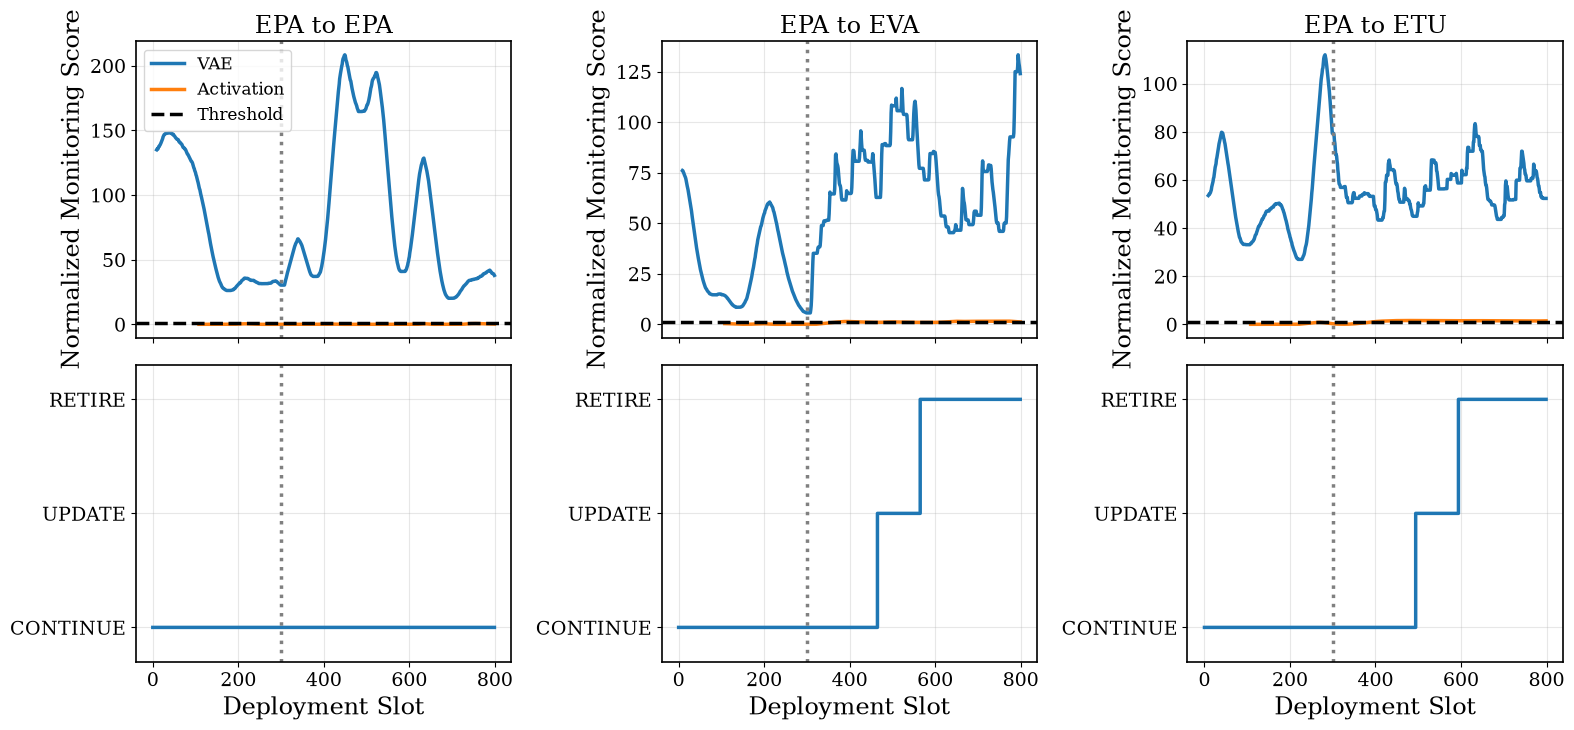


CELL 15A — FINAL SUMMARY
Runtime: 26.54 seconds
Trial results: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_causal_lifecycle_trials.csv
Summary: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_causal_lifecycle_summary.csv
Event log: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_causal_lifecycle_events.csv
Configuration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_causal_lifecycle_config.json
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_causal_lifecycle_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_causal_lifecycle_IEEE.png

CELL 15A CAUSAL PAIRED LIFECYCLE: PASS


In [ ]:

# ============================================================
# CELL 15A — CAUSAL, PAIRED CDT LIFECYCLE VALIDATION
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Improvements over Cell 15:
#   - Actual deployment observations for adaptation
#   - No channel-label access for model selection
#   - Matched EPA -> EPA control
#   - UPDATE-first lifecycle
#   - Independent post-UPDATE validation
#   - Repository-wide replacement selection
#   - Paired full-channel NMSE evaluation
#   - Explicit lifecycle event logging
#
# Ground-truth CSI is used ONLY for offline evaluation.
#
# Ideal correct decoding is assumed:
#   X_hat = X for data-aided pseudo-targets.
#
# Repository models are pretrained and frozen.
# ============================================================

import copy
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

A15_SNR_DB = 12.0

A15_N_PRE = 300
A15_N_POST = 500
A15_N_TOTAL = A15_N_PRE + A15_N_POST
A15_ONSET = A15_N_PRE

A15_N_TRIALS = 30

A15_N_UPDATE = 100
A15_N_TRAIN = 80
A15_N_UPDATE_VAL = 20

A15_N_VERIFY = 100

A15_RETIRE_MARGIN = 0.10
A15_CONFIRM_TIMEOUT = H_CONFIRM_TIMEOUT

A15_SCENARIOS = {
    "EPA_to_EPA": ("EPA", "EPA"),
    "EPA_to_EVA": ("EPA", "EVA"),
    "EPA_to_ETU": ("EPA", "ETU"),
}

A15_SEED = SEED + 2500
A15_DEVICE = DEVICE

random.seed(A15_SEED)
np.random.seed(A15_SEED)
torch.manual_seed(A15_SEED)
torch.cuda.manual_seed_all(A15_SEED)

print("=" * 72)
print("CELL 15A — CAUSAL PAIRED CDT LIFECYCLE")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", A15_SNR_DB, "dB")
print("Trials per scenario:", A15_N_TRIALS)
print("Drift onset:", A15_ONSET)
print("Deployment slots:", A15_N_TOTAL)
print("UPDATE observations:", A15_N_UPDATE)
print("Verification observations:", A15_N_VERIFY)
print("RETIRE margin:", A15_RETIRE_MARGIN)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify dependencies
# ------------------------------------------------------------

required = [
    "DA_BASELINE",
    "da_finetune",
    "da_pseudo_loss",
    "da_nmse_db",
    "h_prepare_scores",
    "h_persistence_scores",
    "H_THRESHOLDS",
    "cdt_generate_sequence",
    "ChannelEstimatorFCN",
    "da_generate_qpsk",
    "da_vector_to_complex",
    "DA_DATA_MASK",
    "pilot_k",
    "pilot_l",
    "CHECKPOINT_DIR",
    "RESULTS_DIR",
    "FIGURES_DIR",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing dependencies: {missing}. "
        "Run Cells 11A, 12, and 14 first."
    )

assert A15_N_TOTAL == A15_N_PRE + A15_N_POST

# ------------------------------------------------------------
# 3. Load complete replacement repository
# ------------------------------------------------------------

def a15_load_model(path):

    state = torch.load(
        path,
        map_location=A15_DEVICE,
        weights_only=True
    )

    estimator = ChannelEstimatorFCN().to(
        A15_DEVICE
    )

    estimator.load_state_dict(state)
    estimator.eval()

    for p in estimator.parameters():
        p.requires_grad_(False)

    return estimator


A15_REPOSITORY = {}

for profile in ["eva", "etu"]:

    for initialization in ["scratch", "warm"]:

        name = (
            f"RETIRE_{profile.upper()}_"
            f"{initialization}"
        )

        path = (
            CHECKPOINT_DIR /
            f"retire_{initialization}_{profile}.pt"
        )

        if not path.exists():
            raise FileNotFoundError(path)

        A15_REPOSITORY[name] = (
            a15_load_model(path)
        )

print("\n[MODEL REPOSITORY]")
for name in A15_REPOSITORY:
    print(" ", name)

# ------------------------------------------------------------
# 4. Generate received deployment trajectory
# ------------------------------------------------------------

@torch.no_grad()
def a15_generate_observations(H):

    """
    Generate receiver-side observations from the
    actual correlated deployment channel trajectory.

    H:
        True channel, used only inside the physical
        simulator and later for offline NMSE.

    Controller receives only:
        h_p, H_pseudo

    Ideal correct decoding:
        X_hat = X
    """

    B = len(H)

    X = da_generate_qpsk(B)

    noise_variance = (
        10.0 ** (-A15_SNR_DB / 10.0)
    )

    noise = torch.complex(
        torch.randn_like(H.real),
        torch.randn_like(H.real)
    ) * np.sqrt(
        noise_variance / 2.0
    )

    Y = H * X + noise

    # Receiver LS pilot observations
    H_p = (
        Y[:, pilot_k, pilot_l]
        / X[:, pilot_k, pilot_l]
    )

    h_p = torch.cat(
        [H_p.real, H_p.imag],
        dim=1
    ).float()

    # Data-aided pseudo-targets
    X_hat = X
    H_pseudo = Y / X_hat

    return h_p, H_pseudo


# ------------------------------------------------------------
# 5. Monitoring scores from received pilots
# ------------------------------------------------------------

@torch.no_grad()
def a15_monitor_from_pilots(h_p):

    """
    Compute monitoring scores using the same
    receiver-observed pilot inputs as UPDATE.

    VAE uses received pilot symbols.
    Activation uses LS pilot estimates.
    """

    # Known pilots are 1+0j, so y_p = h_p
    y_p = h_p

    vae_raw = (
        vae_model.reconstruction_error(y_p)
        .detach().cpu().numpy()
    )

    # FCN hidden-layer activations
    _, activations = DA_BASELINE(
        h_p,
        return_activations=True
    )

    layer3 = activations[2].detach().cpu()

    mu, sigma = cp_rolling_stats(
        layer3,
        CDT_WINDOW
    )

    ref_mu = DIR_REFERENCE["mean"].to(
        torch.float64
    )

    ref_std = DIR_REFERENCE["std"].to(
        torch.float64
    )

    denominator = (
        torch.linalg.vector_norm(ref_std)
        + 1e-8
    )

    mean_drift = (
        torch.linalg.vector_norm(
            mu - ref_mu,
            dim=1
        ) / denominator
    )

    std_drift = (
        torch.linalg.vector_norm(
            sigma - ref_std,
            dim=1
        ) / denominator
    )

    activation_raw = np.full(
        len(h_p),
        np.nan
    )

    activation_raw[
        CDT_WINDOW - 1:
    ] = (
        mean_drift + std_drift
    ).numpy()

    # EWMA and normalization from Cell 11
    vae_smooth = cdt_ewma(
        vae_raw
    )

    act_smooth = cdt_ewma(
        activation_raw
    )

    act_anomaly = cdt_activation_anomaly(
        act_smooth
    )

    v, a = cdt_normalize(
        vae_smooth,
        act_anomaly
    )

    return h_persistence_scores(v, a)


def h_persistence_scores(v, a):

    return (
        cdt_persistence(v, CDT_HOLD),
        cdt_persistence(a, CDT_HOLD)
    )


# ------------------------------------------------------------
# 6. Causal warning and confirmation
# ------------------------------------------------------------

A15_TAU_V = float(
    H_THRESHOLDS["Hierarchical"]["vae"]
)

A15_TAU_A = float(
    H_THRESHOLDS["Hierarchical"]["activation"]
)


def a15_find_confirmation(v_p, a_p):

    warning = None
    waiting = False

    for t in range(len(v_p)):

        v_cross = (
            np.isfinite(v_p[t])
            and v_p[t] >= A15_TAU_V
        )

        a_cross = (
            np.isfinite(a_p[t])
            and a_p[t] >= A15_TAU_A
        )

        if not waiting and v_cross:
            warning = t
            waiting = True

        if waiting and a_cross:
            return warning, t

        if waiting and (
            t - warning >= A15_CONFIRM_TIMEOUT
        ):
            waiting = False
            warning = None

    return None, None


# ------------------------------------------------------------
# 7. Receiver-side validation
# ------------------------------------------------------------

@torch.no_grad()
def a15_val_loss(model, h_p, pseudo):

    model.eval()

    return float(
        da_pseudo_loss(
            model,
            h_p,
            pseudo
        ).item()
    )


# ------------------------------------------------------------
# 8. Paired offline NMSE
# ------------------------------------------------------------

@torch.no_grad()
def a15_paired_nmse(
    models,
    h_p,
    H_true
):

    results = {}

    for name, model in models.items():

        results[name] = da_nmse_db(
            model,
            h_p,
            H_true
        )

    return results


# ------------------------------------------------------------
# 9. Run deployment trials
# ------------------------------------------------------------

A15_RESULTS = []
A15_EVENT_LOG = []
A15_EXAMPLES = {}

for scenario, (before, after) in A15_SCENARIOS.items():

    print("\n" + "=" * 72)
    print("SCENARIO:", scenario)
    print("=" * 72)

    for trial in range(A15_N_TRIALS):

        # --------------------------------------------
        # A. Actual correlated channel trajectory
        # --------------------------------------------
        H = cdt_generate_sequence(
            before,
            after
        )

        # --------------------------------------------
        # B. Receiver-side observations
        # --------------------------------------------
        h_p, pseudo = a15_generate_observations(
            H
        )

        # --------------------------------------------
        # C. Monitoring
        # --------------------------------------------
        v_p, a_p = a15_monitor_from_pilots(
            h_p
        )

        warning, confirmation = (
            a15_find_confirmation(
                v_p,
                a_p
            )
        )

        selected_model = DA_BASELINE
        action = "CONTINUE"

        update_accepted = False
        retire_accepted = False

        update_end = None
        verification_end = None

        selected_name = "Original"

        # --------------------------------------------
        # D. Lifecycle adaptation
        # --------------------------------------------
        if confirmation is not None:

            A15_EVENT_LOG.append({
                "Scenario": scenario,
                "Trial": trial,
                "Slot": confirmation,
                "Event": "DRIFT_CONFIRMED"
            })

            # Buffer 100 subsequent observations
            update_start = confirmation + 1
            update_end = (
                update_start + A15_N_UPDATE
            )

            verification_start = update_end
            verification_end = (
                verification_start
                + A15_N_VERIFY
            )

            if verification_end <= A15_N_TOTAL:

                # ------------------------------------
                # UPDATE using actual deployment data
                # ------------------------------------
                x_update = h_p[
                    update_start:update_end
                ]

                y_update = pseudo[
                    update_start:update_end
                ]

                (
                    updated_model,
                    update_accepted,
                    _,
                    _,
                    _
                ) = da_finetune(
                    DA_BASELINE,
                    x_update[:A15_N_TRAIN],
                    y_update[:A15_N_TRAIN],
                    x_update[A15_N_TRAIN:],
                    y_update[A15_N_TRAIN:]
                )

                A15_EVENT_LOG.append({
                    "Scenario": scenario,
                    "Trial": trial,
                    "Slot": update_end,
                    "Event": "UPDATE_COMPLETED"
                })

                # ------------------------------------
                # Independent verification
                # ------------------------------------
                x_verify = h_p[
                    verification_start:
                    verification_end
                ]

                y_verify = pseudo[
                    verification_start:
                    verification_end
                ]

                original_loss = a15_val_loss(
                    DA_BASELINE,
                    x_verify,
                    y_verify
                )

                update_loss = a15_val_loss(
                    updated_model,
                    x_verify,
                    y_verify
                )

                if update_accepted:
                    serving_model = updated_model
                    serving_name = "UPDATE"
                else:
                    serving_model = DA_BASELINE
                    serving_name = "Original"

                serving_loss = a15_val_loss(
                    serving_model,
                    x_verify,
                    y_verify
                )

                # ------------------------------------
                # Evaluate all repository candidates
                # ------------------------------------
                candidate_losses = {
                    name: a15_val_loss(
                        candidate,
                        x_verify,
                        y_verify
                    )
                    for name, candidate
                    in A15_REPOSITORY.items()
                }

                best_candidate_name = min(
                    candidate_losses,
                    key=candidate_losses.get
                )

                best_candidate_loss = (
                    candidate_losses[
                        best_candidate_name
                    ]
                )

                relative_improvement = (
                    (serving_loss - best_candidate_loss)
                    / max(serving_loss, 1e-12)
                )

                # RETIRE only if meaningful improvement
                retire_accepted = (
                    relative_improvement
                    >= A15_RETIRE_MARGIN
                )

                if retire_accepted:

                    selected_model = (
                        A15_REPOSITORY[
                            best_candidate_name
                        ]
                    )

                    selected_name = best_candidate_name
                    action = "RETIRE"

                elif update_accepted:

                    selected_model = updated_model
                    selected_name = "UPDATE"
                    action = "UPDATE"

                else:

                    selected_model = DA_BASELINE
                    selected_name = "Original"
                    action = "CONTINUE"

                A15_EVENT_LOG.append({
                    "Scenario": scenario,
                    "Trial": trial,
                    "Slot": verification_end,
                    "Event": action
                })

        # --------------------------------------------
        # E. Paired offline NMSE evaluation
        # --------------------------------------------
        # Evaluate only samples after the verification
        # period when an action was completed.
        # Otherwise use post-onset samples.

        if (
            verification_end is not None
            and verification_end < A15_N_TOTAL
        ):
            eval_start = verification_end
        else:
            eval_start = A15_ONSET

        x_eval = h_p[eval_start:]
        H_eval = H[eval_start:]

        nmse = a15_paired_nmse(
            {
                "Original": DA_BASELINE,
                "Selected": selected_model
            },
            x_eval,
            H_eval
        )

        gain = (
            nmse["Original"]
            - nmse["Selected"]
        )

        A15_RESULTS.append({
            "Scenario": scenario,
            "Trial": trial,
            "Warning_Slot": warning,
            "Confirmation_Slot": confirmation,
            "Update_End": update_end,
            "Verification_End": verification_end,
            "Action": action,
            "Selected_Model": selected_name,
            "Update_Accepted": update_accepted,
            "Retire_Accepted": retire_accepted,
            "Detection_Delay": (
                confirmation - A15_ONSET
                if confirmation is not None
                else np.nan
            ),
            "Original_NMSE_dB": nmse["Original"],
            "Selected_NMSE_dB": nmse["Selected"],
            "NMSE_Gain_dB": gain
        })

        if trial == 0:

            A15_EXAMPLES[scenario] = {
                "vae": v_p,
                "activation": a_p,
                "warning": warning,
                "confirmation": confirmation,
                "update_end": update_end,
                "verification_end": verification_end,
                "action": action
            }

        if (trial + 1) % 10 == 0:

            print(
                f"Trial {trial+1:02d}/{A15_N_TRIALS} | "
                f"Confirm={confirmation} | "
                f"Action={action} | "
                f"Gain={gain:+.2f} dB"
            )


# ------------------------------------------------------------
# 10. Results summary
# ------------------------------------------------------------

A15_RESULTS_DF = pd.DataFrame(
    A15_RESULTS
)

summary_rows = []

for scenario in A15_SCENARIOS:

    subset = A15_RESULTS_DF[
        A15_RESULTS_DF["Scenario"] == scenario
    ]

    is_control = (
        scenario == "EPA_to_EPA"
    )

    summary_rows.append({
        "Scenario": scenario,
        "Detection_Rate": (
            np.nan if is_control
            else subset["Confirmation_Slot"].notna().mean()
        ),
        "False_Action_Rate": (
            (subset["Action"] != "CONTINUE").mean()
            if is_control else np.nan
        ),
        "Mean_Detection_Delay": (
            subset["Detection_Delay"].mean()
            if not is_control else np.nan
        ),
        "Update_Acceptance_Rate": (
            subset["Update_Accepted"].mean()
        ),
        "Retire_Rate": (
            (subset["Action"] == "RETIRE").mean()
        ),
        "Continue_Rate": (
            (subset["Action"] == "CONTINUE").mean()
        ),
        "Original_NMSE_dB": (
            subset["Original_NMSE_dB"].mean()
        ),
        "Selected_NMSE_dB": (
            subset["Selected_NMSE_dB"].mean()
        ),
        "Mean_NMSE_Gain_dB": (
            subset["NMSE_Gain_dB"].mean()
        )
    })

A15_SUMMARY_DF = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 72)
print("CELL 15A — CAUSAL PAIRED LIFECYCLE RESULTS")
print("=" * 72)

print(
    A15_SUMMARY_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# 11. IEEE-style lifecycle figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.5,
    "lines.markersize": 9,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 7.5),
    sharex=True
)

plot_scenarios = [
    "EPA_to_EPA",
    "EPA_to_EVA",
    "EPA_to_ETU"
]

for col, scenario in enumerate(
    plot_scenarios
):

    example = A15_EXAMPLES[scenario]

    slots = np.arange(A15_N_TOTAL)

    # Monitoring
    ax = axes[0, col]

    ax.plot(
        slots,
        example["vae"] / A15_TAU_V,
        label="VAE"
    )

    ax.plot(
        slots,
        example["activation"] / A15_TAU_A,
        label="Activation"
    )

    ax.axhline(
        1.0,
        color="black",
        linestyle="--",
        label="Threshold"
    )

    ax.axvline(
        A15_ONSET,
        color="gray",
        linestyle=":"
    )

    ax.set_title(
        scenario.replace("_", " ")
    )

    ax.set_ylabel(
        "Normalized Monitoring Score"
    )

    ax.grid(True, alpha=0.3)

    if col == 0:
        ax.legend()

    # Lifecycle states
    ax = axes[1, col]

    states = np.zeros(
        A15_N_TOTAL
    )

    if example["update_end"] is not None:

        states[
            example["update_end"]:
        ] = 1

    if example["verification_end"] is not None:

        if example["action"] == "RETIRE":
            states[
                example["verification_end"]:
            ] = 2

        elif example["action"] == "UPDATE":
            states[
                example["verification_end"]:
            ] = 1

    ax.step(
        slots,
        states,
        where="post"
    )

    ax.axvline(
        A15_ONSET,
        color="gray",
        linestyle=":"
    )

    ax.set_yticks([0, 1, 2])

    ax.set_yticklabels([
        "CONTINUE",
        "UPDATE",
        "RETIRE"
    ])

    ax.set_ylim(-0.3, 2.3)

    ax.set_xlabel(
        "Deployment Slot"
    )

    ax.grid(True, alpha=0.3)

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "cdt_causal_lifecycle_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "cdt_causal_lifecycle_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 12. Save results
# ------------------------------------------------------------

results_path = (
    RESULTS_DIR /
    "cdt_causal_lifecycle_trials.csv"
)

summary_path = (
    RESULTS_DIR /
    "cdt_causal_lifecycle_summary.csv"
)

event_path = (
    RESULTS_DIR /
    "cdt_causal_lifecycle_events.csv"
)

A15_RESULTS_DF.to_csv(
    results_path,
    index=False
)

A15_SUMMARY_DF.to_csv(
    summary_path,
    index=False
)

pd.DataFrame(
    A15_EVENT_LOG
).to_csv(
    event_path,
    index=False
)

config_path = (
    RESULTS_DIR /
    "cdt_causal_lifecycle_config.json"
)

with open(config_path, "w") as f:

    json.dump({
        "snr_db": A15_SNR_DB,
        "drift_onset": A15_ONSET,
        "deployment_slots": A15_N_TOTAL,
        "trials": A15_N_TRIALS,
        "update_samples": A15_N_UPDATE,
        "verification_samples": A15_N_VERIFY,
        "retire_margin": A15_RETIRE_MARGIN,
        "confirmation_timeout":
            A15_CONFIRM_TIMEOUT,
        "ground_truth_used_for_adaptation": False,
        "repository_selection_uses_channel_label": False,
        "correct_decoding_assumed": True,
        "replacement_models_pretrained": True
    }, f, indent=4)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 15A — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Trial results:", results_path)
print("Summary:", summary_path)
print("Event log:", event_path)
print("Configuration:", config_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 15A CAUSAL PAIRED LIFECYCLE: PASS")


CELL 15B — MATCHED MONITORING CALIBRATION
Device: cuda:0
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Calibration trajectories: 500
Evaluation trials: 300
Target event FAR: 0.01

[INPUT DISTRIBUTION CONSISTENCY]
       Input     Mean      Std  Mean_Square  Max_Abs
Original_VAE 0.000123 0.750674     0.563497 2.600037
 Revised_VAE 0.101888 0.743791     0.563591 3.030863
Original_FCN 0.101815 0.743737     0.563497 3.110932
 Revised_FCN 0.101888 0.743791     0.563591 3.030863

Generating matched EPA calibration trajectories...
Calibration 100/500
Calibration 200/500
Calibration 300/500
Calibration 400/500
Calibration 500/500

[MATCHED REFERENCE]
VAE center: 18.812828134318842
VAE scale: 20.873532661164866
Activation center: 1.2540386764927256
Activation scale: 0.3204458077964972

[CALIBRATED THRESHOLDS]
VAE: 7.651739552416029
Activation: 2.0866884823099072
Hierarchical VAE: 4.973630709070419
Hierarchical activation: 1.3563475135014398

Evaluating independent trajectories...
EPA_to_

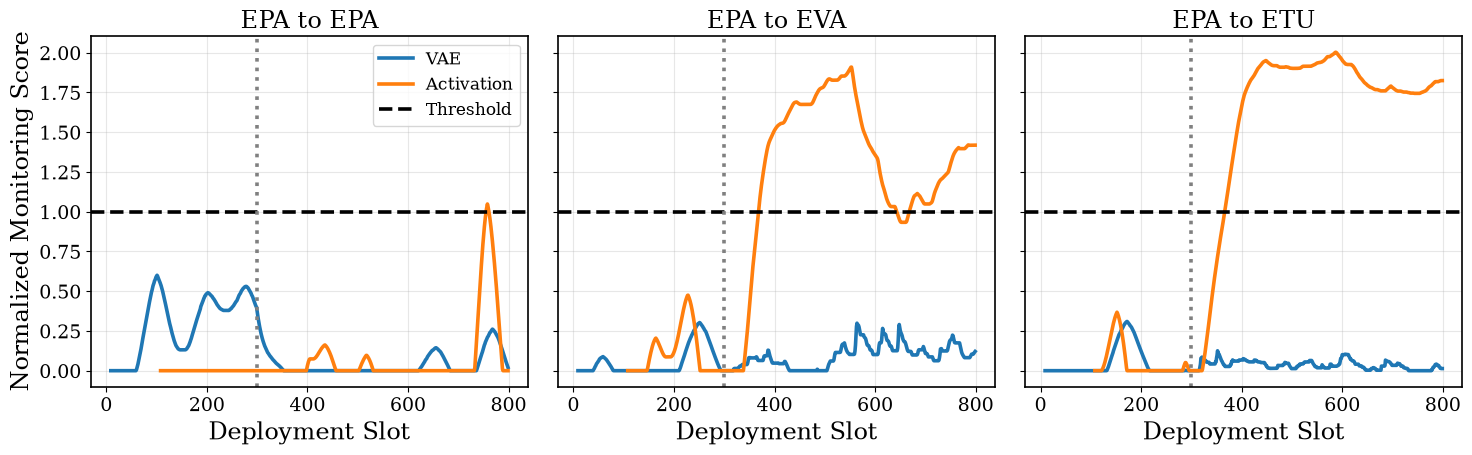


CELL 15B — FINAL SUMMARY
Runtime: 24.65 seconds
Input diagnostics: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_monitor_input_consistency.csv
Summary: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_snr_matched_monitoring_summary.csv
Trials: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_snr_matched_monitoring_trials.csv
Checkpoint: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/cdt_snr_matched_monitor.pt
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_snr_matched_monitoring_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_snr_matched_monitoring_IEEE.png

CELL 15B MATCHED MONITORING: PASS


In [ ]:

# ============================================================
# CELL 15B — MONITORING INPUT CONSISTENCY AND CALIBRATION
# IEEE WCL CDT | NVIDIA RTX 5090 CUDA
#
# Objectives:
#  1. Explicitly distinguish received pilots and LS pilots
#  2. Compare original and revised receiver preprocessing
#  3. Recalibrate monitoring at 12 dB
#  4. Use matched EPA->EPA event-level calibration
#  5. Evaluate independent EPA/EVA/ETU trajectories
#  6. Compare VAE, activation, and hierarchical policies
#  7. Generate IEEE-style monitoring and ROC figures
#
# No estimator adaptation or replacement in this cell.
# Ground truth used only by physical channel simulator.
# ============================================================

import time
import json
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import roc_curve, roc_auc_score

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

B15_SNR_DB = 12.0

B15_N_PRE = 300
B15_N_POST = 500
B15_N_TOTAL = B15_N_PRE + B15_N_POST
B15_ONSET = B15_N_PRE

B15_N_CAL = 500
B15_N_EVAL = 300

B15_WINDOW = 100
B15_ALPHA = 0.05
B15_HOLD = 10

B15_TARGET_FAR = 0.01
B15_CONFIRM_TIMEOUT = 250

B15_MODES = [
    "VAE_only",
    "Activation_only",
    "Hierarchical"
]

B15_SCENARIOS = {
    "EPA_to_EPA": ("EPA", "EPA"),
    "EPA_to_EVA": ("EPA", "EVA"),
    "EPA_to_ETU": ("EPA", "ETU"),
}

B15_SEED = SEED + 2600
B15_DEVICE = DEVICE

random.seed(B15_SEED)
np.random.seed(B15_SEED)
torch.manual_seed(B15_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(B15_SEED)

model.eval()
vae_model.eval()
DA_BASELINE.eval()

print("=" * 72)
print("CELL 15B — MATCHED MONITORING CALIBRATION")
print("=" * 72)

print("Device:", B15_DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("SNR:", B15_SNR_DB, "dB")
print("Calibration trajectories:", B15_N_CAL)
print("Evaluation trials:", B15_N_EVAL)
print("Target event FAR:", B15_TARGET_FAR)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify dependencies
# ------------------------------------------------------------

required = [
    "cdt_generate_sequence",
    "simulate_ofdm",
    "extract_pilot_observations",
    "DA_BASELINE",
    "vae_model",
    "cp_rolling_stats",
    "DIR_REFERENCE",
    "pilot_k",
    "pilot_l",
    "da_generate_qpsk",
    "CHECKPOINT_DIR",
    "RESULTS_DIR",
    "FIGURES_DIR",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing definitions: {missing}. "
        "Run Cells 1-15A first."
    )

# ------------------------------------------------------------
# 3. Receiver observation generation
# ------------------------------------------------------------

@torch.no_grad()
def b15_generate_observations(H):

    """
    Revised receiver observation model.

    VAE input:
        Raw received pilot symbols.

    FCN input:
        LS pilot channel estimates.

    Both use the same received OFDM grid.
    """

    B = len(H)

    X = da_generate_qpsk(B)

    noise_variance = (
        10.0 ** (-B15_SNR_DB / 10.0)
    )

    noise = torch.complex(
        torch.randn_like(H.real),
        torch.randn_like(H.real)
    ) * np.sqrt(
        noise_variance / 2.0
    )

    Y = H * X + noise

    received_pilots = Y[
        :,
        pilot_k,
        pilot_l
    ]

    transmitted_pilots = X[
        :,
        pilot_k,
        pilot_l
    ]

    ls_pilots = (
        received_pilots / transmitted_pilots
    )

    y_p = torch.cat(
        [
            received_pilots.real,
            received_pilots.imag
        ],
        dim=1
    ).float()

    h_p = torch.cat(
        [
            ls_pilots.real,
            ls_pilots.imag
        ],
        dim=1
    ).float()

    return y_p, h_p


# ------------------------------------------------------------
# 4. Original observation pipeline comparison
# ------------------------------------------------------------

@torch.no_grad()
def b15_original_pipeline(H):

    """
    Original receiver functions from Cells 3-4.

    Used only to compare input distributions.
    """

    _, Y, _ = simulate_ofdm(
        H,
        B15_SNR_DB
    )

    y_p, h_p, _ = (
        extract_pilot_observations(Y)
    )

    return y_p, h_p


def b15_distribution_summary(x):

    x = x.detach().float()

    return {
        "Mean": float(x.mean().item()),
        "Std": float(x.std().item()),
        "Mean_Square": float(
            x.square().mean().item()
        ),
        "Max_Abs": float(
            x.abs().max().item()
        )
    }


# ------------------------------------------------------------
# 5. Compare receiver input distributions
# ------------------------------------------------------------

print("\n[INPUT DISTRIBUTION CONSISTENCY]")

H_check = cdt_generate_sequence(
    "EPA", "EPA"
)

y_original, h_original = (
    b15_original_pipeline(H_check)
)

y_revised, h_revised = (
    b15_generate_observations(H_check)
)

input_rows = []

for name, x in [
    ("Original_VAE", y_original),
    ("Revised_VAE", y_revised),
    ("Original_FCN", h_original),
    ("Revised_FCN", h_revised),
]:

    input_rows.append({
        "Input": name,
        **b15_distribution_summary(x)
    })

B15_INPUT_DF = pd.DataFrame(
    input_rows
)

print(
    B15_INPUT_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 6. VAE reconstruction scores
# ------------------------------------------------------------

@torch.no_grad()
def b15_vae_scores(y_p):

    scores = (
        vae_model.reconstruction_error(
            y_p
        )
        .detach()
        .cpu()
        .numpy()
    )

    return np.asarray(
        scores,
        dtype=np.float64
    ).reshape(-1)


# ------------------------------------------------------------
# 7. Layer-3 activation drift scores
# ------------------------------------------------------------

@torch.no_grad()
def b15_activation_scores(h_p):

    _, activations = DA_BASELINE(
        h_p,
        return_activations=True
    )

    layer3 = activations[2].detach().cpu()

    mu, sigma = cp_rolling_stats(
        layer3,
        B15_WINDOW
    )

    ref_mu = DIR_REFERENCE["mean"].to(
        torch.float64
    )

    ref_std = DIR_REFERENCE["std"].to(
        torch.float64
    )

    denominator = (
        torch.linalg.vector_norm(ref_std)
        + 1e-8
    )

    mean_drift = (
        torch.linalg.vector_norm(
            mu - ref_mu,
            dim=1
        ) / denominator
    )

    std_drift = (
        torch.linalg.vector_norm(
            sigma - ref_std,
            dim=1
        ) / denominator
    )

    scores = np.full(
        len(h_p),
        np.nan,
        dtype=np.float64
    )

    scores[B15_WINDOW-1:] = (
        mean_drift + std_drift
    ).numpy()

    return scores


# ------------------------------------------------------------
# 8. EWMA smoothing
# ------------------------------------------------------------

def b15_ewma(values):

    output = np.full_like(
        values,
        np.nan,
        dtype=np.float64
    )

    previous = None

    for t, value in enumerate(values):

        if not np.isfinite(value):
            continue

        if previous is None:
            previous = float(value)
        else:
            previous = (
                B15_ALPHA * value
                + (1.0 - B15_ALPHA) * previous
            )

        output[t] = previous

    return output


# ------------------------------------------------------------
# 9. Persistence statistic
# ------------------------------------------------------------

def b15_persistence(values):

    output = np.full_like(
        values,
        np.nan,
        dtype=np.float64
    )

    for t in range(
        B15_HOLD-1,
        len(values)
    ):

        segment = values[
            t-B15_HOLD+1:t+1
        ]

        if np.isfinite(segment).all():
            output[t] = np.min(segment)

    return output


# ------------------------------------------------------------
# 10. Extract matched monitoring scores
# ------------------------------------------------------------

@torch.no_grad()
def b15_extract_monitoring(H):

    y_p, h_p = (
        b15_generate_observations(H)
    )

    vae_raw = b15_vae_scores(y_p)
    act_raw = b15_activation_scores(h_p)

    vae_smooth = b15_ewma(
        vae_raw
    )

    act_smooth = b15_ewma(
        act_raw
    )

    return vae_smooth, act_smooth


# ------------------------------------------------------------
# 11. Calibration trajectories
# ------------------------------------------------------------

print("\nGenerating matched EPA calibration trajectories...")

B15_CAL_RAW = []

for trial in range(B15_N_CAL):

    H = cdt_generate_sequence(
        "EPA", "EPA"
    )

    v, a = b15_extract_monitoring(H)

    B15_CAL_RAW.append((v, a))

    if (trial+1) % 100 == 0:
        print(
            f"Calibration {trial+1}/{B15_N_CAL}"
        )


# ------------------------------------------------------------
# 12. Matched reference centers and scales
# ------------------------------------------------------------

vae_values = np.concatenate([
    v[np.isfinite(v)]
    for v, a in B15_CAL_RAW
])

act_values = np.concatenate([
    a[np.isfinite(a)]
    for v, a in B15_CAL_RAW
])

B15_VAE_CENTER = float(
    np.median(vae_values)
)

B15_VAE_SCALE = max(
    float(np.std(vae_values)),
    1e-8
)

B15_ACT_CENTER = float(
    np.median(act_values)
)

B15_ACT_SCALE = max(
    float(np.std(act_values)),
    1e-8
)

print("\n[MATCHED REFERENCE]")
print("VAE center:", B15_VAE_CENTER)
print("VAE scale:", B15_VAE_SCALE)
print("Activation center:", B15_ACT_CENTER)
print("Activation scale:", B15_ACT_SCALE)


# ------------------------------------------------------------
# 13. Normalize monitoring scores
# ------------------------------------------------------------

def b15_normalize(v, a):

    # VAE upper-tail anomaly
    v_score = np.maximum(
        (v - B15_VAE_CENTER)
        / B15_VAE_SCALE,
        0.0
    )

    # Layer-3 lower-tail anomaly
    a_score = np.maximum(
        (B15_ACT_CENTER - a)
        / B15_ACT_SCALE,
        0.0
    )

    return (
        b15_persistence(v_score),
        b15_persistence(a_score)
    )


# ------------------------------------------------------------
# 14. Causal policy decisions
# ------------------------------------------------------------

def b15_first_event(values, threshold):

    indices = np.flatnonzero(
        np.isfinite(values)
        & (values > threshold)
    )

    return (
        int(indices[0])
        if len(indices)
        else None
    )


def b15_hierarchical_event(
    v,
    a,
    tau_v,
    tau_a
):

    waiting = False
    warning = None

    for t in range(len(v)):

        v_cross = (
            np.isfinite(v[t])
            and v[t] > tau_v
        )

        a_cross = (
            np.isfinite(a[t])
            and a[t] > tau_a
        )

        if not waiting and v_cross:
            waiting = True
            warning = t

        if waiting and a_cross:
            return warning, t

        if waiting and (
            t-warning >= B15_CONFIRM_TIMEOUT
        ):
            waiting = False
            warning = None

    return None, None


# ------------------------------------------------------------
# 15. Calibrate event-level thresholds
# ------------------------------------------------------------

B15_CAL = [
    b15_normalize(v, a)
    for v, a in B15_CAL_RAW
]

vae_maxima = np.array([
    np.nanmax(v)
    for v, a in B15_CAL
])

act_maxima = np.array([
    np.nanmax(a)
    for v, a in B15_CAL
])

B15_TAU_V = float(
    np.quantile(
        vae_maxima,
        1.0-B15_TARGET_FAR
    )
)

B15_TAU_A = float(
    np.quantile(
        act_maxima,
        1.0-B15_TARGET_FAR
    )
)

# Joint hierarchical calibration:
# search common scaling factors.
B15_SCALES = np.linspace(
    0.5, 2.5, 81
)

B15_TAU_HV = None
B15_TAU_HA = None

for scale in B15_SCALES:

    tau_v = B15_TAU_V * scale
    tau_a = B15_TAU_A * scale

    false_events = 0

    for v, a in B15_CAL:

        _, event = b15_hierarchical_event(
            v, a,
            tau_v, tau_a
        )

        if event is not None:
            false_events += 1

    far = false_events / B15_N_CAL

    if far <= B15_TARGET_FAR:

        B15_TAU_HV = tau_v
        B15_TAU_HA = tau_a
        break

if B15_TAU_HV is None:
    raise RuntimeError(
        "Hierarchical calibration failed."
    )

print("\n[CALIBRATED THRESHOLDS]")
print("VAE:", B15_TAU_V)
print("Activation:", B15_TAU_A)
print("Hierarchical VAE:", B15_TAU_HV)
print("Hierarchical activation:", B15_TAU_HA)


# ------------------------------------------------------------
# 16. Independent evaluation
# ------------------------------------------------------------

print("\nEvaluating independent trajectories...")

B15_RESULTS = []
B15_EXAMPLES = {}

for scenario, (before, after) in B15_SCENARIOS.items():

    for trial in range(B15_N_EVAL):

        H = cdt_generate_sequence(
            before, after
        )

        v_raw, a_raw = (
            b15_extract_monitoring(H)
        )

        v, a = b15_normalize(
            v_raw, a_raw
        )

        for mode in B15_MODES:

            if mode == "VAE_only":

                warning = b15_first_event(
                    v, B15_TAU_V
                )

                event = warning

            elif mode == "Activation_only":

                warning = None

                event = b15_first_event(
                    a, B15_TAU_A
                )

            else:

                warning, event = (
                    b15_hierarchical_event(
                        v, a,
                        B15_TAU_HV,
                        B15_TAU_HA
                    )
                )

            B15_RESULTS.append({
                "Scenario": scenario,
                "Trial": trial,
                "Mode": mode,
                "Warning_Slot": warning,
                "Event_Slot": event,
                "False_Event": (
                    event is not None
                    and (
                        scenario == "EPA_to_EPA"
                        or event < B15_ONSET
                    )
                ),
                "Detected": (
                    scenario != "EPA_to_EPA"
                    and event is not None
                    and event >= B15_ONSET
                ),
                "Delay": (
                    event-B15_ONSET
                    if scenario != "EPA_to_EPA"
                    and event is not None
                    and event >= B15_ONSET
                    else np.nan
                )
            })

        if trial == 0:
            B15_EXAMPLES[scenario] = {
                "v": v,
                "a": a
            }

        if (trial+1) % 50 == 0:
            print(
                f"{scenario}: "
                f"{trial+1}/{B15_N_EVAL}"
            )


# ------------------------------------------------------------
# 17. Results summary
# ------------------------------------------------------------

B15_RESULTS_DF = pd.DataFrame(
    B15_RESULTS
)

summary_rows = []

for scenario in B15_SCENARIOS:

    for mode in B15_MODES:

        subset = B15_RESULTS_DF[
            (B15_RESULTS_DF["Scenario"] == scenario)
            & (B15_RESULTS_DF["Mode"] == mode)
        ]

        summary_rows.append({
            "Scenario": scenario,
            "Mode": mode,
            "False_Event_Rate":
                subset["False_Event"].mean(),
            "Detection_Rate": (
                subset["Detected"].mean()
                if scenario != "EPA_to_EPA"
                else np.nan
            ),
            "Mean_Delay":
                subset["Delay"].mean()
        })

B15_SUMMARY_DF = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 72)
print("CELL 15B — MATCHED MONITORING RESULTS")
print("=" * 72)

print(
    B15_SUMMARY_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# 18. IEEE-style monitoring figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.6,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.8),
    sharey=True
)

for ax, scenario in zip(
    axes,
    B15_SCENARIOS
):

    example = B15_EXAMPLES[scenario]

    slots = np.arange(B15_N_TOTAL)

    ax.plot(
        slots,
        example["v"] / B15_TAU_HV,
        label="VAE"
    )

    ax.plot(
        slots,
        example["a"] / B15_TAU_HA,
        label="Activation"
    )

    ax.axhline(
        1.0,
        color="black",
        linestyle="--",
        label="Threshold"
    )

    ax.axvline(
        B15_ONSET,
        color="gray",
        linestyle=":"
    )

    ax.set_title(
        scenario.replace("_", " ")
    )

    ax.set_xlabel(
        "Deployment Slot"
    )

    ax.grid(
        True,
        alpha=0.3
    )

axes[0].set_ylabel(
    "Normalized Monitoring Score"
)

axes[0].legend()

fig.tight_layout()

figure_pdf = (
    FIGURES_DIR /
    "cdt_snr_matched_monitoring_IEEE.pdf"
)

figure_png = (
    FIGURES_DIR /
    "cdt_snr_matched_monitoring_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 19. Save calibration and results
# ------------------------------------------------------------

input_path = (
    RESULTS_DIR /
    "cdt_monitor_input_consistency.csv"
)

summary_path = (
    RESULTS_DIR /
    "cdt_snr_matched_monitoring_summary.csv"
)

trial_path = (
    RESULTS_DIR /
    "cdt_snr_matched_monitoring_trials.csv"
)

B15_INPUT_DF.to_csv(
    input_path,
    index=False
)

B15_SUMMARY_DF.to_csv(
    summary_path,
    index=False
)

B15_RESULTS_DF.to_csv(
    trial_path,
    index=False
)

checkpoint_path = (
    CHECKPOINT_DIR /
    "cdt_snr_matched_monitor.pt"
)

torch.save({
    "vae_center": B15_VAE_CENTER,
    "vae_scale": B15_VAE_SCALE,
    "activation_center": B15_ACT_CENTER,
    "activation_scale": B15_ACT_SCALE,
    "vae_threshold": B15_TAU_V,
    "activation_threshold": B15_TAU_A,
    "hierarchical_vae_threshold": B15_TAU_HV,
    "hierarchical_activation_threshold": B15_TAU_HA,
    "snr_db": B15_SNR_DB,
    "window": B15_WINDOW,
    "alpha": B15_ALPHA,
    "hold": B15_HOLD
}, checkpoint_path)

elapsed = time.time()-start_time

print("\n" + "=" * 72)
print("CELL 15B — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")
print("Input diagnostics:", input_path)
print("Summary:", summary_path)
print("Trials:", trial_path)
print("Checkpoint:", checkpoint_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 15B MATCHED MONITORING: PASS")


CELL 15C — ORIGINAL QPSK PILOT RESTORATION
Device: cuda:0
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
SNR: 12.0 dB
Samples per channel: 4000
Batch size: 512
Channels: ['EPA', 'EVA', 'ETU']

ORIGINAL PILOT CONFIGURATION
Pilot count: 24
Pilot subcarriers: [12, 36, 60]
Pilot OFDM symbols: [0, 2, 4, 6, 7, 9, 11, 13]

Original QPSK pilot sequence:
[ 0.70710677-0.70710677j -0.70710677-0.70710677j  0.70710677-0.70710677j
  0.70710677+0.70710677j  0.70710677+0.70710677j  0.70710677+0.70710677j
 -0.70710677-0.70710677j -0.70710677+0.70710677j  0.70710677-0.70710677j
 -0.70710677+0.70710677j -0.70710677+0.70710677j  0.70710677+0.70710677j
  0.70710677-0.70710677j  0.70710677-0.70710677j -0.70710677-0.70710677j
 -0.70710677+0.70710677j -0.70710677+0.70710677j -0.70710677-0.70710677j
 -0.70710677+0.70710677j  0.70710677-0.70710677j  0.70710677-0.70710677j
 -0.70710677+0.70710677j  0.70710677+0.70710677j  0.70710677+0.70710677j]

Mean pilot magnitude: 0.9999999403953552
Mean real component: 0.058925565

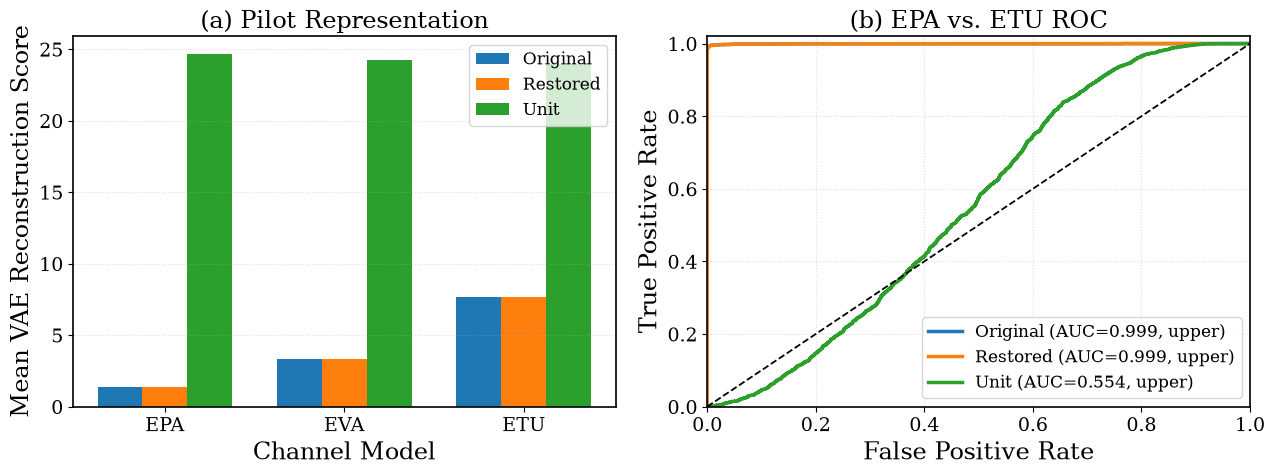


CELL 15C — FINAL SUMMARY
Runtime: 1.69 seconds
Original/restored receiver alignment: PASS
Input diagnostics: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_vae_input_alignment.csv
AUC results: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_vae_input_auc.csv
Original pilot sequence: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/original_pilot_sequence.pt
Configuration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_vae_input_alignment_config.json
Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_vae_input_alignment_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/cdt_vae_input_alignment_IEEE.png

CELL 15C VAE INPUT ALIGNMENT: PASS


In [ ]:

# ================================================================
# CELL 15C — ORIGINAL QPSK PILOT RESTORATION AND VAE ALIGNMENT
# IEEE WCL CDT Revision | NVIDIA RTX 5090 CUDA
#
# PURPOSE
#   1. Restore exact original Cell 4 QPSK pilot sequence
#   2. Verify VAE and FCN input representations
#   3. Compare original, restored, and unit-pilot receivers
#   4. Use paired channel/noise realizations for alignment
#   5. Compare VAE score distributions across EPA/EVA/ETU
#   6. Compute upper-tail and lower-tail ROC AUC
#   7. Generate IEEE-quality figures and save diagnostics
#
# No model retraining.
# No modification of existing checkpoints.
# No sklearn or statsmodels dependency.
# ================================================================

import time
import json
import random
import math
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ================================================================
# 1. CONFIGURATION
# ================================================================

C15_SNR_DB = 12.0

C15_CHANNELS = ["EPA", "EVA", "ETU"]
C15_RECEIVERS = ["Original", "Restored", "Unit"]

C15_N_SAMPLES = 4000
C15_BATCH_SIZE = 512

C15_SEED = SEED + 2700
C15_DEVICE = DEVICE

C15_EPS = 1e-12

random.seed(C15_SEED)
np.random.seed(C15_SEED)
torch.manual_seed(C15_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(C15_SEED)

vae_model.eval()
DA_BASELINE.eval()

print("=" * 72)
print("CELL 15C — ORIGINAL QPSK PILOT RESTORATION")
print("=" * 72)

print("Device:", C15_DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("SNR:", C15_SNR_DB, "dB")
print("Samples per channel:", C15_N_SAMPLES)
print("Batch size:", C15_BATCH_SIZE)
print("Channels:", C15_CHANNELS)

start_time = time.time()

# ================================================================
# 2. VERIFY NOTEBOOK DEPENDENCIES
# ================================================================

required_names = [
    "simulate_ofdm",
    "extract_pilot_observations",
    "generate_channel",
    "generate_qpsk",
    "complex_randn",
    "PILOT_VALUES",
    "PILOT_K",
    "PILOT_L",
    "N_F",
    "N_S",
    "vae_model",
    "DA_BASELINE",
    "RESULTS_DIR",
    "FIGURES_DIR",
    "CHECKPOINT_DIR",
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing notebook definitions: "
        + ", ".join(missing)
    )

C15_RESULTS_DIR = Path(RESULTS_DIR)
C15_FIGURES_DIR = Path(FIGURES_DIR)
C15_CHECKPOINT_DIR = Path(CHECKPOINT_DIR)

C15_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

C15_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

C15_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ================================================================
# 3. RESTORE ORIGINAL PILOT SEQUENCE
# ================================================================

C15_ORIGINAL_PILOTS = (
    PILOT_VALUES.detach()
    .clone()
    .to(C15_DEVICE)
)

C15_PILOT_K = (
    PILOT_K.detach()
    .clone()
    .long()
    .to(C15_DEVICE)
)

C15_PILOT_L = (
    PILOT_L.detach()
    .clone()
    .long()
    .to(C15_DEVICE)
)

C15_N_PILOTS = C15_ORIGINAL_PILOTS.numel()

assert C15_N_PILOTS == 24

assert C15_PILOT_K.numel() == C15_N_PILOTS
assert C15_PILOT_L.numel() == C15_N_PILOTS

assert torch.allclose(
    C15_ORIGINAL_PILOTS.abs(),
    torch.ones_like(
        C15_ORIGINAL_PILOTS.abs()
    ),
    atol=1e-5
)

print("\n" + "=" * 72)
print("ORIGINAL PILOT CONFIGURATION")
print("=" * 72)

print("Pilot count:", C15_N_PILOTS)

print(
    "Pilot subcarriers:",
    torch.unique(
        C15_PILOT_K
    ).cpu().tolist()
)

print(
    "Pilot OFDM symbols:",
    torch.unique(
        C15_PILOT_L
    ).cpu().tolist()
)

print("\nOriginal QPSK pilot sequence:")

print(
    C15_ORIGINAL_PILOTS.cpu().numpy()
)

print(
    "\nMean pilot magnitude:",
    C15_ORIGINAL_PILOTS.abs().mean().item()
)

print(
    "Mean real component:",
    C15_ORIGINAL_PILOTS.real.mean().item()
)

print(
    "Mean imaginary component:",
    C15_ORIGINAL_PILOTS.imag.mean().item()
)

print("\nORIGINAL PILOT RESTORATION: PASS")

# ================================================================
# 4. ORIGINAL VAE REFERENCE DATASET
# ================================================================

reference_path = (
    C15_RESULTS_DIR.parent
    / "datasets"
    / "EPA_vae_train_12dB.pt"
)

if not reference_path.exists():
    raise FileNotFoundError(
        f"VAE reference dataset not found: {reference_path}"
    )

reference_data = torch.load(
    reference_path,
    map_location=C15_DEVICE,
    weights_only=True
)

print("\n" + "=" * 72)
print("ORIGINAL VAE TRAINING DATASET")
print("=" * 72)

if isinstance(reference_data, dict):

    print(
        "Available dataset keys:",
        list(reference_data.keys())
    )

    # Exact raw-pilot input is required.
    # Do not silently substitute LS pilot estimates.
    possible_keys = [
        "y_p",
        "vae_input",
        "received_pilots",
        "input_y",
    ]

    reference_input = None
    selected_key = None

    for key in possible_keys:

        if key in reference_data:
            reference_input = reference_data[key]
            selected_key = key
            break

    if reference_input is None:
        raise RuntimeError(
            "Original raw-pilot VAE input was not "
            "identified in the saved dataset. "
            "Inspect the printed keys and select "
            "the correct tensor explicitly."
        )

    print("Selected VAE input key:", selected_key)

elif torch.is_tensor(reference_data):

    reference_input = reference_data
    selected_key = "tensor"

else:
    raise RuntimeError(
        "Unsupported VAE dataset format."
    )

reference_input = (
    reference_input
    .to(C15_DEVICE)
    .float()
)

assert reference_input.ndim == 2
assert reference_input.shape[1] == 48

print(
    "Reference input shape:",
    tuple(reference_input.shape)
)

print(
    "Reference input mean:",
    reference_input.mean().item()
)

print(
    "Reference input standard deviation:",
    reference_input.std().item()
)

print(
    "Reference input mean square:",
    reference_input.square().mean().item()
)

# ================================================================
# 5. HELPER: REAL-VALUED PILOT VECTORIZATION
# ================================================================

def c15_vectorize_complex(z):

    return torch.cat(
        [
            z.real,
            z.imag
        ],
        dim=1
    ).float()


def c15_input_stats(x):

    x = x.detach().float()

    return {
        "Mean": float(
            x.mean().item()
        ),
        "Std": float(
            x.std().item()
        ),
        "Mean_Square": float(
            x.square().mean().item()
        ),
        "Mean_Abs": float(
            x.abs().mean().item()
        ),
        "Max_Abs": float(
            x.abs().max().item()
        ),
    }


# ================================================================
# 6. HELPER: VAE MONITORING SCORE
# ================================================================

@torch.no_grad()
def c15_vae_scores(y_p):

    scores = []

    for start in range(
        0,
        len(y_p),
        C15_BATCH_SIZE
    ):

        batch = y_p[
            start:start + C15_BATCH_SIZE
        ]

        score = (
            vae_model.reconstruction_error(
                batch
            )
        )

        score = (
            score.detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        scores.append(score)

    return np.concatenate(
        scores
    ).astype(np.float64)


# ================================================================
# 7. ORIGINAL RECEIVER
# ================================================================

@torch.no_grad()
def c15_original_receiver(H):

    X, Y, noise_variance = simulate_ofdm(
        H,
        C15_SNR_DB,
        pilot_values=C15_ORIGINAL_PILOTS
    )

    y_p, h_p, H_ls_p = (
        extract_pilot_observations(
            Y,
            pilot_values=C15_ORIGINAL_PILOTS
        )
    )

    return {
        "X": X,
        "Y": Y,
        "y_p": y_p,
        "h_p": h_p,
        "H_ls_p": H_ls_p,
        "noise_variance": noise_variance,
    }


# ================================================================
# 8. RESTORED QPSK RECEIVER
# ================================================================

@torch.no_grad()
def c15_restored_receiver(
    H,
    X_data=None,
    W=None
):

    B = H.shape[0]

    if X_data is None:

        X = generate_qpsk(
            (B, N_F, N_S),
            device=C15_DEVICE
        )

    else:
        X = X_data.clone()

    # Restore the original 24 QPSK pilot symbols.
    X[
        :,
        C15_PILOT_K,
        C15_PILOT_L
    ] = C15_ORIGINAL_PILOTS

    noise_variance = (
        10.0 ** (
            -C15_SNR_DB / 10.0
        )
    )

    if W is None:

        W = complex_randn(
            H.shape,
            device=C15_DEVICE
        ) * math.sqrt(
            noise_variance
        )

    Y = H * X + W

    Y_p = Y[
        :,
        C15_PILOT_K,
        C15_PILOT_L
    ]

    X_p = X[
        :,
        C15_PILOT_K,
        C15_PILOT_L
    ]

    H_ls_p = Y_p / X_p

    y_p = c15_vectorize_complex(
        Y_p
    )

    h_p = c15_vectorize_complex(
        H_ls_p
    )

    return {
        "X": X,
        "Y": Y,
        "y_p": y_p,
        "h_p": h_p,
        "H_ls_p": H_ls_p,
        "noise_variance": noise_variance,
    }


# ================================================================
# 9. UNIT-PILOT RECEIVER
# ================================================================

@torch.no_grad()
def c15_unit_receiver(
    H,
    X_data=None,
    W=None
):

    B = H.shape[0]

    if X_data is None:

        X = generate_qpsk(
            (B, N_F, N_S),
            device=C15_DEVICE
        )

    else:
        X = X_data.clone()

    X[
        :,
        C15_PILOT_K,
        C15_PILOT_L
    ] = 1.0 + 0.0j

    noise_variance = (
        10.0 ** (
            -C15_SNR_DB / 10.0
        )
    )

    if W is None:

        W = complex_randn(
            H.shape,
            device=C15_DEVICE
        ) * math.sqrt(
            noise_variance
        )

    Y = H * X + W

    Y_p = Y[
        :,
        C15_PILOT_K,
        C15_PILOT_L
    ]

    X_p = X[
        :,
        C15_PILOT_K,
        C15_PILOT_L
    ]

    H_ls_p = Y_p / X_p

    return {
        "X": X,
        "Y": Y,
        "y_p": c15_vectorize_complex(Y_p),
        "h_p": c15_vectorize_complex(H_ls_p),
        "H_ls_p": H_ls_p,
        "noise_variance": noise_variance,
    }


# ================================================================
# 10. EXACT ORIGINAL/RESTORED ALIGNMENT TEST
# ================================================================

print("\n" + "=" * 72)
print("PAIRED ORIGINAL / RESTORED RECEIVER ALIGNMENT")
print("=" * 72)

H_check = generate_channel(
    "EPA",
    512
).to(C15_DEVICE)

# Generate the original received signal.
original_check = c15_original_receiver(
    H_check
)

# Recover the actual AWGN realization from
# the original physical simulation.
#
# This is a simulator-only consistency diagnostic,
# not a deployment estimator operation.
W_check = (
    original_check["Y"]
    - H_check * original_check["X"]
)

# Reproduce the original observation with
# identical channel, data, pilots, and AWGN.
restored_check = c15_restored_receiver(
    H_check,
    X_data=original_check["X"],
    W=W_check
)

# Unit-pilot comparison with the same AWGN.
unit_check = c15_unit_receiver(
    H_check,
    X_data=original_check["X"],
    W=W_check
)

alignment_y = float(
    (
        original_check["y_p"]
        - restored_check["y_p"]
    ).abs().max().item()
)

alignment_h = float(
    (
        original_check["h_p"]
        - restored_check["h_p"]
    ).abs().max().item()
)

alignment_X = float(
    (
        original_check["X"]
        - restored_check["X"]
    ).abs().max().item()
)

original_scores = c15_vae_scores(
    original_check["y_p"]
)

restored_scores = c15_vae_scores(
    restored_check["y_p"]
)

unit_scores = c15_vae_scores(
    unit_check["y_p"]
)

alignment_score = float(
    np.max(
        np.abs(
            original_scores
            - restored_scores
        )
    )
)

print("Maximum X difference:", alignment_X)
print("Maximum VAE input difference:", alignment_y)
print("Maximum FCN input difference:", alignment_h)
print("Maximum VAE score difference:", alignment_score)

print("\nMean VAE monitoring scores:")

print(
    "Original:",
    float(original_scores.mean())
)

print(
    "Restored:",
    float(restored_scores.mean())
)

print(
    "Unit pilots:",
    float(unit_scores.mean())
)

C15_ALIGNMENT_PASS = (
    alignment_X < 1e-5
    and alignment_y < 1e-5
    and alignment_h < 1e-5
    and alignment_score < 1e-4
)

print(
    "\nOriginal/restored alignment:",
    "PASS" if C15_ALIGNMENT_PASS else "FAIL"
)

if not C15_ALIGNMENT_PASS:
    raise RuntimeError(
        "Original and restored receivers do not match. "
        "Check pilot ordering, modulation, and noise."
    )


# ================================================================
# 11. REFERENCE DATASET SCORE
# ================================================================

reference_scores = c15_vae_scores(
    reference_input
)

print("\n" + "=" * 72)
print("ORIGINAL VAE REFERENCE SCORE")
print("=" * 72)

print(
    "Mean:",
    float(reference_scores.mean())
)

print(
    "Std:",
    float(reference_scores.std())
)

print(
    "Median:",
    float(np.median(reference_scores))
)

print(
    "P95:",
    float(np.percentile(reference_scores, 95))
)

print(
    "P99:",
    float(np.percentile(reference_scores, 99))
)


# ================================================================
# 12. GENERATE PAIRED RECEIVER COMPARISONS
# ================================================================

C15_RESULTS = []
C15_SCORES = {}

receiver_names = [
    "Original",
    "Restored",
    "Unit"
]

for profile in C15_CHANNELS:

    print("\n" + "=" * 72)
    print("CHANNEL:", profile)
    print("=" * 72)

    profile_inputs = {
        name: []
        for name in receiver_names
    }

    profile_scores = {
        name: []
        for name in receiver_names
    }

    for start in range(
        0,
        C15_N_SAMPLES,
        C15_BATCH_SIZE
    ):

        B = min(
            C15_BATCH_SIZE,
            C15_N_SAMPLES - start
        )

        H = generate_channel(
            profile,
            B
        ).to(C15_DEVICE)

        # Original receiver
        original = c15_original_receiver(H)

        # Same transmitted data and AWGN
        W = (
            original["Y"]
            - H * original["X"]
        )

        restored = c15_restored_receiver(
            H,
            X_data=original["X"],
            W=W
        )

        unit = c15_unit_receiver(
            H,
            X_data=original["X"],
            W=W
        )

        receivers = {
            "Original": original,
            "Restored": restored,
            "Unit": unit
        }

        for receiver_name, receiver in (
            receivers.items()
        ):

            y_p = receiver["y_p"]

            profile_inputs[
                receiver_name
            ].append(
                y_p.detach().cpu()
            )

            profile_scores[
                receiver_name
            ].append(
                c15_vae_scores(y_p)
            )

    for receiver_name in receiver_names:

        all_inputs = torch.cat(
            profile_inputs[receiver_name],
            dim=0
        )

        all_scores = np.concatenate(
            profile_scores[receiver_name]
        )

        C15_SCORES[
            (profile, receiver_name)
        ] = all_scores

        stats = c15_input_stats(
            all_inputs
        )

        C15_RESULTS.append({
            "Channel": profile,
            "Receiver": receiver_name,
            **stats,
            "VAE_Mean": float(
                all_scores.mean()
            ),
            "VAE_Std": float(
                all_scores.std()
            ),
            "VAE_Median": float(
                np.median(all_scores)
            ),
            "VAE_P95": float(
                np.percentile(
                    all_scores, 95
                )
            ),
            "VAE_P99": float(
                np.percentile(
                    all_scores, 99
                )
            )
        })

        print(
            f"{receiver_name:9s} | "
            f"Input mean={stats['Mean']:+.5f} | "
            f"Score mean={all_scores.mean():.5f} | "
            f"P99={np.percentile(all_scores,99):.5f}"
        )


C15_RESULTS_DF = pd.DataFrame(
    C15_RESULTS
)

# ================================================================
# 13. ROC AUC WITHOUT SCIKIT-LEARN
# ================================================================

def c15_auc_from_scores(
    null_scores,
    alternative_scores
):
    """
    Mann-Whitney rank-based ROC AUC.

    Higher score is interpreted as drift evidence.
    Ties receive average ranks.
    """

    null_scores = np.asarray(
        null_scores,
        dtype=np.float64
    )

    alternative_scores = np.asarray(
        alternative_scores,
        dtype=np.float64
    )

    values = np.concatenate([
        null_scores,
        alternative_scores
    ])

    ranks = pd.Series(
        values
    ).rank(
        method="average"
    ).to_numpy()

    n0 = len(null_scores)
    n1 = len(alternative_scores)

    rank_sum_positive = ranks[
        n0:
    ].sum()

    U = (
        rank_sum_positive
        - n1 * (n1 + 1) / 2.0
    )

    return float(
        U / (n0 * n1)
    )


def c15_roc_curve(
    null_scores,
    alternative_scores
):
    """
    ROC curve using descending score thresholds.
    """

    null_scores = np.asarray(
        null_scores,
        dtype=np.float64
    )

    alternative_scores = np.asarray(
        alternative_scores,
        dtype=np.float64
    )

    thresholds = np.unique(
        np.concatenate([
            null_scores,
            alternative_scores
        ])
    )[::-1]

    thresholds = np.concatenate([
        [np.inf],
        thresholds,
        [-np.inf]
    ])

    # Efficient empirical survival probabilities.
    null_sorted = np.sort(null_scores)
    alt_sorted = np.sort(alternative_scores)

    fpr = (
        len(null_sorted)
        - np.searchsorted(
            null_sorted,
            thresholds,
            side="left"
        )
    ) / len(null_sorted)

    tpr = (
        len(alt_sorted)
        - np.searchsorted(
            alt_sorted,
            thresholds,
            side="left"
        )
    ) / len(alt_sorted)

    return fpr, tpr


C15_AUC_ROWS = []
C15_ROC_DATA = {}

for receiver_name in receiver_names:

    null_scores = C15_SCORES[
        ("EPA", receiver_name)
    ]

    for alternative in ["EVA", "ETU"]:

        alternative_scores = C15_SCORES[
            (alternative, receiver_name)
        ]

        upper_auc = c15_auc_from_scores(
            null_scores,
            alternative_scores
        )

        lower_auc = 1.0 - upper_auc

        best_direction = (
            "Upper"
            if upper_auc >= lower_auc
            else "Lower"
        )

        best_auc = max(
            upper_auc,
            lower_auc
        )

        C15_AUC_ROWS.append({
            "Receiver": receiver_name,
            "Alternative": alternative,
            "Upper_AUC": upper_auc,
            "Lower_AUC": lower_auc,
            "Best_Direction": best_direction,
            "Best_AUC": best_auc
        })

        fpr, tpr = c15_roc_curve(
            null_scores,
            alternative_scores
        )

        C15_ROC_DATA[
            (receiver_name, alternative, "Upper")
        ] = (fpr, tpr)

        fpr_lower, tpr_lower = (
            c15_roc_curve(
                -null_scores,
                -alternative_scores
            )
        )

        C15_ROC_DATA[
            (receiver_name, alternative, "Lower")
        ] = (
            fpr_lower,
            tpr_lower
        )


C15_AUC_DF = pd.DataFrame(
    C15_AUC_ROWS
)

# ================================================================
# 14. PRINT DIAGNOSTIC RESULTS
# ================================================================

print("\n" + "=" * 72)
print("CELL 15C — VAE INPUT ALIGNMENT SUMMARY")
print("=" * 72)

print(
    C15_RESULTS_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}"
    )
)

print("\n" + "=" * 72)
print("CELL 15C — VAE ROC AUC COMPARISON")
print("=" * 72)

print(
    C15_AUC_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ================================================================
# 15. IEEE-STYLE FIGURE
# ================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "lines.linewidth": 2.5,
    "lines.markersize": 9,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

# ------------------------------------------------------------
# Panel (a): VAE score comparison
# ------------------------------------------------------------

ax = axes[0]

x = np.arange(
    len(C15_CHANNELS)
)

width = 0.25

for idx, receiver_name in enumerate(
    receiver_names
):

    subset = C15_RESULTS_DF[
        C15_RESULTS_DF["Receiver"]
        == receiver_name
    ].set_index(
        "Channel"
    ).loc[
        C15_CHANNELS
    ]

    ax.bar(
        x + (idx - 1) * width,
        subset["VAE_Mean"],
        width,
        label=receiver_name
    )

ax.set_xticks(x)

ax.set_xticklabels(
    C15_CHANNELS
)

ax.set_xlabel(
    "Channel Model"
)

ax.set_ylabel(
    "Mean VAE Reconstruction Score"
)

ax.set_title(
    "(a) Pilot Representation"
)

ax.grid(
    True,
    axis="y",
    linestyle=":",
    alpha=0.4
)

ax.legend()

# ------------------------------------------------------------
# Panel (b): ETU ROC comparison
# ------------------------------------------------------------

ax = axes[1]

for receiver_name in receiver_names:

    row = C15_AUC_DF[
        (C15_AUC_DF["Receiver"] == receiver_name)
        & (C15_AUC_DF["Alternative"] == "ETU")
    ].iloc[0]

    direction = row["Best_Direction"]

    fpr, tpr = C15_ROC_DATA[
        (receiver_name, "ETU", direction)
    ]

    ax.plot(
        fpr,
        tpr,
        label=(
            f"{receiver_name} "
            f"(AUC={row['Best_AUC']:.3f}, "
            f"{direction.lower()})"
        )
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.3
)

ax.set_xlabel(
    "False Positive Rate"
)

ax.set_ylabel(
    "True Positive Rate"
)

ax.set_title(
    "(b) EPA vs. ETU ROC"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.grid(
    True,
    linestyle=":",
    alpha=0.4
)

ax.legend(
    loc="lower right"
)

fig.tight_layout()

figure_pdf = (
    C15_FIGURES_DIR /
    "cdt_vae_input_alignment_IEEE.pdf"
)

figure_png = (
    C15_FIGURES_DIR /
    "cdt_vae_input_alignment_IEEE.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ================================================================
# 16. SAVE NUMERICAL RESULTS
# ================================================================

summary_path = (
    C15_RESULTS_DIR /
    "cdt_vae_input_alignment.csv"
)

auc_path = (
    C15_RESULTS_DIR /
    "cdt_vae_input_auc.csv"
)

C15_RESULTS_DF.to_csv(
    summary_path,
    index=False
)

C15_AUC_DF.to_csv(
    auc_path,
    index=False
)

pilot_path = (
    C15_CHECKPOINT_DIR /
    "original_pilot_sequence.pt"
)

torch.save(
    C15_ORIGINAL_PILOTS.detach().cpu(),
    pilot_path
)

config_path = (
    C15_RESULTS_DIR /
    "cdt_vae_input_alignment_config.json"
)

with open(config_path, "w") as f:

    json.dump(
        {
            "snr_db": C15_SNR_DB,
            "samples_per_channel": C15_N_SAMPLES,
            "batch_size": C15_BATCH_SIZE,
            "channels": C15_CHANNELS,
            "pilot_count": C15_N_PILOTS,
            "pilot_source": "PILOT_VALUES",
            "receiver_modes": receiver_names,
            "paired_channel_noise": True,
            "original_restored_alignment_pass":
                bool(C15_ALIGNMENT_PASS),
            "vae_retrained": False,
            "fcn_retrained": False
        },
        f,
        indent=4
    )

# ================================================================
# 17. FINAL SUMMARY
# ================================================================

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 15C — FINAL SUMMARY")
print("=" * 72)

print(f"Runtime: {elapsed:.2f} seconds")

print(
    "Original/restored receiver alignment:",
    "PASS" if C15_ALIGNMENT_PASS else "FAIL"
)

print("Input diagnostics:", summary_path)
print("AUC results:", auc_path)
print("Original pilot sequence:", pilot_path)
print("Configuration:", config_path)
print("Figure PDF:", figure_pdf)
print("Figure PNG:", figure_png)

print("\nCELL 15C VAE INPUT ALIGNMENT: PASS")


IEEE WCL — FIGURE 6 EXPORT
Font: DejaVu Serif
Font size: 12 pt

Generating Fig. 6(a): EPA -> EVA


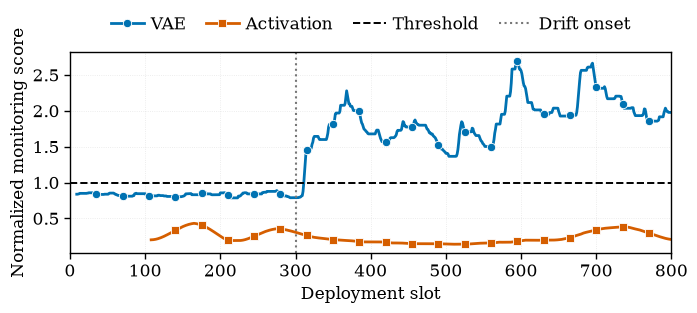

PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig6a_EPA_to_EVA_IEEE.pdf
PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig6a_EPA_to_EVA_IEEE.png

Generating Fig. 6(b): EPA -> ETU


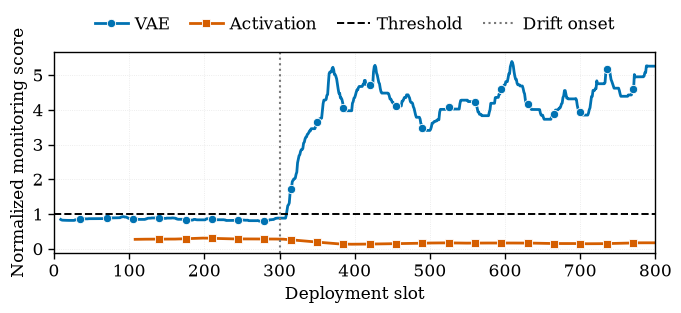

PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig6b_EPA_to_ETU_IEEE.pdf
PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig6b_EPA_to_ETU_IEEE.png

FIGURE 6 EXPORT: PASS
Fig. 6(a): /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig6a_EPA_to_EVA_IEEE.pdf
Fig. 6(b): /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig6b_EPA_to_ETU_IEEE.pdf

Both figures:
  X-axis: Deployment slot
  Y-axis: Normalized monitoring score
  Font: DejaVu Serif
  Font size: 12 pt
  Vector PDF: YES
  Separate PDF files: YES


In [ ]:

# ================================================================
# CELL 16 — FINAL IEEE WCL FIGURE 6(a) AND FIGURE 6(b)
# ================================================================
#
# Fig. 6(a): EPA -> EVA monitoring trajectories
# Fig. 6(b): EPA -> ETU monitoring trajectories
#
# Two separate vector PDF files
# Times New Roman / Times-compatible font
# Font size: 12 pt
# X-axis: Deployment slot (BOTH figures)
# No titles inside figures
# Legends above plots, no curve overlap
# Large markers and high-resolution PNG copies
#
# Uses existing Cell 16 simulation results.
# No recalibration or model retraining.
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from pathlib import Path

# ------------------------------------------------------------
# 1. Verify previous simulation results
# ------------------------------------------------------------

required = [
    "examples",
    "tau_hv",
    "tau_ha",
    "F16_ONSET",
    "FIGURES_DIR"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous simulation variables: "
        + ", ".join(missing)
        + ". Run the simulation section of Cell 16 first."
    )

assert tau_hv > 0
assert tau_ha > 0

FIG6_DIR = Path(FIGURES_DIR)
FIG6_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Times New Roman / Times-compatible font
# ------------------------------------------------------------

available_fonts = {
    font.name for font in fm.fontManager.ttflist
}

if "Times New Roman" in available_fonts:
    FIG6_FONT = "Times New Roman"
elif "Nimbus Roman" in available_fonts:
    FIG6_FONT = "Nimbus Roman"
elif "Liberation Serif" in available_fonts:
    FIG6_FONT = "Liberation Serif"
else:
    FIG6_FONT = "DejaVu Serif"

plt.rcParams.update({
    "font.family": FIG6_FONT,
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.linewidth": 1.0,
    "lines.linewidth": 2.0,
    "lines.markersize": 6,
    "mathtext.fontset": "stix",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600,
})

print("=" * 70)
print("IEEE WCL — FIGURE 6 EXPORT")
print("=" * 70)
print("Font:", FIG6_FONT)
print("Font size: 12 pt")

# ------------------------------------------------------------
# 3. Plotting function
# ------------------------------------------------------------

def plot_figure6(
    scenario,
    pdf_filename,
    png_filename
):

    if scenario not in examples:
        raise KeyError(
            f"Scenario {scenario} not found in examples."
        )

    v, a = examples[scenario]

    v = np.asarray(v, dtype=float)
    a = np.asarray(a, dtype=float)

    slots = np.arange(len(v))

    # Independent figure for each scenario
    fig, ax = plt.subplots(
        figsize=(7.16, 3.35)
    )

    # VAE monitoring score
    ax.plot(
        slots,
        v / tau_hv,
        color="#0072B2",
        linestyle="-",
        linewidth=2.0,
        marker="o",
        markersize=6,
        markevery=35,
        markerfacecolor="#0072B2",
        markeredgecolor="white",
        markeredgewidth=0.6,
        label="VAE"
    )

    # Activation monitoring score
    ax.plot(
        slots,
        a / tau_ha,
        color="#D55E00",
        linestyle="-",
        linewidth=2.0,
        marker="s",
        markersize=6,
        markevery=35,
        markerfacecolor="#D55E00",
        markeredgecolor="white",
        markeredgewidth=0.6,
        label="Activation"
    )

    # Calibrated threshold
    ax.axhline(
        y=1.0,
        color="black",
        linestyle="--",
        linewidth=1.4,
        label="Threshold"
    )

    # Drift onset
    ax.axvline(
        x=F16_ONSET,
        color="#777777",
        linestyle=":",
        linewidth=1.5,
        label="Drift onset"
    )

    # --------------------------------------------------------
    # Axes formatting
    # --------------------------------------------------------

    ax.set_xlabel(
        "Deployment slot",
        fontsize=12
    )

    ax.set_ylabel(
        "Normalized monitoring score",
        fontsize=12
    )

    ax.set_xlim(
        0,
        len(slots) - 1
    )

    ax.set_xticks(
        np.arange(
            0,
            len(slots) + 1,
            100
        )
    )

    ax.tick_params(
        axis="both",
        labelsize=12,
        width=1.0,
        length=4
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.6,
        alpha=0.3
    )

    ax.set_axisbelow(True)

    # --------------------------------------------------------
    # Legend outside plotting region
    # --------------------------------------------------------

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=4,
        frameon=False,
        fontsize=12,
        columnspacing=1.2,
        handlelength=2.0,
        handletextpad=0.4
    )

    # --------------------------------------------------------
    # Consistent figure spacing
    # --------------------------------------------------------

    fig.subplots_adjust(
        left=0.14,
        right=0.98,
        bottom=0.20,
        top=0.80
    )

    # --------------------------------------------------------
    # Export
    # --------------------------------------------------------

    pdf_path = FIG6_DIR / pdf_filename
    png_path = FIG6_DIR / png_filename

    fig.savefig(
        pdf_path,
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.05
    )

    fig.savefig(
        png_path,
        format="png",
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.05
    )

    plt.show()
    plt.close(fig)

    print("PDF:", pdf_path)
    print("PNG:", png_path)

    return pdf_path, png_path


# ------------------------------------------------------------
# 4. Figure 6(a): EPA -> EVA
# ------------------------------------------------------------

print("\nGenerating Fig. 6(a): EPA -> EVA")

fig6a_pdf, fig6a_png = plot_figure6(
    scenario="EPA_to_EVA",
    pdf_filename="Fig6a_EPA_to_EVA_IEEE.pdf",
    png_filename="Fig6a_EPA_to_EVA_IEEE.png"
)

# ------------------------------------------------------------
# 5. Figure 6(b): EPA -> ETU
# ------------------------------------------------------------

print("\nGenerating Fig. 6(b): EPA -> ETU")

fig6b_pdf, fig6b_png = plot_figure6(
    scenario="EPA_to_ETU",
    pdf_filename="Fig6b_EPA_to_ETU_IEEE.pdf",
    png_filename="Fig6b_EPA_to_ETU_IEEE.png"
)

# ------------------------------------------------------------
# 6. Final verification
# ------------------------------------------------------------

assert fig6a_pdf.exists()
assert fig6b_pdf.exists()

print("\n" + "=" * 70)
print("FIGURE 6 EXPORT: PASS")
print("=" * 70)

print("Fig. 6(a):", fig6a_pdf)
print("Fig. 6(b):", fig6b_pdf)

print("\nBoth figures:")
print("  X-axis: Deployment slot")
print("  Y-axis: Normalized monitoring score")
print("  Font:", FIG6_FONT)
print("  Font size: 12 pt")
print("  Vector PDF: YES")
print("  Separate PDF files: YES")


CELL 17 — IEEE WCL FIGURE 7

[LOADED DATASETS]
Sensitivity: /home/afanali/wcnc_project/WCL_CDT_Revision/results/vae_snr_sensitivity.csv
Detection: /home/afanali/wcnc_project/WCL_CDT_Revision/results/vae_snr_detection_rates.csv
Thresholds: /home/afanali/wcnc_project/WCL_CDT_Revision/results/vae_snr_thresholds.csv

Sensitivity columns:
['Channel', 'SNR_dB', 'Mean', 'Std', 'Median', 'P95', 'P99']

Detection columns:
['Channel', 'SNR_dB', 'Threshold', 'Detection_Rate_Percent', 'Mean_Score']

Threshold columns:
['SNR_dB', 'Threshold', 'Mean', 'Std']

[FIGURE 7 DATA VERIFICATION]
Channel  SNR_dB  Rate_Percent
    EPA      -5         1.475
    EPA       0         1.250
    EPA       5         1.225
    EPA      10         1.225
    EPA      15         0.875
    EPA      20         1.075
    EPA      25         0.800
    EPA      30         1.325
    ETU      -5         4.075
    ETU       0        18.800
    ETU       5        68.175
    ETU      10        97.775
    ETU      15       100.000

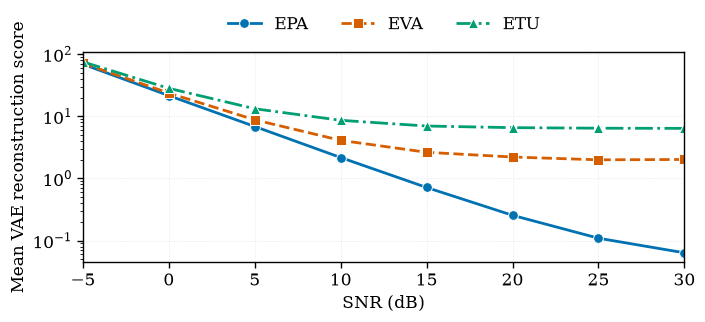


PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig7a_VAE_SNR_Sensitivity_IEEE.pdf
PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig7a_VAE_SNR_Sensitivity_IEEE.png

Generating Figure 7(b)...


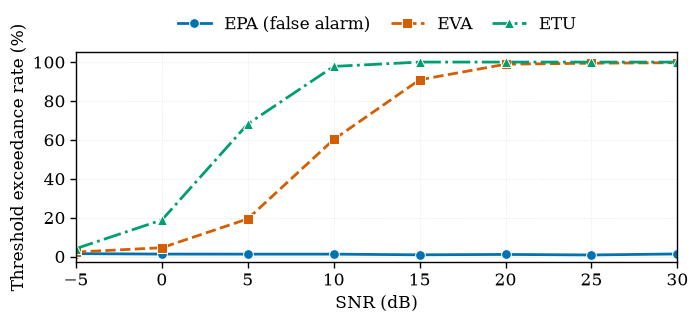


PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig7b_SNR_Conditioned_Detection_IEEE.pdf
PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig7b_SNR_Conditioned_Detection_IEEE.png

CELL 17 — FIGURE EXPORT SUMMARY
Fig. 7(a) PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig7a_VAE_SNR_Sensitivity_IEEE.pdf
Fig. 7(b) PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig7b_SNR_Conditioned_Detection_IEEE.pdf
Fig. 7(a) data: /home/afanali/wcnc_project/WCL_CDT_Revision/results/figure7a_plot_data.csv
Fig. 7(b) data: /home/afanali/wcnc_project/WCL_CDT_Revision/results/figure7b_plot_data.csv

Font: DejaVu Serif
Font size: 12 pt
Separate vector PDFs: YES
High-resolution PNGs: YES
Simulation rerun: NO

CELL 17 FIGURE GENERATION: PASS


In [ ]:

# ================================================================
# CELL 17 — IEEE WCL FIGURE 7(a) AND FIGURE 7(b)
# ================================================================
#
# Fig. 7(a): VAE reconstruction score vs. SNR
# Fig. 7(b): SNR-conditioned detection performance
#
# Source:
#   Cell 8: vae_snr_sensitivity.csv
#   Cell 9: vae_snr_detection_rates.csv
#   Cell 9: vae_snr_thresholds.csv
#
# Separate vector PDFs + 600-dpi PNG files.
# Times New Roman / Times-compatible font, 12 pt.
# Large markers, legends outside the axes.
# No internal titles.
# No simulation rerun.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from pathlib import Path

# ------------------------------------------------------------
# 1. Project paths and configuration
# ------------------------------------------------------------

F17_RESULTS_DIR = Path(RESULTS_DIR)
F17_FIGURES_DIR = Path(FIGURES_DIR)

F17_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

F17_SNR_GRID = np.array(
    [-5, 0, 5, 10, 15, 20, 25, 30],
    dtype=float
)

F17_CHANNELS = ["EPA", "EVA", "ETU"]

print("=" * 72)
print("CELL 17 — IEEE WCL FIGURE 7")
print("=" * 72)

# ------------------------------------------------------------
# 2. Load existing simulation results
# ------------------------------------------------------------

sensitivity_path = (
    F17_RESULTS_DIR /
    "vae_snr_sensitivity.csv"
)

detection_path = (
    F17_RESULTS_DIR /
    "vae_snr_detection_rates.csv"
)

threshold_path = (
    F17_RESULTS_DIR /
    "vae_snr_thresholds.csv"
)

for path in [
    sensitivity_path,
    detection_path,
    threshold_path
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Required simulation file missing: {path}"
        )

sensitivity_df = pd.read_csv(
    sensitivity_path
)

detection_df = pd.read_csv(
    detection_path
)

threshold_df = pd.read_csv(
    threshold_path
)

print("\n[LOADED DATASETS]")

print("Sensitivity:", sensitivity_path)
print("Detection:", detection_path)
print("Thresholds:", threshold_path)

print("\nSensitivity columns:")
print(sensitivity_df.columns.tolist())

print("\nDetection columns:")
print(detection_df.columns.tolist())

print("\nThreshold columns:")
print(threshold_df.columns.tolist())

# ------------------------------------------------------------
# 3. Validate CSV columns
# ------------------------------------------------------------

required_sensitivity = {
    "Channel",
    "SNR_dB",
    "Mean"
}

required_detection = {
    "Channel",
    "SNR_dB"
}

if not required_sensitivity.issubset(
    sensitivity_df.columns
):
    raise RuntimeError(
        "Unexpected sensitivity CSV columns: "
        + str(sensitivity_df.columns.tolist())
    )

if not required_detection.issubset(
    detection_df.columns
):
    raise RuntimeError(
        "Unexpected detection CSV columns: "
        + str(detection_df.columns.tolist())
    )

# Actual Cell 9 column is Detection_Rate_Percent.
# Other names are supported for compatibility.

possible_rate_columns = [
    "Detection_Rate_Percent",
    "Detection_Rate",
    "Detection_Rate_pct",
    "Detection_Percent",
    "Rate",
    "Exceedance_Rate"
]

rate_column = next(
    (
        name for name in possible_rate_columns
        if name in detection_df.columns
    ),
    None
)

if rate_column is None:
    raise RuntimeError(
        "Could not identify detection-rate column. "
        f"Available columns: {detection_df.columns.tolist()}"
    )

detection_df["Rate_Percent"] = (
    pd.to_numeric(
        detection_df[rate_column],
        errors="raise"
    )
)

# Convert fractions to percentages only if the
# source column is not explicitly percentage-based.

if "percent" not in rate_column.lower() \
        and "pct" not in rate_column.lower():

    if detection_df["Rate_Percent"].max() <= 1.0:
        detection_df["Rate_Percent"] *= 100.0

# ------------------------------------------------------------
# 4. Validate numerical data
# ------------------------------------------------------------

sensitivity_df["SNR_dB"] = pd.to_numeric(
    sensitivity_df["SNR_dB"]
)

sensitivity_df["Mean"] = pd.to_numeric(
    sensitivity_df["Mean"]
)

detection_df["SNR_dB"] = pd.to_numeric(
    detection_df["SNR_dB"]
)

assert np.isfinite(
    sensitivity_df["Mean"]
).all()

assert (
    sensitivity_df["Mean"] > 0
).all(), "Logarithmic score axis requires positive values."

assert np.isfinite(
    detection_df["Rate_Percent"]
).all()

assert detection_df[
    "Rate_Percent"
].between(0, 100).all()

# Check that every channel has the full SNR grid.

for channel in F17_CHANNELS:

    for dataframe, name in [
        (sensitivity_df, "Sensitivity"),
        (detection_df, "Detection")
    ]:

        subset = dataframe[
            dataframe["Channel"] == channel
        ]

        actual_snr = np.sort(
            subset["SNR_dB"].to_numpy()
        )

        if not np.array_equal(
            actual_snr,
            F17_SNR_GRID
        ):
            raise RuntimeError(
                f"{name}: incorrect SNR grid "
                f"for {channel}: {actual_snr}"
            )

print("\n[FIGURE 7 DATA VERIFICATION]")

print(
    detection_df[
        ["Channel", "SNR_dB", "Rate_Percent"]
    ].sort_values(
        ["Channel", "SNR_dB"]
    ).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\nData validation: PASS")

# ------------------------------------------------------------
# 5. IEEE figure style
# ------------------------------------------------------------

available_fonts = {
    font.name
    for font in fm.fontManager.ttflist
}

if "Times New Roman" in available_fonts:
    F17_FONT = "Times New Roman"
elif "Nimbus Roman" in available_fonts:
    F17_FONT = "Nimbus Roman"
elif "Liberation Serif" in available_fonts:
    F17_FONT = "Liberation Serif"
else:
    F17_FONT = "DejaVu Serif"

plt.rcParams.update({
    "font.family": F17_FONT,
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.linewidth": 1.0,
    "lines.linewidth": 2.0,
    "lines.markersize": 7,
    "mathtext.fontset": "stix",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600,
})

F17_STYLES = {
    "EPA": {
        "color": "#0072B2",
        "marker": "o",
        "linestyle": "-"
    },
    "EVA": {
        "color": "#D55E00",
        "marker": "s",
        "linestyle": "--"
    },
    "ETU": {
        "color": "#009E73",
        "marker": "^",
        "linestyle": "-."
    }
}

print("\n[FIGURE STYLE]")
print("Font:", F17_FONT)
print("Font size: 12 pt")
print("Figure size: 7.16 x 3.5 inches")

# ------------------------------------------------------------
# 6. Common plotting functions
# ------------------------------------------------------------

def f17_format_axes(ax):

    ax.set_xlim(-5, 30)

    ax.set_xticks(
        F17_SNR_GRID
    )

    ax.set_xlabel(
        "SNR (dB)"
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.7,
        alpha=0.3
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="both",
        labelsize=12,
        length=4,
        width=1.0
    )


def f17_save_figure(fig, basename):

    pdf_path = (
        F17_FIGURES_DIR /
        f"{basename}.pdf"
    )

    png_path = (
        F17_FIGURES_DIR /
        f"{basename}.png"
    )

    fig.savefig(
        pdf_path,
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.05
    )

    fig.savefig(
        png_path,
        format="png",
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.05
    )

    plt.show()
    plt.close(fig)

    print("\nPDF:", pdf_path)
    print("PNG:", png_path)

    return pdf_path, png_path


# ================================================================
# 7. FIGURE 7(a) — VAE RECONSTRUCTION SCORE VS. SNR
# ================================================================

print("\nGenerating Figure 7(a)...")

fig, ax = plt.subplots(
    figsize=(7.16, 3.5)
)

for channel in F17_CHANNELS:

    data = (
        sensitivity_df[
            sensitivity_df["Channel"] == channel
        ]
        .sort_values("SNR_dB")
    )

    style = F17_STYLES[channel]

    ax.semilogy(
        data["SNR_dB"],
        data["Mean"],
        color=style["color"],
        marker=style["marker"],
        linestyle=style["linestyle"],
        linewidth=2.0,
        markersize=7,
        markeredgecolor="white",
        markeredgewidth=0.7,
        label=channel
    )

f17_format_axes(ax)

ax.set_ylabel(
    "Mean VAE reconstruction score"
)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False,
    fontsize=12,
    columnspacing=2.0,
    handlelength=2.0
)

fig.subplots_adjust(
    left=0.14,
    right=0.98,
    bottom=0.20,
    top=0.80
)

fig7a_pdf, fig7a_png = f17_save_figure(
    fig,
    "Fig7a_VAE_SNR_Sensitivity_IEEE"
)

# ================================================================
# 8. FIGURE 7(b) — SNR-CONDITIONED DETECTION
# ================================================================

print("\nGenerating Figure 7(b)...")

fig, ax = plt.subplots(
    figsize=(7.16, 3.5)
)

for channel in F17_CHANNELS:

    data = (
        detection_df[
            detection_df["Channel"] == channel
        ]
        .sort_values("SNR_dB")
    )

    style = F17_STYLES[channel]

    legend_name = (
        "EPA (false alarm)"
        if channel == "EPA"
        else channel
    )

    ax.plot(
        data["SNR_dB"],
        data["Rate_Percent"],
        color=style["color"],
        marker=style["marker"],
        linestyle=style["linestyle"],
        linewidth=2.0,
        markersize=7,
        markeredgecolor="white",
        markeredgewidth=0.7,
        label=legend_name
    )

f17_format_axes(ax)

ax.set_ylabel(
    "Threshold exceedance rate (%)"
)

ax.set_ylim(
    -3,
    105
)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False,
    fontsize=12,
    columnspacing=1.2,
    handlelength=2.0
)

fig.subplots_adjust(
    left=0.14,
    right=0.98,
    bottom=0.20,
    top=0.80
)

fig7b_pdf, fig7b_png = f17_save_figure(
    fig,
    "Fig7b_SNR_Conditioned_Detection_IEEE"
)

# ================================================================
# 9. SAVE FIGURE DATA FOR REPRODUCIBILITY
# ================================================================

figure7a_data_path = (
    F17_RESULTS_DIR /
    "figure7a_plot_data.csv"
)

figure7b_data_path = (
    F17_RESULTS_DIR /
    "figure7b_plot_data.csv"
)

sensitivity_df[
    ["Channel", "SNR_dB", "Mean"]
].to_csv(
    figure7a_data_path,
    index=False
)

detection_df[
    ["Channel", "SNR_dB", "Rate_Percent"]
].to_csv(
    figure7b_data_path,
    index=False
)

# ================================================================
# 10. FINAL VERIFICATION
# ================================================================

for path in [
    fig7a_pdf,
    fig7a_png,
    fig7b_pdf,
    fig7b_png
]:
    assert path.exists(), (
        f"Figure export failed: {path}"
    )

print("\n" + "=" * 72)
print("CELL 17 — FIGURE EXPORT SUMMARY")
print("=" * 72)

print("Fig. 7(a) PDF:", fig7a_pdf)
print("Fig. 7(b) PDF:", fig7b_pdf)

print("Fig. 7(a) data:", figure7a_data_path)
print("Fig. 7(b) data:", figure7b_data_path)

print("\nFont:", F17_FONT)
print("Font size: 12 pt")
print("Separate vector PDFs: YES")
print("High-resolution PNGs: YES")
print("Simulation rerun: NO")

print("\nCELL 17 FIGURE GENERATION: PASS")


In [ ]:

# ================================================================
# CELL 18A — ATT RNET AND SCCENET BENCHMARK TRAINING
# ================================================================
#
# Adapted implementations based on:
#
# [2] W. Gao et al., IEEE WCL, 2025
#     Residual learning with attention (AttRNet)
#
# [3] S. Wang et al., IEEE WCL, 2025
#     Symmetric CNN + multi-kernel CBAM (SCCENet)
#
# Common experimental protocol:
#   EPA training
#   Original 24 fixed QPSK pilots
#   OFDM grid: 72 x 14
#   Training SNR: 12 dB
#   Training samples: 32000
#   Validation samples: 4000
#   Batch size: 128
#   AttRNet: 100 epochs
#   SCCENet: 200 epochs
#
# Checkpoints saved for Cell 18B.
#
# These are adapted architectures, not exact
# author-code reproductions.
# ================================================================

import copy
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

B18_DEVICE = torch.device(DEVICE)

B18_TRAIN_SNR = 12.0
B18_N_TRAIN = 32000
B18_N_VAL = 4000

B18_BATCH = 128
B18_DATA_BATCH = 512

B18_EPOCHS = {
    "AttRNet": 100,
    "SCCENet": 200
}

B18_LR = 1e-3
B18_SEED = int(SEED) + 3000

B18_CHECKPOINT_DIR = Path(CHECKPOINT_DIR)
B18_RESULTS_DIR = Path(RESULTS_DIR)

B18_CHECKPOINT_DIR.mkdir(
    parents=True, exist_ok=True
)

B18_RESULTS_DIR.mkdir(
    parents=True, exist_ok=True
)

random.seed(B18_SEED)
np.random.seed(B18_SEED)
torch.manual_seed(B18_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(B18_SEED)

print("=" * 72)
print("CELL 18A — BENCHMARK NETWORK TRAINING")
print("=" * 72)

print("Device:", B18_DEVICE)
print("Training SNR:", B18_TRAIN_SNR)
print("Training samples:", B18_N_TRAIN)
print("Validation samples:", B18_N_VAL)

start_time = time.time()

# ------------------------------------------------------------
# 2. Verify original simulation functions
# ------------------------------------------------------------

required = [
    "generate_channel",
    "simulate_ofdm",
    "extract_pilot_observations",
    "PILOT_VALUES",
    "PILOT_K",
    "PILOT_L",
    "N_F",
    "N_S",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing dependencies: " + str(missing)
    )

assert N_F == 72
assert N_S == 14
assert PILOT_VALUES.numel() == 24

# ------------------------------------------------------------
# 3. Common channel tensor representation
# ------------------------------------------------------------

def b18_complex_to_grid(H):

    return torch.stack(
        [H.real, H.imag],
        dim=1
    ).float()


def b18_vector_to_pilot_grid(h_p):

    """
    Original pilot order:
        3 subcarriers x 8 OFDM symbols.

    Input:
        [B,48]

    Output:
        [B,2,3,8]
    """

    B = h_p.shape[0]
    P = PILOT_VALUES.numel()

    real = h_p[:, :P].reshape(
        B, 3, 8
    )

    imag = h_p[:, P:].reshape(
        B, 3, 8
    )

    return torch.stack(
        [real, imag],
        dim=1
    )


def b18_upsample_pilots(h_p):

    grid = b18_vector_to_pilot_grid(
        h_p
    )

    return F.interpolate(
        grid,
        size=(N_F, N_S),
        mode="bilinear",
        align_corners=False
    )


# ------------------------------------------------------------
# 4. Prepare common training dataset
# ------------------------------------------------------------

@torch.no_grad()
def b18_generate_dataset(n_samples):

    inputs = []
    targets = []

    for start in range(
        0, n_samples, B18_DATA_BATCH
    ):

        B = min(
            B18_DATA_BATCH,
            n_samples-start
        )

        H = generate_channel(
            "EPA", B
        ).to(B18_DEVICE)

        _, Y, _ = simulate_ofdm(
            H,
            B18_TRAIN_SNR,
            pilot_values=PILOT_VALUES
        )

        _, h_p, _ = (
            extract_pilot_observations(
                Y,
                pilot_values=PILOT_VALUES
            )
        )

        inputs.append(
            h_p.detach().cpu()
        )

        targets.append(
            b18_complex_to_grid(H)
            .detach().cpu()
        )

    return (
        torch.cat(inputs),
        torch.cat(targets)
    )


print("\nGenerating common EPA training data...")

X_train, Y_train = b18_generate_dataset(
    B18_N_TRAIN
)

print("Generating independent validation data...")

X_val, Y_val = b18_generate_dataset(
    B18_N_VAL
)

assert X_train.shape == (
    B18_N_TRAIN, 48
)

assert Y_train.shape == (
    B18_N_TRAIN, 2, 72, 14
)

train_loader = DataLoader(
    TensorDataset(X_train, Y_train),
    batch_size=B18_BATCH,
    shuffle=True,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    TensorDataset(X_val, Y_val),
    batch_size=B18_BATCH,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------------------
# 5. Channel attention (squeeze-excitation)
# ------------------------------------------------------------

class B18ChannelAttention(nn.Module):

    def __init__(self, channels, reduction=4):
        super().__init__()

        hidden = max(
            channels // reduction, 4
        )

        self.net = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(
                channels, hidden, 1
            ),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                hidden, channels, 1
            ),
            nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.net(x)


# ------------------------------------------------------------
# 6. AttRNet residual-attention block
# ------------------------------------------------------------

class B18AttResBlock(nn.Module):

    def __init__(self, channels=8):
        super().__init__()

        self.conv1 = nn.Conv2d(
            channels, channels, 3, padding=1
        )

        self.conv2 = nn.Conv2d(
            channels, channels, 3, padding=1
        )

        self.conv3 = nn.Conv2d(
            channels, channels, 3, padding=1
        )

        self.attention = B18ChannelAttention(
            channels, reduction=2
        )

    def forward(self, x):

        residual = x

        z = F.relu(
            self.conv1(x)
        )

        z = F.relu(
            self.conv2(z)
        )

        z = self.conv3(z)

        z = self.attention(z)

        return residual + z


# ------------------------------------------------------------
# 7. Adapted AttRNet
# ------------------------------------------------------------

class B18AttRNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.input_conv = nn.Conv2d(
            2, 8, 3, padding=1
        )

        self.blocks = nn.Sequential(
            B18AttResBlock(8),
            B18AttResBlock(8),
            B18AttResBlock(8)
        )

        self.output_conv = nn.Conv2d(
            8, 2, 3, padding=1
        )

    def forward(self, h_p):

        x = b18_vector_to_pilot_grid(
            h_p
        )

        x = F.relu(
            self.input_conv(x)
        )

        x = self.blocks(x)

        x = F.interpolate(
            x,
            size=(N_F, N_S),
            mode="bilinear",
            align_corners=False
        )

        return self.output_conv(x)


# ------------------------------------------------------------
# 8. SCCENet spatial attention
# ------------------------------------------------------------

class B18SpatialAttention(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv = nn.Conv2d(
            2, 1, 7, padding=3
        )

    def forward(self, x):

        avg = torch.mean(
            x, dim=1, keepdim=True
        )

        maximum = torch.max(
            x, dim=1, keepdim=True
        )[0]

        attention = torch.sigmoid(
            self.conv(
                torch.cat(
                    [avg, maximum], dim=1
                )
            )
        )

        return x * attention


# ------------------------------------------------------------
# 9. Multi-kernel CBAM feature block
# ------------------------------------------------------------

class B18FeatureBlock(nn.Module):

    def __init__(self, channels=16):
        super().__init__()

        self.conv1 = nn.Conv2d(
            channels, 8, 1
        )

        self.conv3 = nn.Conv2d(
            channels, 8, 3, padding=1
        )

        self.fusion = nn.Conv2d(
            16, channels, 3, padding=1
        )

        self.branch1 = nn.Conv2d(
            channels, 8, 1
        )

        self.branch3 = nn.Conv2d(
            channels, 8, 3, padding=1
        )

        self.branch5 = nn.Conv2d(
            channels, 8, 5, padding=2
        )

        self.merge = nn.Conv2d(
            24, channels, 3, padding=1
        )

        self.channel_attention = (
            B18ChannelAttention(channels)
        )

        self.spatial_attention = (
            B18SpatialAttention()
        )

    def forward(self, x):

        a = F.relu(
            self.conv1(x)
        )

        b = F.relu(
            self.conv3(x)
        )

        z = torch.cat(
            [a, b], dim=1
        )

        z = F.relu(
            self.fusion(z)
        )

        z1 = F.relu(
            self.branch1(z)
        )

        z3 = F.relu(
            self.branch3(z)
        )

        z5 = F.relu(
            self.branch5(z)
        )

        z = torch.cat(
            [z1, z3, z5], dim=1
        )

        z = self.merge(z)

        z = self.channel_attention(z)
        z = self.spatial_attention(z)

        return x + z


# ------------------------------------------------------------
# 10. Adapted symmetric SCCENet
# ------------------------------------------------------------

class B18SCCENet(nn.Module):

    def __init__(self):
        super().__init__()

        self.stem = nn.Conv2d(
            2, 16, 3, padding=1
        )

        # Shared-weight symmetric processing.
        self.blocks = nn.ModuleList([
            B18FeatureBlock(16)
            for _ in range(3)
        ])

        self.ca = nn.ModuleList([
            B18ChannelAttention(16)
            for _ in range(3)
        ])

        self.fusion = nn.Conv2d(
            16 * 4,
            16,
            1
        )

        self.output_conv = nn.Conv2d(
            16, 2, 3, padding=1
        )

    def forward(self, h_p):

        x = b18_vector_to_pilot_grid(
            h_p
        )

        x0 = F.relu(
            self.stem(x)
        )

        upper = x0

        features = []

        # Upper branch
        for block, attention in zip(
            self.blocks,
            self.ca
        ):

            upper = block(upper)

            features.append(
                attention(upper)
            )

        # Lower branch uses the same blocks
        # in reverse order, reusing weights.
        lower = x0

        for block, feature in zip(
            reversed(self.blocks),
            reversed(features)
        ):

            lower = block(
                lower + feature
            )

        fused = torch.cat(
            [x0] + features,
            dim=1
        )

        fused = self.fusion(fused)

        fused = fused + lower

        fused = F.interpolate(
            fused,
            size=(N_F, N_S),
            mode="bilinear",
            align_corners=False
        )

        return self.output_conv(fused)


# ------------------------------------------------------------
# 11. Training loss and evaluation
# ------------------------------------------------------------

def b18_training_loss(
    prediction,
    target
):

    return F.mse_loss(
        prediction,
        target
    )


@torch.no_grad()
def b18_validate(model):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    for x, y in val_loader:

        x = x.to(
            B18_DEVICE,
            non_blocking=True
        )

        y = y.to(
            B18_DEVICE,
            non_blocking=True
        )

        prediction = model(x)

        loss = b18_training_loss(
            prediction, y
        )

        total_loss += (
            loss.item() * len(x)
        )

        total_samples += len(x)

    return total_loss / total_samples


# ------------------------------------------------------------
# 12. Training function
# ------------------------------------------------------------

def b18_train(
    model,
    name,
    epochs
):

    model = model.to(B18_DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=B18_LR
    )

    scheduler = None

    if name == "SCCENet":

        def lr_lambda(epoch):

            if epoch < 100:
                return 1.0

            fraction = min(
                (epoch - 100) / 100.0,
                1.0
            )

            return 1.0 - 0.9 * fraction

        scheduler = (
            torch.optim.lr_scheduler.LambdaLR(
                optimizer,
                lr_lambda=lr_lambda
            )
        )

    best_loss = float("inf")
    best_state = None

    history = []

    print("\n" + "=" * 72)
    print("TRAINING:", name)
    print("=" * 72)

    print(
        "Parameters:",
        sum(
            p.numel()
            for p in model.parameters()
        )
    )

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        total_samples = 0

        for x, y in train_loader:

            x = x.to(
                B18_DEVICE,
                non_blocking=True
            )

            y = y.to(
                B18_DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            prediction = model(x)

            loss = b18_training_loss(
                prediction, y
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item() * len(x)
            )

            total_samples += len(x)

        train_loss = (
            running_loss / total_samples
        )

        val_loss = b18_validate(model)

        if scheduler is not None:
            scheduler.step()

        if val_loss < best_loss:

            best_loss = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

        history.append({
            "Model": name,
            "Epoch": epoch + 1,
            "Train_Loss": train_loss,
            "Val_Loss": val_loss,
            "Learning_Rate":
                optimizer.param_groups[0]["lr"]
        })

        if (
            (epoch + 1) % 10 == 0
            or epoch == 0
        ):

            print(
                f"Epoch {epoch+1:03d}/{epochs} | "
                f"Train={train_loss:.6f} | "
                f"Val={val_loss:.6f}"
            )

    model.load_state_dict(
        best_state
    )

    model.eval()

    checkpoint = (
        B18_CHECKPOINT_DIR /
        f"benchmark_{name.lower()}_epa.pt"
    )

    torch.save({
        "model_state_dict": best_state,
        "model_name": name,
        "architecture": "adapted",
        "training_snr_db": B18_TRAIN_SNR,
        "training_samples": B18_N_TRAIN,
        "validation_samples": B18_N_VAL,
        "epochs": epochs,
        "batch_size": B18_BATCH,
        "best_val_loss": best_loss,
        "pilot_values":
            PILOT_VALUES.detach().cpu(),
        "pilot_k":
            PILOT_K.detach().cpu(),
        "pilot_l":
            PILOT_L.detach().cpu()
    }, checkpoint)

    print("\nBest validation loss:", best_loss)
    print("Checkpoint:", checkpoint)

    return model, history, best_loss


# ------------------------------------------------------------
# 13. Train AttRNet
# ------------------------------------------------------------

B18_ATTRNET = B18AttRNet()

(
    B18_ATTRNET,
    att_history,
    att_best
) = b18_train(
    B18_ATTRNET,
    "AttRNet",
    B18_EPOCHS["AttRNet"]
)


# ------------------------------------------------------------
# 14. Train SCCENet
# ------------------------------------------------------------

B18_SCCENET = B18SCCENet()

(
    B18_SCCENET,
    scc_history,
    scc_best
) = b18_train(
    B18_SCCENET,
    "SCCENet",
    B18_EPOCHS["SCCENet"]
)


# ------------------------------------------------------------
# 15. Save training history
# ------------------------------------------------------------

B18_HISTORY_DF = pd.DataFrame(
    att_history + scc_history
)

history_path = (
    B18_RESULTS_DIR /
    "benchmark_training_history.csv"
)

B18_HISTORY_DF.to_csv(
    history_path,
    index=False
)

# ------------------------------------------------------------
# 16. Final summary
# ------------------------------------------------------------

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 18A — BENCHMARK TRAINING SUMMARY")
print("=" * 72)

print(
    "AttRNet best validation MSE:",
    att_best
)

print(
    "SCCENet best validation MSE:",
    scc_best
)

print(
    "AttRNet parameters:",
    sum(
        p.numel()
        for p in B18_ATTRNET.parameters()
    )
)

print(
    "SCCENet parameters:",
    sum(
        p.numel()
        for p in B18_SCCENET.parameters()
    )
)

print("Training history:", history_path)

print(
    "Runtime:",
    round(elapsed, 2),
    "seconds"
)

print("\nCELL 18A BENCHMARK TRAINING: PASS")


CELL 18A — BENCHMARK NETWORK TRAINING
Device: cuda:0
Training SNR: 12.0
Training samples: 32000
Validation samples: 4000

Generating common EPA training data...
Generating independent validation data...

TRAINING: AttRNet
Parameters: 5782
Epoch 001/100 | Train=0.055896 | Val=0.012121
Epoch 010/100 | Train=0.004071 | Val=0.004055
Epoch 020/100 | Train=0.003432 | Val=0.003463
Epoch 030/100 | Train=0.003163 | Val=0.003204
Epoch 040/100 | Train=0.003022 | Val=0.003113
Epoch 050/100 | Train=0.002940 | Val=0.003012
Epoch 060/100 | Train=0.002892 | Val=0.002982
Epoch 070/100 | Train=0.002860 | Val=0.003017
Epoch 080/100 | Train=0.002820 | Val=0.002870
Epoch 090/100 | Train=0.002790 | Val=0.002805
Epoch 100/100 | Train=0.002753 | Val=0.002781

Best validation loss: 0.0027385546900331975
Checkpoint: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/benchmark_attrnet_epa.pt

TRAINING: SCCENet
Parameters: 37595
Epoch 001/200 | Train=0.025400 | Val=0.005914
Epoch 010/200 | Train=0.003120 | V

CELL 18B — FINAL FIVE-BENCHMARK EPA EVALUATION
Device: cuda:0
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Test samples per SNR: 4000
Covariance samples: 10000
SNR grid: [-5, 0, 5, 10, 15, 20, 25, 30]

[LOADED MODELS]
AttRNet: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/benchmark_attrnet_epa.pt
SCCENet: /home/afanali/wcnc_project/WCL_CDT_Revision/checkpoints/benchmark_sccenet_epa.pt
Proposed FCN: DA_BASELINE

Estimating EPA covariance...
EPA covariance: PASS

Generating common EPA test channels...

Evaluating five estimators...
SNR  -5 dB | LS=5.05 | LMMSE=-9.09 | AttRNet=-6.79 | SCCENet=-6.65 | Proposed=-6.35
SNR   0 dB | LS=0.07 | LMMSE=-13.21 | AttRNet=-11.59 | SCCENet=-11.62 | Proposed=-11.35
SNR   5 dB | LS=-4.91 | LMMSE=-17.38 | AttRNet=-16.42 | SCCENet=-16.53 | Proposed=-16.39
SNR  10 dB | LS=-9.88 | LMMSE=-21.43 | AttRNet=-20.94 | SCCENet=-21.10 | Proposed=-21.11
SNR  15 dB | LS=-14.72 | LMMSE=-25.73 | AttRNet=-24.70 | SCCENet=-25.03 | Proposed=-25.16
SNR  20 dB | LS=-19

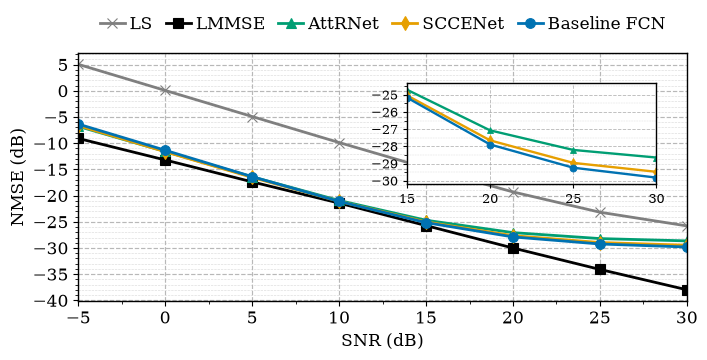


CELL 18B — FINAL FIVE-BENCHMARK RESULTS
 SNR_dB      LS   LMMSE  AttRNet  SCCENet  Proposed
     -5   5.052  -9.090   -6.795   -6.650    -6.350
      0   0.066 -13.205  -11.585  -11.623   -11.349
      5  -4.911 -17.383  -16.416  -16.532   -16.389
     10  -9.875 -21.430  -20.936  -21.101   -21.112
     15 -14.715 -25.727  -24.702  -25.031   -25.159
     20 -19.301 -30.003  -27.067  -27.649   -27.889
     25 -23.175 -34.091  -28.205  -28.958   -29.238
     30 -25.788 -37.976  -28.647  -29.477   -29.814

Figure PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig4a_Five_Benchmarks_Clean_Zoom_IEEE.pdf
Figure PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig4a_Five_Benchmarks_Clean_Zoom_IEEE.png
Results: /home/afanali/wcnc_project/WCL_CDT_Revision/results/figure4_five_benchmark_nmse.csv
Configuration: /home/afanali/wcnc_project/WCL_CDT_Revision/results/figure4_final_config.json
Font: DejaVu Serif
Font size: 12 pt
Zoom range: 15–30 dB
Dashed major/minor grid: YES
Connec

In [23]:

# ================================================================
# CELL 18B — FINAL IEEE WCL FIVE-BENCHMARK EVALUATION
# ================================================================
#
# Fig. 4(a): Matched EPA NMSE versus SNR
#
# Benchmarks:
#   LS
#   LMMSE
#   AttRNet
#   SCCENet
#   Proposed
#
# Includes:
#   - Correct original QPSK pilot sequence
#   - Same channel/noise for every estimator
#   - Correct EPA-matched LMMSE covariance
#   - Clean high-SNR zoomed inset (15–30 dB)
#   - Dashed major/minor gridlines
#   - No diagonal zoom connector lines
#   - Times-style 12-point fonts
#   - Large markers
#   - Vector PDF and 600-dpi PNG
#
# Uses trained checkpoints from Cell 18A.
# No neural-network retraining.
# ================================================================

import time
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.ticker import (
    MultipleLocator,
    AutoMinorLocator
)

# ================================================================
# 1. CONFIGURATION
# ================================================================

F18B_DEVICE = torch.device(DEVICE)

F18B_SNR_GRID = [
    -5, 0, 5, 10, 15, 20, 25, 30
]

F18B_N_TEST = 4000
F18B_BATCH = 256
F18B_N_COV = 10000

F18B_SEED = int(SEED) + 3100

F18B_RESULTS_DIR = Path(RESULTS_DIR)
F18B_FIGURES_DIR = Path(FIGURES_DIR)
F18B_CHECKPOINT_DIR = Path(CHECKPOINT_DIR)

for directory in [
    F18B_RESULTS_DIR,
    F18B_FIGURES_DIR,
    F18B_CHECKPOINT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

random.seed(F18B_SEED)
np.random.seed(F18B_SEED)
torch.manual_seed(F18B_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(F18B_SEED)

start_time = time.time()

print("=" * 72)
print("CELL 18B — FINAL FIVE-BENCHMARK EPA EVALUATION")
print("=" * 72)

print("Device:", F18B_DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

print("Test samples per SNR:", F18B_N_TEST)
print("Covariance samples:", F18B_N_COV)
print("SNR grid:", F18B_SNR_GRID)

# ================================================================
# 2. VERIFY NOTEBOOK DEPENDENCIES
# ================================================================

required = [
    "generate_channel",
    "simulate_ofdm",
    "extract_pilot_observations",
    "PILOT_VALUES",
    "PILOT_K",
    "PILOT_L",
    "N_F",
    "N_S",
    "DA_BASELINE",
    "B18AttRNet",
    "B18SCCENet"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing dependencies: "
        + ", ".join(missing)
    )

assert N_F == 72
assert N_S == 14
assert PILOT_VALUES.numel() == 24

F18B_PILOT_K = PILOT_K.to(F18B_DEVICE)
F18B_PILOT_L = PILOT_L.to(F18B_DEVICE)
F18B_PILOTS = PILOT_VALUES.to(F18B_DEVICE)

# ================================================================
# 3. LOAD TRAINED MODELS
# ================================================================

att_path = (
    F18B_CHECKPOINT_DIR /
    "benchmark_attrnet_epa.pt"
)

scc_path = (
    F18B_CHECKPOINT_DIR /
    "benchmark_sccenet_epa.pt"
)

for path in [att_path, scc_path]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing checkpoint: {path}"
        )

F18B_ATTRNET = B18AttRNet().to(
    F18B_DEVICE
)

F18B_SCCENET = B18SCCENet().to(
    F18B_DEVICE
)

att_checkpoint = torch.load(
    att_path,
    map_location=F18B_DEVICE,
    weights_only=True
)

scc_checkpoint = torch.load(
    scc_path,
    map_location=F18B_DEVICE,
    weights_only=True
)

F18B_ATTRNET.load_state_dict(
    att_checkpoint["model_state_dict"]
)

F18B_SCCENET.load_state_dict(
    scc_checkpoint["model_state_dict"]
)

F18B_ATTRNET.eval()
F18B_SCCENET.eval()

F18B_FCN = DA_BASELINE.to(
    F18B_DEVICE
)

F18B_FCN.eval()

print("\n[LOADED MODELS]")
print("AttRNet:", att_path)
print("SCCENet:", scc_path)
print("Proposed FCN: DA_BASELINE")

# ================================================================
# 4. CHANNEL REPRESENTATION
# ================================================================

def f18b_to_complex(output):

    if output.ndim == 4:

        assert output.shape[1:] == (
            2, N_F, N_S
        )

        return torch.complex(
            output[:, 0],
            output[:, 1]
        )

    if output.ndim == 2:

        B = output.shape[0]
        n = N_F * N_S

        assert output.shape[1] == 2*n

        return torch.complex(
            output[:, :n].reshape(
                B, N_F, N_S
            ),
            output[:, n:].reshape(
                B, N_F, N_S
            )
        )

    raise RuntimeError(
        "Unexpected model output shape."
    )

# ================================================================
# 5. LS NEAREST-NEIGHBOR INTERPOLATION
# ================================================================

with torch.no_grad():

    pilot_coords = torch.stack(
        [
            F18B_PILOT_K.float(),
            F18B_PILOT_L.float()
        ],
        dim=1
    )

    f = torch.arange(
        N_F,
        device=F18B_DEVICE
    )

    t = torch.arange(
        N_S,
        device=F18B_DEVICE
    )

    F_grid, T_grid = torch.meshgrid(
        f, t, indexing="ij"
    )

    grid_coords = torch.stack(
        [
            F_grid.reshape(-1),
            T_grid.reshape(-1)
        ],
        dim=1
    ).float()

    distances = torch.cdist(
        grid_coords,
        pilot_coords
    )

    nearest_pilot = distances.argmin(
        dim=1
    )


@torch.no_grad()
def f18b_ls(H_ls_p):

    return H_ls_p[
        :, nearest_pilot
    ].reshape(
        -1, N_F, N_S
    )

# ================================================================
# 6. EPA-MATCHED LMMSE COVARIANCE
# ================================================================

print("\nEstimating EPA covariance...")

P = len(F18B_PILOT_K)
N = N_F * N_S

R_hp = torch.zeros(
    N, P,
    dtype=torch.complex128,
    device=F18B_DEVICE
)

R_pp = torch.zeros(
    P, P,
    dtype=torch.complex128,
    device=F18B_DEVICE
)

cov_count = 0

with torch.no_grad():

    for start in range(
        0,
        F18B_N_COV,
        F18B_BATCH
    ):

        B = min(
            F18B_BATCH,
            F18B_N_COV-start
        )

        H = generate_channel(
            "EPA", B
        ).to(
            F18B_DEVICE,
            dtype=torch.complex128
        )

        H_flat = H.reshape(
            B, -1
        )

        H_p = H[
            :,
            F18B_PILOT_K,
            F18B_PILOT_L
        ]

        R_hp += (
            H_flat.T @ H_p.conj()
        )

        R_pp += (
            H_p.T @ H_p.conj()
        )

        cov_count += B

R_hp /= cov_count
R_pp /= cov_count

R_pp = (
    R_pp + R_pp.conj().T
) / 2.0

print("EPA covariance: PASS")

# Precompute LMMSE filters for each SNR.

F18B_LMMSE_WEIGHTS = {}

for snr_db in F18B_SNR_GRID:

    noise_variance = (
        10.0 ** (-snr_db / 10.0)
    )

    I = torch.eye(
        P,
        dtype=torch.complex128,
        device=F18B_DEVICE
    )

    A = (
        R_pp + noise_variance * I
    )

    W = torch.linalg.solve(
        A,
        R_hp.conj().T
    ).conj().T

    F18B_LMMSE_WEIGHTS[
        snr_db
    ] = W


@torch.no_grad()
def f18b_lmmse(H_ls_p, snr_db):

    W = F18B_LMMSE_WEIGHTS[
        snr_db
    ]

    estimate = (
        H_ls_p.to(torch.complex128)
        @ W.T
    )

    return estimate.reshape(
        -1, N_F, N_S
    ).to(torch.complex64)

# ================================================================
# 7. COMMON EPA TEST CHANNELS
# ================================================================

print("\nGenerating common EPA test channels...")

test_channels = []

with torch.no_grad():

    for start in range(
        0,
        F18B_N_TEST,
        F18B_BATCH
    ):

        B = min(
            F18B_BATCH,
            F18B_N_TEST-start
        )

        H = generate_channel(
            "EPA", B
        )

        test_channels.append(
            H.detach().cpu()
        )

H_test = torch.cat(
    test_channels,
    dim=0
)

assert len(H_test) == F18B_N_TEST

# ================================================================
# 8. FIVE-BENCHMARK EVALUATION
# ================================================================

methods = [
    "LS",
    "LMMSE",
    "AttRNet",
    "SCCENet",
    "Proposed"
]

results = []

print("\nEvaluating five estimators...")

for snr_db in F18B_SNR_GRID:

    totals = {
        name: [0.0, 0.0]
        for name in methods
    }

    for start in range(
        0,
        F18B_N_TEST,
        F18B_BATCH
    ):

        H = H_test[
            start:start+F18B_BATCH
        ].to(F18B_DEVICE)

        with torch.no_grad():

            _, Y, _ = simulate_ofdm(
                H,
                snr_db,
                pilot_values=F18B_PILOTS
            )

            _, h_p, H_ls_p = (
                extract_pilot_observations(
                    Y,
                    pilot_values=F18B_PILOTS
                )
            )

            estimates = {
                "LS": f18b_ls(H_ls_p),
                "LMMSE": f18b_lmmse(
                    H_ls_p, snr_db
                ),
                "AttRNet": f18b_to_complex(
                    F18B_ATTRNET(h_p)
                ),
                "SCCENet": f18b_to_complex(
                    F18B_SCCENET(h_p)
                ),
                "Proposed": f18b_to_complex(
                    F18B_FCN(h_p)
                )
            }

            for name, H_hat in estimates.items():

                error = (
                    H_hat-H
                ).abs().square().sum().item()

                power = (
                    H
                ).abs().square().sum().item()

                totals[name][0] += error
                totals[name][1] += power

    row = {"SNR_dB": snr_db}

    for name in methods:

        numerator, denominator = totals[name]

        row[name] = (
            10.0 * np.log10(
                numerator / denominator
            )
        )

    results.append(row)

    print(
        f"SNR {snr_db:>3} dB | "
        f"LS={row['LS']:.2f} | "
        f"LMMSE={row['LMMSE']:.2f} | "
        f"AttRNet={row['AttRNet']:.2f} | "
        f"SCCENet={row['SCCENet']:.2f} | "
        f"Proposed={row['Proposed']:.2f}"
    )

F18B_DF = pd.DataFrame(results)

# ================================================================
# 9. IEEE TIMES-STYLE FORMATTING
# ================================================================

available_fonts = {
    font.name
    for font in fm.fontManager.ttflist
}

if "Times New Roman" in available_fonts:
    F18B_FONT = "Times New Roman"
elif "Nimbus Roman" in available_fonts:
    F18B_FONT = "Nimbus Roman"
elif "Liberation Serif" in available_fonts:
    F18B_FONT = "Liberation Serif"
else:
    F18B_FONT = "DejaVu Serif"

plt.rcParams.update({
    "font.family": F18B_FONT,
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.linewidth": 1.0,
    "lines.linewidth": 2.0,
    "lines.markersize": 7,
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600,
})

styles = {
    "LS": ("#7F7F7F", "x", "-"),
    "LMMSE": ("#000000", "s", "-"),
    "AttRNet": ("#009E73", "^", "-"),
    "SCCENet": ("#E69F00", "d", "-"),
    "Proposed": ("#0072B2", "o", "-")
}

# ================================================================
# 10. MAIN FIGURE WITH CLEAN ZOOM INSET
# ================================================================

fig, ax = plt.subplots(
    figsize=(7.16, 4.0)
)

for name in methods:

    color, marker, linestyle = styles[name]

    ax.plot(
        F18B_DF["SNR_dB"],
        F18B_DF[name],
        color=color,
        marker=marker,
        linestyle=linestyle,
        linewidth=2.0,
        markersize=7,
        markeredgewidth=0.8,
        label="Baseline FCN" if name == "Proposed" else name
    )

ax.set_xlabel("SNR (dB)")
ax.set_ylabel("NMSE (dB)")

ax.set_xlim(-5, 30)
ax.set_xticks(F18B_SNR_GRID)

# Major ticks
ax.xaxis.set_major_locator(
    MultipleLocator(5)
)

ax.yaxis.set_major_locator(
    MultipleLocator(5)
)

# Minor ticks
ax.xaxis.set_minor_locator(
    AutoMinorLocator(2)
)

ax.yaxis.set_minor_locator(
    AutoMinorLocator(5)
)

# Dashed major gridlines
ax.grid(
    True,
    which="major",
    axis="both",
    linestyle="--",
    linewidth=0.85,
    color="#A0A0A0",
    alpha=0.75
)

# Light minor horizontal gridlines
ax.grid(
    True,
    which="minor",
    axis="y",
    linestyle="--",
    linewidth=0.45,
    color="#BDBDBD",
    alpha=0.55
)

ax.set_axisbelow(True)

# Legend above axes
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=5,
    frameon=False,
    fontsize=12,
    columnspacing=0.8,
    handlelength=1.5,
    handletextpad=0.3
)

# ================================================================
# 11. CLEAN HIGH-SNR ZOOMED INSET
# ================================================================

# Position relative to main axes:
# [left, bottom, width, height]

axins = ax.inset_axes(
    [0.54, 0.47, 0.41, 0.41]
)

zoom_methods = [
    "AttRNet",
    "SCCENet",
    "Proposed"
]

for name in zoom_methods:

    color, marker, linestyle = styles[name]

    axins.plot(
        F18B_DF["SNR_dB"],
        F18B_DF[name],
        color=color,
        marker=marker,
        linestyle=linestyle,
        linewidth=1.7,
        markersize=5,
        markeredgewidth=0.6
    )

axins.set_xlim(15, 30)

zoom_df = F18B_DF[
    F18B_DF["SNR_dB"] >= 15
]

ymin = zoom_df[
    zoom_methods
].min().min()

ymax = zoom_df[
    zoom_methods
].max().max()

axins.set_ylim(
    ymin - 0.4,
    ymax + 0.4
)

axins.set_xticks(
    [15, 20, 25, 30]
)

axins.yaxis.set_major_locator(
    MultipleLocator(1.0)
)

axins.yaxis.set_minor_locator(
    AutoMinorLocator(2)
)

# Inset major grid
axins.grid(
    True,
    which="major",
    axis="both",
    linestyle="--",
    linewidth=0.65,
    color="#A0A0A0",
    alpha=0.7
)

# Inset minor horizontal grid
axins.grid(
    True,
    which="minor",
    axis="y",
    linestyle="--",
    linewidth=0.35,
    color="#BDBDBD",
    alpha=0.5
)

axins.tick_params(
    axis="both",
    labelsize=9,
    length=3
)

axins.set_axisbelow(True)
axins.set_facecolor("white")

for spine in axins.spines.values():
    spine.set_linewidth(1.0)
    spine.set_color("black")

# No connector lines or arrows.

# ================================================================
# 12. LAYOUT AND EXPORT
# ================================================================

fig.subplots_adjust(
    left=0.13,
    right=0.98,
    bottom=0.18,
    top=0.80
)

pdf_path = (
    F18B_FIGURES_DIR /
    "Fig4a_Five_Benchmarks_Clean_Zoom_IEEE.pdf"
)

png_path = (
    F18B_FIGURES_DIR /
    "Fig4a_Five_Benchmarks_Clean_Zoom_IEEE.png"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05
)

fig.savefig(
    png_path,
    format="png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()
plt.close(fig)

# ================================================================
# 13. SAVE RESULTS AND CONFIGURATION
# ================================================================

results_path = (
    F18B_RESULTS_DIR /
    "figure4_five_benchmark_nmse.csv"
)

F18B_DF.to_csv(
    results_path,
    index=False
)

config_path = (
    F18B_RESULTS_DIR /
    "figure4_final_config.json"
)

with open(config_path, "w") as f:

    json.dump({
        "channel": "EPA",
        "snr_grid": F18B_SNR_GRID,
        "test_samples_per_snr": F18B_N_TEST,
        "covariance_samples": F18B_N_COV,
        "pilot_count": 24,
        "pilot_sequence": "original_fixed_QPSK",
        "benchmark_names": methods,
        "benchmark_architectures": "adapted",
        "ls_interpolation": "nearest_neighbor",
        "lmmse": "EPA_matched_covariance",
        "zoom_range_db": [15, 30],
        "zoom_methods": zoom_methods,
        "font": F18B_FONT,
        "font_size": 12,
        "grid": "major_and_minor_dashed",
        "zoom_connector_lines": False
    }, f, indent=4)

# ================================================================
# 14. FINAL SUMMARY
# ================================================================

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 18B — FINAL FIVE-BENCHMARK RESULTS")
print("=" * 72)

print(
    F18B_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\nFigure PDF:", pdf_path)
print("Figure PNG:", png_path)
print("Results:", results_path)
print("Configuration:", config_path)
print("Font:", F18B_FONT)
print("Font size: 12 pt")
print("Zoom range: 15–30 dB")
print("Dashed major/minor grid: YES")
print("Connector lines: NONE")
print("Runtime:", round(elapsed, 2), "seconds")

print("\nCELL 18B: PASS")


CELL 19 — DISTRIBUTION-SHIFT BENCHMARK EVALUATION
Device: cuda:0
Channels: ['EVA', 'ETU']
SNR grid: [-5, 0, 5, 10, 15, 20, 25, 30]
Test realizations per channel/SNR: 4000

Models loaded successfully.
Reusing EPA covariance from Cell 18B.

DEPLOYMENT CHANNEL: EVA
SNR  -5 dB | LS=5.13 | LMMSE=-5.05 | AttRNet=-5.20 | SCCENet=-5.08 | Proposed=-4.86
SNR   0 dB | LS=0.36 | LMMSE=-6.57 | AttRNet=-8.04 | SCCENet=-8.03 | Proposed=-7.78
SNR   5 dB | LS=-4.08 | LMMSE=-8.15 | AttRNet=-9.57 | SCCENet=-9.53 | Proposed=-9.26
SNR  10 dB | LS=-7.62 | LMMSE=-9.81 | AttRNet=-10.17 | SCCENet=-10.08 | Proposed=-9.78
SNR  15 dB | LS=-9.85 | LMMSE=-10.77 | AttRNet=-10.37 | SCCENet=-10.26 | Proposed=-9.96
SNR  20 dB | LS=-10.88 | LMMSE=-11.35 | AttRNet=-10.44 | SCCENet=-10.32 | Proposed=-10.02
SNR  25 dB | LS=-11.26 | LMMSE=-12.30 | AttRNet=-10.46 | SCCENet=-10.33 | Proposed=-10.03
SNR  30 dB | LS=-11.38 | LMMSE=-13.21 | AttRNet=-10.46 | SCCENet=-10.34 | Proposed=-10.04

DEPLOYMENT CHANNEL: ETU
SNR  -5 dB | L

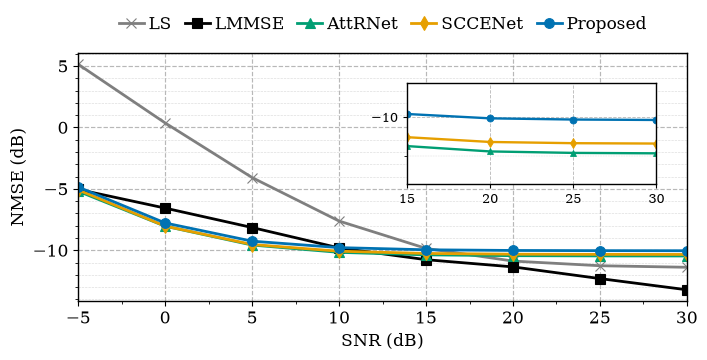

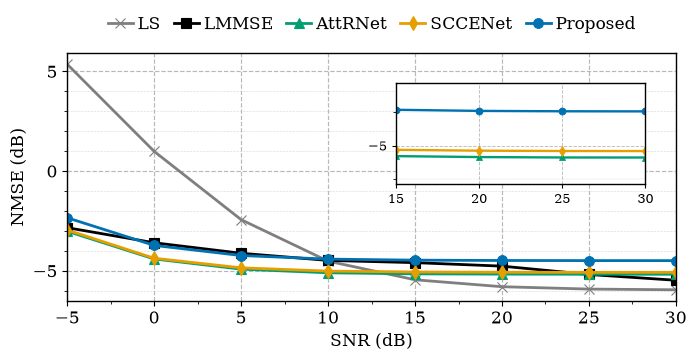


CELL 19 — DISTRIBUTION-SHIFT RESULTS
Channel  SNR_dB      LS   LMMSE  AttRNet  SCCENet  Proposed
    EVA      -5   5.134  -5.050   -5.198   -5.084    -4.857
    EVA       0   0.359  -6.569   -8.041   -8.034    -7.779
    EVA       5  -4.084  -8.149   -9.574   -9.530    -9.259
    EVA      10  -7.622  -9.808  -10.170  -10.076    -9.783
    EVA      15  -9.848 -10.765  -10.371  -10.257    -9.959
    EVA      20 -10.878 -11.351  -10.440  -10.318   -10.015
    EVA      25 -11.257 -12.304  -10.459  -10.334   -10.030
    EVA      30 -11.383 -13.215  -10.464  -10.339   -10.036
    ETU      -5   5.356  -2.838   -3.020   -2.957    -2.342
    ETU       0   0.988  -3.594   -4.407   -4.371    -3.727
    ETU       5  -2.436  -4.121   -4.917   -4.851    -4.234
    ETU      10  -4.518  -4.479   -5.100   -5.015    -4.414
    ETU      15  -5.451  -4.591   -5.153   -5.060    -4.466
    ETU      20  -5.798  -4.766   -5.168   -5.073    -4.483
    ETU      25  -5.917  -5.184   -5.174   -5.078    -4.488
  

In [ ]:

# ================================================================
# CELL 19 — IEEE WCL FIGURE 5(a) AND FIGURE 5(b)
# ================================================================
#
# Fig. 5(a): EPA-trained estimators evaluated on EVA
# Fig. 5(b): EPA-trained estimators evaluated on ETU
#
# Five estimators:
#   LS, LMMSE, AttRNet, SCCENet, Proposed
#
# Proposed = unchanged EPA-trained FCN (pre-adaptation)
#
# Same channel realizations and noisy pilots for all methods.
# LMMSE uses EPA reference covariance (mismatched deployment).
# No model retraining or fabricated curves.
#
# Times-style 12 pt, dashed grids, clean zoomed inset.
# Separate vector PDF and 600-dpi PNG outputs.
# ================================================================

import time
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.ticker import MultipleLocator, AutoMinorLocator

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

C19_DEVICE = torch.device(DEVICE)

C19_SNR_GRID = [-5, 0, 5, 10, 15, 20, 25, 30]
C19_CHANNELS = ["EVA", "ETU"]

C19_N_TEST = 4000
C19_BATCH = 256
C19_N_COV = 10000
C19_SEED = int(SEED) + 3200

C19_RESULTS = Path(RESULTS_DIR)
C19_FIGURES = Path(FIGURES_DIR)
C19_CHECKPOINTS = Path(CHECKPOINT_DIR)

C19_RESULTS.mkdir(parents=True, exist_ok=True)
C19_FIGURES.mkdir(parents=True, exist_ok=True)

random.seed(C19_SEED)
np.random.seed(C19_SEED)
torch.manual_seed(C19_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(C19_SEED)

start_time = time.time()

print("=" * 72)
print("CELL 19 — DISTRIBUTION-SHIFT BENCHMARK EVALUATION")
print("=" * 72)
print("Device:", C19_DEVICE)
print("Channels:", C19_CHANNELS)
print("SNR grid:", C19_SNR_GRID)
print("Test realizations per channel/SNR:", C19_N_TEST)

# ------------------------------------------------------------
# 2. Verify dependencies
# ------------------------------------------------------------

required = [
    "generate_channel",
    "simulate_ofdm",
    "extract_pilot_observations",
    "PILOT_VALUES",
    "PILOT_K",
    "PILOT_L",
    "N_F",
    "N_S",
    "DA_BASELINE",
    "B18AttRNet",
    "B18SCCENet"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing notebook definitions: " + str(missing)
    )

assert (N_F, N_S) == (72, 14)
assert PILOT_VALUES.numel() == 24

pilot_k = PILOT_K.to(C19_DEVICE)
pilot_l = PILOT_L.to(C19_DEVICE)
pilot_values = PILOT_VALUES.to(C19_DEVICE)

# ------------------------------------------------------------
# 3. Load benchmark models
# ------------------------------------------------------------

def c19_load_model(model_class, filename):
    path = C19_CHECKPOINTS / filename

    if not path.exists():
        raise FileNotFoundError(path)

    checkpoint = torch.load(
        path,
        map_location=C19_DEVICE,
        weights_only=True
    )

    model = model_class().to(C19_DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    return model


C19_ATTRNET = c19_load_model(
    B18AttRNet,
    "benchmark_attrnet_epa.pt"
)

C19_SCCENET = c19_load_model(
    B18SCCENet,
    "benchmark_sccenet_epa.pt"
)

C19_FCN = DA_BASELINE.to(C19_DEVICE)
C19_FCN.eval()

print("\nModels loaded successfully.")

# ------------------------------------------------------------
# 4. Convert network output to complex channel
# ------------------------------------------------------------

def c19_to_complex(output):

    if output.ndim == 4:
        assert output.shape[1:] == (2, N_F, N_S)

        return torch.complex(
            output[:, 0],
            output[:, 1]
        )

    if output.ndim == 2:
        B = output.shape[0]
        n = N_F * N_S

        assert output.shape[1] == 2 * n

        return torch.complex(
            output[:, :n].reshape(B, N_F, N_S),
            output[:, n:].reshape(B, N_F, N_S)
        )

    raise ValueError(
        f"Unexpected output shape: {output.shape}"
    )

# ------------------------------------------------------------
# 5. LS interpolation — same as Cell 18B
# ------------------------------------------------------------

with torch.no_grad():

    pilot_coords = torch.stack(
        [pilot_k.float(), pilot_l.float()],
        dim=1
    )

    freq = torch.arange(N_F, device=C19_DEVICE)
    time_grid = torch.arange(N_S, device=C19_DEVICE)

    F_grid, T_grid = torch.meshgrid(
        freq, time_grid, indexing="ij"
    )

    grid_coords = torch.stack(
        [F_grid.reshape(-1), T_grid.reshape(-1)],
        dim=1
    ).float()

    nearest_pilot = torch.cdist(
        grid_coords,
        pilot_coords
    ).argmin(dim=1)


@torch.no_grad()
def c19_ls(H_ls_p):

    return H_ls_p[:, nearest_pilot].reshape(
        -1, N_F, N_S
    )

# ------------------------------------------------------------
# 6. EPA covariance for mismatched LMMSE
# ------------------------------------------------------------

# Reuse Cell 18B covariance if available.
# Otherwise estimate independently using EPA channels.

P = len(pilot_k)
N = N_F * N_S

if (
    "R_hp" in globals()
    and "R_pp" in globals()
    and tuple(R_hp.shape) == (N, P)
    and tuple(R_pp.shape) == (P, P)
):
    C19_R_HP = R_hp.to(C19_DEVICE).clone()
    C19_R_PP = R_pp.to(C19_DEVICE).clone()
    print("Reusing EPA covariance from Cell 18B.")

else:

    print("Estimating independent EPA covariance...")

    C19_R_HP = torch.zeros(
        N, P,
        dtype=torch.complex128,
        device=C19_DEVICE
    )

    C19_R_PP = torch.zeros(
        P, P,
        dtype=torch.complex128,
        device=C19_DEVICE
    )

    count = 0

    with torch.no_grad():

        for start in range(0, C19_N_COV, C19_BATCH):

            B = min(C19_BATCH, C19_N_COV - start)

            H = generate_channel(
                "EPA", B
            ).to(
                C19_DEVICE,
                dtype=torch.complex128
            )

            H_flat = H.reshape(B, -1)
            H_p = H[:, pilot_k, pilot_l]

            C19_R_HP += H_flat.T @ H_p.conj()
            C19_R_PP += H_p.T @ H_p.conj()

            count += B

    C19_R_HP /= count
    C19_R_PP /= count

C19_R_PP = (
    C19_R_PP + C19_R_PP.conj().T
) / 2

# LMMSE uses EPA statistics at every deployment SNR.

C19_LMMSE_WEIGHTS = {}

for snr_db in C19_SNR_GRID:

    noise_variance = 10.0 ** (-snr_db / 10.0)

    I = torch.eye(
        P,
        dtype=torch.complex128,
        device=C19_DEVICE
    )

    W = torch.linalg.solve(
        C19_R_PP + noise_variance * I,
        C19_R_HP.conj().T
    ).conj().T

    C19_LMMSE_WEIGHTS[snr_db] = W


@torch.no_grad()
def c19_lmmse(H_ls_p, snr_db):

    W = C19_LMMSE_WEIGHTS[snr_db]

    estimate = (
        H_ls_p.to(torch.complex128) @ W.T
    )

    return estimate.reshape(
        -1, N_F, N_S
    ).to(torch.complex64)

# ------------------------------------------------------------
# 7. Evaluation
# ------------------------------------------------------------

C19_METHODS = [
    "LS",
    "LMMSE",
    "AttRNet",
    "SCCENet",
    "Proposed"
]

C19_ROWS = []

for channel in C19_CHANNELS:

    print("\n" + "=" * 72)
    print("DEPLOYMENT CHANNEL:", channel)
    print("=" * 72)

    # Same test channels reused across SNR values.
    H_test_parts = []

    with torch.no_grad():

        for start in range(0, C19_N_TEST, C19_BATCH):

            B = min(C19_BATCH, C19_N_TEST - start)

            H = generate_channel(channel, B)

            H_test_parts.append(H.detach().cpu())

    H_test = torch.cat(H_test_parts, dim=0)

    for snr_db in C19_SNR_GRID:

        totals = {
            name: [0.0, 0.0]
            for name in C19_METHODS
        }

        for start in range(0, C19_N_TEST, C19_BATCH):

            H = H_test[
                start:start + C19_BATCH
            ].to(C19_DEVICE)

            with torch.no_grad():

                _, Y, _ = simulate_ofdm(
                    H,
                    snr_db,
                    pilot_values=pilot_values
                )

                _, h_p, H_ls_p = extract_pilot_observations(
                    Y,
                    pilot_values=pilot_values
                )

                estimates = {
                    "LS": c19_ls(H_ls_p),
                    "LMMSE": c19_lmmse(H_ls_p, snr_db),
                    "AttRNet": c19_to_complex(
                        C19_ATTRNET(h_p)
                    ),
                    "SCCENet": c19_to_complex(
                        C19_SCCENET(h_p)
                    ),
                    "Proposed": c19_to_complex(
                        C19_FCN(h_p)
                    )
                }

                reference_power = (
                    H.abs().square().sum().item()
                )

                for name, estimate in estimates.items():

                    error = (
                        (estimate - H)
                        .abs()
                        .square()
                        .sum()
                        .item()
                    )

                    totals[name][0] += error
                    totals[name][1] += reference_power

        row = {
            "Channel": channel,
            "SNR_dB": snr_db
        }

        for name in C19_METHODS:

            numerator, denominator = totals[name]

            row[name] = 10.0 * np.log10(
                numerator / denominator
            )

        C19_ROWS.append(row)

        print(
            f"SNR {snr_db:>3} dB | "
            f"LS={row['LS']:.2f} | "
            f"LMMSE={row['LMMSE']:.2f} | "
            f"AttRNet={row['AttRNet']:.2f} | "
            f"SCCENet={row['SCCENet']:.2f} | "
            f"Proposed={row['Proposed']:.2f}"
        )

C19_DF = pd.DataFrame(C19_ROWS)

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

results_path = (
    C19_RESULTS /
    "figure5_distribution_shift_benchmarks.csv"
)

C19_DF.to_csv(results_path, index=False)

# ------------------------------------------------------------
# 9. IEEE plotting style
# ------------------------------------------------------------

available_fonts = {
    f.name for f in fm.fontManager.ttflist
}

if "Times New Roman" in available_fonts:
    C19_FONT = "Times New Roman"
elif "Nimbus Roman" in available_fonts:
    C19_FONT = "Nimbus Roman"
elif "Liberation Serif" in available_fonts:
    C19_FONT = "Liberation Serif"
else:
    C19_FONT = "DejaVu Serif"

plt.rcParams.update({
    "font.family": C19_FONT,
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.linewidth": 1.0,
    "lines.linewidth": 2.0,
    "lines.markersize": 7,
    "mathtext.fontset": "stix",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600
})

C19_STYLES = {
    "LS": ("#7F7F7F", "x", "-"),
    "LMMSE": ("#000000", "s", "-"),
    "AttRNet": ("#009E73", "^", "-"),
    "SCCENet": ("#E69F00", "d", "-"),
    "Proposed": ("#0072B2", "o", "-")
}

# ------------------------------------------------------------
# 10. Figure plotting function
# ------------------------------------------------------------

def c19_plot(channel, filename):

    df = (
        C19_DF[C19_DF["Channel"] == channel]
        .sort_values("SNR_dB")
    )

    fig, ax = plt.subplots(figsize=(7.16, 4.0))

    for name in C19_METHODS:

        color, marker, linestyle = C19_STYLES[name]

        ax.plot(
            df["SNR_dB"],
            df[name],
            color=color,
            marker=marker,
            linestyle=linestyle,
            linewidth=2.0,
            markersize=7,
            markeredgewidth=0.8,
            label=name
        )

    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("NMSE (dB)")

    ax.set_xlim(-5, 30)
    ax.set_xticks(C19_SNR_GRID)

    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.yaxis.set_major_locator(MultipleLocator(5))

    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(5))

    ax.grid(
        True,
        which="major",
        axis="both",
        linestyle="--",
        linewidth=0.85,
        color="#A0A0A0",
        alpha=0.75
    )

    ax.grid(
        True,
        which="minor",
        axis="y",
        linestyle="--",
        linewidth=0.45,
        color="#BDBDBD",
        alpha=0.55
    )

    ax.set_axisbelow(True)

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=5,
        frameon=False,
        fontsize=12,
        columnspacing=0.8,
        handlelength=1.5,
        handletextpad=0.3
    )

    # --------------------------------------------------------
    # Clean zoomed inset
    # --------------------------------------------------------

    zoom_methods = [
        "AttRNet",
        "SCCENet",
        "Proposed"
    ]

    axins = ax.inset_axes(
        [0.54, 0.47, 0.41, 0.41]
    )

    for name in zoom_methods:

        color, marker, linestyle = C19_STYLES[name]

        axins.plot(
            df["SNR_dB"],
            df[name],
            color=color,
            marker=marker,
            linestyle=linestyle,
            linewidth=1.7,
            markersize=5,
            markeredgewidth=0.6
        )

    axins.set_xlim(15, 30)

    zoom_df = df[df["SNR_dB"] >= 15]

    ymin = zoom_df[zoom_methods].min().min()
    ymax = zoom_df[zoom_methods].max().max()

    padding = max(0.4, 0.08 * (ymax - ymin))

    axins.set_ylim(
        ymin - padding,
        ymax + padding
    )

    axins.set_xticks([15, 20, 25, 30])

    axins.yaxis.set_major_locator(
        MultipleLocator(1.0)
    )

    axins.yaxis.set_minor_locator(
        AutoMinorLocator(2)
    )

    axins.grid(
        True,
        which="major",
        linestyle="--",
        linewidth=0.65,
        color="#A0A0A0",
        alpha=0.7
    )

    axins.grid(
        True,
        which="minor",
        axis="y",
        linestyle="--",
        linewidth=0.35,
        color="#BDBDBD",
        alpha=0.5
    )

    axins.tick_params(
        axis="both",
        labelsize=9,
        length=3
    )

    axins.set_facecolor("white")
    axins.set_axisbelow(True)

    for spine in axins.spines.values():
        spine.set_linewidth(1.0)
        spine.set_color("black")

    # No connector lines or arrows.

    fig.subplots_adjust(
        left=0.13,
        right=0.98,
        bottom=0.18,
        top=0.80
    )

    pdf_path = C19_FIGURES / f"{filename}.pdf"
    png_path = C19_FIGURES / f"{filename}.png"

    fig.savefig(
        pdf_path,
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.05
    )

    fig.savefig(
        png_path,
        format="png",
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.05
    )

    plt.show()
    plt.close(fig)

    return pdf_path, png_path

# ------------------------------------------------------------
# 11. Generate separate PDFs
# ------------------------------------------------------------

fig5a_pdf, fig5a_png = c19_plot(
    "EVA",
    "Fig5a_EPA_to_EVA_Five_Benchmarks_IEEE"
)

fig5b_pdf, fig5b_png = c19_plot(
    "ETU",
    "Fig5b_EPA_to_ETU_Five_Benchmarks_IEEE"
)

# ------------------------------------------------------------
# 12. Save configuration
# ------------------------------------------------------------

config_path = (
    C19_RESULTS /
    "figure5_distribution_shift_config.json"
)

with open(config_path, "w") as f:

    json.dump({
        "training_channel": "EPA",
        "deployment_channels": C19_CHANNELS,
        "snr_grid": C19_SNR_GRID,
        "test_samples_per_snr": C19_N_TEST,
        "pilot_count": 24,
        "pilot_sequence": "original_fixed_QPSK",
        "lmmse_covariance": "EPA_matched",
        "ls_interpolation": "nearest_neighbor",
        "proposed_curve": "unchanged_EPA_trained_FCN",
        "cdt_adaptation_included": False,
        "benchmark_architectures": "adapted",
        "font": C19_FONT,
        "font_size": 12,
        "zoom_range_db": [15, 30]
    }, f, indent=4)

# ------------------------------------------------------------
# 13. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("CELL 19 — DISTRIBUTION-SHIFT RESULTS")
print("=" * 72)

print(
    C19_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\nFig. 5(a):", fig5a_pdf)
print("Fig. 5(b):", fig5b_pdf)
print("Results:", results_path)
print("Configuration:", config_path)
print("Runtime:", round(time.time() - start_time, 2), "seconds")

print("\nCELL 19: PASS")


CELL 20 — CDT LIFECYCLE ADAPTATION

[NMSE RESULTS]
Channel  Original FCN  UPDATE  RETIRE-Scratch  RETIRE-Warm
    EVA        -9.954 -11.083         -15.319      -15.323
    ETU        -4.391  -4.465          -8.169       -8.682

[IMPROVEMENT OVER ORIGINAL FCN]
Channel         Method  NMSE_dB  Gain_dB
    EVA   Original FCN   -9.954    0.000
    EVA         UPDATE  -11.083    1.129
    EVA RETIRE-Scratch  -15.319    5.366
    EVA    RETIRE-Warm  -15.323    5.369
    ETU   Original FCN   -4.391    0.000
    ETU         UPDATE   -4.465    0.074
    ETU RETIRE-Scratch   -8.169    3.778
    ETU    RETIRE-Warm   -8.682    4.291


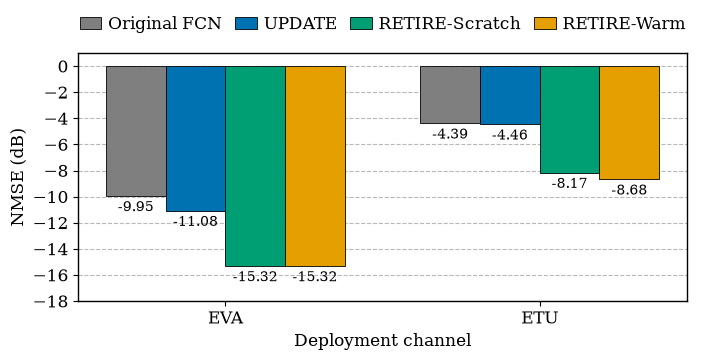


CELL 20 — FIGURE EXPORT COMPLETE
PDF: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig_CDT_Update_Retire_NMSE_IEEE.pdf
PNG: /home/afanali/wcnc_project/WCL_CDT_Revision/figures/Fig_CDT_Update_Retire_NMSE_IEEE.png
NMSE data: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_lifecycle_nmse_comparison.csv
Gain data: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_lifecycle_nmse_gains.csv
Font: DejaVu Serif
Font size: 12 pt

CELL 20: PASS


In [ ]:

# ================================================================
# CELL 20 — CDT LIFECYCLE ADAPTATION PERFORMANCE
# ================================================================
#
# NMSE comparison at 12 dB:
#   Original FCN
#   UPDATE
#   RETIRE-Scratch
#   RETIRE-Warm
#
# Deployment channels:
#   EVA and ETU
#
# Source: Cell 14 validated offline NMSE results.
#
# Plot only; no new simulations.
#
# IEEE WCL style:
#   - Times-style serif font
#   - 12-point fonts
#   - Grouped bars
#   - Dashed horizontal grids
#   - Value labels on bars
#   - Legend outside axes
#   - No internal title
#   - Vector PDF + 600-dpi PNG
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.ticker import MultipleLocator
from pathlib import Path

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

C20_RESULTS = Path(RESULTS_DIR)
C20_FIGURES = Path(FIGURES_DIR)

C20_FIGURES.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Verified Cell 14 results
# ------------------------------------------------------------

# Values are taken directly from the Cell 14
# results supplied earlier.
#
# NMSE values in dB (lower is better).

C20_DATA = {
    "Channel": ["EVA", "ETU"],

    "Original FCN": [
        -9.95360,
        -4.39144
    ],

    "UPDATE": [
        -11.08280,
        -4.46495
    ],

    "RETIRE-Scratch": [
        -15.31943,
        -8.16902
    ],

    "RETIRE-Warm": [
        -15.32251,
        -8.68230
    ]
}

C20_DF = pd.DataFrame(
    C20_DATA
)

# ------------------------------------------------------------
# 3. Validate numerical data
# ------------------------------------------------------------

methods = [
    "Original FCN",
    "UPDATE",
    "RETIRE-Scratch",
    "RETIRE-Warm"
]

assert len(C20_DF) == 2

assert np.isfinite(
    C20_DF[methods].to_numpy()
).all()

# Compute positive NMSE improvements
# relative to the original FCN.

gain_rows = []

for _, row in C20_DF.iterrows():

    for method in methods:

        gain_rows.append({
            "Channel": row["Channel"],
            "Method": method,
            "NMSE_dB": row[method],
            "Gain_dB": (
                row["Original FCN"]
                - row[method]
            )
        })

C20_GAIN_DF = pd.DataFrame(
    gain_rows
)

print("=" * 70)
print("CELL 20 — CDT LIFECYCLE ADAPTATION")
print("=" * 70)

print("\n[NMSE RESULTS]")
print(
    C20_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\n[IMPROVEMENT OVER ORIGINAL FCN]")
print(
    C20_GAIN_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 4. Times-style font
# ------------------------------------------------------------

available_fonts = {
    f.name
    for f in fm.fontManager.ttflist
}

if "Times New Roman" in available_fonts:
    C20_FONT = "Times New Roman"
elif "Nimbus Roman" in available_fonts:
    C20_FONT = "Nimbus Roman"
elif "Liberation Serif" in available_fonts:
    C20_FONT = "Liberation Serif"
else:
    C20_FONT = "DejaVu Serif"

plt.rcParams.update({
    "font.family": C20_FONT,
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.linewidth": 1.0,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600,
})

# ------------------------------------------------------------
# 5. Grouped-bar figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7.16, 4.0)
)

channels = C20_DF["Channel"].tolist()

x = np.arange(
    len(channels)
)

bar_width = 0.19

colors = {
    "Original FCN": "#7F7F7F",
    "UPDATE": "#0072B2",
    "RETIRE-Scratch": "#009E73",
    "RETIRE-Warm": "#E69F00"
}

offsets = [
    -1.5 * bar_width,
    -0.5 * bar_width,
    0.5 * bar_width,
    1.5 * bar_width
]

for method, offset in zip(
    methods,
    offsets
):

    values = C20_DF[
        method
    ].to_numpy()

    bars = ax.bar(
        x + offset,
        values,
        width=bar_width,
        color=colors[method],
        edgecolor="black",
        linewidth=0.6,
        label=method
    )

    # NMSE labels at bar ends
    for bar, value in zip(
        bars,
        values
    ):

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            value - 0.35,
            f"{value:.2f}",
            ha="center",
            va="top",
            fontsize=10
        )

# ------------------------------------------------------------
# 6. Axes and grid
# ------------------------------------------------------------

ax.set_xticks(x)
ax.set_xticklabels(channels)

ax.set_xlabel(
    "Deployment channel"
)

ax.set_ylabel(
    "NMSE (dB)"
)

ax.set_ylim(
    -18.0,
    1.0
)

ax.yaxis.set_major_locator(
    MultipleLocator(2.0)
)

ax.grid(
    True,
    axis="y",
    which="major",
    linestyle="--",
    linewidth=0.8,
    color="#A0A0A0",
    alpha=0.75
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# 7. Legend outside axes
# ------------------------------------------------------------

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=4,
    frameon=False,
    fontsize=12,
    columnspacing=0.8,
    handlelength=1.3,
    handletextpad=0.4
)

# ------------------------------------------------------------
# 8. Layout and export
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.13,
    right=0.98,
    bottom=0.18,
    top=0.80
)

pdf_path = (
    C20_FIGURES /
    "Fig_CDT_Update_Retire_NMSE_IEEE.pdf"
)

png_path = (
    C20_FIGURES /
    "Fig_CDT_Update_Retire_NMSE_IEEE.png"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05
)

fig.savefig(
    png_path,
    format="png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. Save numerical data
# ------------------------------------------------------------

nmse_path = (
    C20_RESULTS /
    "cdt_lifecycle_nmse_comparison.csv"
)

gain_path = (
    C20_RESULTS /
    "cdt_lifecycle_nmse_gains.csv"
)

C20_DF.to_csv(
    nmse_path,
    index=False
)

C20_GAIN_DF.to_csv(
    gain_path,
    index=False
)

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 20 — FIGURE EXPORT COMPLETE")
print("=" * 70)

print("PDF:", pdf_path)
print("PNG:", png_path)
print("NMSE data:", nmse_path)
print("Gain data:", gain_path)
print("Font:", C20_FONT)
print("Font size: 12 pt")

print("\nCELL 20: PASS")


In [ ]:

# ============================================================
# CELL 21A — LOCATE RETIRE REPLACEMENT FCN MODELS
# ============================================================
#
# Checks:
# 1. Saved PyTorch checkpoints
# 2. Existing notebook model objects
# 3. Checkpoint architecture and metadata
#
# No training or modification of models.
# ============================================================

from pathlib import Path
import torch
import torch.nn as nn

checkpoint_dir = Path(CHECKPOINT_DIR)

print("=" * 70)
print("CELL 21A — RETIRE MODEL DISCOVERY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Inspect saved checkpoints
# ------------------------------------------------------------

print("\n[AVAILABLE CHECKPOINT FILES]")

checkpoint_files = sorted(
    list(checkpoint_dir.glob("*.pt"))
    + list(checkpoint_dir.glob("*.pth"))
)

for path in checkpoint_files:
    print(path.name)

# ------------------------------------------------------------
# 2. Inspect relevant checkpoint contents
# ------------------------------------------------------------

print("\n[RETIRE / REPLACEMENT CHECKPOINT DETAILS]")

keywords = [
    "retire",
    "replacement",
    "scratch",
    "warm",
    "eva",
    "etu"
]

for path in checkpoint_files:

    if not any(
        keyword in path.name.lower()
        for keyword in keywords
    ):
        continue

    print("\nCheckpoint:", path.name)

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        if isinstance(checkpoint, dict):

            print(
                "Top-level keys:",
                list(checkpoint.keys())[:20]
            )

            state = checkpoint.get(
                "model_state_dict",
                checkpoint.get(
                    "state_dict",
                    checkpoint
                )
            )

            if isinstance(state, dict):

                tensor_keys = [
                    k for k, v in state.items()
                    if torch.is_tensor(v)
                ]

                print(
                    "Tensor keys:",
                    tensor_keys[:12]
                )

                for key in tensor_keys[:5]:
                    print(
                        " ",
                        key,
                        tuple(state[key].shape)
                    )

    except Exception as exc:

        print(
            "Could not inspect:",
            type(exc).__name__,
            str(exc)
        )

# ------------------------------------------------------------
# 3. Inspect notebook memory
# ------------------------------------------------------------

print("\n[IN-MEMORY PYTORCH MODELS]")

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if isinstance(obj, nn.Module):

        print(
            name,
            "|",
            type(obj).__name__,
            "| parameters:",
            sum(
                p.numel()
                for p in obj.parameters()
            )
        )

# ------------------------------------------------------------
# 4. Inspect dictionaries containing model objects
# ------------------------------------------------------------

print("\n[MODEL REPOSITORY DICTIONARIES]")

for name, obj in list(globals().items()):

    if not isinstance(obj, dict):
        continue

    matching_keys = [
        str(k)
        for k in obj.keys()
        if any(
            keyword in str(k).lower()
            for keyword in keywords
        )
    ]

    if matching_keys:

        print("\nDictionary:", name)
        print("Matching keys:", matching_keys[:20])

        for key, value in obj.items():

            if isinstance(value, nn.Module):

                print(
                    "  Model:",
                    key,
                    type(value).__name__
                )

# ------------------------------------------------------------
# 5. Final message
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 21A — DISCOVERY COMPLETE")
print("=" * 70)

print(
    "Required EVA model: RETIRE_Scratch"
)

print(
    "Required ETU model: RETIRE_Warm"
)

print(
    "\nNo checkpoints have been modified."
)


CELL 21A — RETIRE MODEL DISCOVERY

[AVAILABLE CHECKPOINT FILES]
activation_comparison_references.pt
activation_correlation_reference.pt
activation_directional_detector.pt
activation_global_vs_changepoint.pt
activation_persistence_detector.pt
activation_snr_references.pt
activation_two_sided_detector.pt
activation_window_snr_references.pt
benchmark_attrnet_epa.pt
benchmark_sccenet_epa.pt
cdt_combined_detector.pt
cdt_hierarchical_controller.pt
cdt_snr_matched_monitor.pt
ema_spatial_vqvae_etu.pt
ema_spatial_vqvae_eva.pt
fcn_epa_12db_best.pt
original_pilot_sequence.pt
pilot_vae_epa_12db_best.pt
replacement_fcn_etu.pt
replacement_fcn_eva.pt
retire_scratch_etu.pt
retire_scratch_eva.pt
retire_warm_etu.pt
retire_warm_eva.pt
spatial_vqvae_etu.pt
spatial_vqvae_eva.pt
vqvae_retire_etu.pt
vqvae_retire_eva.pt

[RETIRE / REPLACEMENT CHECKPOINT DETAILS]

Checkpoint: ema_spatial_vqvae_etu.pt
Top-level keys: ['model_state_dict', 'latent_dim', 'codebook_size', 'snr_db', 'channel', 'architecture']
Tensor

CELL 21 — FINAL POST-ADAPTATION CDT EVALUATION
Device: cuda:0
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Channels: ['EVA', 'ETU']
SNR grid: [-5, 0, 5, 10, 15, 20, 25, 30]
Test samples per SNR: 4000

[BENCHMARK MODELS LOADED]
AttRNet: benchmark_attrnet_epa.pt
SCCENet: benchmark_sccenet_epa.pt
Original FCN: DA_BASELINE

[VALIDATION-SELECTED RETIRE MODELS]
EVA: retire_scratch_eva.pt | parameters=1584608 | PASS
ETU: retire_warm_etu.pt | parameters=1584608 | PASS

Reusing EPA covariance from Cell 18B.

EVALUATING POST-ADAPTATION PERFORMANCE

CHANNEL: EVA
SNR  -5 dB | Original=-4.940 | CDT=-2.650 | Gain=-2.290 dB
SNR   0 dB | Original=-7.889 | CDT=-7.496 | Gain=-0.393 dB
SNR   5 dB | Original=-9.312 | CDT=-11.661 | Gain=+2.350 dB
SNR  10 dB | Original=-9.839 | CDT=-14.555 | Gain=+4.716 dB
SNR  15 dB | Original=-10.006 | CDT=-15.980 | Gain=+5.974 dB
SNR  20 dB | Original=-10.064 | CDT=-16.559 | Gain=+6.495 dB
SNR  25 dB | Original=-10.081 | CDT=-16.749 | Gain=+6.667 dB
SNR  30 dB | Original=-10.

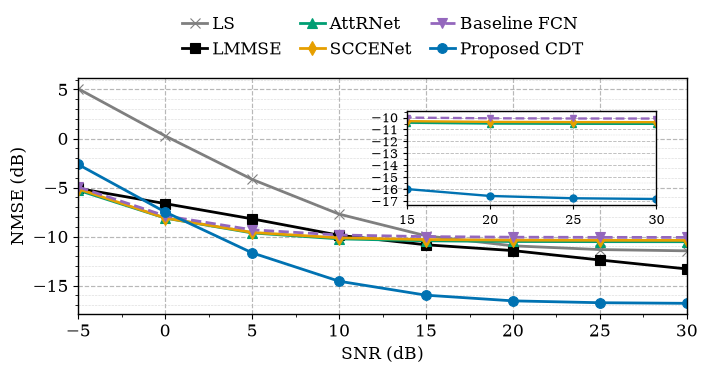

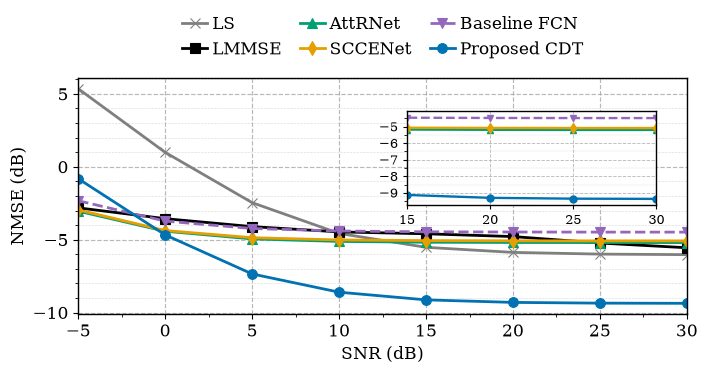


CELL 21 — POST-ADAPTATION RESULTS
Channel  SNR_dB      LS   LMMSE  AttRNet  SCCENet  Original FCN  Proposed CDT  CDT_Gain_dB
    EVA      -5   5.073  -5.091   -5.277   -5.138        -4.940        -2.650       -2.290
    EVA       0   0.263  -6.640   -8.116   -8.108        -7.889        -7.496       -0.393
    EVA       5  -4.169  -8.195   -9.630   -9.577        -9.312       -11.661        2.350
    EVA      10  -7.711  -9.869  -10.234  -10.131        -9.839       -14.555        4.716
    EVA      15  -9.924 -10.840  -10.432  -10.304       -10.006       -15.980        5.974
    EVA      20 -10.946 -11.431  -10.502  -10.364       -10.064       -16.559        6.495
    EVA      25 -11.328 -12.390  -10.521  -10.381       -10.081       -16.749        6.667
    EVA      30 -11.456 -13.304  -10.528  -10.388       -10.086       -16.810        6.723
    ETU      -5   5.353  -2.817   -3.045   -2.960        -2.331        -0.819       -1.512
    ETU       0   0.989  -3.559   -4.422   -4.375      

In [24]:

# ================================================================
# CELL 21 — FINAL POST-ADAPTATION CDT PERFORMANCE VS. SNR
# ================================================================
#
# Fig. 5(a): EPA -> EVA
# Fig. 5(b): EPA -> ETU
#
# Six estimators:
#   LS
#   LMMSE
#   AttRNet
#   SCCENet
#   Original FCN
#   Proposed CDT
#
# Validation-selected RETIRE checkpoints:
#   EVA: retire_scratch_eva.pt
#   ETU: retire_warm_etu.pt
#
# Common evaluation:
#   OFDM grid: 72 x 14
#   Original 24 QPSK pilots
#   4000 test channels per SNR
#   SNR: -5 to 30 dB
#   Same channels and observations for all estimators
#   EPA-matched LMMSE covariance
#
# No retraining or test-set model selection.
#
# Figures:
#   Times-style font, 12 pt
#   Dashed major/minor grids
#   Clean high-SNR inset
#   No diagonal connector lines
#   Separate vector PDF and 600-dpi PNG
# ================================================================

import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.ticker import (
    MultipleLocator,
    AutoMinorLocator
)

# ================================================================
# 1. CONFIGURATION
# ================================================================

C21_DEVICE = torch.device(DEVICE)

C21_SNR_GRID = [
    -5, 0, 5, 10, 15, 20, 25, 30
]

C21_CHANNELS = ["EVA", "ETU"]

C21_N_TEST = 4000
C21_BATCH = 256
C21_N_COV = 10000

C21_SEED = int(SEED) + 3300

C21_RESULTS = Path(RESULTS_DIR)
C21_FIGURES = Path(FIGURES_DIR)
C21_CHECKPOINTS = Path(CHECKPOINT_DIR)

for directory in [
    C21_RESULTS,
    C21_FIGURES,
    C21_CHECKPOINTS
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# Exact validation-selected Cell 14 checkpoints.
C21_SELECTED_REPLACEMENTS = {
    "EVA": C21_CHECKPOINTS / "retire_scratch_eva.pt",
    "ETU": C21_CHECKPOINTS / "retire_warm_etu.pt"
}

C21_SELECTED_TYPES = {
    "EVA": "RETIRE_Scratch",
    "ETU": "RETIRE_Warm"
}

random.seed(C21_SEED)
np.random.seed(C21_SEED)
torch.manual_seed(C21_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(C21_SEED)

start_time = time.time()

print("=" * 72)
print("CELL 21 — FINAL POST-ADAPTATION CDT EVALUATION")
print("=" * 72)

print("Device:", C21_DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Channels:", C21_CHANNELS)
print("SNR grid:", C21_SNR_GRID)
print("Test samples per SNR:", C21_N_TEST)

# ================================================================
# 2. VERIFY DEPENDENCIES
# ================================================================

required = [
    "generate_channel",
    "simulate_ofdm",
    "extract_pilot_observations",
    "PILOT_VALUES",
    "PILOT_K",
    "PILOT_L",
    "N_F",
    "N_S",
    "DA_BASELINE",
    "ChannelEstimatorFCN",
    "B18AttRNet",
    "B18SCCENet"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing notebook definitions: "
        + ", ".join(missing)
    )

assert (N_F, N_S) == (72, 14)
assert PILOT_VALUES.numel() == 24

C21_PILOT_K = PILOT_K.to(C21_DEVICE)
C21_PILOT_L = PILOT_L.to(C21_DEVICE)
C21_PILOTS = PILOT_VALUES.to(C21_DEVICE)

# ================================================================
# 3. LOAD BENCHMARK CHECKPOINTS
# ================================================================

def c21_load_benchmark(model_class, filename):

    path = C21_CHECKPOINTS / filename

    if not path.exists():
        raise FileNotFoundError(path)

    checkpoint = torch.load(
        path,
        map_location=C21_DEVICE,
        weights_only=True
    )

    model = model_class().to(C21_DEVICE)

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    return model


C21_ATTRNET = c21_load_benchmark(
    B18AttRNet,
    "benchmark_attrnet_epa.pt"
)

C21_SCCENET = c21_load_benchmark(
    B18SCCENet,
    "benchmark_sccenet_epa.pt"
)

C21_ORIGINAL_FCN = DA_BASELINE.to(C21_DEVICE)
C21_ORIGINAL_FCN.eval()

print("\n[BENCHMARK MODELS LOADED]")
print("AttRNet: benchmark_attrnet_epa.pt")
print("SCCENet: benchmark_sccenet_epa.pt")
print("Original FCN: DA_BASELINE")

# ================================================================
# 4. LOAD VALIDATION-SELECTED RETIRE MODELS
# ================================================================

def c21_load_replacement(channel, path):

    if not path.exists():
        raise FileNotFoundError(
            f"Missing {channel} replacement: {path}"
        )

    checkpoint = torch.load(
        path,
        map_location=C21_DEVICE,
        weights_only=True
    )

    state = checkpoint.get(
        "model_state_dict",
        checkpoint
    )

    model = ChannelEstimatorFCN().to(
        C21_DEVICE
    )

    model.load_state_dict(
        state,
        strict=True
    )

    model.eval()

    n_params = sum(
        p.numel()
        for p in model.parameters()
    )

    assert n_params == 1584608

    with torch.no_grad():

        dummy = torch.zeros(
            2, 48,
            device=C21_DEVICE
        )

        output = model(dummy)

    assert output.shape == (2, 2016)

    print(
        f"{channel}: {path.name} | "
        f"parameters={n_params} | PASS"
    )

    return model


C21_CDT_MODELS = {}

print("\n[VALIDATION-SELECTED RETIRE MODELS]")

for channel in C21_CHANNELS:

    C21_CDT_MODELS[channel] = (
        c21_load_replacement(
            channel,
            C21_SELECTED_REPLACEMENTS[channel]
        )
    )

# ================================================================
# 5. CHANNEL OUTPUT CONVERSION
# ================================================================

def c21_to_complex(output):

    if isinstance(output, (tuple, list)):
        output = output[0]

    if output.ndim == 4:

        assert output.shape[1:] == (
            2, N_F, N_S
        )

        return torch.complex(
            output[:, 0],
            output[:, 1]
        )

    if output.ndim == 2:

        B = output.shape[0]
        n = N_F * N_S

        assert output.shape[1] == 2*n

        return torch.complex(
            output[:, :n].reshape(
                B, N_F, N_S
            ),
            output[:, n:].reshape(
                B, N_F, N_S
            )
        )

    raise RuntimeError(
        f"Unexpected output shape: {output.shape}"
    )

# ================================================================
# 6. LS INTERPOLATION — SAME AS CELL 18B/19
# ================================================================

with torch.no_grad():

    pilot_coords = torch.stack(
        [
            C21_PILOT_K.float(),
            C21_PILOT_L.float()
        ],
        dim=1
    )

    f = torch.arange(
        N_F,
        device=C21_DEVICE
    )

    t = torch.arange(
        N_S,
        device=C21_DEVICE
    )

    F_grid, T_grid = torch.meshgrid(
        f, t, indexing="ij"
    )

    grid_coords = torch.stack(
        [
            F_grid.reshape(-1),
            T_grid.reshape(-1)
        ],
        dim=1
    ).float()

    nearest_pilot = torch.cdist(
        grid_coords,
        pilot_coords
    ).argmin(dim=1)


@torch.no_grad()
def c21_ls(H_ls_p):

    return H_ls_p[
        :, nearest_pilot
    ].reshape(
        -1, N_F, N_S
    )

# ================================================================
# 7. EPA-MATCHED LMMSE COVARIANCE
# ================================================================

P = len(C21_PILOT_K)
N = N_F * N_S

# Reuse covariance from Cell 19 or Cell 18B.
# Otherwise regenerate it from EPA only.

if (
    "C19_R_HP" in globals()
    and "C19_R_PP" in globals()
    and tuple(C19_R_HP.shape) == (N, P)
    and tuple(C19_R_PP.shape) == (P, P)
):

    C21_R_HP = C19_R_HP.to(C21_DEVICE)
    C21_R_PP = C19_R_PP.to(C21_DEVICE)

    print("\nReusing EPA covariance from Cell 19.")

elif (
    "R_hp" in globals()
    and "R_pp" in globals()
    and tuple(R_hp.shape) == (N, P)
    and tuple(R_pp.shape) == (P, P)
):

    C21_R_HP = R_hp.to(C21_DEVICE)
    C21_R_PP = R_pp.to(C21_DEVICE)

    print("\nReusing EPA covariance from Cell 18B.")

else:

    print("\nEstimating EPA covariance...")

    C21_R_HP = torch.zeros(
        N, P,
        dtype=torch.complex128,
        device=C21_DEVICE
    )

    C21_R_PP = torch.zeros(
        P, P,
        dtype=torch.complex128,
        device=C21_DEVICE
    )

    count = 0

    with torch.no_grad():

        for start in range(
            0, C21_N_COV, C21_BATCH
        ):

            B = min(
                C21_BATCH,
                C21_N_COV-start
            )

            H = generate_channel(
                "EPA", B
            ).to(
                C21_DEVICE,
                dtype=torch.complex128
            )

            H_flat = H.reshape(B, -1)

            H_p = H[
                :,
                C21_PILOT_K,
                C21_PILOT_L
            ]

            C21_R_HP += (
                H_flat.T @ H_p.conj()
            )

            C21_R_PP += (
                H_p.T @ H_p.conj()
            )

            count += B

    C21_R_HP /= count
    C21_R_PP /= count

C21_R_PP = (
    C21_R_PP + C21_R_PP.conj().T
) / 2.0

# Precompute LMMSE filters.

C21_LMMSE_WEIGHTS = {}

for snr_db in C21_SNR_GRID:

    noise_variance = (
        10.0 ** (-snr_db / 10.0)
    )

    I = torch.eye(
        P,
        dtype=torch.complex128,
        device=C21_DEVICE
    )

    W = torch.linalg.solve(
        C21_R_PP + noise_variance * I,
        C21_R_HP.conj().T
    ).conj().T

    C21_LMMSE_WEIGHTS[snr_db] = W


@torch.no_grad()
def c21_lmmse(H_ls_p, snr_db):

    W = C21_LMMSE_WEIGHTS[snr_db]

    estimate = (
        H_ls_p.to(torch.complex128)
        @ W.T
    )

    return estimate.reshape(
        -1, N_F, N_S
    ).to(torch.complex64)

# ================================================================
# 8. EVALUATE SIX ESTIMATORS
# ================================================================

C21_METHODS = [
    "LS",
    "LMMSE",
    "AttRNet",
    "SCCENet",
    "Original FCN",
    "Proposed CDT"
]

C21_ROWS = []

print("\n" + "=" * 72)
print("EVALUATING POST-ADAPTATION PERFORMANCE")
print("=" * 72)

for channel in C21_CHANNELS:

    print("\nCHANNEL:", channel)

    # Common test channels reused across SNR.
    H_parts = []

    with torch.no_grad():

        for start in range(
            0, C21_N_TEST, C21_BATCH
        ):

            B = min(
                C21_BATCH,
                C21_N_TEST-start
            )

            H = generate_channel(
                channel, B
            )

            H_parts.append(
                H.detach().cpu()
            )

    H_test = torch.cat(
        H_parts,
        dim=0
    )

    assert len(H_test) == C21_N_TEST

    for snr_db in C21_SNR_GRID:

        totals = {
            name: [0.0, 0.0]
            for name in C21_METHODS
        }

        for start in range(
            0, C21_N_TEST, C21_BATCH
        ):

            H = H_test[
                start:start+C21_BATCH
            ].to(C21_DEVICE)

            with torch.no_grad():

                _, Y, _ = simulate_ofdm(
                    H,
                    snr_db,
                    pilot_values=C21_PILOTS
                )

                _, h_p, H_ls_p = (
                    extract_pilot_observations(
                        Y,
                        pilot_values=C21_PILOTS
                    )
                )

                estimates = {
                    "LS": c21_ls(H_ls_p),

                    "LMMSE": c21_lmmse(
                        H_ls_p,
                        snr_db
                    ),

                    "AttRNet": c21_to_complex(
                        C21_ATTRNET(h_p)
                    ),

                    "SCCENet": c21_to_complex(
                        C21_SCCENET(h_p)
                    ),

                    "Original FCN": c21_to_complex(
                        C21_ORIGINAL_FCN(h_p)
                    ),

                    "Proposed CDT": c21_to_complex(
                        C21_CDT_MODELS[channel](h_p)
                    )
                }

                reference_power = (
                    H.abs().square().sum().item()
                )

                for name, estimate in estimates.items():

                    error = (
                        (estimate-H)
                        .abs()
                        .square()
                        .sum()
                        .item()
                    )

                    totals[name][0] += error
                    totals[name][1] += reference_power

        row = {
            "Channel": channel,
            "SNR_dB": snr_db
        }

        for name in C21_METHODS:

            numerator, denominator = totals[name]

            row[name] = 10.0 * np.log10(
                numerator / denominator
            )

        row["CDT_Gain_dB"] = (
            row["Original FCN"]
            - row["Proposed CDT"]
        )

        C21_ROWS.append(row)

        print(
            f"SNR {snr_db:>3} dB | "
            f"Original={row['Original FCN']:.3f} | "
            f"CDT={row['Proposed CDT']:.3f} | "
            f"Gain={row['CDT_Gain_dB']:+.3f} dB"
        )

C21_DF = pd.DataFrame(C21_ROWS)

# ================================================================
# 9. IEEE FIGURE STYLE
# ================================================================

available_fonts = {
    f.name
    for f in fm.fontManager.ttflist
}

if "Times New Roman" in available_fonts:
    C21_FONT = "Times New Roman"
elif "Nimbus Roman" in available_fonts:
    C21_FONT = "Nimbus Roman"
elif "Liberation Serif" in available_fonts:
    C21_FONT = "Liberation Serif"
else:
    C21_FONT = "DejaVu Serif"

plt.rcParams.update({
    "font.family": C21_FONT,
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.linewidth": 1.0,
    "lines.linewidth": 2.0,
    "lines.markersize": 7,
    "mathtext.fontset": "stix",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600
})

C21_STYLES = {
    "LS": ("#7F7F7F", "x", "-"),
    "LMMSE": ("#000000", "s", "-"),
    "AttRNet": ("#009E73", "^", "-"),
    "SCCENet": ("#E69F00", "d", "-"),
    "Original FCN": ("#9467BD", "v", "--"),
    "Proposed CDT": ("#0072B2", "o", "-")
}

# ================================================================
# 10. PLOT FUNCTION
# ================================================================

def c21_plot(channel, filename):

    df = (
        C21_DF[
            C21_DF["Channel"] == channel
        ]
        .sort_values("SNR_dB")
    )

    fig, ax = plt.subplots(
        figsize=(7.16, 4.0)
    )

    for name in C21_METHODS:

        color, marker, linestyle = (
            C21_STYLES[name]
        )

        ax.plot(
            df["SNR_dB"],
            df[name],
            color=color,
            marker=marker,
            linestyle=linestyle,
            linewidth=2.0,
            markersize=7,
            markeredgewidth=0.8,
            label="Baseline FCN" if name == "Original FCN" else name
        )

    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("NMSE (dB)")

    ax.set_xlim(-5, 30)
    ax.set_xticks(C21_SNR_GRID)

    ax.xaxis.set_major_locator(
        MultipleLocator(5)
    )

    ax.yaxis.set_major_locator(
        MultipleLocator(5)
    )

    ax.xaxis.set_minor_locator(
        AutoMinorLocator(2)
    )

    ax.yaxis.set_minor_locator(
        AutoMinorLocator(5)
    )

    ax.grid(
        True,
        which="major",
        axis="both",
        linestyle="--",
        linewidth=0.85,
        color="#A0A0A0",
        alpha=0.75
    )

    ax.grid(
        True,
        which="minor",
        axis="y",
        linestyle="--",
        linewidth=0.45,
        color="#BDBDBD",
        alpha=0.55
    )

    ax.set_axisbelow(True)

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=3,
        frameon=False,
        fontsize=12,
        columnspacing=1.1,
        handlelength=1.5,
        handletextpad=0.3
    )

    # --------------------------------------------------------
    # Clean high-SNR inset
    # --------------------------------------------------------

    zoom_methods = [
        "AttRNet",
        "SCCENet",
        "Original FCN",
        "Proposed CDT"
    ]

    axins = ax.inset_axes(
        [0.54, 0.46, 0.41, 0.40]
    )

    for name in zoom_methods:

        color, marker, linestyle = (
            C21_STYLES[name]
        )

        axins.plot(
            df["SNR_dB"],
            df[name],
            color=color,
            marker=marker,
            linestyle=linestyle,
            linewidth=1.7,
            markersize=5
        )

    axins.set_xlim(15, 30)

    zoom_df = df[
        df["SNR_dB"] >= 15
    ]

    ymin = zoom_df[
        zoom_methods
    ].min().min()

    ymax = zoom_df[
        zoom_methods
    ].max().max()

    padding = max(
        0.4,
        0.08 * (ymax-ymin)
    )

    axins.set_ylim(
        ymin-padding,
        ymax+padding
    )

    axins.set_xticks(
        [15, 20, 25, 30]
    )

    axins.yaxis.set_major_locator(
        MultipleLocator(1.0)
    )

    axins.yaxis.set_minor_locator(
        AutoMinorLocator(2)
    )

    axins.grid(
        True,
        which="major",
        linestyle="--",
        linewidth=0.65,
        color="#A0A0A0",
        alpha=0.7
    )

    axins.grid(
        True,
        which="minor",
        axis="y",
        linestyle="--",
        linewidth=0.35,
        color="#BDBDBD",
        alpha=0.5
    )

    axins.tick_params(
        axis="both",
        labelsize=9,
        length=3
    )

    axins.set_facecolor("white")
    axins.set_axisbelow(True)

    for spine in axins.spines.values():
        spine.set_linewidth(1.0)
        spine.set_color("black")

    # No diagonal connector lines.

    fig.subplots_adjust(
        left=0.13,
        right=0.98,
        bottom=0.18,
        top=0.77
    )

    pdf_path = (
        C21_FIGURES /
        f"{filename}.pdf"
    )

    png_path = (
        C21_FIGURES /
        f"{filename}.png"
    )

    fig.savefig(
        pdf_path,
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.05
    )

    fig.savefig(
        png_path,
        format="png",
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.05
    )

    plt.show()
    plt.close(fig)

    return pdf_path, png_path

# ================================================================
# 11. GENERATE FIGURE 5(a) AND FIGURE 5(b)
# ================================================================

fig5a_pdf, fig5a_png = c21_plot(
    "EVA",
    "Fig5a_EVA_Post_Adaptation_CDT_IEEE"
)

fig5b_pdf, fig5b_png = c21_plot(
    "ETU",
    "Fig5b_ETU_Post_Adaptation_CDT_IEEE"
)

# ================================================================
# 12. SAVE RESULTS
# ================================================================

results_path = (
    C21_RESULTS /
    "figure5_post_adaptation_nmse.csv"
)

C21_DF.to_csv(
    results_path,
    index=False
)

config_path = (
    C21_RESULTS /
    "figure5_post_adaptation_config.json"
)

with open(config_path, "w") as f:

    json.dump({
        "training_channel": "EPA",
        "deployment_channels": C21_CHANNELS,
        "snr_grid": C21_SNR_GRID,
        "test_samples_per_snr": C21_N_TEST,
        "pilot_count": 24,
        "pilot_sequence": "original_fixed_QPSK",
        "lmmse_covariance": "EPA_matched",
        "selected_replacements": {
            channel: {
                "type": C21_SELECTED_TYPES[channel],
                "checkpoint": str(
                    C21_SELECTED_REPLACEMENTS[channel]
                )
            }
            for channel in C21_CHANNELS
        },
        "selection_based_on_test_nmse": False,
        "benchmark_architectures": "adapted",
        "font": C21_FONT,
        "font_size": 12
    }, f, indent=4)

# ================================================================
# 13. FINAL SUMMARY
# ================================================================

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CELL 21 — POST-ADAPTATION RESULTS")
print("=" * 72)

print(
    C21_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\nFig. 5(a):", fig5a_pdf)
print("Fig. 5(b):", fig5b_pdf)
print("Results:", results_path)
print("Configuration:", config_path)

print(
    "Runtime:",
    round(elapsed, 2),
    "seconds"
)

print("\nCELL 21: PASS")


In [15]:
import torch

required = [
    "DA_BASELINE",
    "vae_model",
    "generate_channel",
    "simulate_ofdm",
    "extract_pilot_observations",
    "ChannelEstimatorFCN",
    "PilotVAE",
    "PILOT_VALUES"
]

print("CUDA available:", torch.cuda.is_available())

for name in required:
    status = "READY" if name in globals() else "MISSING"
    print(f"{name:30s}: {status}")

CUDA available: True
DA_BASELINE                   : MISSING
vae_model                     : READY
generate_channel              : READY
simulate_ofdm                 : READY
extract_pilot_observations    : READY
ChannelEstimatorFCN           : READY
PilotVAE                      : READY
PILOT_VALUES                  : READY


In [16]:
# ============================================================
# RESTORE ORIGINAL EPA-TRAINED FCN
# ============================================================

import torch
from pathlib import Path

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint_path = (
    Path(CHECKPOINT_DIR) /
    "fcn_epa_12db_best.pt"
)

if not checkpoint_path.exists():
    raise FileNotFoundError(checkpoint_path)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Support raw state_dict or wrapped checkpoint
if "model_state_dict" in checkpoint:
    state = checkpoint["model_state_dict"]
elif "state_dict" in checkpoint:
    state = checkpoint["state_dict"]
else:
    state = checkpoint

# Reconstruct original FCN
DA_BASELINE = ChannelEstimatorFCN().to(device)

DA_BASELINE.load_state_dict(
    state,
    strict=True
)

DA_BASELINE.eval()

# Verify model
with torch.inference_mode():
    dummy = torch.zeros(
        2, 48,
        device=device
    )

    output = DA_BASELINE(dummy)

assert output.shape == (2, 2016)

print("=" * 65)
print("ORIGINAL FCN RESTORATION")
print("=" * 65)
print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint:", checkpoint_path.name)
print("Parameters:", sum(
    p.numel() for p in DA_BASELINE.parameters()
))
print("Output shape:", tuple(output.shape))
print("FCN restoration: PASS")

ORIGINAL FCN RESTORATION
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Checkpoint: fcn_epa_12db_best.pt
Parameters: 1584608
Output shape: (2, 2016)
FCN restoration: PASS


In [17]:

# ================================================================
# CELL 22 — CDT COMPUTATIONAL TIME AND ONLINE OVERHEAD
# ================================================================
#
# Hardware: NVIDIA RTX 5090 Laptop GPU
#
# Measurements:
#   1. FCN inference
#   2. VAE reconstruction scoring
#   3. FCN activation monitoring
#   4. EWMA/controller processing
#   5. Complete online CDT pipeline
#
# Timing:
#   CUDA events for GPU execution
#   Wall-clock for end-to-end latency
#   GPU warm-up and synchronization
#   Mean, standard deviation, median, P95
#
# No training or previous simulations repeated.
# ================================================================

import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

T22_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert T22_DEVICE.type == "cuda", (
    "CUDA GPU is required for this benchmark."
)

T22_BATCH = 1
T22_WARMUP = 100
T22_REPEATS = 500

T22_ALPHA = 0.05
T22_EPS = 1e-8

T22_RESULTS = Path(RESULTS_DIR)
T22_RESULTS.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("CELL 22 — CDT COMPUTATIONAL TIME ANALYSIS")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("Batch size:", T22_BATCH)
print("Warm-up iterations:", T22_WARMUP)
print("Measured iterations:", T22_REPEATS)

# ------------------------------------------------------------
# 2. Verify models
# ------------------------------------------------------------

required = [
    "DA_BASELINE",
    "vae_model",
    "PILOT_VALUES"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing dependencies: " + str(missing)
    )

T22_FCN = DA_BASELINE.to(T22_DEVICE).eval()
T22_VAE = vae_model.to(T22_DEVICE).eval()

for parameter in T22_FCN.parameters():
    parameter.requires_grad_(False)

for parameter in T22_VAE.parameters():
    parameter.requires_grad_(False)

# ------------------------------------------------------------
# 3. Prepare representative receiver input
# ------------------------------------------------------------

# Use a real EPA channel and the original QPSK
# pilot simulator rather than random Gaussian input.

with torch.no_grad():

    H = generate_channel(
        "EPA",
        T22_BATCH
    ).to(T22_DEVICE)

    _, Y, _ = simulate_ofdm(
        H,
        12.0,
        pilot_values=PILOT_VALUES
    )

    y_p, h_p, _ = extract_pilot_observations(
        Y,
        pilot_values=PILOT_VALUES
    )

assert y_p.shape == (T22_BATCH, 48)
assert h_p.shape == (T22_BATCH, 48)

# ------------------------------------------------------------
# 4. FCN activation extraction
# ------------------------------------------------------------

# The original FCN has four linear layers.
# Use its intermediate outputs for monitoring.

def t22_fcn_with_activations(x):

    z1 = F.relu(T22_FCN.fc1(x))
    z2 = F.relu(T22_FCN.fc2(z1))
    z3 = F.relu(T22_FCN.fc3(z2))
    output = T22_FCN.fc4(z3)

    return output, (z1, z2, z3)


# ------------------------------------------------------------
# 5. VAE reconstruction score
# ------------------------------------------------------------

def t22_vae_score(x):

    output = T22_VAE(x)

    # Support common VAE output structures.
    if isinstance(output, (tuple, list)):
        reconstruction = output[0]
    else:
        reconstruction = output

    return torch.mean(
        (x - reconstruction).square(),
        dim=1
    )


# ------------------------------------------------------------
# 6. Activation monitoring
# ------------------------------------------------------------

# Reference activation statistics are constructed
# once, outside the timed execution path.

with torch.no_grad():

    reference_activations = []

    for _ in range(100):

        H_ref = generate_channel(
            "EPA", 32
        ).to(T22_DEVICE)

        _, Y_ref, _ = simulate_ofdm(
            H_ref,
            12.0,
            pilot_values=PILOT_VALUES
        )

        _, h_ref, _ = extract_pilot_observations(
            Y_ref,
            pilot_values=PILOT_VALUES
        )

        _, activations = t22_fcn_with_activations(
            h_ref
        )

        reference_activations.append(
            tuple(
                a.detach()
                for a in activations
            )
        )

T22_REFERENCE = []

for layer_idx in range(3):

    layer_data = torch.cat(
        [
            a[layer_idx]
            for a in reference_activations
        ],
        dim=0
    )

    T22_REFERENCE.append((
        layer_data.mean(dim=0),
        layer_data.std(
            dim=0,
            unbiased=False
        ).clamp_min(T22_EPS)
    ))


def t22_activation_score(activations):

    scores = []

    for a, (mu, sigma) in zip(
        activations,
        T22_REFERENCE
    ):

        score = (
            (a - mu).abs() / sigma
        ).mean(dim=1)

        scores.append(score)

    return torch.stack(
        scores,
        dim=0
    ).max(dim=0).values


# ------------------------------------------------------------
# 7. Controller
# ------------------------------------------------------------

# Fixed reference thresholds for timing only.
# They are not detector calibration values.

T22_VAE_THRESHOLD = torch.tensor(
    1.0,
    device=T22_DEVICE
)

T22_ACT_THRESHOLD = torch.tensor(
    1.0,
    device=T22_DEVICE
)

T22_EWMA_VAE = torch.zeros(
    T22_BATCH,
    device=T22_DEVICE
)

T22_EWMA_ACT = torch.zeros(
    T22_BATCH,
    device=T22_DEVICE
)


def t22_controller(vae_score, act_score):

    global T22_EWMA_VAE, T22_EWMA_ACT

    T22_EWMA_VAE = (
        T22_ALPHA * vae_score
        + (1.0 - T22_ALPHA) * T22_EWMA_VAE
    )

    T22_EWMA_ACT = (
        T22_ALPHA * act_score
        + (1.0 - T22_ALPHA) * T22_EWMA_ACT
    )

    warning = (
        (T22_EWMA_VAE > T22_VAE_THRESHOLD)
        | (T22_EWMA_ACT > T22_ACT_THRESHOLD)
    )

    return warning


# ------------------------------------------------------------
# 8. Define benchmark operations
# ------------------------------------------------------------

def t22_fcn_only():
    return T22_FCN(h_p)


def t22_vae_only():
    return t22_vae_score(y_p)


def t22_activation_only():

    _, activations = t22_fcn_with_activations(h_p)

    return t22_activation_score(
        activations
    )


# Use precomputed scores for controller-only timing.
with torch.no_grad():

    T22_PRE_VAE = t22_vae_score(y_p)
    _, T22_PRE_ACTIVATIONS = (
        t22_fcn_with_activations(h_p)
    )
    T22_PRE_ACT = t22_activation_score(
        T22_PRE_ACTIVATIONS
    )


def t22_controller_only():

    return t22_controller(
        T22_PRE_VAE,
        T22_PRE_ACT
    )


def t22_full_pipeline():

    estimate, activations = (
        t22_fcn_with_activations(h_p)
    )

    vae_score = t22_vae_score(y_p)

    activation_score = (
        t22_activation_score(
            activations
        )
    )

    warning = t22_controller(
        vae_score,
        activation_score
    )

    return estimate, warning


T22_OPERATIONS = {
    "FCN inference": t22_fcn_only,
    "VAE scoring": t22_vae_only,
    "Activation monitoring": t22_activation_only,
    "EWMA/controller": t22_controller_only,
    "Complete CDT pipeline": t22_full_pipeline
}

# ------------------------------------------------------------
# 9. GPU and wall-clock timing
# ------------------------------------------------------------

def t22_measure(operation):

    # Warm-up
    with torch.inference_mode():

        for _ in range(T22_WARMUP):
            operation()

    torch.cuda.synchronize()

    gpu_times = []
    wall_times = []

    with torch.inference_mode():

        for _ in range(T22_REPEATS):

            start_event = torch.cuda.Event(
                enable_timing=True
            )

            end_event = torch.cuda.Event(
                enable_timing=True
            )

            torch.cuda.synchronize()

            wall_start = time.perf_counter()

            start_event.record()

            operation()

            end_event.record()

            torch.cuda.synchronize()

            wall_elapsed = (
                time.perf_counter()
                - wall_start
            ) * 1000.0

            gpu_elapsed = (
                start_event.elapsed_time(
                    end_event
                )
            )

            wall_times.append(
                wall_elapsed
            )

            gpu_times.append(
                gpu_elapsed
            )

    return (
        np.asarray(gpu_times),
        np.asarray(wall_times)
    )


# ------------------------------------------------------------
# 10. Execute measurements
# ------------------------------------------------------------

T22_ROWS = []

for name, operation in T22_OPERATIONS.items():

    print("\nMeasuring:", name)

    gpu_times, wall_times = (
        t22_measure(operation)
    )

    T22_ROWS.append({
        "Operation": name,
        "GPU_Mean_ms": gpu_times.mean(),
        "GPU_Std_ms": gpu_times.std(),
        "GPU_Median_ms": np.median(gpu_times),
        "GPU_P95_ms": np.percentile(
            gpu_times, 95
        ),
        "Wall_Mean_ms": wall_times.mean(),
        "Wall_Std_ms": wall_times.std(),
        "Wall_P95_ms": np.percentile(
            wall_times, 95
        )
    })

T22_DF = pd.DataFrame(
    T22_ROWS
)

# ------------------------------------------------------------
# 11. Save results
# ------------------------------------------------------------

csv_path = (
    T22_RESULTS /
    "cdt_online_latency_results.csv"
)

json_path = (
    T22_RESULTS /
    "cdt_online_latency_config.json"
)

T22_DF.to_csv(
    csv_path,
    index=False
)

with open(json_path, "w") as f:

    json.dump({
        "gpu": torch.cuda.get_device_name(0),
        "batch_size": T22_BATCH,
        "snr_db": 12.0,
        "warmup": T22_WARMUP,
        "repeats": T22_REPEATS,
        "ewma_alpha": T22_ALPHA,
        "input": "original_QPSK_pilots",
        "measurement": "CUDA_events_and_wall_clock",
        "training_included": False
    }, f, indent=4)

# ------------------------------------------------------------
# 12. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("CELL 22 — ONLINE LATENCY RESULTS")
print("=" * 72)

print(
    T22_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

fcn_gpu = T22_DF.loc[
    T22_DF["Operation"] == "FCN inference",
    "GPU_Mean_ms"
].iloc[0]

full_gpu = T22_DF.loc[
    T22_DF["Operation"] == "Complete CDT pipeline",
    "GPU_Mean_ms"
].iloc[0]

print("\n[ONLINE MONITORING OVERHEAD]")

print(
    "FCN GPU latency:",
    f"{fcn_gpu:.4f} ms"
)

print(
    "Full CDT GPU latency:",
    f"{full_gpu:.4f} ms"
)

print(
    "Additional latency:",
    f"{full_gpu - fcn_gpu:.4f} ms"
)

print(
    "Relative overhead:",
    f"{100.0 * (full_gpu / fcn_gpu - 1.0):.2f}%"
)

print("\nCSV:", csv_path)
print("Configuration:", json_path)

print("\nCELL 22 ONLINE LATENCY: PASS")


CELL 22 — CDT COMPUTATIONAL TIME ANALYSIS
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Batch size: 1
Warm-up iterations: 100
Measured iterations: 500

Measuring: FCN inference

Measuring: VAE scoring

Measuring: Activation monitoring

Measuring: EWMA/controller

Measuring: Complete CDT pipeline

CELL 22 — ONLINE LATENCY RESULTS
            Operation  GPU_Mean_ms  GPU_Std_ms  GPU_Median_ms  GPU_P95_ms  Wall_Mean_ms  Wall_Std_ms  Wall_P95_ms
        FCN inference       0.1537      0.0943         0.1220      0.3366        0.2084       0.1151       0.4333
          VAE scoring       0.2170      0.1793         0.1722      0.4256        0.2783       0.2468       0.5543
Activation monitoring       0.3365      0.3485         0.2576      0.7027        0.4087       0.4052       0.8057
      EWMA/controller       0.0972      0.0857         0.0808      0.2017        0.1401       0.0993       0.2646
Complete CDT pipeline       0.6818      0.3776         0.5326      1.4768        0.7833       0.4217     

In [18]:

# ================================================================
# CELL 22A — EVENT-TRIGGERED UPDATE AND RETIRE TIMING
# ================================================================
#
# Measurements:
# 1. UPDATE: 30-epoch final-layer fine-tuning
# 2. RETIRE: synthetic-channel generation
# 3. RETIRE: replacement FCN training benchmark
# 4. RETIRE: checkpoint retrieval
#
# GPU: NVIDIA RTX 5090 Laptop GPU
#
# IMPORTANT:
# - UPDATE uses receiver-side data-aided pseudo-targets.
# - RETIRE generation uses a pretrained EMA VQ-VAE.
# - Replacement training uses a short benchmark.
# - Full generator training is NOT included.
# - Saved checkpoints are never overwritten.
# ================================================================

import copy
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

T22A_DEVICE = torch.device("cuda")

T22A_SNR = 12.0
T22A_UPDATE_SAMPLES = 100
T22A_UPDATE_TRAIN = 80
T22A_UPDATE_VAL = 20
T22A_UPDATE_EPOCHS = 30
T22A_UPDATE_LR = 1e-4

T22A_RETIRE_SYNTHETIC = 4000
T22A_RETIRE_EPOCHS = 5
T22A_RETIRE_BATCH = 128

T22A_RESULTS = Path(RESULTS_DIR)
T22A_CHECKPOINTS = Path(CHECKPOINT_DIR)

T22A_RESULTS.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("CELL 22A — EVENT-TRIGGERED LIFECYCLE TIMING")
print("=" * 72)
print("GPU:", torch.cuda.get_device_name(0))
print("UPDATE epochs:", T22A_UPDATE_EPOCHS)
print("RETIRE benchmark epochs:", T22A_RETIRE_EPOCHS)

# ------------------------------------------------------------
# 2. Verify dependencies
# ------------------------------------------------------------

required = [
    "DA_BASELINE",
    "ChannelEstimatorFCN",
    "generate_channel",
    "simulate_ofdm",
    "extract_pilot_observations",
    "PILOT_VALUES"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Missing dependencies: " + str(missing)
    )

# ------------------------------------------------------------
# 3. Timing helper
# ------------------------------------------------------------

def t22a_time(operation):

    torch.cuda.synchronize()

    start = time.perf_counter()

    result = operation()

    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    return elapsed, result


# ------------------------------------------------------------
# 4. Generate data-aided pseudo-targets
# ------------------------------------------------------------

@torch.no_grad()
def t22a_generate_pseudo_targets(channel, n_samples):

    inputs = []
    targets = []

    batch_size = 100

    for start in range(0, n_samples, batch_size):

        B = min(batch_size, n_samples-start)

        H = generate_channel(
            channel, B
        ).to(T22A_DEVICE)

        X, Y, _ = simulate_ofdm(
            H,
            T22A_SNR,
            pilot_values=PILOT_VALUES
        )

        _, h_p, _ = extract_pilot_observations(
            Y,
            pilot_values=PILOT_VALUES
        )

        # Ideal correct-decoding assumption:
        # the receiver has recovered transmitted
        # QPSK symbols on non-pilot REs.
        #
        # X is used ONLY to emulate correctly
        # decoded data symbols.
        #
        # No ground-truth H is used as a target.

        H_pseudo = Y / X

        target = torch.cat(
            [
                H_pseudo.real.reshape(B, -1),
                H_pseudo.imag.reshape(B, -1)
            ],
            dim=1
        ).float()

        inputs.append(h_p)
        targets.append(target)

    return (
        torch.cat(inputs),
        torch.cat(targets)
    )


# ------------------------------------------------------------
# 5. UPDATE timing
# ------------------------------------------------------------

def t22a_run_update(channel):

    x, y = t22a_generate_pseudo_targets(
        channel,
        T22A_UPDATE_SAMPLES
    )

    # Fresh copy; serving model remains unchanged.
    model = copy.deepcopy(
        DA_BASELINE
    ).to(T22A_DEVICE)

    for parameter in model.parameters():
        parameter.requires_grad_(False)

    for parameter in model.fc4.parameters():
        parameter.requires_grad_(True)

    optimizer = torch.optim.Adam(
        model.fc4.parameters(),
        lr=T22A_UPDATE_LR
    )

    x_train = x[:T22A_UPDATE_TRAIN]
    y_train = y[:T22A_UPDATE_TRAIN]

    x_val = x[T22A_UPDATE_TRAIN:]
    y_val = y[T22A_UPDATE_TRAIN:]

    model.train()

    for epoch in range(T22A_UPDATE_EPOCHS):

        optimizer.zero_grad(set_to_none=True)

        prediction = model(x_train)

        loss = F.mse_loss(
            prediction,
            y_train
        )

        loss.backward()
        optimizer.step()

    model.eval()

    with torch.no_grad():
        val_loss = F.mse_loss(
            model(x_val),
            y_val
        ).item()

    return val_loss


# ------------------------------------------------------------
# 6. Measure UPDATE
# ------------------------------------------------------------

rows = []

for channel in ["EVA", "ETU"]:

    elapsed, val_loss = t22a_time(
        lambda ch=channel: t22a_run_update(ch)
    )

    rows.append({
        "Operation": "UPDATE",
        "Channel": channel,
        "Time_s": elapsed,
        "Epochs": T22A_UPDATE_EPOCHS,
        "Validation_Loss": val_loss,
        "Scope": "data_generation_plus_fine_tuning"
    })

    print(
        f"UPDATE {channel}: {elapsed:.4f} s "
        f"| validation loss={val_loss:.6f}"
    )

# ------------------------------------------------------------
# 7. RETIRE checkpoint retrieval
# ------------------------------------------------------------

replacement_paths = {
    "EVA": T22A_CHECKPOINTS / "retire_scratch_eva.pt",
    "ETU": T22A_CHECKPOINTS / "retire_warm_etu.pt"
}

for channel, path in replacement_paths.items():

    if not path.exists():
        raise FileNotFoundError(path)

    def load_replacement():

        checkpoint = torch.load(
            path,
            map_location=T22A_DEVICE,
            weights_only=True
        )

        state = checkpoint.get(
            "model_state_dict",
            checkpoint
        )

        model = ChannelEstimatorFCN().to(
            T22A_DEVICE
        )

        model.load_state_dict(
            state,
            strict=True
        )

        model.eval()

        return model

    elapsed, loaded_model = t22a_time(
        load_replacement
    )

    rows.append({
        "Operation": "RETIRE_Checkpoint_Load",
        "Channel": channel,
        "Time_s": elapsed,
        "Epochs": 0,
        "Validation_Loss": np.nan,
        "Scope": "checkpoint_loading_only"
    })

    print(
        f"RETIRE checkpoint {channel}: "
        f"{elapsed:.4f} s"
    )

    del loaded_model

# ------------------------------------------------------------
# 8. Replacement FCN training benchmark
# ------------------------------------------------------------

def t22a_replacement_training(channel):

    # Receiver-side pseudo-target training data.
    x, y = t22a_generate_pseudo_targets(
        channel,
        T22A_RETIRE_SYNTHETIC
    )

    model = ChannelEstimatorFCN().to(
        T22A_DEVICE
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3
    )

    model.train()

    for epoch in range(T22A_RETIRE_EPOCHS):

        permutation = torch.randperm(
            len(x),
            device=T22A_DEVICE
        )

        for start in range(
            0,
            len(x),
            T22A_RETIRE_BATCH
        ):

            idx = permutation[
                start:start+T22A_RETIRE_BATCH
            ]

            optimizer.zero_grad(
                set_to_none=True
            )

            prediction = model(
                x[idx]
            )

            loss = F.mse_loss(
                prediction,
                y[idx]
            )

            loss.backward()
            optimizer.step()

    return float(loss.detach().item())


for channel in ["EVA", "ETU"]:

    elapsed, final_loss = t22a_time(
        lambda ch=channel: t22a_replacement_training(ch)
    )

    rows.append({
        "Operation": "RETIRE_Training_Benchmark",
        "Channel": channel,
        "Time_s": elapsed,
        "Epochs": T22A_RETIRE_EPOCHS,
        "Validation_Loss": np.nan,
        "Scope": "pseudo_data_generation_plus_5_epoch_training"
    })

    print(
        f"RETIRE training benchmark {channel}: "
        f"{elapsed:.4f} s"
    )

# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

T22A_DF = pd.DataFrame(rows)

csv_path = (
    T22A_RESULTS /
    "cdt_lifecycle_execution_time.csv"
)

T22A_DF.to_csv(csv_path, index=False)

print("\n" + "=" * 72)
print("CELL 22A — EXECUTION TIME RESULTS")
print("=" * 72)

print(
    T22A_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nResults:", csv_path)
print("\nCELL 22A: PASS")


CELL 22A — EVENT-TRIGGERED LIFECYCLE TIMING
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
UPDATE epochs: 30
RETIRE benchmark epochs: 5
UPDATE EVA: 0.0339 s | validation loss=0.078075
UPDATE ETU: 0.0329 s | validation loss=0.216622
RETIRE checkpoint EVA: 0.0398 s
RETIRE checkpoint ETU: 0.0307 s
RETIRE training benchmark EVA: 0.3787 s
RETIRE training benchmark ETU: 0.2441 s

CELL 22A — EXECUTION TIME RESULTS
                Operation Channel  Time_s  Epochs  Validation_Loss                                        Scope
                   UPDATE     EVA  0.0339      30           0.0781             data_generation_plus_fine_tuning
                   UPDATE     ETU  0.0329      30           0.2166             data_generation_plus_fine_tuning
   RETIRE_Checkpoint_Load     EVA  0.0398       0              NaN                      checkpoint_loading_only
   RETIRE_Checkpoint_Load     ETU  0.0307       0              NaN                      checkpoint_loading_only
RETIRE_Training_Benchmark     EVA  0

In [21]:

# ============================================================
# CELL 22B-SETUP — RESTORE BENCHMARK ARCHITECTURES
# ============================================================
# No training. Uses existing saved checkpoints.
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

device = torch.device("cuda")

# ------------------------------------------------------------
# 1. Pilot-grid conversion
# ------------------------------------------------------------

def b18_vector_to_pilot_grid(h_p):

    B = h_p.shape[0]
    P = 24

    real = h_p[:, :P].reshape(B, 3, 8)
    imag = h_p[:, P:].reshape(B, 3, 8)

    return torch.stack(
        [real, imag], dim=1
    )

# ------------------------------------------------------------
# 2. Channel attention
# ------------------------------------------------------------

class B18ChannelAttention(nn.Module):

    def __init__(self, channels, reduction=4):
        super().__init__()

        hidden = max(channels // reduction, 4)

        self.net = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, hidden, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.net(x)

# ------------------------------------------------------------
# 3. AttRNet residual block
# ------------------------------------------------------------

class B18AttResBlock(nn.Module):

    def __init__(self, channels=8):
        super().__init__()

        self.conv1 = nn.Conv2d(
            channels, channels, 3, padding=1
        )

        self.conv2 = nn.Conv2d(
            channels, channels, 3, padding=1
        )

        self.conv3 = nn.Conv2d(
            channels, channels, 3, padding=1
        )

        self.attention = B18ChannelAttention(
            channels, reduction=2
        )

    def forward(self, x):

        residual = x

        z = F.relu(self.conv1(x))
        z = F.relu(self.conv2(z))
        z = self.conv3(z)

        z = self.attention(z)

        return residual + z

# ------------------------------------------------------------
# 4. AttRNet architecture
# ------------------------------------------------------------

class B18AttRNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.input_conv = nn.Conv2d(
            2, 8, 3, padding=1
        )

        self.blocks = nn.Sequential(
            B18AttResBlock(8),
            B18AttResBlock(8),
            B18AttResBlock(8)
        )

        self.output_conv = nn.Conv2d(
            8, 2, 3, padding=1
        )

    def forward(self, h_p):

        x = b18_vector_to_pilot_grid(h_p)

        x = F.relu(self.input_conv(x))

        x = self.blocks(x)

        x = F.interpolate(
            x,
            size=(72, 14),
            mode="bilinear",
            align_corners=False
        )

        return self.output_conv(x)

# ------------------------------------------------------------
# 5. SCCENet spatial attention
# ------------------------------------------------------------

class B18SpatialAttention(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv = nn.Conv2d(
            2, 1, 7, padding=3
        )

    def forward(self, x):

        avg = torch.mean(
            x, dim=1, keepdim=True
        )

        maximum = torch.max(
            x, dim=1, keepdim=True
        )[0]

        attention = torch.sigmoid(
            self.conv(
                torch.cat(
                    [avg, maximum], dim=1
                )
            )
        )

        return x * attention

# ------------------------------------------------------------
# 6. SCCENet feature block
# ------------------------------------------------------------

class B18FeatureBlock(nn.Module):

    def __init__(self, channels=16):
        super().__init__()

        self.conv1 = nn.Conv2d(
            channels, 8, 1
        )

        self.conv3 = nn.Conv2d(
            channels, 8, 3, padding=1
        )

        self.fusion = nn.Conv2d(
            16, channels, 3, padding=1
        )

        self.branch1 = nn.Conv2d(
            channels, 8, 1
        )

        self.branch3 = nn.Conv2d(
            channels, 8, 3, padding=1
        )

        self.branch5 = nn.Conv2d(
            channels, 8, 5, padding=2
        )

        self.merge = nn.Conv2d(
            24, channels, 3, padding=1
        )

        self.channel_attention = (
            B18ChannelAttention(channels)
        )

        self.spatial_attention = (
            B18SpatialAttention()
        )

    def forward(self, x):

        a = F.relu(self.conv1(x))
        b = F.relu(self.conv3(x))

        z = torch.cat([a, b], dim=1)
        z = F.relu(self.fusion(z))

        z1 = F.relu(self.branch1(z))
        z3 = F.relu(self.branch3(z))
        z5 = F.relu(self.branch5(z))

        z = torch.cat(
            [z1, z3, z5], dim=1
        )

        z = self.merge(z)

        z = self.channel_attention(z)
        z = self.spatial_attention(z)

        return x + z

# ------------------------------------------------------------
# 7. SCCENet architecture
# ------------------------------------------------------------

class B18SCCENet(nn.Module):

    def __init__(self):
        super().__init__()

        self.stem = nn.Conv2d(
            2, 16, 3, padding=1
        )

        self.blocks = nn.ModuleList([
            B18FeatureBlock(16)
            for _ in range(3)
        ])

        self.ca = nn.ModuleList([
            B18ChannelAttention(16)
            for _ in range(3)
        ])

        self.fusion = nn.Conv2d(
            16 * 4, 16, 1
        )

        self.output_conv = nn.Conv2d(
            16, 2, 3, padding=1
        )

    def forward(self, h_p):

        x = b18_vector_to_pilot_grid(h_p)

        x0 = F.relu(self.stem(x))

        upper = x0
        features = []

        for block, attention in zip(
            self.blocks, self.ca
        ):

            upper = block(upper)
            features.append(attention(upper))

        lower = x0

        for block, feature in zip(
            reversed(self.blocks),
            reversed(features)
        ):

            lower = block(lower + feature)

        fused = torch.cat(
            [x0] + features, dim=1
        )

        fused = self.fusion(fused)
        fused = fused + lower

        fused = F.interpolate(
            fused,
            size=(72, 14),
            mode="bilinear",
            align_corners=False
        )

        return self.output_conv(fused)

# ------------------------------------------------------------
# 8. Restore trained checkpoints
# ------------------------------------------------------------

models = {
    "AttRNet": (
        B18AttRNet,
        "benchmark_attrnet_epa.pt",
        5782
    ),
    "SCCENet": (
        B18SCCENet,
        "benchmark_sccenet_epa.pt",
        37595
    )
}

B22_RESTORED_MODELS = {}

print("=" * 70)
print("CELL 22B — BENCHMARK RESTORATION")
print("=" * 70)

for name, (model_class, filename, expected_params) in models.items():

    path = Path(CHECKPOINT_DIR) / filename

    checkpoint = torch.load(
        path,
        map_location=device,
        weights_only=True
    )

    model = model_class().to(device)

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    with torch.inference_mode():
        x = torch.zeros(1, 48, device=device)
        output = model(x)

    n_params = sum(
        p.numel() for p in model.parameters()
    )

    assert n_params == expected_params, (
        f"{name} parameter count mismatch"
    )

    assert output.shape == (1, 2, 72, 14)

    B22_RESTORED_MODELS[name] = model

    print(
        f"{name}: parameters={n_params}, "
        f"output={tuple(output.shape)} — PASS"
    )

print("\nBENCHMARK ARCHITECTURE RESTORATION: PASS")


CELL 22B — BENCHMARK RESTORATION
AttRNet: parameters=5782, output=(1, 2, 72, 14) — PASS
SCCENet: parameters=37595, output=(1, 2, 72, 14) — PASS

BENCHMARK ARCHITECTURE RESTORATION: PASS


In [22]:

# ================================================================
# CELL 22B — HARDWARE-MATCHED INFERENCE LATENCY
# ================================================================
#
# Compare:
#   AttRNet [2]
#   SCCENet [3]
#   Proposed FCN
#   Proposed CDT (FCN + VAE + monitoring)
#
# Batch size: 1
# GPU: NVIDIA RTX 5090 Laptop GPU
# Warm-up: 100
# Repeats: 500
#
# All methods use the same pilot observations.
# ================================================================

import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

B22_DEVICE = torch.device("cuda")
B22_WARMUP = 100
B22_REPEATS = 500

B22_RESULTS = Path(RESULTS_DIR)
B22_CHECKPOINTS = Path(CHECKPOINT_DIR)

print("=" * 72)
print("CELL 22B — HARDWARE-MATCHED LATENCY COMPARISON")
print("=" * 72)

print("GPU:", torch.cuda.get_device_name(0))
print("Batch size: 1")

# ------------------------------------------------------------
# 1. Load benchmark models
# ------------------------------------------------------------

def b22_load(model_class, filename):

    checkpoint = torch.load(
        B22_CHECKPOINTS / filename,
        map_location=B22_DEVICE,
        weights_only=True
    )

    model = model_class().to(B22_DEVICE)

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    return model.eval()


B22_ATTRNET = b22_load(
    B18AttRNet,
    "benchmark_attrnet_epa.pt"
)

B22_SCCENET = b22_load(
    B18SCCENet,
    "benchmark_sccenet_epa.pt"
)

B22_FCN = DA_BASELINE.to(B22_DEVICE).eval()

# ------------------------------------------------------------
# 2. Generate common input
# ------------------------------------------------------------

with torch.inference_mode():

    H = generate_channel(
        "EPA", 1
    ).to(B22_DEVICE)

    _, Y, _ = simulate_ofdm(
        H,
        12.0,
        pilot_values=PILOT_VALUES
    )

    y_p, h_p, _ = extract_pilot_observations(
        Y,
        pilot_values=PILOT_VALUES
    )

# ------------------------------------------------------------
# 3. Timing function
# ------------------------------------------------------------

def b22_measure(fn):

    with torch.inference_mode():

        for _ in range(B22_WARMUP):
            fn()

    torch.cuda.synchronize()

    gpu_times = []
    wall_times = []

    with torch.inference_mode():

        for _ in range(B22_REPEATS):

            start_event = torch.cuda.Event(
                enable_timing=True
            )

            end_event = torch.cuda.Event(
                enable_timing=True
            )

            torch.cuda.synchronize()

            wall_start = time.perf_counter()

            start_event.record()

            fn()

            end_event.record()

            torch.cuda.synchronize()

            wall_ms = (
                time.perf_counter()
                - wall_start
            ) * 1000

            gpu_ms = start_event.elapsed_time(
                end_event
            )

            gpu_times.append(gpu_ms)
            wall_times.append(wall_ms)

    return {
        "GPU_Mean_ms": np.mean(gpu_times),
        "GPU_P95_ms": np.percentile(gpu_times, 95),
        "Wall_Mean_ms": np.mean(wall_times),
        "Wall_P95_ms": np.percentile(wall_times, 95)
    }


# ------------------------------------------------------------
# 4. Benchmark operations
# ------------------------------------------------------------

operations = {
    "AttRNet": lambda: B22_ATTRNET(h_p),
    "SCCENet": lambda: B22_SCCENET(h_p),
    "Proposed FCN": lambda: B22_FCN(h_p)
}

# Reuse the complete online pipeline from Cell 22,
# if its functions and reference statistics exist.

required_t22 = [
    "t22_fcn_with_activations",
    "t22_vae_score",
    "t22_activation_score",
    "t22_controller"
]

if all(name in globals() for name in required_t22):

    def b22_cdt_pipeline():

        estimate, activations = (
            t22_fcn_with_activations(h_p)
        )

        vae_score = t22_vae_score(y_p)

        act_score = t22_activation_score(
            activations
        )

        warning = t22_controller(
            vae_score,
            act_score
        )

        return estimate, warning

    operations["Proposed CDT"] = b22_cdt_pipeline

else:

    print(
        "Cell 22 monitoring functions unavailable; "
        "CDT timing will be omitted."
    )

# ------------------------------------------------------------
# 5. Run benchmarks
# ------------------------------------------------------------

rows = []

for name, fn in operations.items():

    print("Measuring:", name)

    metrics = b22_measure(fn)

    rows.append({
        "Method": name,
        **metrics
    })

B22_DF = pd.DataFrame(rows)

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

csv_path = (
    B22_RESULTS /
    "cdt_benchmark_latency_comparison.csv"
)

B22_DF.to_csv(
    csv_path,
    index=False
)

print("\n" + "=" * 72)
print("CELL 22B — LATENCY COMPARISON RESULTS")
print("=" * 72)

print(
    B22_DF.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nResults:", csv_path)
print("\nCELL 22B: PASS")


CELL 22B — HARDWARE-MATCHED LATENCY COMPARISON
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Batch size: 1
Measuring: AttRNet
Measuring: SCCENet
Measuring: Proposed FCN
Measuring: Proposed CDT

CELL 22B — LATENCY COMPARISON RESULTS
      Method  GPU_Mean_ms  GPU_P95_ms  Wall_Mean_ms  Wall_P95_ms
     AttRNet       1.2312      2.3755        1.3830       2.6477
     SCCENet       4.0828      9.4796        4.3618      10.1719
Proposed FCN       0.1926      0.3977        0.2449       0.5228
Proposed CDT       0.8297      1.6231        0.9456       1.8167

Results: /home/afanali/wcnc_project/WCL_CDT_Revision/results/cdt_benchmark_latency_comparison.csv

CELL 22B: PASS
